In [196]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from exocrires import info
from exocrires import analysis

import os
from matplotlib.colors import Normalize
from matplotlib import cm
from exocrires import spectra_processor
from exocrires import spectra_2dgenerator

from PyAstronomy import funcFit as fuf
from PyAstronomy import pyasl

import scipy.integrate as sci

path= '/Users/richard/project_EXOCRIRES/'
simulation_log = pd.read_csv(path+ 'simulation_log_10.csv')

In [208]:
#adjust the plotting parameters rcParam for journal style plots, using times new roman font
#making the labels bold
plt.rcParams.update({'font.size': 18,
                     'font.family': 'Times New Roman',
                     'font.serif': ['Times New Roman'],
                     'font.sans-serif': ['Times New Roman'],
                     'font.monospace': ['Times New Roman'],
                     'font.weight': 'bold',
                     
                     'text.color': 'black',
                     'axes.labelcolor': 'black',
                     'xtick.color': 'black',
                     'ytick.color': 'black',
                     'axes.titleweight': 'regular',
                     'axes.labelweight': 'bold',
                     
                     'figure.figsize': (8, 6),
                     'figure.dpi': 300,
                     'axes.titlesize': 16,
                     'axes.labelsize': 16,
                     'legend.fontsize': 16,
                     'xtick.labelsize': 16,
                     'ytick.labelsize': 16,
                     'figure.autolayout': True
                    })



In [169]:
# Data for 10 MJ planets
cut_10 = simulation_log.loc[simulation_log['M_planet'] == 10]
Age_10 = cut_10['Age'].values
Teff_10 = cut_10['Teff_planet'].values
R_planet_10 = cut_10['R_planet'].values
Mag_planet_10 = cut_10['Mag_planet_K'].values
Mag_star_10= cut_10['Mag_star_K'].values
delta_mag_10 = Mag_planet_10 - Mag_star_10
ccf_full_10=cut_10['CCF_Full_Spectrum'].values
ccf_mol_10=cut_10[['CCF_CH4_only', 'CCF_CO_only', 'CCF_H2O_only']].values.T
likelihood_full_10=cut_10['Likelihood_full'].values
likelihood_mol_10=cut_10[['Likelihood_CH4', 'Likelihood_CO', 'Likelihood_H2O']].values.T  # Only H2O for now
marker_sizes_10 = np.array(R_planet_10) * 20  # Scale marker sizes by planet radius


# Data for 5 MJ planets
cut_5 = simulation_log.loc[simulation_log['M_planet'] == 5]
Age_5 = cut_5['Age'].values
Teff_5 = cut_5['Teff_planet'].values
R_planet_5 = cut_5['R_planet'].values
Mag_planet_5 = cut_5['Mag_planet_K'].values
Mag_star_5 = cut_5['Mag_star_K'].values
delta_mag_5 = Mag_planet_5 - Mag_star_5

ccf_full_5=cut_5['CCF_Full_Spectrum'].values
ccf_mol_5=cut_5[['CCF_CH4_only', 'CCF_CO_only', 'CCF_H2O_only']].values.T

likelihood_full_5=cut_5['Likelihood_full'].values
likelihood_mol_5=cut_5[['Likelihood_CH4', 'Likelihood_CO', 'Likelihood_H2O']].values.T

marker_sizes_5 = np.array(R_planet_5) * 20  # Scale marker sizes by planet radius

#colors and labels for molecules
colors = ['g', 'orange', 'purple']  # Colors for CH4, CO, H2O
labels = ['CH4', 'CO', 'H2O']

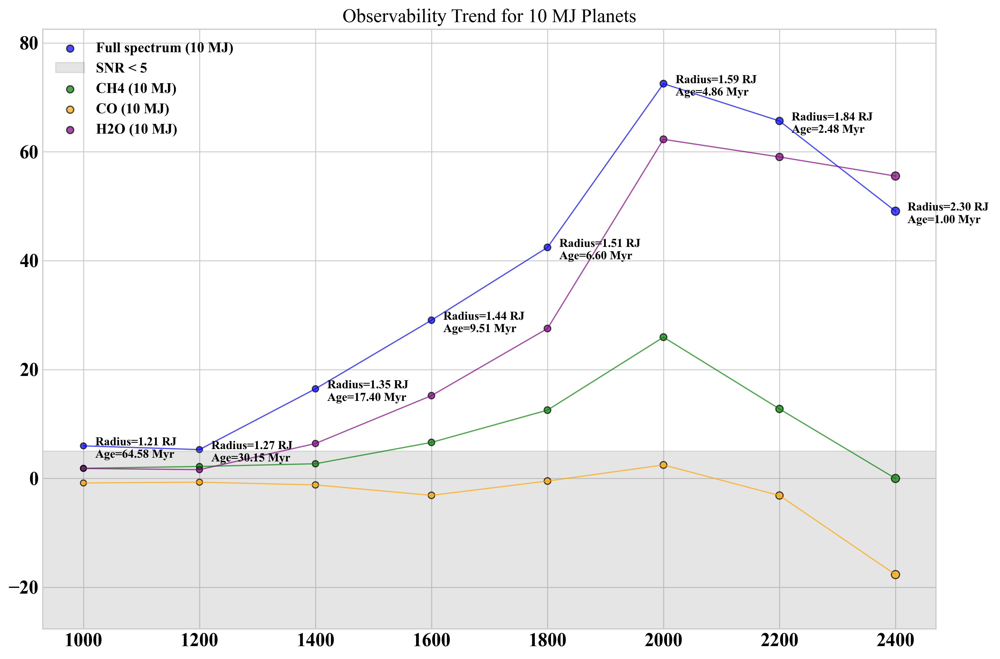

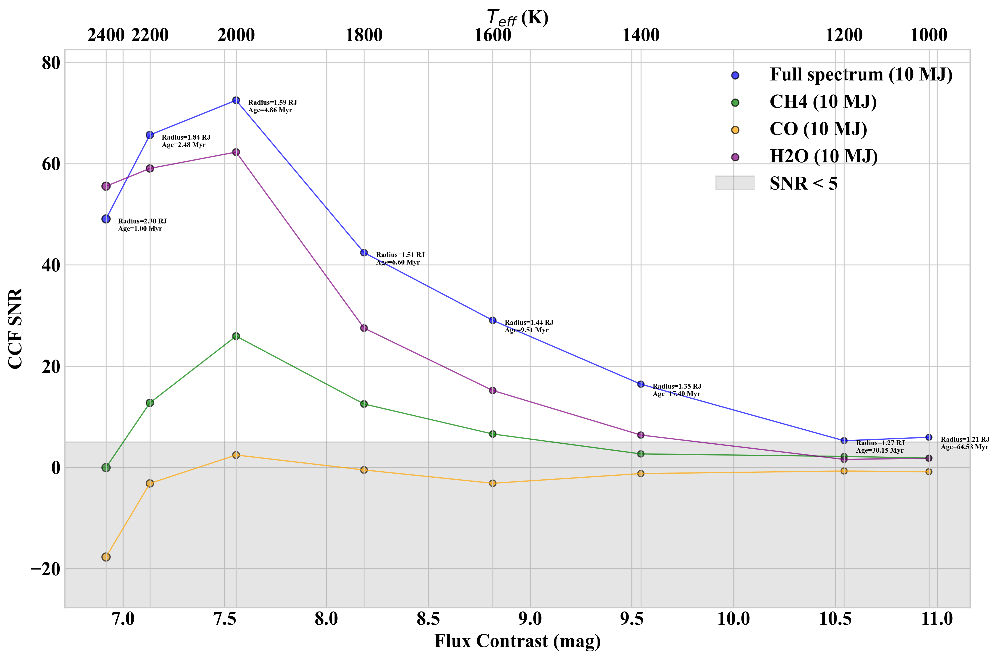

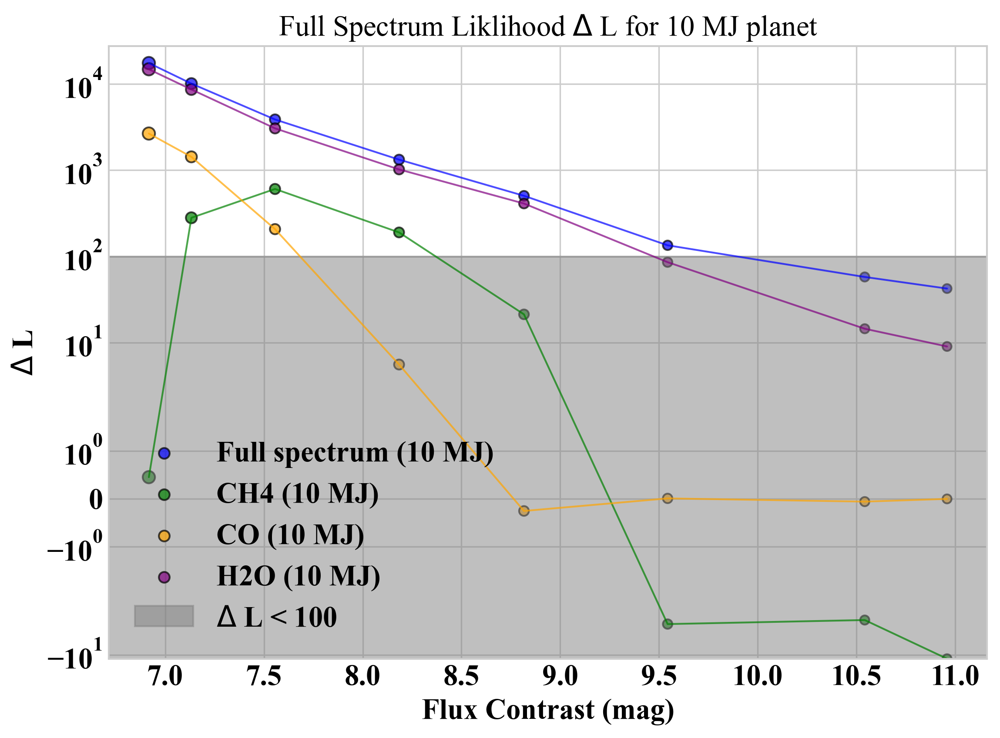

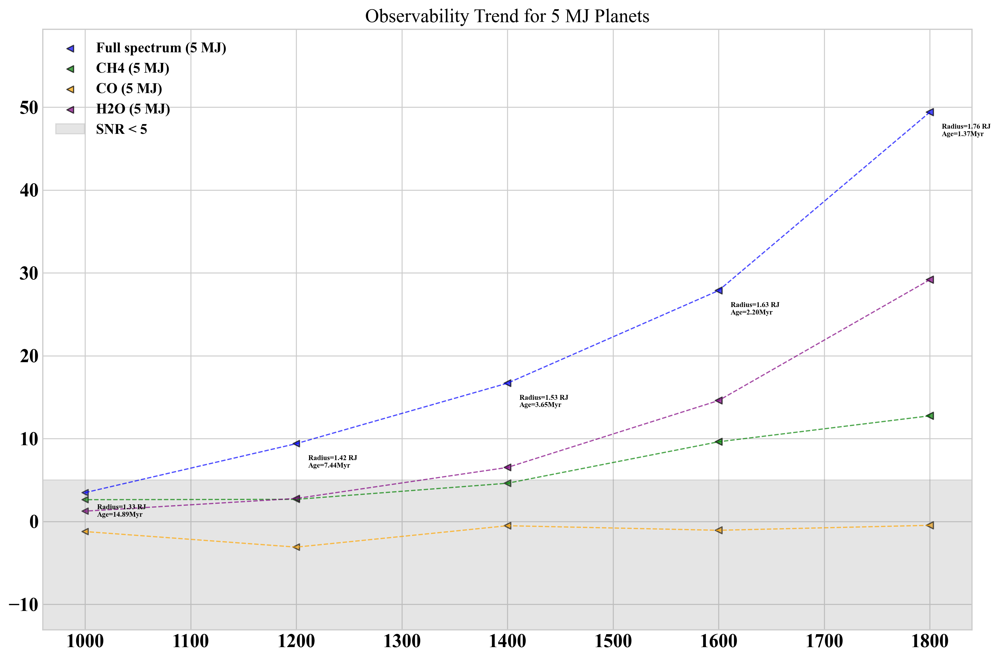

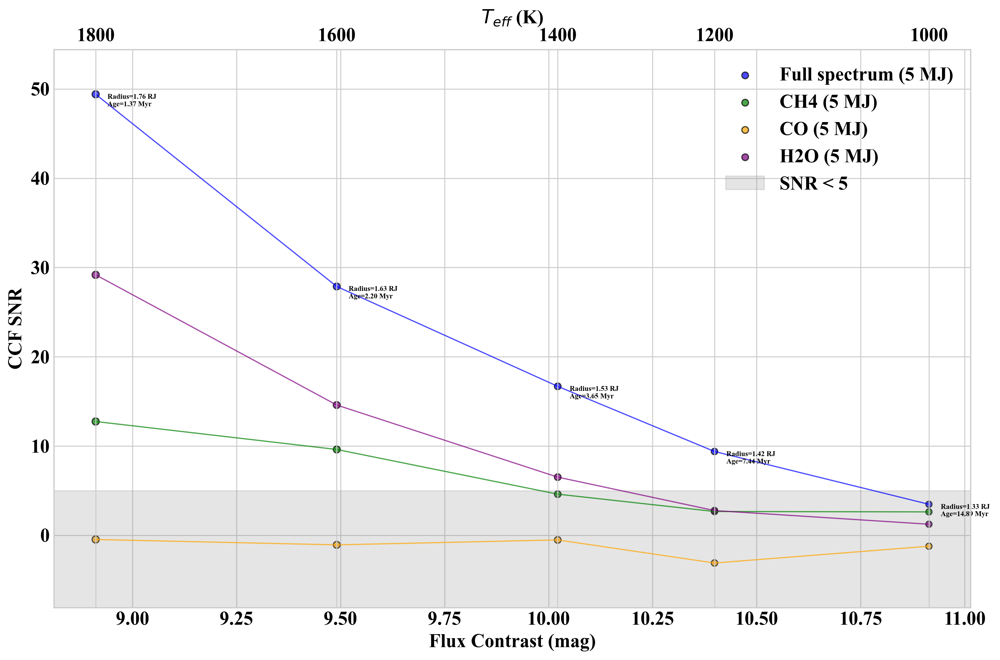

In [170]:




# ----------------------------------Plot for 10 MJ planets-----------------------------------------------------------------------------------
#############################################################################################################################################
plt.figure(figsize=(12, 8))
ax1 = plt.gca()
scatter = ax1.scatter(Teff_10, ccf_full_10, s=marker_sizes_10, c='b', label='Full spectrum (10 MJ)', alpha=0.7, edgecolors='k', linewidths=1)
ax1.plot(Teff_10, ccf_full_10, color='b', linestyle='-', linewidth=1, alpha=0.7)

#ax1.set_xticklabels([f'Radius={R_planet_10:.2f} RJ \nAge={Age_10:.2f} Myr'])

#add a span for SNR<5 area
ax1.axhspan(np.nanmin(ccf_mol_10)-10, 5, color='gray', alpha=0.2, label='SNR < 5')

ax1.set_ylim(np.nanmin(ccf_mol_10)-10, max(ccf_full_10) +10)

# Add annotations for ccf_full_10 on the x axis

for teff, snr, radius, age in zip(Teff_10, ccf_full_10, R_planet_10, Age_10):
    ax1.annotate(f'Radius={radius:.2f} RJ \nAge={age:.2f} Myr', (teff, snr), textcoords="offset points", xytext=(10, -10), fontsize=10, color='black')

# Add data points for ccf_mol_10
colors = ['g', 'orange', 'purple']  # Colors for CH4, CO, H2O
labels = ['CH4', 'CO', 'H2O']
for i, mol_snr in enumerate(ccf_mol_10):
    ax1.scatter(Teff_10, mol_snr, s=marker_sizes_10, c=colors[i], label=f'{labels[i]} (10 MJ)', alpha=0.7, edgecolors='k', linewidths=1)
    ax1.plot(Teff_10, mol_snr, color=colors[i], linestyle='-', linewidth=1, alpha=0.7)

# Secondary y-axis for delta_mag_10
'''
ax2 = ax1.twinx()
ccf_snr_min, ccf_snr_max = ax1.get_ylim()
delta_mag_min = min(delta_mag_10)
delta_mag_max = max(delta_mag_10)
ax2.set_ylim(ccf_snr_min, ccf_snr_max)
ax2.set_yticks(ccf_full_10)
ax2.set_yticklabels(np.round(delta_mag_10, 2))
ax2.set_ylabel('Delta Magnitude', fontsize=14, color='r')
ax2.tick_params(axis='y', labelsize=12, colors='r')

ax1.set_xlabel('Effective Temperature (Teff) [K]', fontsize=14)
ax1.set_ylabel('CCF SNR', fontsize=14)
ax1.set_xlim(min(Teff_10) - 200, max(Teff_10) + 200)
#ax1.set_ylim(np.nanmin(ccf_mol_10)-3, max(ccf_full_10) + 5)

ax2.grid(True, linestyle='--', alpha=0.5)
'''

#ax1.set_yscale('symlog')


plt.title('Observability Trend for 10 MJ Planets', fontsize=16)
ax1.legend(fontsize=12)
plt.show()

#----------plot S/N vs delta_mag ------------
plt.figure(figsize=(12,8))
ax1 = plt.gca()

ax1.plot(delta_mag_10, ccf_full_10, color='b', linestyle='-', linewidth=1, alpha=0.7)
scatter = ax1.scatter(delta_mag_10, ccf_full_10, s=marker_sizes_10, c='b', label='Full spectrum (10 MJ)', alpha=0.7, edgecolors='k', linewidths=1)

# Add data points for ccf_mol_10

for i, mol_snr in enumerate(ccf_mol_10):
    ax1.scatter(delta_mag_10, mol_snr, s=marker_sizes_10, c=colors[i], label=f'{labels[i]} (10 MJ)', alpha=0.7, edgecolors='k', linewidths=1)
    ax1.plot(delta_mag_10, mol_snr, color=colors[i], linestyle='-', linewidth=1, alpha=0.7)

# Add annotations for ccf_full_10 on the x axis
for delta_mag, snr, radius, age in zip(delta_mag_10, ccf_full_10, R_planet_10, Age_10):
    ax1.annotate(f'Radius={radius:.2f} RJ \nAge={age:.2f} Myr', (delta_mag, snr), textcoords="offset points", xytext=(10, -10), fontsize=6, color='black')

#add a span for SNR<5 area
ax1.axhspan(np.nanmin(ccf_mol_10)-10, 5, color='gray', alpha=0.2, label='SNR < 5')
ax1.set_ylim(np.nanmin(ccf_mol_10)-10, max(ccf_full_10) +10)

ax1.set_xlabel('Flux Contrast (mag)')
ax1.set_ylabel('CCF SNR')

# Create a second x-axis on top for temperature labels
ax2 = ax1.twiny()
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(delta_mag_10)
ax2.set_xticklabels(Teff_10)  # Second row labels
ax2.set_xlabel(r"$T_{eff}$ (K)")


#plt.yscale('symlog')

ax1.legend()
plt.show()

#----------plot the likelihood difference----------
plt.Figure(figsize=(12,8))

plt.plot(delta_mag_10, likelihood_full_10, color='b', linestyle='-', linewidth=1, alpha=0.7)
scatter=plt.scatter(delta_mag_10, likelihood_full_10, s=marker_sizes_10, c='b', label='Full spectrum (10 MJ)', alpha=0.7, edgecolors='k', linewidths=1)

for i, mol_likelihood in enumerate(likelihood_mol_10):
    plt.scatter(delta_mag_10, mol_likelihood, s=marker_sizes_10, c=colors[i], label=f'{labels[i]} (10 MJ)', alpha=0.7, edgecolors='k', linewidths=1)
    plt.plot(delta_mag_10, mol_likelihood, color=colors[i], linestyle='-', linewidth=1, alpha=0.7)

plt.axhspan(np.nanmin(likelihood_mol_10), 100, color='gray', linestyle='-', linewidth=1, alpha=0.5, label=r'$\Delta$ L < 100')
plt.ylim(np.nanmin(likelihood_mol_10), np.nanmax(likelihood_full_10)+10000)


plt.title(r'Full Spectrum Liklihood $\Delta$ L for 10 MJ planet')
plt.legend()

plt.xlabel('Flux Contrast (mag)')
plt.ylabel(r'$\Delta$ L')
plt.yscale('symlog')

plt.show()


# -------------------------------------Plot for 5 MJ planets--------------------------------------------------------------------------------------------
#############################################################################################################################################
plt.figure(figsize=(12, 8))
ax1 = plt.gca()
scatter = ax1.scatter(Teff_5, ccf_full_5, s=marker_sizes_5, c='b', label='Full spectrum (5 MJ)', alpha=0.7, edgecolors='k', linewidths=1, marker='<')
ax1.plot(Teff_5, ccf_full_5, color='b', linestyle='--', linewidth=1, alpha=0.7)

# Add data points for ccf_mol_5
for i, mol_snr in enumerate(ccf_mol_5):
    ax1.scatter(Teff_5, mol_snr, s=marker_sizes_5, c=colors[i], label=f'{labels[i]} (5 MJ)', alpha=0.7, edgecolors='k', linewidths=1, marker='<')
    ax1.plot(Teff_5, mol_snr, color=colors[i], linestyle='--', linewidth=1, alpha=0.7)


# Add annotations for ccf_full_5
for teff, snr, radius, age in zip(Teff_5, ccf_full_5, R_planet_5, Age_5):
    ax1.annotate(f'Radius={radius:.2f} RJ\nAge={age:.2f}Myr', (teff, snr), textcoords="offset points", xytext=(10, -20), fontsize=6, color='black')

#add a span for SNR<5 area
ax1.axhspan(np.nanmin(ccf_mol_5)-10, 5, color='gray', alpha=0.2, label='SNR < 5')

ax1.set_ylim(np.nanmin(ccf_mol_5)-10, np.nanmax(ccf_full_5) +10)

# Secondary y-axis for delta_mag_5
'''
ax2 = ax1.twinx()
ccf_snr_min, ccf_snr_max = ax1.get_ylim()
delta_mag_min = min(delta_mag_5)
delta_mag_max = max(delta_mag_5)
ax2.set_ylim(ccf_snr_min, ccf_snr_max)
ax2.set_yticks(ccf_full_5)
ax2.set_yticklabels(np.round(delta_mag_5, 2))
ax2.set_ylabel('Delta Magnitude', fontsize=14, color='r')
ax2.tick_params(axis='y', labelsize=12, colors='r')

ax1.set_xlabel('Effective Temperature (Teff) [K]', fontsize=14)
ax1.set_ylabel('CCF SNR', fontsize=14)
ax1.set_xlim(min(Teff_5) - 200, max(Teff_5) + 200)


ax2.grid(True, linestyle='--', alpha=0.5)
'''
#ax1.set_yscale('symlog')


plt.title('Observability Trend for 5 MJ Planets', fontsize=16)
ax1.legend(fontsize=12)
plt.show()

#----------plot S/N vs delta_mag ------------
plt.figure(figsize=(12,8))
ax1 = plt.gca()

ax1.plot(delta_mag_5, ccf_full_5, color='b', linestyle='-', linewidth=1, alpha=0.7)
scatter = ax1.scatter(delta_mag_5, ccf_full_5, s=marker_sizes_5, c='b', label='Full spectrum (5 MJ)', alpha=0.7, edgecolors='k', linewidths=1)

# Add data points for ccf_mol_10

for i, mol_snr in enumerate(ccf_mol_5):
    ax1.scatter(delta_mag_5, mol_snr, s=marker_sizes_5, c=colors[i], label=f'{labels[i]} (5 MJ)', alpha=0.7, edgecolors='k', linewidths=1)
    ax1.plot(delta_mag_5, mol_snr, color=colors[i], linestyle='-', linewidth=1, alpha=0.7)

# Add annotations for ccf_full_10 on the x axis
for delta_mag, snr, radius, age in zip(delta_mag_5, ccf_full_5, R_planet_5, Age_5):
    ax1.annotate(f'Radius={radius:.2f} RJ \nAge={age:.2f} Myr', (delta_mag, snr), textcoords="offset points", xytext=(10, -10), fontsize=6, color='black')

#add a span for SNR<5 area
ax1.axhspan(np.nanmin(ccf_mol_5)-10, 5, color='gray', alpha=0.2, label='SNR < 5')
ax1.set_ylim(np.nanmin(ccf_mol_5)-5, max(ccf_full_5) +5)

#ax1.set_yscale('symlog')

ax1.set_xlabel('Flux Contrast (mag)')
ax1.set_ylabel('CCF SNR')

ax2 = ax1.twiny()
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(delta_mag_5)
ax2.set_xticklabels(Teff_5)  # Second row labels
ax2.set_xlabel(r"$T_{eff}$ (K)")

ax1.legend()
plt.show()



# ================================ p = 10 pixels ================================


/Users/richard/.local/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


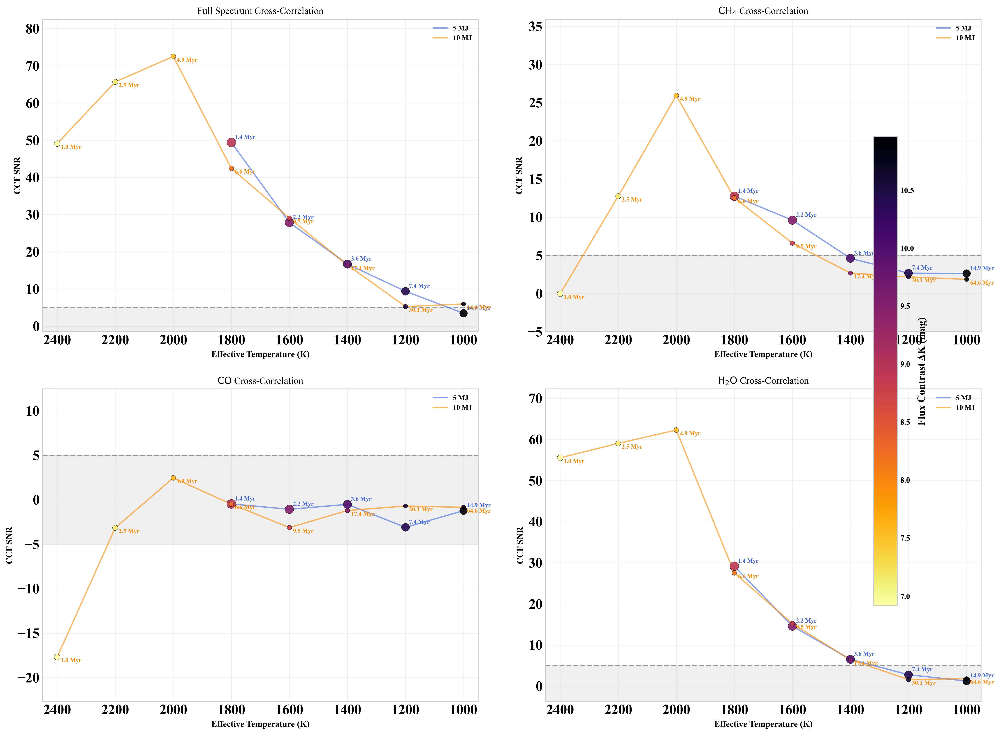

# ================================ p = 3 pixels ================================


/Users/richard/.local/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


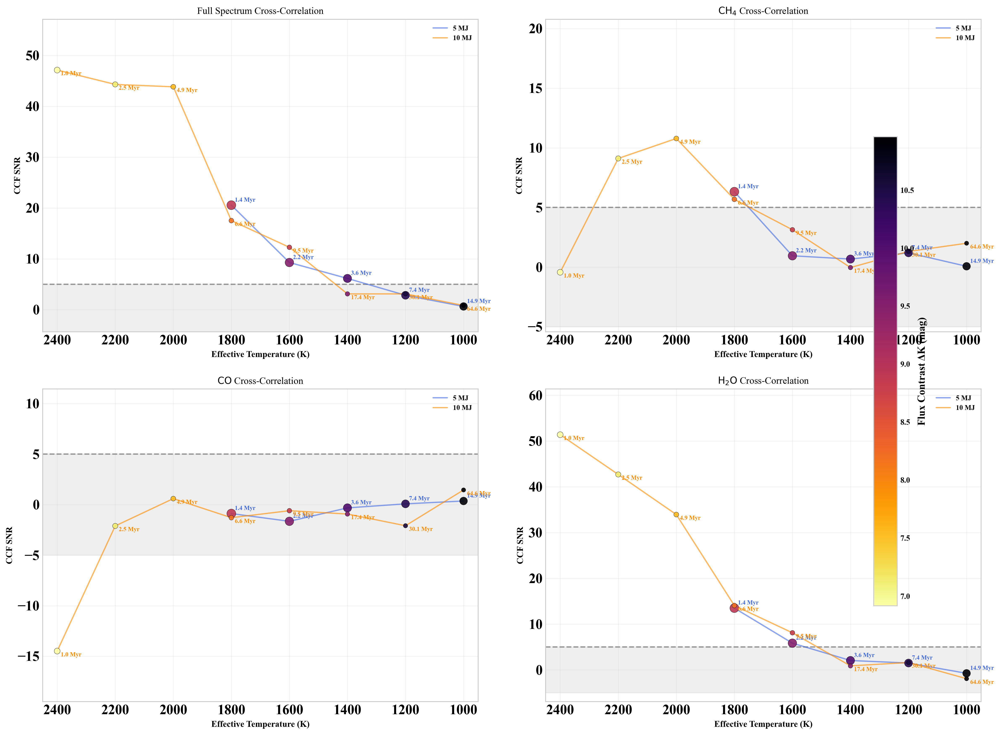

# ================================ p = 5 pixels ================================


/Users/richard/.local/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


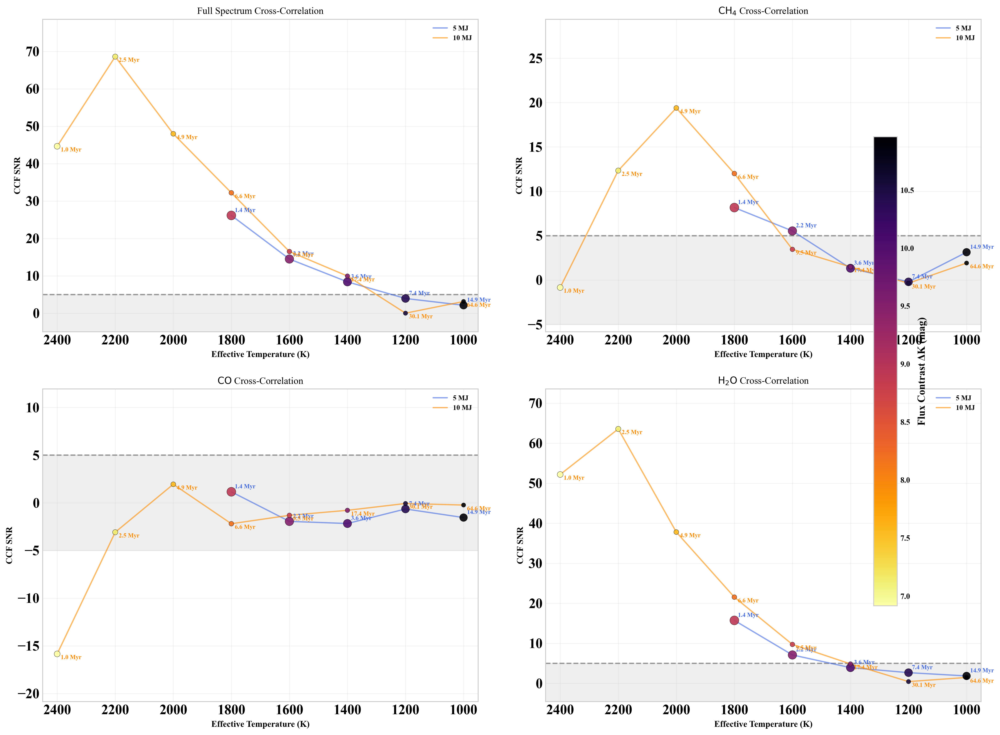

# ================================ p = 15 pixels ================================


/Users/richard/.local/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


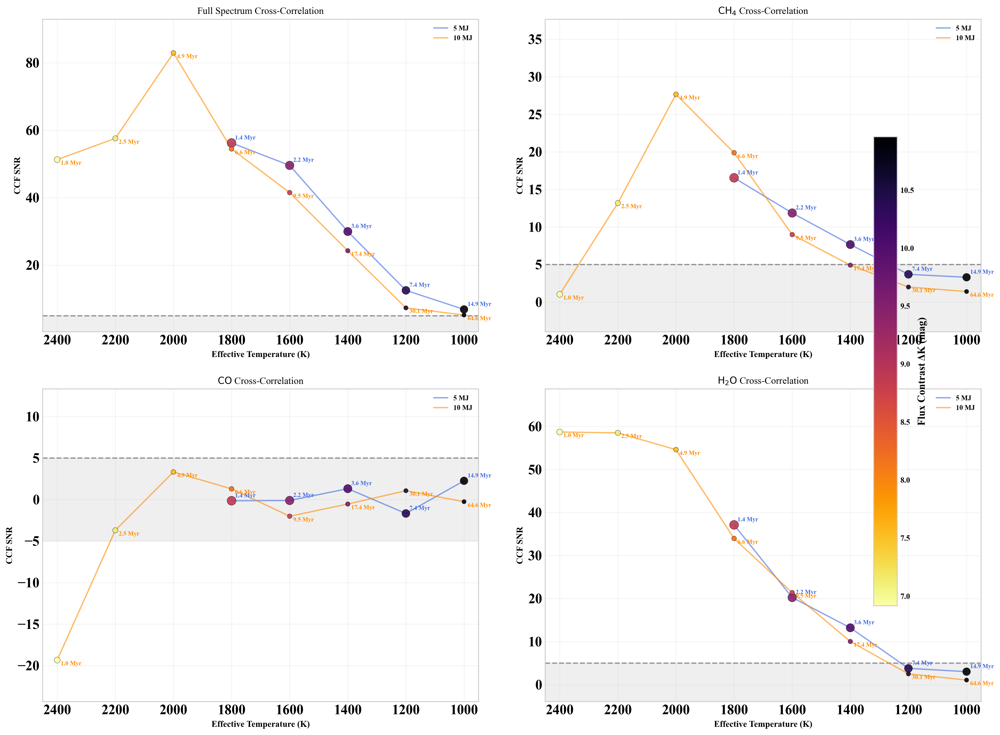

In [171]:


# Marker sizes proportional to planet radius
marker_sizes_5 = np.array(R_planet_5) * 60
marker_sizes_10 = np.array(R_planet_10) * 60

# Labels & colors
molecule_labels = [r"$\mathrm{CH_4}$", r"$\mathrm{CO}$", r"$\mathrm{H_2 O}$"]
panel_titles = ["Full Spectrum", r"$\mathrm{CH_4}$", r"$\mathrm{CO}$", r"$\mathrm{H_2 O}$"]

# Combine delta_mag for normalization of colormap
all_delta_mag = np.concatenate([delta_mag_5, delta_mag_10])
norm = Normalize(vmin=np.nanmin(all_delta_mag), vmax=np.nanmax(all_delta_mag))
cmap = cm.inferno_r

SNR_THRESHOLD = np.array([-5, 5])
# ===============================
# PLOTTING FUNCTION
# ===============================
def plot_ccf_panel(ax, teff_5, teff_10, delta_mag_5, delta_mag_10,
                   snr_5, snr_10, r_5, r_10, age_5, age_10,
                   title, label):
    """Scatter plot for CCF SNR vs Teff with ΔK encoded as color."""

    # Scatter 5 MJ planets
    sc1 = ax.scatter(teff_5, snr_5, s=r_5, c=delta_mag_5,
                     cmap=cmap, norm=norm, alpha=0.9,
                     edgecolor="k", linewidth=0.3, zorder=3)
    order5 = np.argsort(teff_5)
    ax.plot(teff_5[order5], snr_5[order5], color="royalblue", alpha=0.6, zorder=2,label=label[0])

    # Scatter 10 MJ planets
    sc2 = ax.scatter(teff_10, snr_10, s=r_10, c=delta_mag_10,
                     cmap=cmap, norm=norm, alpha=0.9,
                     edgecolor="k", linewidth=0.3, zorder=3)
    order10 = np.argsort(teff_10)
    ax.plot(teff_10[order10], snr_10[order10], color="darkorange", alpha=0.6, zorder=2,label=label[1])

    # Annotate ages
    for i in range(len(teff_5)):
        ax.annotate(f"{age_5[i]:.1f} Myr", (teff_5[i], snr_5[i]),
                    xytext=(4, 4), textcoords="offset points", fontsize=7, color="royalblue")
    for i in range(len(teff_10)):
        ax.annotate(f"{age_10[i]:.1f} Myr", (teff_10[i], snr_10[i]),
                    xytext=(4, -6), textcoords="offset points", fontsize=7, color="darkorange")

    # Detection threshold shading
    ax.axhspan(SNR_THRESHOLD[0], SNR_THRESHOLD[1], color="lightgrey", alpha=0.35, zorder=0)
    ax.axhline(SNR_THRESHOLD[1], linestyle="--", color="grey", alpha=0.8, zorder=1)
    ax.set_ylim(np.nanmin([np.nanmin(snr_5), np.nanmin(snr_10)]) - 5, np.nanmax([np.nanmax(snr_5), np.nanmax(snr_10)]) + 10)

    # Labels and grid
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Effective Temperature (K)", fontsize=10)
    ax.set_ylabel("CCF SNR", fontsize=10)
    ax.grid(alpha=0.25)

    # Reverse x-axis (hot → cool)
    ax.invert_xaxis()
    teff_min = min(np.min(teff_5), np.min(teff_10)) - 50
    teff_max = max(np.max(teff_5), np.max(teff_10)) + 50
    ax.set_xlim(teff_max, teff_min)

    ax.legend(fontsize=8)

print('# ================================ p = 10 pixels ================================')
# Data for 10 MJ planets
cut_10 = simulation_log.loc[simulation_log['M_planet'] == 10]
Age_10 = cut_10['Age'].values
Teff_10 = cut_10['Teff_planet'].values
R_planet_10 = cut_10['R_planet'].values
Mag_planet_10 = cut_10['Mag_planet_K'].values
Mag_star_10= cut_10['Mag_star_K'].values
delta_mag_10 = Mag_planet_10 - Mag_star_10
ccf_full_10=cut_10['CCF_Full_Spectrum'].values
ccf_mol_10=cut_10[['CCF_CH4_only', 'CCF_CO_only', 'CCF_H2O_only']].values.T

marker_sizes_10 = np.array(R_planet_10) * 20  # Scale marker sizes by planet radius


# Data for 5 MJ planets
cut_5 = simulation_log.loc[simulation_log['M_planet'] == 5]
Age_5 = cut_5['Age'].values
Teff_5 = cut_5['Teff_planet'].values
R_planet_5 = cut_5['R_planet'].values
Mag_planet_5 = cut_5['Mag_planet_K'].values
Mag_star_5 = cut_5['Mag_star_K'].values
delta_mag_5 = Mag_planet_5 - Mag_star_5

ccf_full_5=cut_5['CCF_Full_Spectrum'].values
ccf_mol_5=cut_5[['CCF_CH4_only', 'CCF_CO_only', 'CCF_H2O_only']].values.T

likelihood_10_10 = cut_10[['Likelihood_full', 'Likelihood_CH4', 'Likelihood_CO', 'Likelihood_H2O']].values.T
likelihood_10_5 = cut_5[['Likelihood_full', 'Likelihood_CH4', 'Likelihood_CO', 'Likelihood_H2O']].values.T

# ===============================
# BUILD 2x2 COMPOSITE FIGURE
# ===============================
fig, axs = plt.subplots(2, 2, figsize=(16, 12))
axs = axs.flatten()

# Panel 1: Full Spectrum
plot_ccf_panel(axs[0], Teff_5, Teff_10, delta_mag_5, delta_mag_10,
               ccf_full_5, ccf_full_10,
               marker_sizes_5, marker_sizes_10,
               Age_5, Age_10,
               "Full Spectrum Cross-Correlation", label=["5 MJ", "10 MJ"])

# Panels 2-4: Molecule-specific
for i, ax in enumerate(axs[1:], start=0):
    plot_ccf_panel(ax, Teff_5, Teff_10, delta_mag_5, delta_mag_10,
                   ccf_mol_5[i], ccf_mol_10[i],
                   marker_sizes_5, marker_sizes_10,
                   Age_5, Age_10,
                   f"{molecule_labels[i]} Cross-Correlation", label=["5 MJ", "10 MJ"])

# ===============================
# SHARED COLORBAR
# ===============================
cbar = fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap),
                    ax=axs, orientation="vertical", fraction=0.03, pad=0.04)
cbar.set_label("Flux Contrast ΔK (mag)", fontsize=12)
cbar.ax.tick_params(labelsize=9)
cbar.set_ticks(np.arange(np.floor(np.min(all_delta_mag)*10)/10 + 0.1,
                         np.ceil(np.max(all_delta_mag)*10)/10, 0.5))

#plt.tight_layout()
#outfile = os.path.join(OUTPUT_DIR, "ccf_composite_temp_age_colorbar.png")
#plt.savefig(outfile, dpi=400)
plt.show()
#print("Saved:", outfile)


# ================================
print('# ================================ p = 3 pixels ================================')
simulationg_log_3=pd.read_csv(path + 'simulation_log_3.csv')

cut_3_10=simulationg_log_3.loc[simulationg_log_3['M_planet']==10]
cut_3_5=simulationg_log_3.loc[simulationg_log_3['M_planet']==5]

snr_3_10=cut_3_10['CCF_Full_Spectrum'].values
snr_3_5=cut_3_5['CCF_Full_Spectrum'].values
Teff_3_10=cut_3_10['Teff_planet'].values
Teff_3_5=cut_3_5['Teff_planet'].values
delta_mag_3_10=cut_3_10['Mag_planet_K'].values-cut_3_10['Mag_star_K'].values
delta_mag_3_5=cut_3_5['Mag_planet_K'].values-cut_3_5['Mag_star_K'].values

ccf_mol_3_10=cut_3_10[['CCF_CH4_only', 'CCF_CO_only', 'CCF_H2O_only']].values.T
ccf_mol_3_5=cut_3_5[['CCF_CH4_only', 'CCF_CO_only', 'CCF_H2O_only']].values.T

likelihood_3_10 = cut_3_10[['Likelihood_full', 'Likelihood_CH4', 'Likelihood_CO', 'Likelihood_H2O']].values.T
likelihood_3_5 = cut_3_5[['Likelihood_full', 'Likelihood_CH4', 'Likelihood_CO', 'Likelihood_H2O']].values.T


# ===============================
# BUILD 2x2 COMPOSITE FIGURE
# ===============================
fig, axs = plt.subplots(2, 2, figsize=(16, 12))
axs = axs.flatten()

# Panel 1: Full Spectrum
plot_ccf_panel(axs[0], Teff_5, Teff_10, delta_mag_3_5, delta_mag_3_10,
               snr_3_5, snr_3_10,
               marker_sizes_5, marker_sizes_10,
               Age_5, Age_10,
               "Full Spectrum Cross-Correlation", label=["5 MJ", "10 MJ"])

# Panels 2-4: Molecule-specific
for i, ax in enumerate(axs[1:], start=0):
    plot_ccf_panel(ax, Teff_5, Teff_10, delta_mag_3_5, delta_mag_3_10,
                   ccf_mol_3_5[i], ccf_mol_3_10[i],
                   marker_sizes_5, marker_sizes_10,
                   Age_5, Age_10,
                   f"{molecule_labels[i]} Cross-Correlation", label=["5 MJ", "10 MJ"])

# ===============================
# SHARED COLORBAR
# ===============================
cbar = fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap),
                    ax=axs, orientation="vertical", fraction=0.03, pad=0.04)
cbar.set_label("Flux Contrast ΔK (mag)", fontsize=12)
cbar.ax.tick_params(labelsize=9)
cbar.set_ticks(np.arange(np.floor(np.min(all_delta_mag)*10)/10 + 0.1,
                         np.ceil(np.max(all_delta_mag)*10)/10, 0.5))

#plt.tight_layout()
#outfile = os.path.join(OUTPUT_DIR, "ccf_composite_temp_age_colorbar.png")
#plt.savefig(outfile, dpi=400)
plt.show()

# ================================
print('# ================================ p = 5 pixels ================================')
simulationg_log_5=pd.read_csv(path + 'simulation_log_5.csv')

cut_5_10=simulationg_log_5.loc[simulationg_log_5['M_planet']==10]
cut_5_5=simulationg_log_5.loc[simulationg_log_5['M_planet']==5]

snr_5_10=cut_5_10['CCF_Full_Spectrum'].values
snr_5_5=cut_5_5['CCF_Full_Spectrum'].values
Teff_5_10=cut_5_10['Teff_planet'].values
Teff_5_5=cut_5_5['Teff_planet'].values
delta_mag_5_10=cut_5_10['Mag_planet_K'].values-cut_5_10['Mag_star_K'].values
delta_mag_5_5=cut_5_5['Mag_planet_K'].values-cut_5_5['Mag_star_K'].values

ccf_mol_5_10=cut_5_10[['CCF_CH4_only', 'CCF_CO_only', 'CCF_H2O_only']].values.T
ccf_mol_5_5=cut_5_5[['CCF_CH4_only', 'CCF_CO_only', 'CCF_H2O_only']].values.T

likelihood_5_10 = cut_5_10[['Likelihood_full', 'Likelihood_CH4', 'Likelihood_CO', 'Likelihood_H2O']].values.T
likelihood_5_5 = cut_5_5[['Likelihood_full', 'Likelihood_CH4', 'Likelihood_CO', 'Likelihood_H2O']].values.T

# ===============================
# BUILD 2x2 COMPOSITE FIGURE
# ===============================
fig, axs = plt.subplots(2, 2, figsize=(16, 12))
axs = axs.flatten()

# Panel 1: Full Spectrum
plot_ccf_panel(axs[0], Teff_5, Teff_10, delta_mag_5_5, delta_mag_5_10,
               snr_5_5, snr_5_10,
               marker_sizes_5, marker_sizes_10,
               Age_5, Age_10,
               "Full Spectrum Cross-Correlation", label=["5 MJ", "10 MJ"])

# Panels 2-4: Molecule-specific
for i, ax in enumerate(axs[1:], start=0):
    plot_ccf_panel(ax, Teff_5, Teff_10, delta_mag_5_5, delta_mag_5_10,
                   ccf_mol_5_5[i], ccf_mol_5_10[i],
                   marker_sizes_5, marker_sizes_10,
                   Age_5, Age_10,
                   f"{molecule_labels[i]} Cross-Correlation", label=["5 MJ", "10 MJ"])

# ===============================
# SHARED COLORBAR
# ===============================
cbar = fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap),
                    ax=axs, orientation="vertical", fraction=0.03, pad=0.04)
cbar.set_label("Flux Contrast ΔK (mag)", fontsize=12)
cbar.ax.tick_params(labelsize=9)
cbar.set_ticks(np.arange(np.floor(np.min(all_delta_mag)*10)/10 + 0.1,
                         np.ceil(np.max(all_delta_mag)*10)/10, 0.5))

#plt.tight_layout()
#outfile = os.path.join(OUTPUT_DIR, "ccf_composite_temp_age_colorbar.png")
#plt.savefig(outfile, dpi=400)
plt.show()



# ================================
print('# ================================ p = 15 pixels ================================')
simulationg_log_15=pd.read_csv(path + 'simulation_log_15.csv')

cut_15_10=simulationg_log_15.loc[simulationg_log_15['M_planet']==10]
cut_15_5=simulationg_log_15.loc[simulationg_log_15['M_planet']==5]

snr_15_10=cut_15_10['CCF_Full_Spectrum'].values
snr_15_5=cut_15_5['CCF_Full_Spectrum'].values
Teff_15_10=cut_15_10['Teff_planet'].values
Teff_15_5=cut_15_5['Teff_planet'].values
delta_mag_15_10=cut_15_10['Mag_planet_K'].values-cut_15_10['Mag_star_K'].values
delta_mag_15_5=cut_15_5['Mag_planet_K'].values-cut_15_5['Mag_star_K'].values

ccf_mol_15_10=cut_15_10[['CCF_CH4_only', 'CCF_CO_only', 'CCF_H2O_only']].values.T
ccf_mol_15_5=cut_15_5[['CCF_CH4_only', 'CCF_CO_only', 'CCF_H2O_only']].values.T

likelihood_15_10 = cut_15_10[['Likelihood_full', 'Likelihood_CH4', 'Likelihood_CO', 'Likelihood_H2O']].values.T
likelihood_15_5 = cut_15_5[['Likelihood_full', 'Likelihood_CH4', 'Likelihood_CO', 'Likelihood_H2O']].values.T

# ===============================
# BUILD 2x2 COMPOSITE FIGURE
# ===============================
fig, axs = plt.subplots(2, 2, figsize=(16, 12))
axs = axs.flatten()

# Panel 1: Full Spectrum
plot_ccf_panel(axs[0], Teff_5, Teff_10, delta_mag_15_5, delta_mag_15_10,
               snr_15_5, snr_15_10,
               marker_sizes_5, marker_sizes_10,
               Age_5, Age_10,
               "Full Spectrum Cross-Correlation", label=["5 MJ", "10 MJ"])

# Panels 2-4: Molecule-specific
for i, ax in enumerate(axs[1:], start=0):
    plot_ccf_panel(ax, Teff_5, Teff_10, delta_mag_15_5, delta_mag_15_10,
                   ccf_mol_15_5[i], ccf_mol_15_10[i],
                   marker_sizes_5, marker_sizes_10,
                   Age_5, Age_10,
                   f"{molecule_labels[i]} Cross-Correlation", label=["5 MJ", "10 MJ"])

# ===============================
# SHARED COLORBAR
# ===============================
cbar = fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap),
                    ax=axs, orientation="vertical", fraction=0.03, pad=0.04)
cbar.set_label("Flux Contrast ΔK (mag)", fontsize=12)
cbar.ax.tick_params(labelsize=9)
cbar.set_ticks(np.arange(np.floor(np.min(all_delta_mag)*10)/10 + 0.1,
                         np.ceil(np.max(all_delta_mag)*10)/10, 0.5))

#plt.tight_layout()
#outfile = os.path.join(OUTPUT_DIR, "ccf_composite_temp_age_colorbar.png")
#plt.savefig(outfile, dpi=400)
plt.show()

===================3 pixels==================


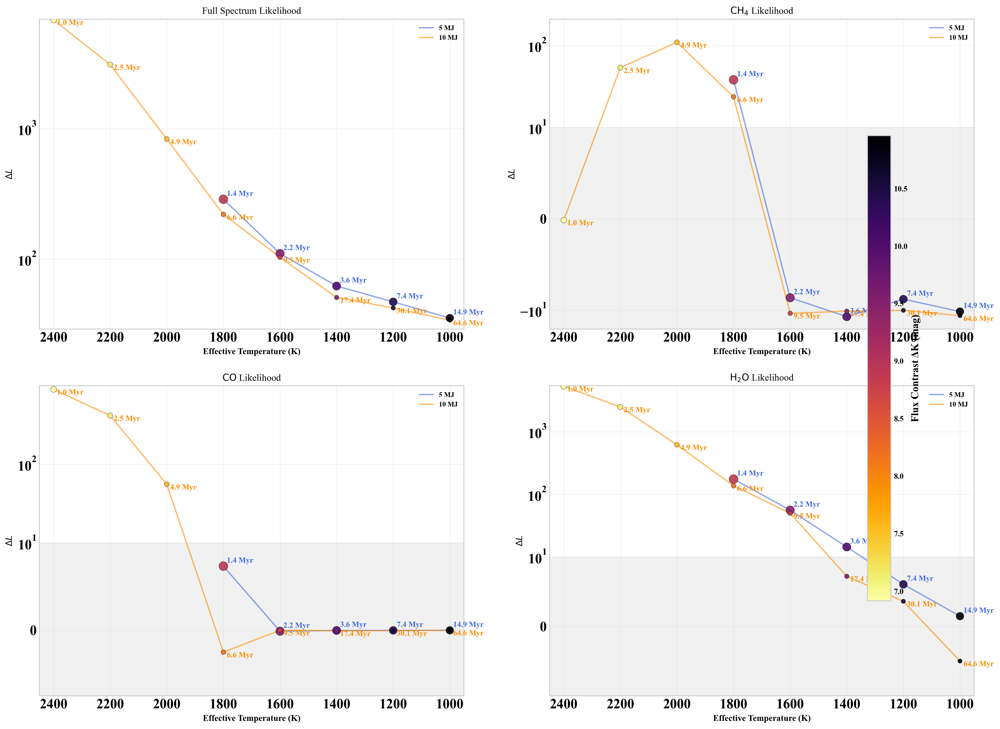

===================5 pixels==================


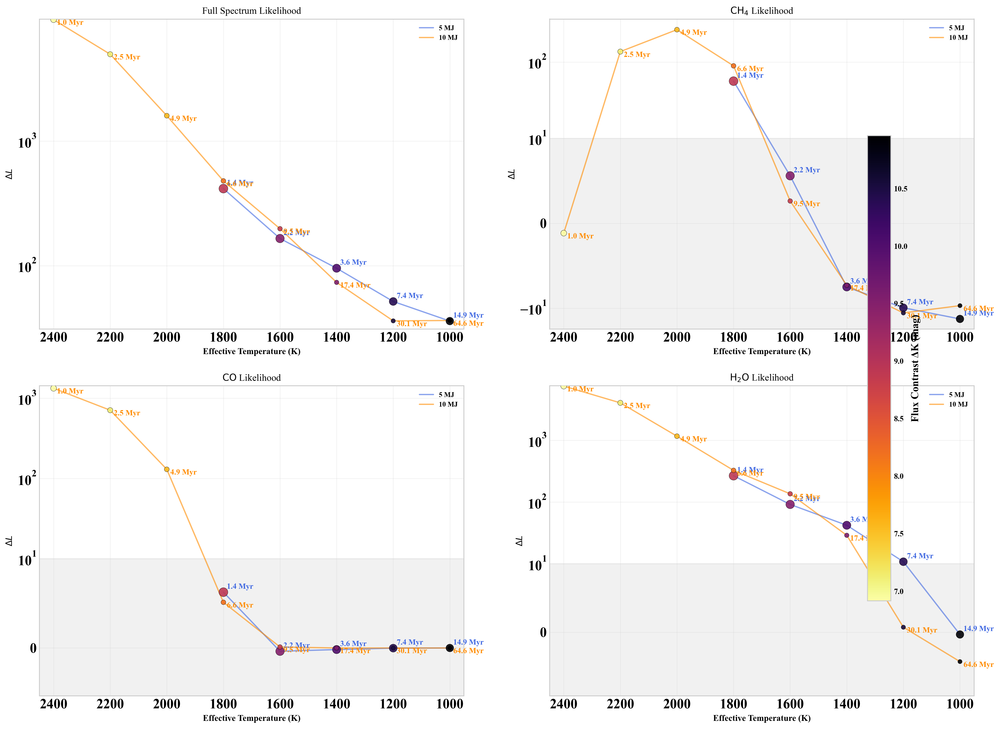

===================10 pixels==================


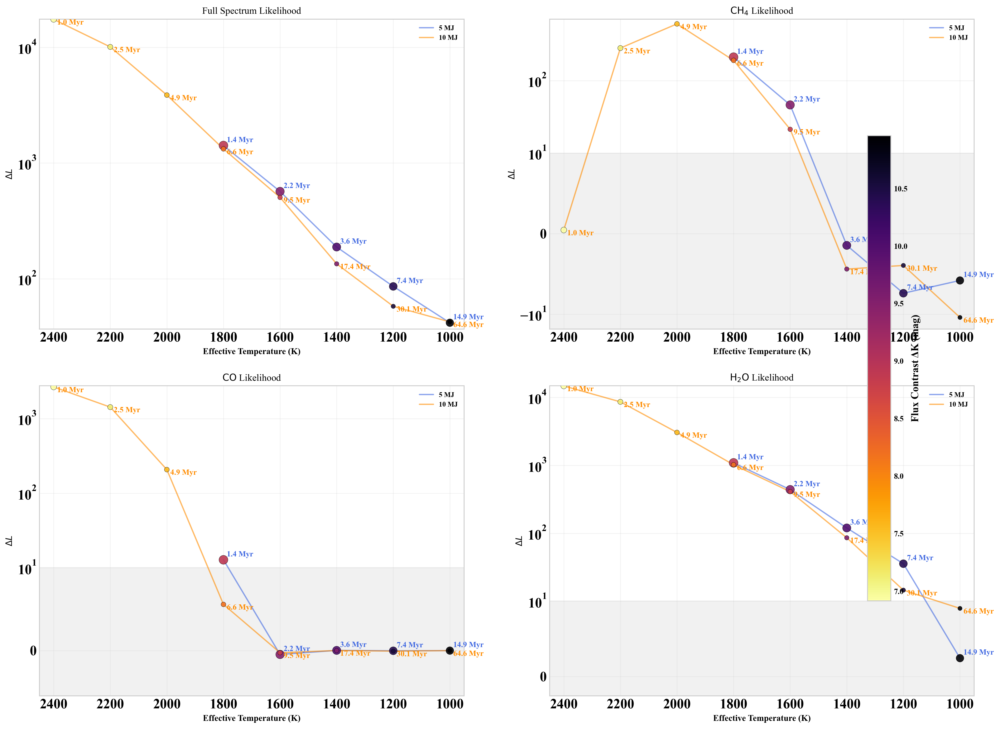

===================15 pixels==================


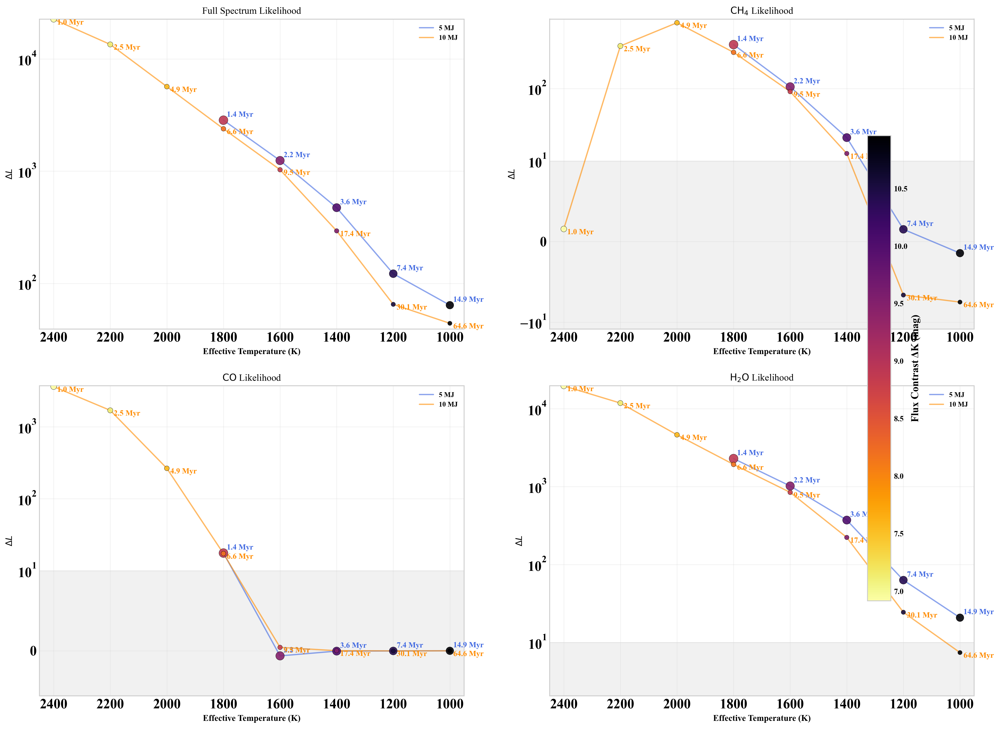

In [172]:
norm = Normalize(vmin=np.nanmin(all_delta_mag), vmax=np.nanmax(all_delta_mag))

#adjust the global font size
plt.rcParams.update({'font.size': 18})

# ===============================
# PLOTTING FUNCTION (LIKELIHOOD)
# ===============================
def plot_likelihood_panel(ax, teff_5, teff_10, delta_mag_5, delta_mag_10,
                          like_5, like_10, r_5, r_10, age_5, age_10, scale,
                          title, label):
    """Scatter plot for likelihood vs Teff with ΔK encoded as color."""

    # Scatter 5 MJ planets
    ax.scatter(teff_5, like_5, s=r_5, c=delta_mag_5,
               cmap=cmap, norm=norm, alpha=0.9,
               edgecolor="k", linewidth=0.3, zorder=3)
    order5 = np.argsort(teff_5)
    ax.plot(teff_5[order5], like_5[order5], color="royalblue", alpha=0.6, zorder=2, label=label[0])

    # Scatter 10 MJ planets
    ax.scatter(teff_10, like_10, s=r_10, c=delta_mag_10,
               cmap=cmap, norm=norm, alpha=0.9,
               edgecolor="k", linewidth=0.3, zorder=3)
    order10 = np.argsort(teff_10)
    ax.plot(teff_10[order10], like_10[order10], color="darkorange", alpha=0.6, zorder=2, label=label[1])

    # Annotate ages
    for i in range(len(teff_5)):
        ax.annotate(f"{age_5[i]:.1f} Myr", (teff_5[i], like_5[i]),
                    xytext=(4, 4), textcoords="offset points", fontsize=9, color="royalblue")
    for i in range(len(teff_10)):
        ax.annotate(f"{age_10[i]:.1f} Myr", (teff_10[i], like_10[i]),
                    xytext=(4, -6), textcoords="offset points", fontsize=9, color="darkorange")

    # Labels and grid
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Effective Temperature (K)", fontsize=10)
    ax.set_ylabel(r"$\Delta L$", fontsize=10)
    ax.grid(alpha=0.25)
    ax.set_yscale(scale, linthresh=10)

    # Reverse x-axis (hot → cool)
    ax.invert_xaxis()
    teff_min = min(np.min(teff_5), np.min(teff_10)) - 50
    teff_max = max(np.max(teff_5), np.max(teff_10)) + 50
    ax.set_xlim(teff_max, teff_min)
    ax.set_ylim(np.nanmin([np.nanmin(like_5), np.nanmin(like_10)]) - 5, np.nanmax([np.nanmax(like_5), np.nanmax(like_10)]) + 100)

    ax.legend(fontsize=8)

print ('===================3 pixels==================')
# ===============================
# BUILD 2x2 COMPOSITE FIGURE
# ===============================
fig, axs = plt.subplots(2, 2, figsize=(16, 12))
axs = axs.flatten()

# Panel 1: Full Spectrum Likelihood
plot_likelihood_panel(axs[0], Teff_5, Teff_10, delta_mag_5, delta_mag_10,
                      likelihood_3_5[0], likelihood_3_10[0],
                      marker_sizes_5, marker_sizes_10,
                      Age_5, Age_10, "symlog",
                      "Full Spectrum Likelihood", label=["5 MJ", "10 MJ"])
axs[0].axhspan(ymin=axs[0].get_ylim()[0], ymax=10, color='lightgray', alpha=0.3)

# Panels 2-4: Molecule-specific Likelihood
for i, ax in enumerate(axs[1:], start=0):
    plot_likelihood_panel(ax, Teff_5, Teff_10, delta_mag_5, delta_mag_10,
                          likelihood_3_5[i+1], likelihood_3_10[i+1],
                          marker_sizes_5, marker_sizes_10,
                          Age_5, Age_10, "symlog",
                          f"{molecule_labels[i]} Likelihood", label=["5 MJ", "10 MJ"])
                          
    ax.axhspan(ymin=ax.get_ylim()[0], ymax=10, color='lightgray', alpha=0.3)


# ===============================
# SHARED COLORBAR
# ===============================
cbar = fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap),
                    ax=axs, orientation="vertical", fraction=0.03, pad=0.04)
cbar.set_label("Flux Contrast ΔK (mag)", fontsize=12)
cbar.ax.tick_params(labelsize=9)
cbar.set_ticks(np.arange(np.floor(np.min(all_delta_mag) * 10) / 10 + 0.1,
                         np.ceil(np.max(all_delta_mag) * 10) / 10, 0.5))



# SAVE & SHOW
#outfile = os.path.join(OUTPUT_DIR, "likelihood_composite_temp_age_colorbar.png")


#plt.savefig(outfile, dpi=400)
plt.show()

print ('===================5 pixels==================')
# ===============================
# BUILD 2x2 COMPOSITE FIGURE
# ===============================
fig, axs = plt.subplots(2, 2, figsize=(16, 12))
axs = axs.flatten()

# Panel 1: Full Spectrum Likelihood
plot_likelihood_panel(axs[0], Teff_5, Teff_10, delta_mag_5, delta_mag_10,
                      likelihood_5_5[0], likelihood_5_10[0],
                      marker_sizes_5, marker_sizes_10,
                      Age_5, Age_10, "symlog",
                      "Full Spectrum Likelihood", label=["5 MJ", "10 MJ"])
axs[0].axhspan(ymin=axs[0].get_ylim()[0], ymax=10, color='lightgray', alpha=0.3)

# Panels 2-4: Molecule-specific Likelihood
for i, ax in enumerate(axs[1:], start=0):
    plot_likelihood_panel(ax, Teff_5, Teff_10, delta_mag_5, delta_mag_10,
                          likelihood_5_5[i+1], likelihood_5_10[i+1],
                          marker_sizes_5, marker_sizes_10,
                          Age_5, Age_10, "symlog",
                          f"{molecule_labels[i]} Likelihood", label=["5 MJ", "10 MJ"])
    ax.axhspan(ymin=ax.get_ylim()[0], ymax=10, color='lightgray', alpha=0.3)
# ===============================
# SHARED COLORBAR
# ===============================
cbar = fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap),
                    ax=axs, orientation="vertical", fraction=0.03, pad=0.04)
cbar.set_label("Flux Contrast ΔK (mag)", fontsize=12)
cbar.ax.tick_params(labelsize=9)
cbar.set_ticks(np.arange(np.floor(np.min(all_delta_mag) * 10) / 10 + 0.1,
                         np.ceil(np.max(all_delta_mag) * 10) / 10, 0.5))

# SAVE & SHOW
#outfile = os.path.join(OUTPUT_DIR, "likelihood_composite_temp_age_colorbar.png")


#plt.savefig(outfile, dpi=400)
plt.show()
#print("Saved:", outfile)

print ('===================10 pixels==================')
# ===============================
# BUILD 2x2 COMPOSITE FIGURE
# ===============================
fig, axs = plt.subplots(2, 2, figsize=(16, 12))
axs = axs.flatten()

# Panel 1: Full Spectrum Likelihood
plot_likelihood_panel(axs[0], Teff_5, Teff_10, delta_mag_5, delta_mag_10,
                      likelihood_full_5, likelihood_full_10,
                      marker_sizes_5, marker_sizes_10,
                      Age_5, Age_10, "symlog",
                      "Full Spectrum Likelihood", label=["5 MJ", "10 MJ"])

axs[0].axhspan(ymin=axs[0].get_ylim()[0], ymax=10, color='lightgray', alpha=0.3)

# Panels 2-4: Molecule-specific Likelihood
for i, ax in enumerate(axs[1:], start=0):
    plot_likelihood_panel(ax, Teff_5, Teff_10, delta_mag_5, delta_mag_10,
                          likelihood_mol_5[i], likelihood_mol_10[i],
                          marker_sizes_5, marker_sizes_10,
                          Age_5, Age_10, "symlog",
                          f"{molecule_labels[i]} Likelihood", label=["5 MJ", "10 MJ"])

    ax.axhspan(ymin=ax.get_ylim()[0], ymax=10, color='lightgray', alpha=0.3)

# ===============================
# SHARED COLORBAR
# ===============================
cbar = fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap),
                    ax=axs, orientation="vertical", fraction=0.03, pad=0.04)
cbar.set_label("Flux Contrast ΔK (mag)", fontsize=12)
cbar.ax.tick_params(labelsize=9)
cbar.set_ticks(np.arange(np.floor(np.min(all_delta_mag) * 10) / 10 + 0.1,
                         np.ceil(np.max(all_delta_mag) * 10) / 10, 0.5))

# SAVE & SHOW
#outfile = os.path.join(OUTPUT_DIR, "likelihood_composite_temp_age_colorbar.png")


#plt.savefig(outfile, dpi=400)
plt.show()
#print("Saved:", outfile)

print ('===================15 pixels==================')
# ===============================
# BUILD 2x2 COMPOSITE FIGURE
# ===============================
fig, axs = plt.subplots(2, 2, figsize=(16, 12))
axs = axs.flatten()

# Panel 1: Full Spectrum Likelihood
plot_likelihood_panel(axs[0], Teff_5, Teff_10, delta_mag_5, delta_mag_10,
                      likelihood_15_5[0], likelihood_15_10[0],
                      marker_sizes_5, marker_sizes_10,
                      Age_5, Age_10, "symlog",
                      "Full Spectrum Likelihood", label=["5 MJ", "10 MJ"])

axs[0].axhspan(ymin=axs[0].get_ylim()[0], ymax=10, color='lightgray', alpha=0.3)

# Panels 2-4: Molecule-specific Likelihood
for i, ax in enumerate(axs[1:], start=0):
    plot_likelihood_panel(ax, Teff_5, Teff_10, delta_mag_5, delta_mag_10,
                          likelihood_15_5[i+1], likelihood_15_10[i+1],
                          marker_sizes_5, marker_sizes_10,
                          Age_5, Age_10, "symlog",
                          f"{molecule_labels[i]} Likelihood", label=["5 MJ", "10 MJ"])

    ax.axhspan(ymin=ax.get_ylim()[0], ymax=10, color='lightgray', alpha=0.3)

# ===============================
# SHARED COLORBAR
# ===============================
cbar = fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap),
                    ax=axs, orientation="vertical", fraction=0.03, pad=0.04)
cbar.set_label("Flux Contrast ΔK (mag)", fontsize=12)
cbar.ax.tick_params(labelsize=9)
cbar.set_ticks(np.arange(np.floor(np.min(all_delta_mag) * 10) / 10 + 0.1,
                         np.ceil(np.max(all_delta_mag) * 10) / 10, 0.5))

# SAVE & SHOW
#outfile = os.path.join(OUTPUT_DIR, "likelihood_composite_temp_age_colorbar.png")


#plt.savefig(outfile, dpi=400)
plt.show()
#print("Saved:", outfile)

5σ Confidence Interval for Teff (10.0 MJ, 3 pixels): 0.0 km/s to 0.0 km/s
The peak significance is 114.12σ
Excluded width with 5σ: 0.0 km/s
The peak velocity is at 45 km/s
5σ Confidence Interval for Teff (10.0 MJ, 3 pixels, CH4): 0.0 km/s to 0.0 km/s
The peak significance is 1.97σ
Excluded width with 5σ: 0.0 km/s
The peak velocity is at 0 km/s
5σ Confidence Interval for Teff (10.0 MJ, 3 pixels, CO): 0.0 km/s to 0.0 km/s
The peak significance is 48.92σ
Excluded width with 5σ: 0.0 km/s
The peak velocity is at 45 km/s
5σ Confidence Interval for Teff (10.0 MJ, 3 pixels, H2O): 0.0 km/s to 0.0 km/s
The peak significance is 112.94σ
Excluded width with 5σ: 0.0 km/s
The peak velocity is at -35 km/s
5σ Confidence Interval for Teff (10.0 MJ, 5 pixels): 0.0 km/s to 0.0 km/s
The peak significance is 126.15σ
Excluded width with 5σ: 0.0 km/s
The peak velocity is at -25 km/s
5σ Confidence Interval for Teff (10.0 MJ, 5 pixels, CH4): 0.0 km/s to 0.0 km/s
The peak significance is 2.90σ
Excluded width wit

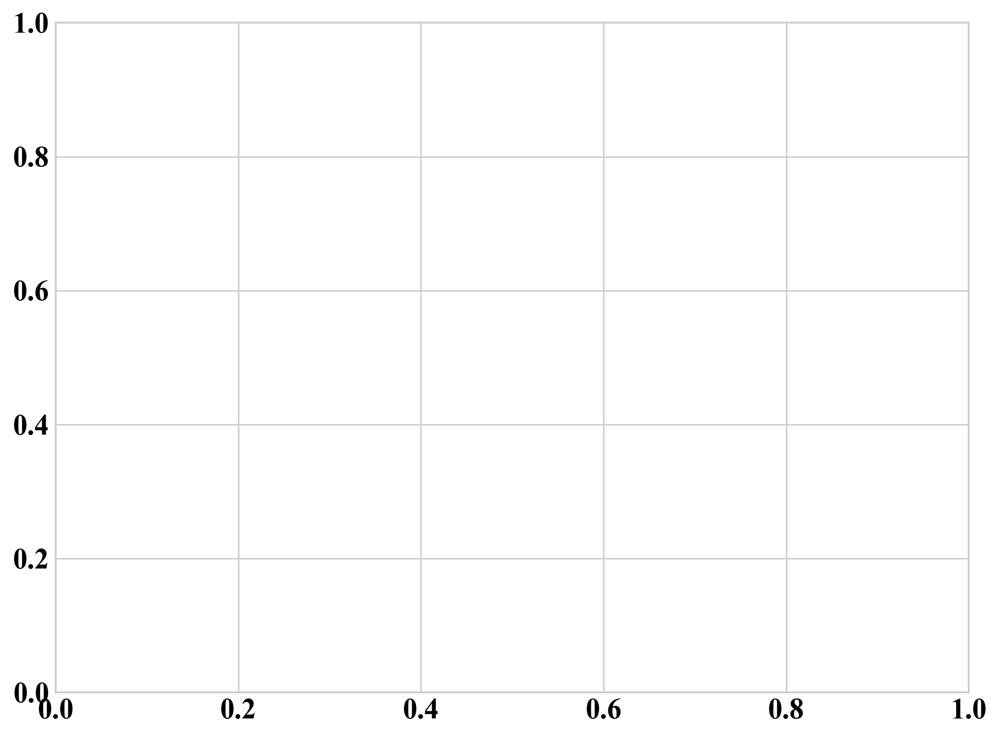

In [173]:
likelihood = spectra_processor.processor_likelihood_map()
mol_name=['Full', 'CH4', 'CO', 'H2O']

fig, axes = plt.subplots(1, 1, figsize=(8, 6))

sigma_array_10=np.zeros(shape=(len(simulation_log.index[5:]),4, 4))
sigma_array_5=np.zeros(shape=(len(simulation_log.index[0:5]),4, 4))

sigma_map_10MJ = np.zeros(shape=(4, 4, len(simulation_log.index[5:]), len(np.arange(-50, 50, 5))))
sigma_map_5MJ = np.zeros(shape=(4, 4, len(simulation_log.index[0:5]), len(np.arange(-50, 50, 5))))

#index of 10 km/s in the velocity array
index_10 = np.where(np.arange(-50, 50, 5) == 10)[0][0]
index_bound = int(np.where(np.arange(-50,50,5)==-50)[0][0])

for i in simulation_log.index[5:]:

    T_p = simulation_log['Teff_planet'][i]  # in K
    Z_p = simulation_log['Z_planet'][i]  # in [Zsun]
    R_p = simulation_log['R_planet'][i]  # in Rjup
    M_p = simulation_log['M_planet'][i]  # in Mjup
    G_p = simulation_log['G_planet'][i]  # in log10 cm/s^2
    
    
    Age = simulation_log['Age'][i]  # in Myr, round 2 decimal places
    Scenario = simulation_log['formation_scenario'][i]  # 'H' for hot start, 'C' for cold start

    folder_name = f'{Scenario}{T_p}_{M_p}_{R_p}_{Age}'


    
    for j, sep in zip(['0409', '0309', '0308', '0209'], [3, 5, 10, 15]):

        delta_lnl_data_full = np.load(path + f'{folder_name}/{j}/likelihood_map_full.npy')
        delta_lnl = delta_lnl_data_full[sep + 17]

        #remove the continuum offset
        

        delta_lnl=delta_lnl-np.nanmax(delta_lnl)

        # Use the ci_from_sigma function from CELL INDEX 7
        left_val, right_val, sigma = likelihood.ci_from_sigma(v=np.arange(-50, 50, 5), delta_lnL=delta_lnl, target_sigma=5)
        print(f"5σ Confidence Interval for Teff ({M_p:.1f} MJ, {sep} pixels): {left_val:.1f} km/s to {right_val:.1f} km/s")
        print(f"The peak significance is {np.max(sigma):.2f}σ")
        
        excluded_width = right_val - left_val
        print(f"Excluded width with 5σ: {excluded_width:.1f} km/s")

        #sigma = np.nanmax(sigma) - sigma  # Convert to "sigma away from peak"

        sigma_map_10MJ[[3, 5, 10, 15].index(sep)][0][i - 5] = sigma
        
        #sigma_array_10[i - 5, ['0409', '0309', '0308', '0209'].index(j), 0] = np.round(sigma[index_10], 1)
        #return the index at the bound of this velocity grid
        
        sigma_array_10[i - 5, ['0409', '0309', '0308', '0209'].index(j), 0] = np.round(sigma[index_bound], 1)
        print ('The peak velocity is at', np.arange(-50, 50, 5)[np.argmax(sigma)], 'km/s')

        x=1
        for name in mol_name[1:]:

            delta_lnl_data_mol = np.load(path + f'{folder_name}/{j}/likelihood_map_{name}.npy')
            delta_lnl_mol = delta_lnl_data_mol[sep + 17]
            delta_lnl_mol=delta_lnl_mol-np.nanmax(delta_lnl_mol)

            left_val_mol, right_val_mol, sigma_mol = likelihood.ci_from_sigma(v=np.arange(-50, 50, 5), delta_lnL=delta_lnl_mol, target_sigma=5)
            print(f"5σ Confidence Interval for Teff ({M_p:.1f} MJ, {sep} pixels, {name}): {left_val_mol:.1f} km/s to {right_val_mol:.1f} km/s")
            print(f"The peak significance is {np.max(sigma_mol):.2f}σ")

            excluded_width_mol = right_val_mol - left_val_mol
            print(f"Excluded width with 5σ: {excluded_width_mol:.1f} km/s")
            #sigma_mol = np.nanmax(sigma_mol) - sigma_mol  # Convert to "sigma away from peak"
            sigma_map_10MJ[x][[3, 5, 10, 15].index(sep)][i - 5] = sigma_mol
            #sigma_array_10[i - 5, ['0409', '0309', '0308', '0209'].index(j), mol_name.index(name)] = 100 - np.round(excluded_width_mol, 1)
            # load the sigma with 10km/s
            sigma_10 = sigma_mol[index_10]
            sigma_array_10[i - 5, ['0409', '0309', '0308', '0209'].index(j), mol_name.index(name)] = np.round(sigma_mol[index_bound], 1)  # Update sigma_array_10 with the correct value
            print ('The peak velocity is at', np.arange(-50, 50, 5)[np.argmax(sigma_mol)], 'km/s')
            
            x+=1


#generate four 2D maps for the excluded width with 5sigma for 5MJ planets
print ('===================5MJ planets==================')

map_ = np.zeros(shape=(len(simulation_log.index[0:5]), len(np.arange(-50, 50, 5))))


for i in simulation_log.index[0:5]:

    T_p = simulation_log['Teff_planet'][i]  # in K
    Z_p = simulation_log['Z_planet'][i]  # in [Zsun]
    R_p = simulation_log['R_planet'][i]  # in Rjup
    M_p = simulation_log['M_planet'][i]  # in Mjup
    G_p = simulation_log['G_planet'][i]  # in log10 cm/s^2
    
    Age = simulation_log['Age'][i]  # in Myr, round 2 decimal places
    Scenario = simulation_log['formation_scenario'][i]  # 'H' for hot start, 'C' for cold start

    folder_name = f'{Scenario}{T_p}_{M_p}_{R_p}_{Age}'
    
    for j, sep in zip(['0409', '0309', '0308', '0209'], [3, 5, 10, 15]):

        delta_lnl_data_full = np.load(path + f'{folder_name}/{j}/likelihood_map_full_new_g.npy')
        delta_lnl = delta_lnl_data_full[sep + 17]
        delta_lnl=delta_lnl-np.nanmax(delta_lnl)

        # Use the ci_from_sigma function from CELL INDEX 7
        left_val, right_val, sigma = likelihood.ci_from_sigma(v=np.arange(-50, 50, 5), delta_lnL=delta_lnl, target_sigma=5)
        #print(f"5σ Confidence Interval for Teff ({M_p:.1f} MJ, {sep} pixels): {left_val:.1f} km/s to {right_val:.1f} km/s")
        #print(f"The peak significance is {np.max(sigma):.2f}σ")

        # excluded width with 5sigma, mark the dot with a color representing the separation
        # Normalize separation to [0, 1] for colormap
        
        excluded_width = right_val - left_val
        #print(f"Excluded width with 5σ: {excluded_width:.1f} km/s")
        #record the significance at 10km/s
        #index_10 = np.where(np.arange(-50, 50, 5) == 10)[0][0]
        #significance_at_10 = sigma[index_10]
        #print(f"Significance at 10 km/s: {significance_at_10:.2f}σ")
        
        #sigma = np.nanmax(sigma) - sigma  # Convert to "sigma away from peak"
        sigma_map_5MJ[[3, 5, 10, 15].index(sep)][0][i] = sigma

        #sigma_array_5[i - 5, ['0409', '0309', '0308', '0209'].index(j), 0] = 100 - np.round(excluded_width, 1)
        #sigma_array_5[i - 5, ['0409', '0309', '0308', '0209'].index(j), 0] = np.round(sigma[index_10], 1)
        sigma_array_5[i, ['0409', '0309', '0308', '0209'].index(j), 0] = np.round(sigma[index_bound], 1)
        print ('The peak velocity is at', np.arange(-50, 50, 5)[np.argmax(sigma)], 'km/s')
        
        x=1
        for name in mol_name[1:]:
            
            delta_lnl_data_mol = np.load(path + f'{folder_name}/{j}/likelihood_map_{name}.npy')
            delta_lnl_mol = delta_lnl_data_mol[sep + 17]
            delta_lnl_mol=delta_lnl_mol-np.nanmax(delta_lnl_mol)

            left_val_mol, right_val_mol, sigma_mol = likelihood.ci_from_sigma(v=np.arange(-50, 50, 5), delta_lnL=delta_lnl_mol, target_sigma=5)
            #print(f"5σ Confidence Interval for Teff ({M_p:.1f} MJ, {sep} pixels, {name}): {left_val_mol:.1f} km/s to {right_val_mol:.1f} km/s")
            #print(f"The peak significance is {np.max(sigma_mol):.2f}σ")

            excluded_width_mol = right_val_mol - left_val_mol
            print(f"Excluded width with 5σ: {excluded_width_mol:.1f} km/s")

            #sigma_mol = np.nanmax(sigma_mol) - sigma_mol  # Convert to "sigma away from peak"
            sigma_map_5MJ[x][[3, 5, 10, 15].index(sep)][i] = sigma_mol
            #significance_at_10 = sigma_mol[index_10]
            #sigma_array_5[i - 5, ['0409', '0309', '0308', '0209'].index(j), mol_name.index(name)] = 100 - np.round(excluded_width_mol, 1)
            sigma_array_5[i, ['0409', '0309', '0308', '0209'].index(j), mol_name.index(name)] = np.round(sigma_mol[index_bound], 1)
            #sigma_array_5[i - 5, ['0409', '0309', '0308', '0209'].index(j), mol_name.index(name)] = np.round(sigma_mol[index_10], 1)
            print ('The peak velocity is at', np.arange(-50, 50, 5)[np.argmax(sigma_mol)], 'km/s')
            
            x+=1




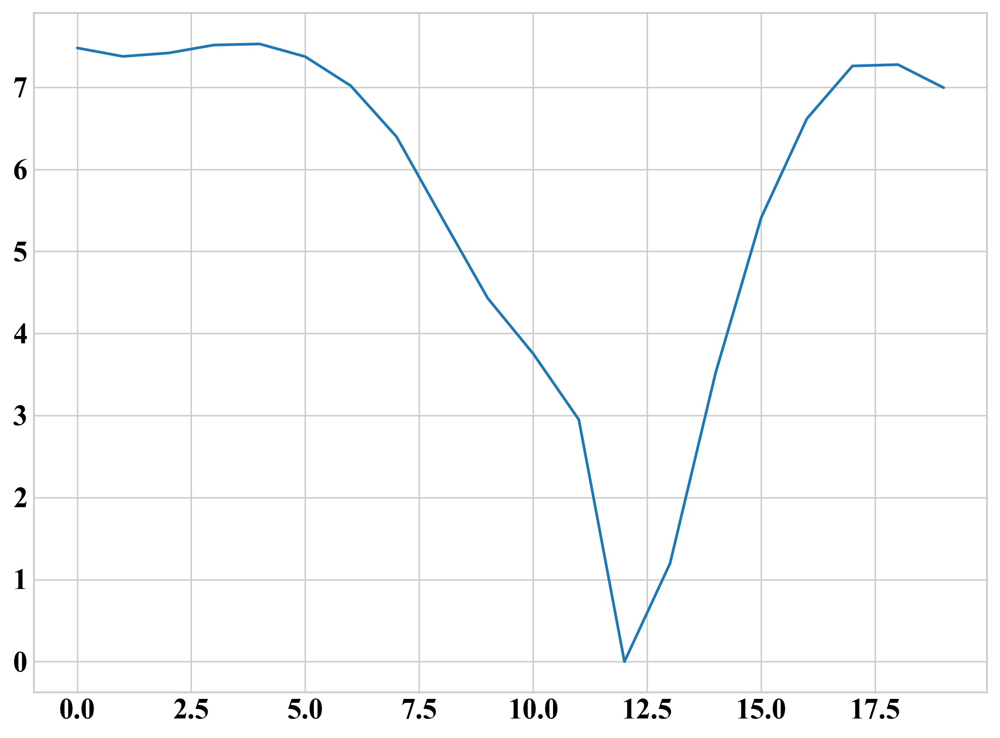

In [174]:
plt.plot(sigma)

<Figure size 3000x1800 with 0 Axes>

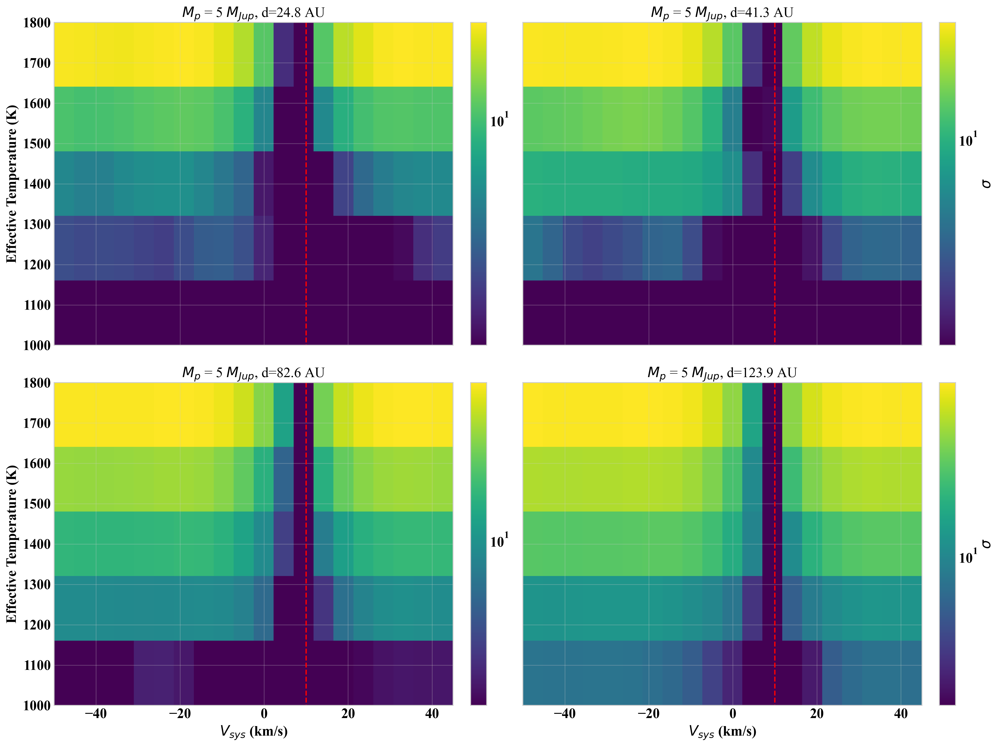

In [175]:
from matplotlib.colors import SymLogNorm, Normalize

# Plotting the sigma map for 10 MJ planets at 4 positions
plt.figure(figsize=(10, 6))

fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharex=True, sharey=True)
axes = axes.flatten()

plt.rcParams.update({'font.size': 14})



for i, sep in enumerate([3, 5, 10, 15]):
    ax = axes[i]
    sep_AU = 140*sep*(0.059)
    #Normalize the color scale based on 5 sigma limit 
    norm = SymLogNorm(vmin=3, vmax=np.nanmax(sigma_map_5MJ[i][0]), linthresh=5, linscale=1, base=10)

    im = ax.imshow(sigma_map_5MJ[i][0], aspect='auto', origin='upper', cmap='viridis', 
            extent=[-50, 45, Teff_5[-1], Teff_5[0]],
            interpolation='nearest',
            norm=norm)
    ax.set_xlabel(r'$V_{sys}$ (km/s)' if i >= 2 else '')
    ax.set_ylabel('Effective Temperature (K)' if i % 2 == 0 else '')
    ax.vlines(x=10, ymin=Teff_5[0], ymax=Teff_5[-1], color='red', linestyle='--', label='10 km/s')
    ax.set_title(f'$M_p$ = 5 $M_{{Jup}}$, d={sep_AU:.1f} AU')
    ax.grid(True, alpha=0.3)
    fig.colorbar(im, ax=ax, label=r'$\sigma$' if i % 2 == 1 else '', fraction=0.046, pad=0.04)
    ax.set_ylim(Teff_5[-1], Teff_5[0])
    ax.set_xlim(-50, 45)
    #ax.legend()

plt.tight_layout()
plt.show()



<Figure size 3000x1800 with 0 Axes>

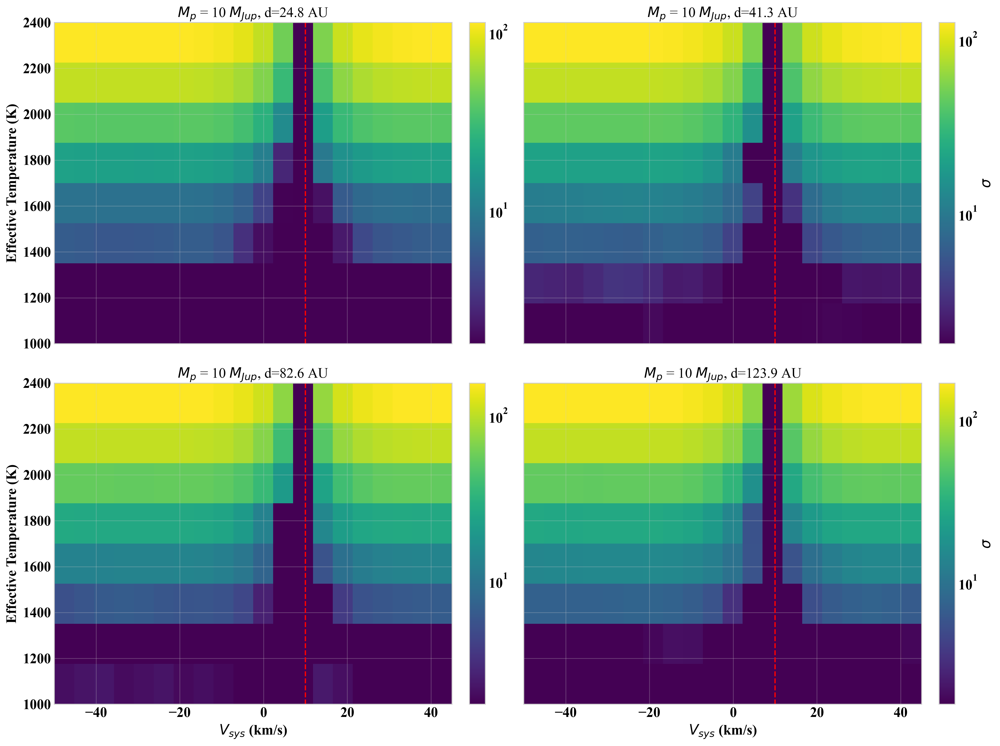

In [176]:
# Plotting the sigma map for 10 MJ planets at 4 positions
plt.figure(figsize=(10, 6))

fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharex=True, sharey=True)
axes = axes.flatten()

plt.rcParams.update({'font.size': 16})



for i, sep in enumerate([3, 5, 10, 15]):
    ax = axes[i]
    sep_AU = 140*sep*(0.059)
    #Normalize the color scale based on 5 sigma limit 
    norm = SymLogNorm(vmin=3, vmax=np.nanmax(sigma_map_10MJ[i][0]), linthresh=5, linscale=1, base=10)

    im = ax.imshow(sigma_map_10MJ[i][0], aspect='auto', origin='upper', cmap='viridis', 
            extent=[-50, 45, Teff_10[-1], Teff_10[0]],
            interpolation='nearest',
            norm=norm)
    ax.set_xlabel(r'$V_{sys}$ (km/s)' if i >= 2 else '')
    ax.set_ylabel('Effective Temperature (K)' if i % 2 == 0 else '')
    ax.vlines(x=10, ymin=Teff_10[0], ymax=Teff_10[-1], color='red', linestyle='--', label='10 km/s')
    ax.set_title(f'$M_p$ = 10 $M_{{Jup}}$, d={sep_AU:.1f} AU')
    ax.grid(True, alpha=0.3)
    fig.colorbar(im, ax=ax, label=r'$\sigma$' if i % 2 == 1 else '', fraction=0.046, pad=0.04)
    ax.set_ylim(Teff_10[-1], Teff_10[0])
    ax.set_xlim(-50, 45)
    #ax.legend()

plt.tight_layout()
plt.show()

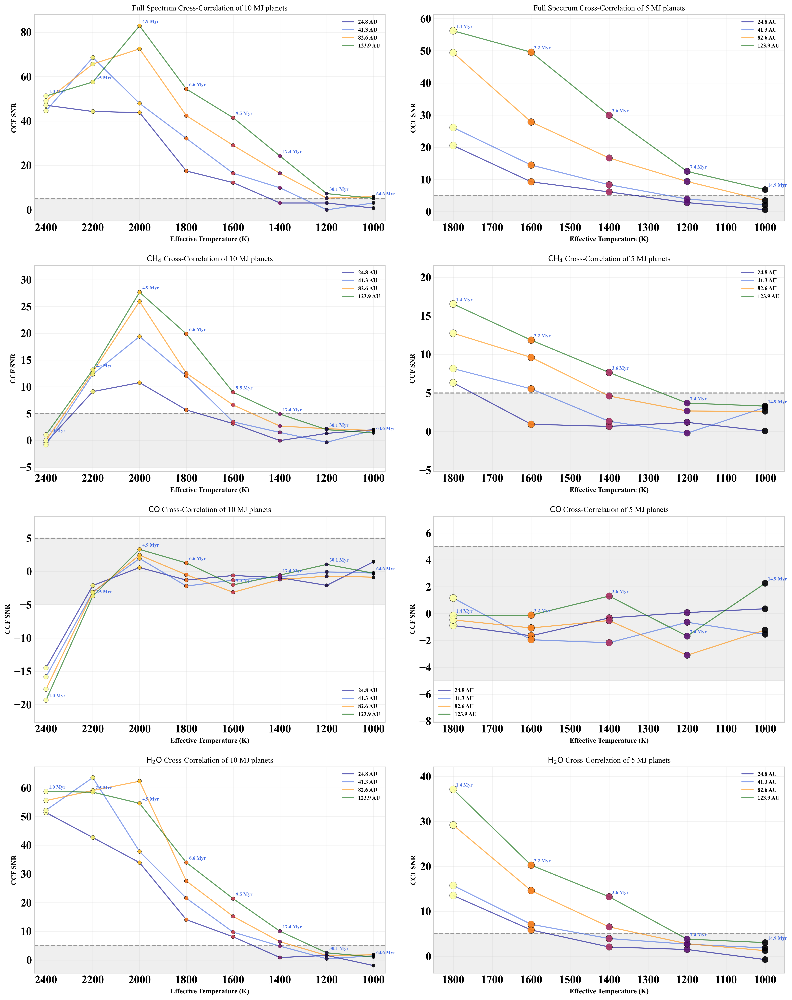

In [177]:
# Compare the S/N at different positions
def plot_ccf_panel(ax, teff_3, teff_5, teff_10, teff_15,  delta_mag_3, delta_mag_5, delta_mag_10, delta_mag_15,
                   snr_3, snr_5, snr_10, snr_15, r_3, r_5, r_10, r_15, age_3, age_5, age_10, age_15,
                   title, label):
    """Scatter plot for CCF SNR vs Teff with ΔK encoded as color."""
    Norm=plt.Normalize(vmin=np.min(delta_mag_3), vmax=np.max(delta_mag_15))
    #Scatter 3 pixels
    sc0 = ax.scatter(teff_3, snr_3, s=r_3, c=delta_mag_3,
                     cmap=cmap, norm=Norm, alpha=0.9,
                     edgecolor="k", linewidth=0.3, zorder=3)
    order3 = np.argsort(teff_3)
    ax.plot(teff_3[order3], snr_3[order3], color="darkblue", alpha=0.6, zorder=2,label=label[0])

    # Scatter 5 pixels
    sc1 = ax.scatter(teff_5, snr_5, s=r_5, c=delta_mag_5,
                     cmap=cmap, norm=Norm, alpha=0.9,
                     edgecolor="k", linewidth=0.3, zorder=3)
    order5 = np.argsort(teff_5)
    ax.plot(teff_5[order5], snr_5[order5], color="royalblue", alpha=0.6, zorder=2,label=label[1])

    # Scatter 10 pixels
    sc2 = ax.scatter(teff_10, snr_10, s=r_10, c=delta_mag_10,
                     cmap=cmap, norm=Norm, alpha=0.9,
                     edgecolor="k", linewidth=0.3, zorder=3)
    order10 = np.argsort(teff_10)
    ax.plot(teff_10[order10], snr_10[order10], color="darkorange", alpha=0.6, zorder=2,label=label[2])

    # Scatter 15 pixels
    sc3 = ax.scatter(teff_15, snr_15, s=r_15, c=delta_mag_15,
                     cmap=cmap, norm=Norm, alpha=0.9,
                     edgecolor="k", linewidth=0.3, zorder=3)

    order15 = np.argsort(teff_15)
    ax.plot(teff_15[order15], snr_15[order15], color="darkgreen", alpha=0.6, zorder=2,label=label[3])   

    # Annotate ages
    for i in range(len(teff_15)):
        ax.annotate(f"{age_15[i]:.1f} Myr", (teff_15[i], snr_15[i]),
                    xytext=(4, 4), textcoords="offset points", fontsize=7, color="royalblue")


    # Detection threshold shading
    ax.axhspan(SNR_THRESHOLD[0], SNR_THRESHOLD[1], color="lightgrey", alpha=0.35, zorder=0)
    ax.axhline(SNR_THRESHOLD[1], linestyle="--", color="grey", alpha=0.8, zorder=1)
    ax.set_ylim(np.nanmin([np.nanmin(snr_5), np.nanmin(snr_10)]) - 5, np.nanmax([np.nanmax(snr_15), np.nanmax(snr_10)]) + 5)

    # Labels and grid
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Effective Temperature (K)", fontsize=10)
    ax.set_ylabel("CCF SNR", fontsize=10)
    ax.grid(alpha=0.25)

    # Reverse x-axis (hot → cool)
    ax.invert_xaxis()
    teff_min = min(np.min(teff_5), np.min(teff_10)) - 50
    teff_max = max(np.max(teff_5), np.max(teff_10)) + 50
    ax.set_xlim(teff_max, teff_min)

    ax.legend(fontsize=8)
    ax.set_yscale('linear')


data_10=pd.read_csv(path+'simulation_log_10.csv')
data_15=pd.read_csv(path+'simulation_log_15.csv')
data_5=pd.read_csv(path+'simulation_log_5.csv')
data_3=pd.read_csv(path+'simulation_log_3.csv')

cut_10_10=data_10.loc[(data_10['M_planet']==10)]
cut_10_5=data_10.loc[(data_10['M_planet']==5)]

cut_15_10=data_15.loc[(data_15['M_planet']==10)]
cut_15_5=data_15.loc[(data_15['M_planet']==5)]

cut_5_10=data_5.loc[(data_5['M_planet']==10)]
cut_5_5=data_5.loc[(data_5['M_planet']==5)]

cut_3_10=data_3.loc[(data_3['M_planet']==10)]
cut_3_5=data_3.loc[(data_3['M_planet']==5)]

snr_10_10=cut_10_10['CCF_Full_Spectrum'].values
snr_10_5=cut_10_5['CCF_Full_Spectrum'].values
Teff_10_10=cut_10_10['Teff_planet'].values
Teff_10_5=cut_10_5['Teff_planet'].values
delta_mag_10_10=cut_10_10['Mag_planet_K'].values-cut_10_10['Mag_star_K'].values
delta_mag_10_5=cut_10_5['Mag_planet_K'].values-cut_10_5['Mag_star_K'].values

ccf_mol_10_10=cut_10_10[['CCF_CH4_only', 'CCF_CO_only', 'CCF_H2O_only']].values.T
ccf_mol_10_5=cut_10_5[['CCF_CH4_only', 'CCF_CO_only', 'CCF_H2O_only']].values.T


snr_15_10=cut_15_10['CCF_Full_Spectrum'].values
snr_15_5=cut_15_5['CCF_Full_Spectrum'].values
Teff_15_10=cut_15_10['Teff_planet'].values
Teff_15_5=cut_15_5['Teff_planet'].values
delta_mag_15_10=cut_15_10['Mag_planet_K'].values-cut_15_10['Mag_star_K'].values
delta_mag_15_5=cut_15_5['Mag_planet_K'].values-cut_15_5['Mag_star_K'].values

ccf_mol_15_10=cut_15_10[['CCF_CH4_only', 'CCF_CO_only', 'CCF_H2O_only']].values.T
ccf_mol_15_5=cut_15_5[['CCF_CH4_only', 'CCF_CO_only', 'CCF_H2O_only']].values.T

snr_5_10=cut_5_10['CCF_Full_Spectrum'].values
snr_5_5=cut_5_5['CCF_Full_Spectrum'].values
Teff_5_10=cut_5_10['Teff_planet'].values
Teff_5_5=cut_5_5['Teff_planet'].values
delta_mag_5_10=cut_5_10['Mag_planet_K'].values-cut_5_10['Mag_star_K'].values
delta_mag_5_5=cut_5_5['Mag_planet_K'].values-cut_5_5['Mag_star_K'].values

ccf_mol_5_10=cut_5_10[['CCF_CH4_only', 'CCF_CO_only', 'CCF_H2O_only']].values.T
ccf_mol_5_5=cut_5_5[['CCF_CH4_only', 'CCF_CO_only', 'CCF_H2O_only']].values.T

snr_3_10=cut_3_10['CCF_Full_Spectrum'].values
snr_3_5=cut_3_5['CCF_Full_Spectrum'].values
Teff_3_10=cut_3_10['Teff_planet'].values
Teff_3_5=cut_3_5['Teff_planet'].values
delta_mag_3_10=cut_3_10['Mag_planet_K'].values-cut_3_10['Mag_star_K'].values
delta_mag_3_5=cut_3_5['Mag_planet_K'].values-cut_3_5['Mag_star_K'].values

ccf_mol_3_10=cut_3_10[['CCF_CH4_only', 'CCF_CO_only', 'CCF_H2O_only']].values.T
ccf_mol_3_5=cut_3_5[['CCF_CH4_only', 'CCF_CO_only', 'CCF_H2O_only']].values.T

d=140 #pc
sep_AU=np.round(d*(np.array([3,5,10,15])*0.059), 1)

fig, axs = plt.subplots(4, 2, figsize=(16, 20))
axs = axs.flatten()
#adjust the space between subplots
plt.subplots_adjust(hspace=0.4, wspace=0.3)

plot_ccf_panel(axs[0], Teff_3_10, Teff_5_10, Teff_10_10, Teff_15_10, delta_mag_3_10, delta_mag_5_10, delta_mag_10_10, delta_mag_15_10,
               snr_3_10, snr_5_10, snr_10_10, snr_15_10,
               marker_sizes_10, marker_sizes_10, marker_sizes_10, marker_sizes_10,
               Age_10, Age_10, Age_10, Age_10,
               "Full Spectrum Cross-Correlation of 10 MJ planets",
               ['%s AU'%sep_AU[0], '%s AU'%sep_AU[1], '%s AU'%sep_AU[2],'%s AU'%sep_AU[3]])


plot_ccf_panel(axs[1], Teff_3_5, Teff_5_5, Teff_10_5, Teff_15_5, delta_mag_3_5, delta_mag_5_5, delta_mag_10_5, delta_mag_15_5,
               snr_3_5, snr_5_5, snr_10_5, snr_15_5,
               marker_sizes_5, marker_sizes_5, marker_sizes_5, marker_sizes_5,
               Age_5, Age_5, Age_5, Age_5,
               "Full Spectrum Cross-Correlation of 5 MJ planets",
               ['%s AU'%sep_AU[0], '%s AU'%sep_AU[1], '%s AU'%sep_AU[2], '%s AU'%sep_AU[3]])   


# Panels 2-7: Molecule-specific
x=0
for i in np.arange(2,8,2):
    
    plot_ccf_panel(axs[i], Teff_3_10, Teff_5_10, Teff_10_10, Teff_15_10, delta_mag_3_10, delta_mag_5_10, delta_mag_10_10, delta_mag_15_10,
                   ccf_mol_3_10[x], ccf_mol_5_10[x], ccf_mol_10_10[x], ccf_mol_15_10[x],
                   marker_sizes_10, marker_sizes_10, marker_sizes_10, marker_sizes_10,
                   Age_10, Age_10, Age_10, Age_10,
                   f"{molecule_labels[x]} Cross-Correlation of 10 MJ planets", label=['%s AU'%sep_AU[0], '%s AU'%sep_AU[1], '%s AU'%sep_AU[2], '%s AU'%sep_AU[3]])

    plot_ccf_panel(axs[i+1], Teff_3_5, Teff_5_5, Teff_10_5, Teff_15_5, delta_mag_3_5, delta_mag_5_5, delta_mag_10_5, delta_mag_15_5,
                    ccf_mol_3_5[x], ccf_mol_5_5[x], ccf_mol_10_5[x], ccf_mol_15_5[x],
                    marker_sizes_5, marker_sizes_5, marker_sizes_5,marker_sizes_5,
                    Age_5, Age_5, Age_5,Age_5,
                    f"{molecule_labels[x]} Cross-Correlation of 5 MJ planets", ['%s AU'%sep_AU[0], '%s AU'%sep_AU[1], '%s AU'%sep_AU[2], '%s AU'%sep_AU[3]])

    i+=2
    x+=1

plt.show()

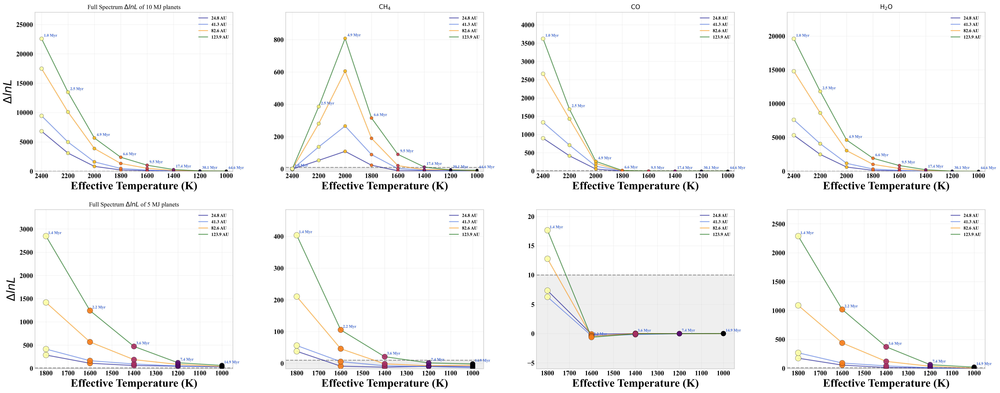

In [178]:
# Compare the S/N at different positions
from scipy.optimize import brentq
#Determine the temperature threshold corresponding to 5 sigma from the likelihood curves
def threshold_from_curve(sigma, Teff, target_sigma=5):
    """intepolate the delta_lnL curve to find the threshold corresponding to target_sigma."""
    from scipy.interpolate import interp1d

    #sigma = np.sqrt(2 * delta_lnL)
    interp_func = interp1d(Teff, sigma, bounds_error=False, fill_value="extrapolate")
    # Find Teff where sigma crosses target_sigma
    def find_threshold_func(teff):
        return interp_func(teff) - target_sigma

    teff_min = np.min(Teff)
    teff_max = np.max(Teff)
    threshold_T = brentq(find_threshold_func, teff_min, teff_max)
    return threshold_T


def plot_likelihood_panel(ax, teff_3, teff_5, teff_10, teff_15,  delta_mag_3, delta_mag_5, delta_mag_10, delta_mag_15,
                   likelihood_3, likelihood_5, likelihood_10, likelihood_15, r_3, r_5, r_10, r_15, age_3, age_5, age_10, age_15,
                   title, Ylabel, label, threshold=10, Yscale="linear", Ylim=None, output_thresholds=False):
    """Scatter plot for CCF SNR vs Teff with ΔK encoded as color."""

    norm=plt.Normalize(vmin=np.min(delta_mag_3), vmax=np.max(delta_mag_15))
    #change the fontsize of the ticks
    ax.tick_params(axis='both', which='major', labelsize=12)
    ax.tick_params(axis='both', which='minor', labelsize=10)

    #Scatter 3 pixels
    sc0 = ax.scatter(teff_3, likelihood_3, s=r_3, c=delta_mag_3,
                     cmap=cmap, norm=norm, alpha=0.9,
                     edgecolor="k", linewidth=0.3, zorder=3)
    order3 = np.argsort(teff_3)
    ax.plot(teff_3[order3], likelihood_3[order3], color="darkblue", alpha=0.6, zorder=2,label=label[0])

    # Scatter 5 pixels
    sc1 = ax.scatter(teff_5, likelihood_5, s=r_5, c=delta_mag_5,
                     cmap=cmap, norm=norm, alpha=0.9,
                     edgecolor="k", linewidth=0.3, zorder=3)
    order5 = np.argsort(teff_5)
    ax.plot(teff_5[order5], likelihood_5[order5], color="royalblue", alpha=0.6, zorder=2,label=label[1])

    # Scatter 10 pixels
    sc2 = ax.scatter(teff_10, likelihood_10, s=r_10, c=delta_mag_10,
                     cmap=cmap, norm=norm, alpha=0.9,
                     edgecolor="k", linewidth=0.3, zorder=3)
    order10 = np.argsort(teff_10)
    ax.plot(teff_10[order10], likelihood_10[order10], color="darkorange", alpha=0.6, zorder=2,label=label[2])

    # Scatter 15 pixels
    sc3 = ax.scatter(teff_15, likelihood_15, s=r_15, c=delta_mag_15,
                     cmap=cmap, norm=norm, alpha=0.9,
                     edgecolor="k", linewidth=0.3, zorder=3)

    order15 = np.argsort(teff_15)
    ax.plot(teff_15[order15], likelihood_15[order15], color="darkgreen", alpha=0.6, zorder=2,label=label[3])   

    # Annotate ages
    for i in range(len(teff_15)):
        ax.annotate(f"{age_15[i]:.1f} Myr", (teff_15[i], likelihood_15[i]),
                    xytext=(4, 4), textcoords="offset points", fontsize=7, color="royalblue")

    # Detection threshold shading
    likeli_THRESHOLD = [np.nanmin([np.nanmin(likelihood_3), np.nanmin(likelihood_5)]) - 200, threshold]

    ax.axhspan(likeli_THRESHOLD[0], likeli_THRESHOLD[1], color="lightgrey", alpha=0.35, zorder=0)
    ax.axhline(likeli_THRESHOLD[1], linestyle="--", color="grey", alpha=0.8, zorder=1)
    if Ylim is None:
        ax.set_ylim(np.nanmin([np.nanmin(likelihood_3), np.nanmin(likelihood_5),-5])*1.2, np.nanmax([np.nanmax(likelihood_15), np.nanmax(likelihood_10)])*1.2)
    else:
        ax.set_ylim(Ylim)

    # Labels and grid
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Effective Temperature (K)", fontsize=20)
    ax.set_ylabel(Ylabel, fontsize=20)
    ax.grid(alpha=0.25)

    # Reverse x-axis (hot → cool)
    ax.invert_xaxis()
    teff_min = min(np.min(teff_5), np.min(teff_10))-50
    teff_max = max(np.max(teff_5), np.max(teff_10))+50
    ax.set_xlim(teff_max, teff_min)

    ax.legend(fontsize=8)
    ax.set_yscale(Yscale)

    if output_thresholds:

        Thres_Teff_3 = threshold_from_curve(likelihood_3, teff_3, target_sigma=5)
        Thres_Teff_5 = threshold_from_curve(likelihood_5, teff_5, target_sigma=5)
        Thres_Teff_10 = threshold_from_curve(likelihood_10, teff_10, target_sigma=5)
        Thres_Teff_15 = threshold_from_curve(likelihood_15, teff_15, target_sigma=5)

        print(Thres_Teff_3, Thres_Teff_5, Thres_Teff_10, Thres_Teff_15)







d=140 #pc
sep_AU=np.round(d*(np.array([3,5,10,15])*0.059), 1)

fig, axs = plt.subplots(2, 4, figsize=(25, 10), dpi=300)
axs = axs.flatten()
#adjust the space between subplots
plt.subplots_adjust(hspace=0.4, wspace=0.3)

plot_likelihood_panel(axs[0], Teff_3_10, Teff_5_10, Teff_10, Teff_15_10, delta_mag_3_10, delta_mag_5_10, delta_mag_10, delta_mag_15_10,
               likelihood_3_10[0], likelihood_5_10[0], likelihood_10_10[0], likelihood_15_10[0],
               marker_sizes_10, marker_sizes_10, marker_sizes_10, marker_sizes_10,
               Age_10, Age_10, Age_10, Age_10,
               r"Full Spectrum $\Delta ln L$ of 10 MJ planets", Ylabel=r"$\Delta ln L$",
               label=['%s AU'%sep_AU[0], '%s AU'%sep_AU[1], '%s AU'%sep_AU[2],'%s AU'%sep_AU[3]], Yscale='linear', output_thresholds=False)


plot_likelihood_panel(axs[4], Teff_3_5, Teff_5_5, Teff_5, Teff_15_5, delta_mag_3_5, delta_mag_5_5, delta_mag_5, delta_mag_15_5,
               likelihood_3_5[0], likelihood_5_5[0], likelihood_10_5[0], likelihood_15_5[0],
               marker_sizes_5, marker_sizes_5, marker_sizes_5, marker_sizes_5,
               Age_5, Age_5, Age_5, Age_5,
               r"Full Spectrum $\Delta ln L$ of 5 MJ planets", Ylabel=r"$\Delta ln L$",
               label=['%s AU'%sep_AU[0], '%s AU'%sep_AU[1], '%s AU'%sep_AU[2], '%s AU'%sep_AU[3]], Yscale='linear')   


# Panels 2-7: Molecule-specific
x=1
for i in [1,2,3]:
    
    plot_likelihood_panel(axs[i], Teff_3_10, Teff_5_10, Teff_10, Teff_15_10, delta_mag_3_10, delta_mag_5_10, delta_mag_10, delta_mag_15_10,
                   likelihood_3_10[x], likelihood_5_10[x], likelihood_10_10[x], likelihood_15_10[x],
                   marker_sizes_10, marker_sizes_10, marker_sizes_10, marker_sizes_10,
                   Age_10, Age_10, Age_10, Age_10,
                   f"{molecule_labels[x-1]}", label=['%s AU'%sep_AU[0], '%s AU'%sep_AU[1], '%s AU'%sep_AU[2], '%s AU'%sep_AU[3]],
                   Ylabel=" ")

    plot_likelihood_panel(axs[i+4], Teff_3_5, Teff_5_5, Teff_5, Teff_15_5, delta_mag_3_5, delta_mag_5_5, delta_mag_5, delta_mag_15_5,
                    likelihood_3_5[x], likelihood_5_5[x], likelihood_10_5[x], likelihood_15_5[x],
                    marker_sizes_5, marker_sizes_5, marker_sizes_5,marker_sizes_5,
                    Age_5, Age_5, Age_5,Age_5,
                    " ", label=['%s AU'%sep_AU[0], '%s AU'%sep_AU[1], '%s AU'%sep_AU[2], '%s AU'%sep_AU[3]],
                    Ylabel=" ")

    i+=2
    x+=1

plt.show()






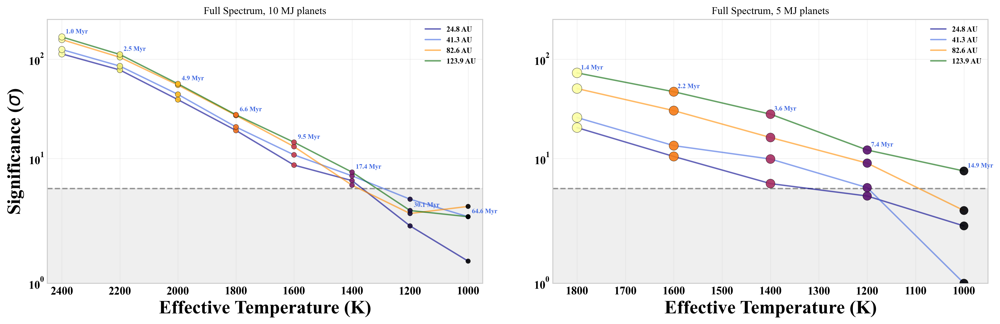

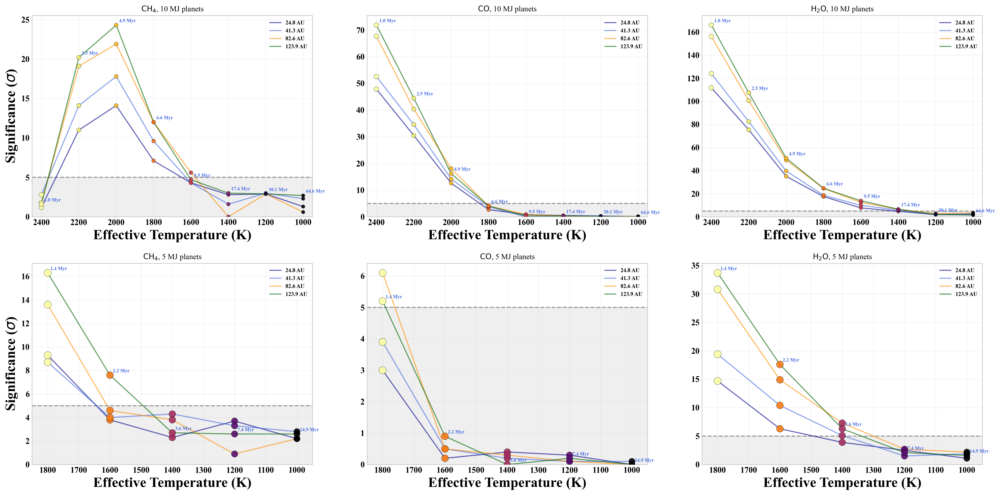

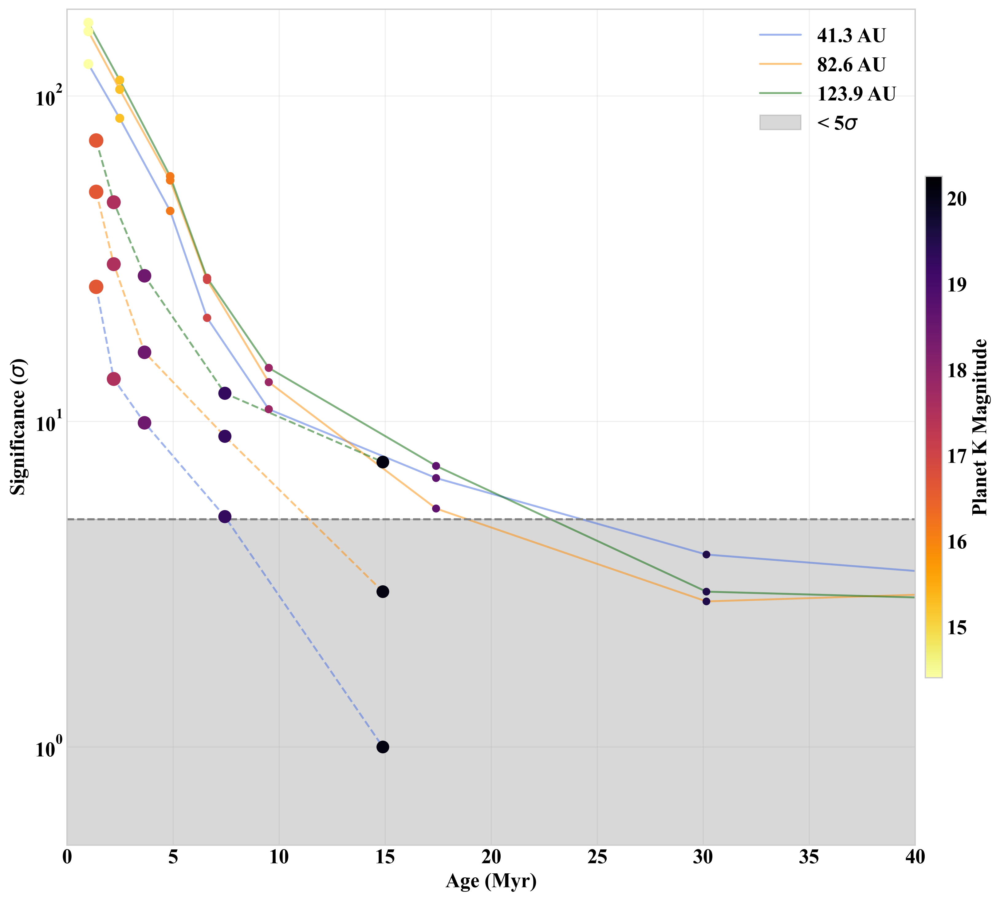

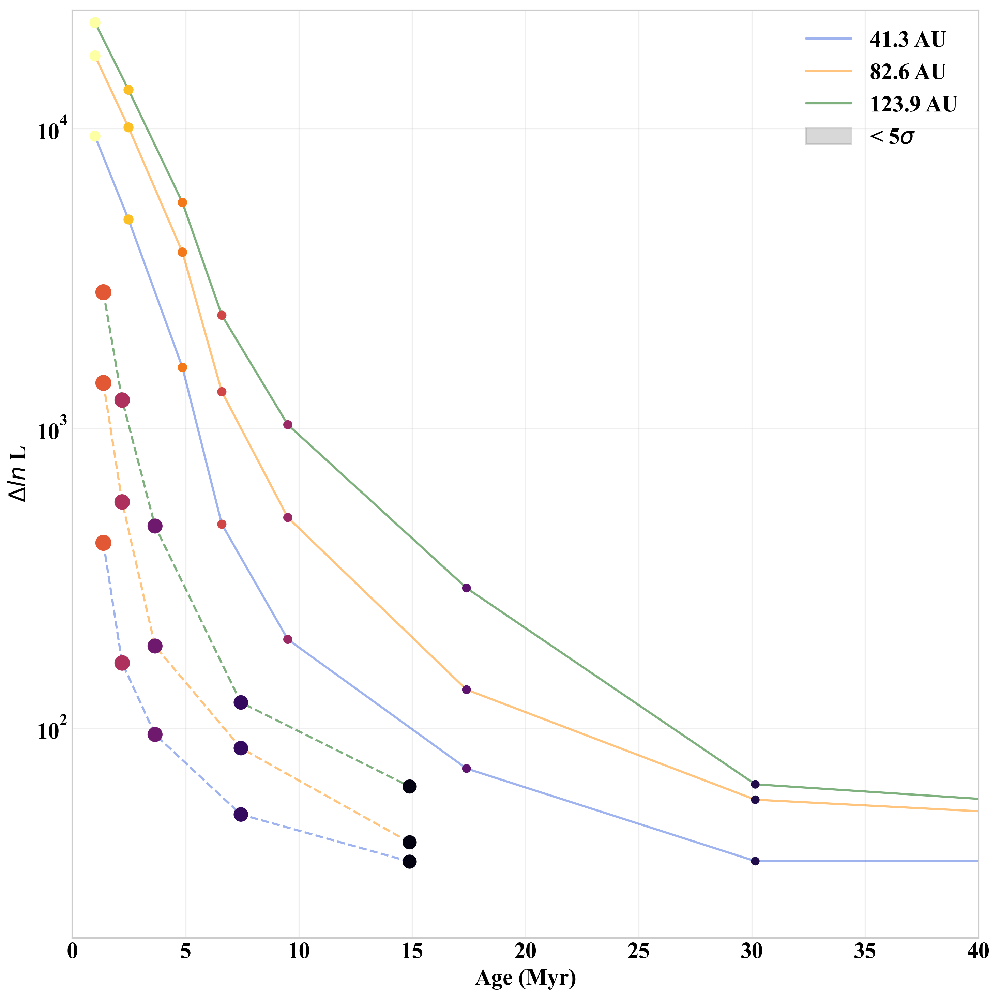

In [179]:
d=140 #pc
sep_AU=np.round(d*(np.array([3,5,10,15])*0.059), 1)

fig, axs = plt.subplots(1, 2, figsize=(15, 5), sharey=False, dpi=300)
axs = axs.flatten()
#adjust the space between subplots
plt.subplots_adjust(hspace=0.2, wspace=0.1)

plt.rcParams.update({'font.size': 14})

thres=5

plot_likelihood_panel(axs[0], Teff_3_10, Teff_5_10, Teff_10, Teff_15_10, delta_mag_3_10, delta_mag_5_10, delta_mag_10, delta_mag_15_10,
               sigma_array_10[:,0,0], sigma_array_10[:,1,0], sigma_array_10[:,2,0], sigma_array_10[:,3,0],
               marker_sizes_10, marker_sizes_10, marker_sizes_10, marker_sizes_10,
               Age_10, Age_10, Age_10, Age_10,
               r"Full Spectrum, 10 MJ planets",
               label=['%s AU'%sep_AU[0], '%s AU'%sep_AU[1], '%s AU'%sep_AU[2],'%s AU'%sep_AU[3]],
               Ylabel=r"Significance ($\sigma$)", threshold=thres, Yscale='symlog', Ylim=(1, np.nanmax(sigma_array_10[:,:,0])*1.5), output_thresholds=False)


plot_likelihood_panel(axs[1], Teff_3_5, Teff_5_5, Teff_5, Teff_15_5, delta_mag_3_5, delta_mag_5_5, delta_mag_5, delta_mag_15_5,
               sigma_array_5[:,0,0], sigma_array_5[:,1, 0], sigma_array_5[:,2, 0], sigma_array_5[:,3, 0],
               marker_sizes_5, marker_sizes_5, marker_sizes_5, marker_sizes_5,
               Age_5, Age_5, Age_5, Age_5,
               r"Full Spectrum, 5 MJ planets",
               label=['%s AU'%sep_AU[0], '%s AU'%sep_AU[1], '%s AU'%sep_AU[2], '%s AU'%sep_AU[3]],
               Ylabel=" ", threshold=thres, Yscale='symlog', Ylim=(1, np.nanmax(sigma_array_10[:,:,0])*1.5), output_thresholds=False)   

plt.show()

fig, axs = plt.subplots(2, 3, figsize=(20, 10), sharey=False, dpi=300)
axs = axs.flatten()
#adjust the space between subplots
plt.subplots_adjust(hspace=0.4, wspace=0.1)

# Panels 2-7: Molecule-specific
x=1
for i in np.arange(0,3,1):
    
    plot_likelihood_panel(axs[i], Teff_3_10, Teff_5_10, Teff_10, Teff_15_10, delta_mag_3_10, delta_mag_5_10, delta_mag_10, delta_mag_15_10,
                   sigma_array_10[:,0,x], sigma_array_10[:,1,x], sigma_array_10[:,2,x], sigma_array_10[:,3,x],
                   marker_sizes_10, marker_sizes_10, marker_sizes_10, marker_sizes_10,
                   Age_10, Age_10, Age_10, Age_10,
                   f"{molecule_labels[x-1]}, 10 MJ planets", label=['%s AU'%sep_AU[0], '%s AU'%sep_AU[1], '%s AU'%sep_AU[2], '%s AU'%sep_AU[3]],
                   Ylabel=r"Significance ($\sigma$)" if i == 0 else " ", threshold=thres, Yscale='linear', Ylim=(0, np.nanmax(sigma_array_10[:,:,x])*1.05))

    plot_likelihood_panel(axs[i+3], Teff_3_5, Teff_5_5, Teff_5, Teff_15_5, delta_mag_3_5, delta_mag_5_5, delta_mag_5, delta_mag_15_5,
                    sigma_array_5[:,0,x], sigma_array_5[:,1,x], sigma_array_5[:,2,x], sigma_array_5[:,3,x],
                    marker_sizes_5, marker_sizes_5, marker_sizes_5,marker_sizes_5,
                    Age_5, Age_5, Age_5,Age_5,
                    f"{molecule_labels[x-1]}, 5 MJ planets", label=['%s AU'%sep_AU[0], '%s AU'%sep_AU[1], '%s AU'%sep_AU[2], '%s AU'%sep_AU[3]],
                    Ylabel=r"Significance ($\sigma$)" if i == 0 else " ", threshold=thres, Yscale='linear', Ylim=(0, np.nanmax(sigma_array_5[:,:,x])*1.05))

    

    i+=2
    x+=1

plt.show()


#plot sigma for the full spectrum with axis of age for 5MJ and 10MJ planets on the same plot

#Using color list representing different temperatures from (1000, 2400, 200)K
all_mag = np.concatenate([Mag_planet_5, Mag_planet_10])
norm = Normalize(vmin=np.nanmin(all_mag), vmax=np.nanmax(all_mag))
cmap = cm.inferno_r

color_line = ['darkblue', 'royalblue', 'darkorange', 'darkgreen']

#plt.figure(figsize=(10, 6))

fig, axes = plt.subplots(1, 1, figsize=(12, 10))

plt.rcParams.update({'font.size': 14})

# Create a dummy scatter plot to use as the mappable for the colorbar

for i, sep in enumerate([5, 10, 15]):
    axes.scatter(Age_5, sigma_array_5[:,i+1, 0], marker='o', color=cmap(norm(Mag_planet_5)), s=marker_sizes_5, zorder=3)
    axes.scatter(Age_10, sigma_array_10[:,i+1,0], marker='o', color=cmap(norm(Mag_planet_10)), s=marker_sizes_10, zorder=3)

    # Connect the points with lines
    axes.plot(Age_5, sigma_array_5[:,i+1,0], linestyle='--', color=color_line[i+1], alpha=0.5, zorder=2)
    axes.plot(Age_10, sigma_array_10[:,i+1,0], linestyle='-', color=color_line[i+1], alpha=0.5, zorder=2, label='%s AU'%sep_AU[i+1])

    axes.set_ylim(0.5, np.nanmax(np.concatenate([sigma_array_5[:,:,0], sigma_array_10[:,:,0]]))*1.1)
    axes.set_xlim(0, 40)

    axes.axhline(5, color='grey', linestyle='--')

   

    axes.grid(True, alpha=0.3)

    axes.set_yscale('log')

scatter = plt.scatter([], [], c=[], cmap=cmap, norm=norm)
cbar = plt.colorbar(scatter, ax=axes, label='Planet K Magnitude', orientation='vertical', pad=0.01, aspect=30, shrink=0.6)  


axes.axhspan(-2, 5, color='gray', alpha=0.3, label='< 5$\sigma$')
axes.set_ylabel('Significance ($\sigma$)')
axes.set_xlabel('Age (Myr)')
plt.legend()
#plt.suptitle('Significance vs Age for Full Spectrum')
#plt.subplots_adjust(hspace=0, wspace=0.1)  # Set space between plots to zero
plt.show()

fig, axes = plt.subplots(1, 1, figsize=(10, 10))

likelihood_5_all=np.array([likelihood_3_5, likelihood_5_5, likelihood_10_5, likelihood_15_5])
likelihood_10_all=np.array([likelihood_3_10, likelihood_5_10, likelihood_10_10, likelihood_15_10])

for i, sep in enumerate([5, 10, 15]):
    axes.scatter(Age_5, likelihood_5_all[i+1,0], marker='o', color=cmap(norm(Mag_planet_5)), s=marker_sizes_5, zorder=3)
    axes.scatter(Age_10, likelihood_10_all[i+1,0], marker='o', color=cmap(norm(Mag_planet_10)), s=marker_sizes_10, zorder=3)

    # Connect the points with lines
    axes.plot(Age_5, likelihood_5_all[i+1,0], linestyle='--', color=color_line[i+1], alpha=0.5, zorder=2)
    axes.plot(Age_10, likelihood_10_all[i+1,0], linestyle='-', color=color_line[i+1], alpha=0.5, zorder=2, label='%s AU'%sep_AU[i+1])

    axes.set_ylim(20, np.nanmax(np.concatenate([likelihood_5_all[:,0, 0], likelihood_10_all[:,0, 0]]))*1.1)
    axes.set_xlim(0, 40)

    axes.axhline(5, color='grey', linestyle='--')

   

    axes.grid(True, alpha=0.3)

    axes.set_yscale('symlog', linthresh=5)



axes.axhspan(-2, 5, color='gray', alpha=0.3, label='< 5$\sigma$')
axes.set_ylabel('$\Delta ln$ L')
axes.set_xlabel('Age (Myr)')
plt.legend()
#plt.suptitle('Significance vs Age for Full Spectrum')
#plt.subplots_adjust(hspace=0, wspace=0.1)  # Set space between plots to zero
plt.show()



In [180]:
simulation_log

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,Age,M_planet,Teff_planet,formation_scenario,R_planet,G_planet,Z_planet,...,CCF_CO_only,CCF_H2O_only,CCF_Full_Spectrum,CCF_CH4,CCF_CO,CCF_H2O,Likelihood_full,Likelihood_H2O,Likelihood_CO,Likelihood_CH4
0,0,0,0,1.37,5,1800,H,1.76,3.50,0.0,...,-0.466399,29.179984,49.402512,-7.578192,-3.391299,-10.095609,1418.521848,1089.095725,12.778947,210.524237
1,1,1,1,2.20,5,1600,H,1.63,3.50,0.0,...,-1.066023,14.596265,27.873522,-1.172913,-2.154291,-7.678261,568.537934,439.358573,-0.463749,46.162148
2,2,2,2,3.65,5,1400,H,1.53,3.50,0.0,...,-0.514743,6.519709,16.688980,-1.459907,1.548837,-1.867705,188.094391,119.634678,0.026143,-1.456017
3,3,3,3,7.44,5,1200,H,1.42,3.75,0.0,...,-3.098370,2.775333,9.392220,-0.268204,-1.182749,-0.451425,85.867867,35.557466,-0.023360,-7.397694
4,4,4,4,14.89,5,1000,H,1.33,3.75,0.0,...,-1.220582,1.244786,3.478050,-0.147950,-0.665502,-1.609585,41.653041,2.431967,-0.002631,-5.812036
5,5,5,5,1.00,10,2400,H,2.30,3.50,0.0,...,-17.683816,55.551560,49.089897,0.260042,0.253903,0.333136,17476.569191,14798.495256,2661.082757,0.450813
6,6,6,6,2.48,10,2200,H,1.84,3.75,0.0,...,-3.152299,59.056506,65.670900,-19.391029,-8.812764,0.706270,10095.880633,8631.806410,1427.850930,280.705105
7,7,7,7,4.86,10,2000,H,1.59,3.75,0.0,...,2.461036,62.295875,72.522176,-17.491841,-2.974098,-15.633214,3871.982935,3055.354519,207.260202,605.451989
8,8,8,8,6.60,10,1800,H,1.51,4.00,0.0,...,-0.489349,27.531671,42.438773,-1.607847,-1.625787,30.646840,1325.594480,1020.315792,5.575939,189.825228
9,9,9,9,9.51,10,1600,H,1.44,4.00,0.0,...,-3.122369,15.204893,29.059047,-2.704244,-2.533655,-3.382457,504.750895,410.546223,-0.254774,21.289619


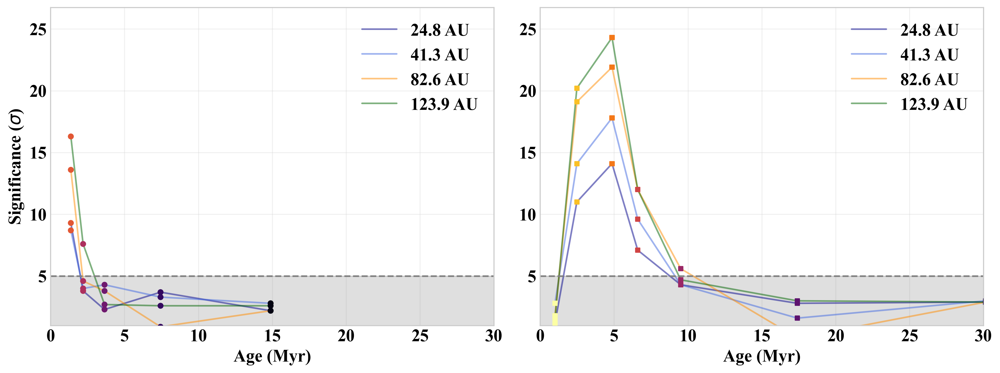

/var/folders/w_/fqznltwj2pz2y345p5_rzn3r0000gn/T/ipykernel_1990/3674536774.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_yticklabels(np.arange(0, ymax, ymax/6))
/var/folders/w_/fqznltwj2pz2y345p5_rzn3r0000gn/T/ipykernel_1990/3674536774.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_yticklabels(np.arange(0, ymax, ymax/6))


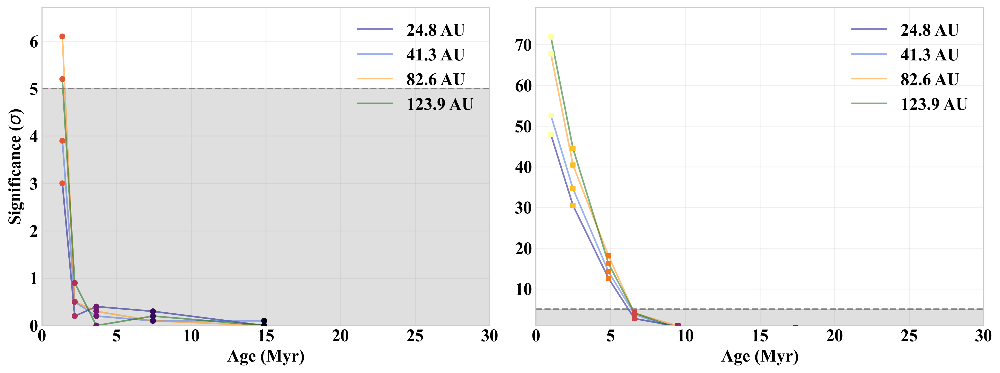

/var/folders/w_/fqznltwj2pz2y345p5_rzn3r0000gn/T/ipykernel_1990/3674536774.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_yticklabels(np.arange(0, ymax, ymax/6))
/var/folders/w_/fqznltwj2pz2y345p5_rzn3r0000gn/T/ipykernel_1990/3674536774.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_yticklabels(np.arange(0, ymax, ymax/6))


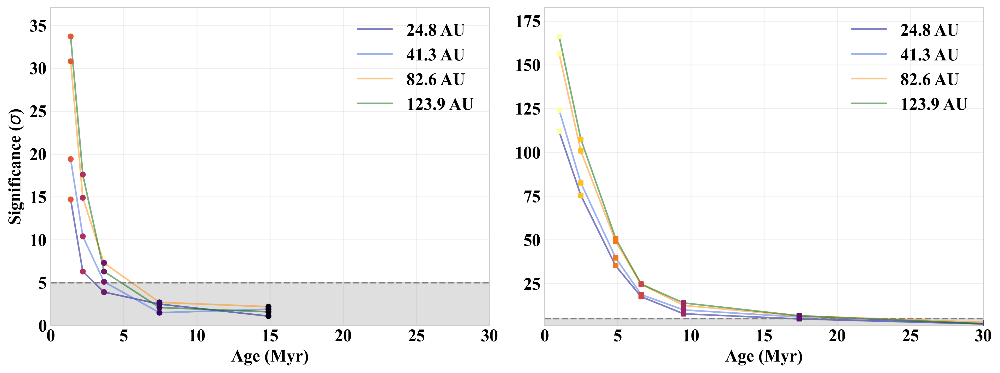

In [181]:

plt.rcParams.update({'font.size': 14})

# --- Create a normalizer and colormap ---
all_mag = np.concatenate([Mag_planet_5, Mag_planet_10])
norm = Normalize(vmin=np.nanmin(all_mag), vmax=np.nanmax(all_mag))
cmap = cm.inferno_r

color_line = ['darkblue', 'royalblue', 'darkorange', 'darkgreen']



# --- Loop over separations ---

for k in [1,2,3]:

    # --- Proper scalar mappable (needed for colorbar) ---
    sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])

    # --- Attach colorbar to the right without overlap ---
    cbar = fig.colorbar(
        sm, ax=axes if isinstance(axes, np.ndarray) else [axes],
        label='Planet K Magnitude',
        pad=0.02, aspect=30
    )

    fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=300)

    for i, sep in enumerate([3, 5, 10, 15]):

        # 5 MJ planets
        axes[0].scatter(
            Age_5, sigma_array_5[:, i, k],
            c=cmap(norm(Mag_planet_5)),
            s=20,
            alpha=1.0,
            zorder=3
        )
        axes[0].plot(
            Age_5, sigma_array_5[:, i, k],
            linestyle='-', color=color_line[i], alpha=0.5, zorder=2,
            label ='%s AU' % sep_AU[i]
        )

        # 10 MJ planets
        axes[1].scatter(
            Age_10, sigma_array_10[:, i, k],
            c=cmap(norm(Mag_planet_10)),
            s=15,
            marker= 's', 
            zorder=3
        )
        axes[1].plot(
            Age_10, sigma_array_10[:, i, k],
            linestyle='-', color=color_line[i], alpha=0.5, zorder=2,
            label ='%s AU' % sep_AU[i]
        )


    axes[0].legend(loc='upper right')
    axes[1].legend(loc='upper right')

    # --- Axis formatting ---
    ymax = np.nanmax(np.concatenate([sigma_array_5[:,:,k], sigma_array_10[:,:,k]])) * 1.1

    for ax in axes:
        ax.set_xlim(0, 30)
        ax.set_ylim(1, ymax)

        if k != 1:
            axes[0].set_ylim(0, np.nanmax(sigma_array_5[:,:,k]) * 1.1)
            axes[1].set_yticklabels(np.arange(0, ymax, ymax/6))

        ax.set_yscale('linear')
        ax.grid(True, alpha=0.3)

        ax.axhline(5, color='grey', linestyle='--')
        ax.axhspan(-2, 5, color='grey', alpha=0.25)

    axes[0].set_ylabel(r'Significance ($\sigma$)')
    axes[0].set_xlabel('Age (Myr)')
    axes[1].set_xlabel('Age (Myr)')
  

    # Tight layout to prevent overlap
    #fig.tight_layout()
    #fig.subplots_adjust(wspace=0.1, hspace=2.5)

    plt.show()


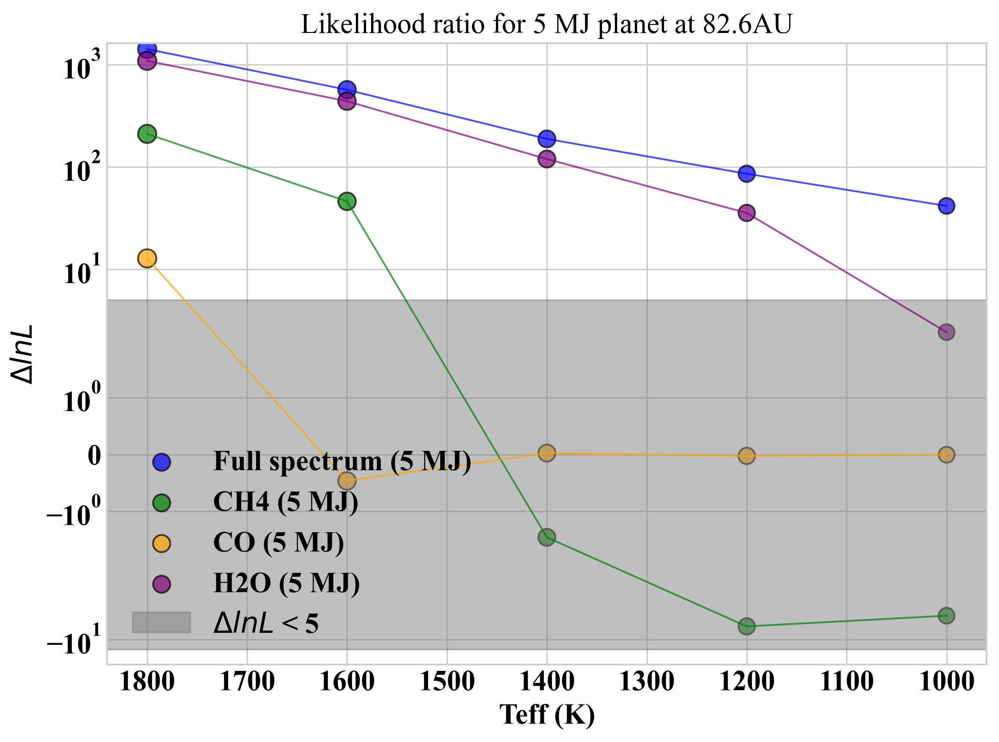

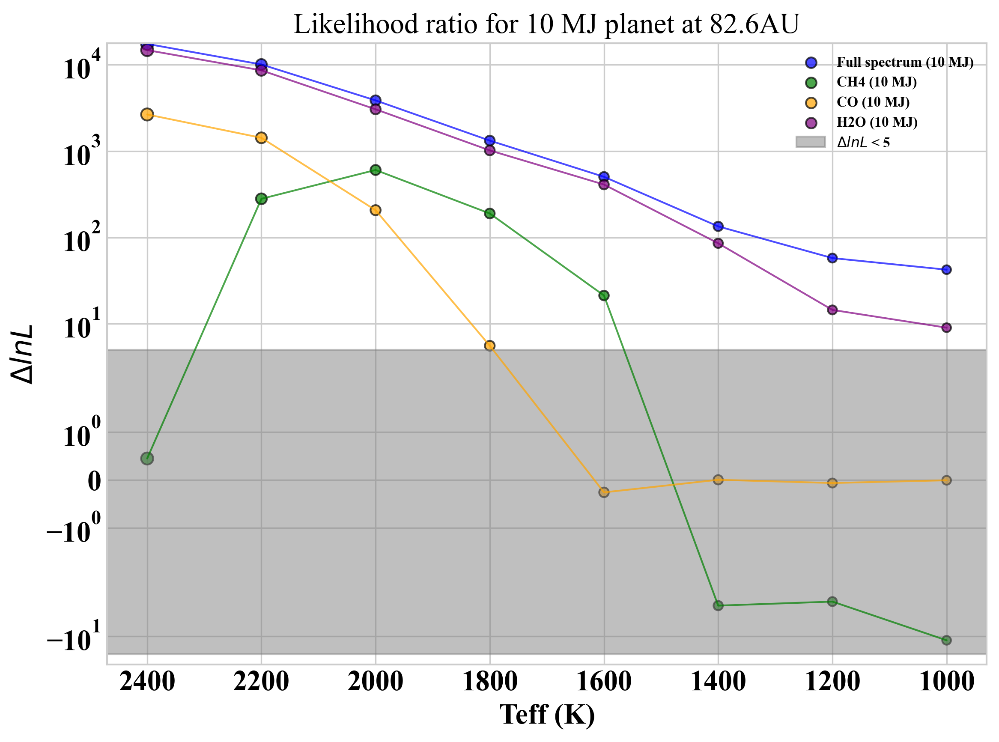

In [182]:
#----------plot the likelihood difference----------

plt.Figure(figsize=(12,8))

plt.plot(Teff_5, likelihood_full_5, color='b', linestyle='-', linewidth=1, alpha=0.7)
scatter=plt.scatter(Teff_5, likelihood_full_5, s=marker_sizes_5, c='b', label='Full spectrum (5 MJ)', alpha=0.7, edgecolors='k', linewidths=1)


for i , mol_likelihood in enumerate(likelihood_mol_5):
    plt.scatter(Teff_5, mol_likelihood, s=marker_sizes_5, c=colors[i], label=f'{labels[i]} (5 MJ)', alpha=0.7, edgecolors='k', linewidths=1)
    plt.plot(Teff_5, mol_likelihood, color=colors[i], linestyle='-', linewidth=1, alpha=0.7)


plt.axhspan(np.nanmin(likelihood_mol_5)-5, 5, color='gray', linestyle='-', linewidth=1, alpha=0.5, label=r'$\Delta ln L$ < 5')
plt.ylim(np.nanmin(likelihood_mol_5)-10, np.nanmax(likelihood_full_5)+200)

plt.title(r'Likelihood ratio for 5 MJ planet at 82.6AU')
#plt.ylim(likelihood_mol_5.min()-10, likelihood_full_5.max()+100)

plt.xlabel('Teff (K)')
plt.ylabel(r'$\Delta ln L $')
plt.yscale('symlog')

plt.gca().invert_xaxis()
plt.legend()

plt.show()

plt.Figure(figsize=(15,8))

plt.plot(Teff_10, likelihood_full_10, color='b', linestyle='-', linewidth=1, alpha=0.7)
scatter=plt.scatter(Teff_10, likelihood_full_10, s=marker_sizes_10, c='b', label='Full spectrum (10 MJ)', alpha=0.7, edgecolors='k', linewidths=1)

for i , mol_likelihood in enumerate(likelihood_mol_10):
    plt.scatter(Teff_10, mol_likelihood, s=marker_sizes_10, c=colors[i], label=f'{labels[i]} (10 MJ)', alpha=0.7, edgecolors='k', linewidths=1)
    plt.plot(Teff_10, mol_likelihood, color=colors[i], linestyle='-', linewidth=1, alpha=0.7)

plt.gca().invert_xaxis()
plt.title(r'Likelihood ratio for 10 MJ planet at 82.6AU')
#plt.ylim(likelihood_mol_5.min()-10, likelihood_full_5.max()+100)

plt.xlabel('Teff (K)')
plt.ylabel(r'$ \Delta ln L $')
plt.yscale('symlog')

plt.axhspan(np.nanmin(likelihood_mol_10)-5, 5, color='gray', linestyle='-', linewidth=1, alpha=0.5, label=r'$\Delta ln L$ < 5')
plt.ylim(np.nanmin(likelihood_mol_10)-10, np.nanmax(likelihood_full_10)+300)

plt.legend(fontsize=8)

plt.show()

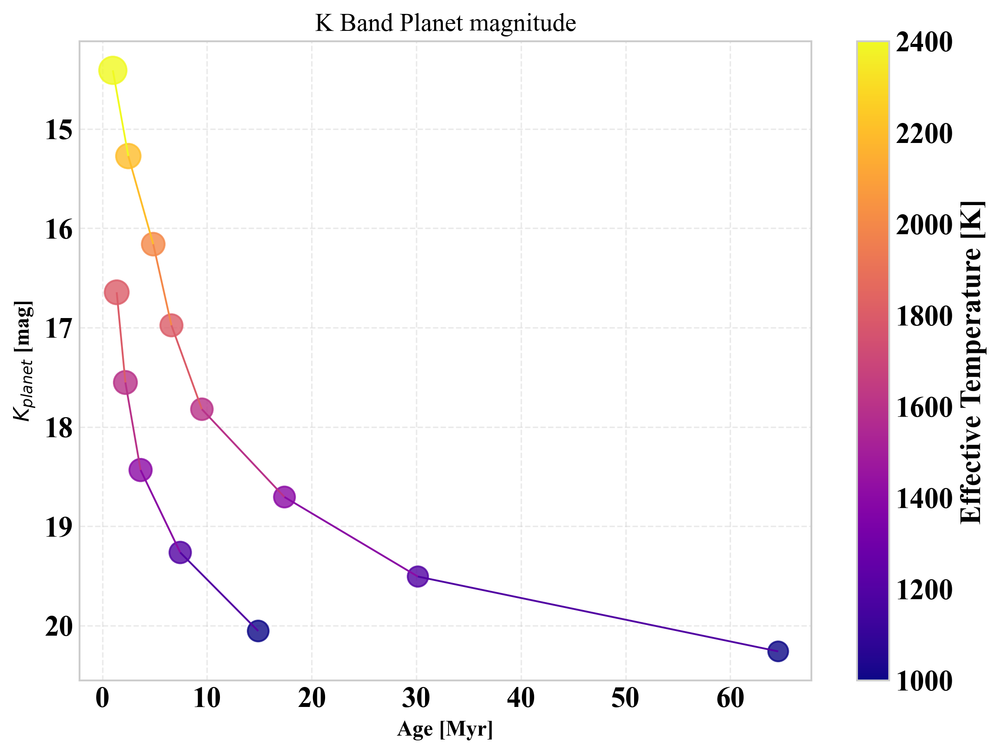

In [183]:

import matplotlib.colors as mcolors
import matplotlib.cm as cm
from matplotlib.collections import LineCollection

from exocrires import analysis

#calculate the brightness for 2M planet

brightness_calculator = analysis.planet_para()

# Combine Teff arrays for normalization
all_Teff = np.concatenate([Teff_5, Teff_10])
norm = mcolors.Normalize(vmin=np.min(all_Teff), vmax=np.max(all_Teff))
cmap = cm.plasma

def colored_line(x, y, c, cmap, norm, lw=2, sizes=None):
    """
    Draw a line colored according to values c
    """
    points = np.array([x, y]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    lc = LineCollection(segments, cmap=cmap, norm=norm, linewidth=lw)
    lc.set_array(np.array(c[:-1]))  # color line segments by Teff
    plt.gca().add_collection(lc)
    
    # Scatter points
    if sizes is None:
        sizes = np.ones_like(c) * 20
    plt.scatter(x, y, s=sizes, c=c, cmap=cmap, norm=norm, marker='o', alpha=0.8)
    return lc

plt.figure(figsize=(8,6))

scale=100
# 5 MJ planets
lc5 = colored_line(Age_5, Mag_planet_5, Teff_5, cmap, norm, lw=1, sizes=R_planet_5*scale)

# 10 MJ planets
lc10 = colored_line(Age_10, Mag_planet_10, Teff_10, cmap, norm, lw=1, sizes=R_planet_10*scale)

# Colorbar
cbar = plt.colorbar(lc10)
cbar.set_label("Effective Temperature [K]")

plt.xlabel("Age [Myr]", fontsize=12)
plt.ylabel(r"$K_{planet}$ [mag]", fontsize=12)
plt.title("K Band Planet magnitude", fontsize=14)
plt.gca().invert_yaxis()
plt.grid(True, which="both", ls="--", alpha=0.4)
plt.tight_layout()
plt.show()



/var/folders/w_/fqznltwj2pz2y345p5_rzn3r0000gn/T/ipykernel_1990/820195043.py:9: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data_BHAC15=pd.read_csv(path+'BHAC15_tracks+structure.txt', delim_whitespace=True, comment='#', header=0)


Star parameters for 1.0 Msun:
log_t: [6.         6.60205999 6.84509804 7.         7.11394335 7.20411998
 7.2787536  7.34242268 7.39794001 7.44715803 7.49136169 7.53147892
 7.56820172 7.60205999 7.63346846 7.66275783 7.69019608 7.71600334
 7.74036269 7.76342799 7.78532984 7.80617997 7.8260748  7.84509804
 7.86332286 7.88081359 7.89762709 7.91381385 7.92941893 7.94448267]
R_s (Rsun): [2.42 1.54 1.31 1.19 1.12 1.08 1.06 1.05 1.06 1.06 1.04 0.99 0.92 0.9
 0.89 0.89 0.89 0.9  0.9  0.9  0.9  0.9  0.9  0.9  0.9  0.9  0.9  0.9
 0.9  0.9 ]
Z_s: 0.0
T_s (K): [4377. 4316. 4315. 4363. 4447. 4566. 4740. 4914. 5147. 5386. 5573. 5646.
 5609. 5570. 5550. 5543. 5539. 5536. 5534. 5532. 5532. 5532. 5532. 5532.
 5532. 5532. 5532. 5533. 5533. 5533.]
G_s (log g): [3.67 4.07 4.2  4.29 4.34 4.37 4.39 4.39 4.39 4.39 4.4  4.45 4.51 4.53
 4.54 4.54 4.54 4.53 4.53 4.53 4.53 4.53 4.53 4.53 4.53 4.53 4.53 4.53
 4.53 4.53]
The star spectrum already exists, skipping download


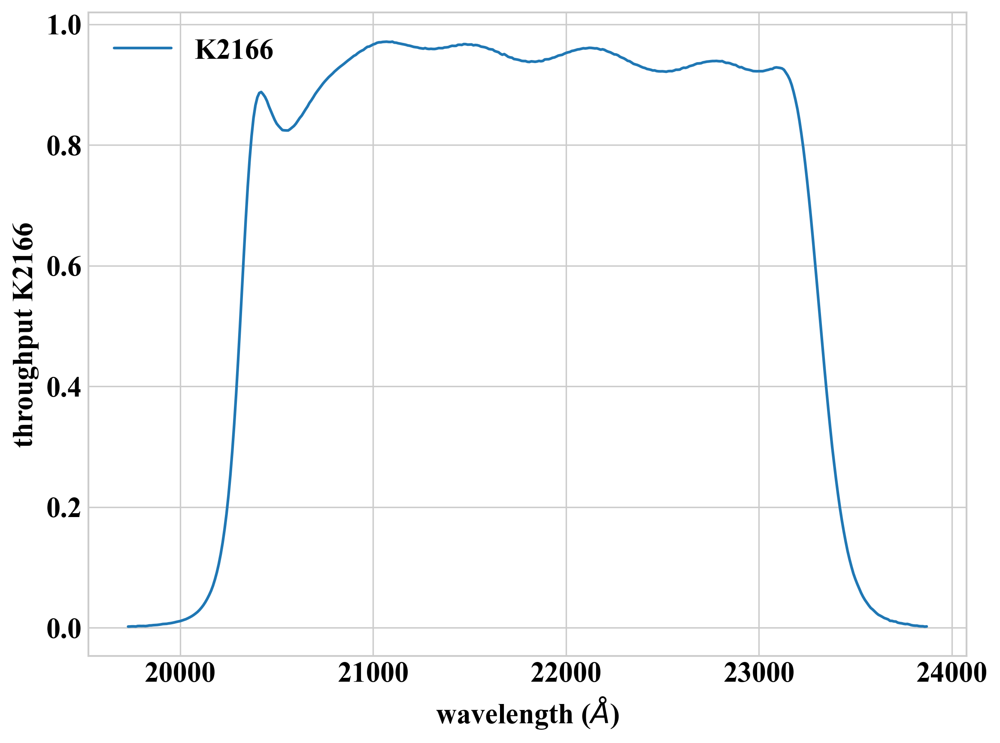

T, Z, G 4300 -0.0 3.5
limb darkening coefficient at K2166 band [0.467]


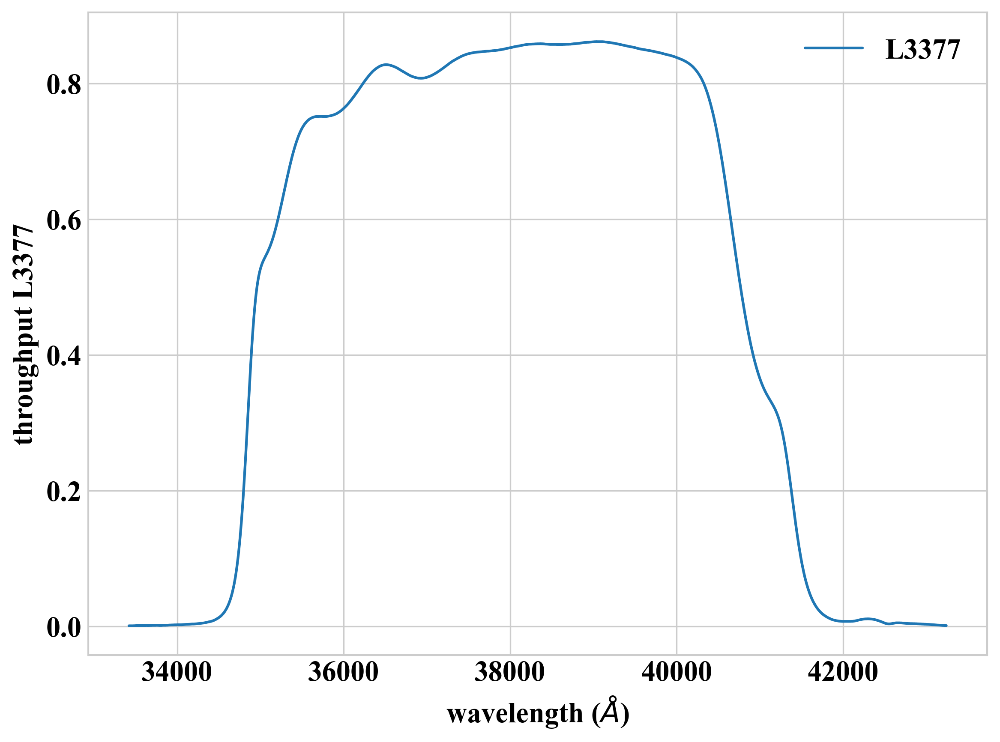

T, Z, G 4300 -0.0 3.5
limb darkening coefficient at L3377 band [0.3098]


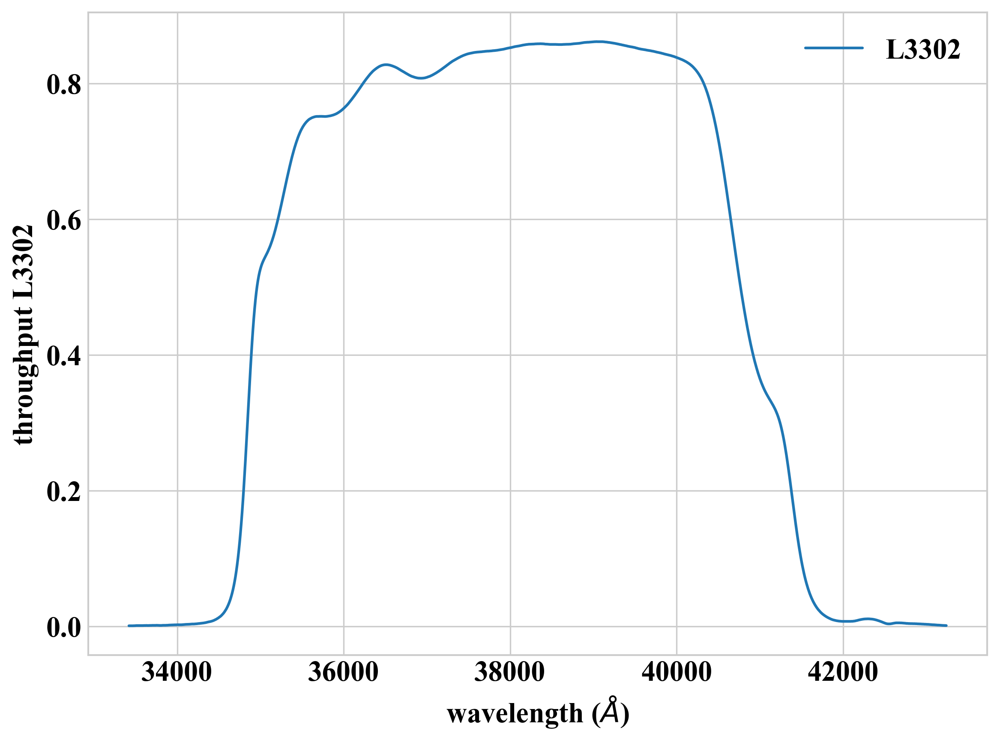

T, Z, G 4300 -0.0 3.5
limb darkening coefficient at L3302 band [0.3096]


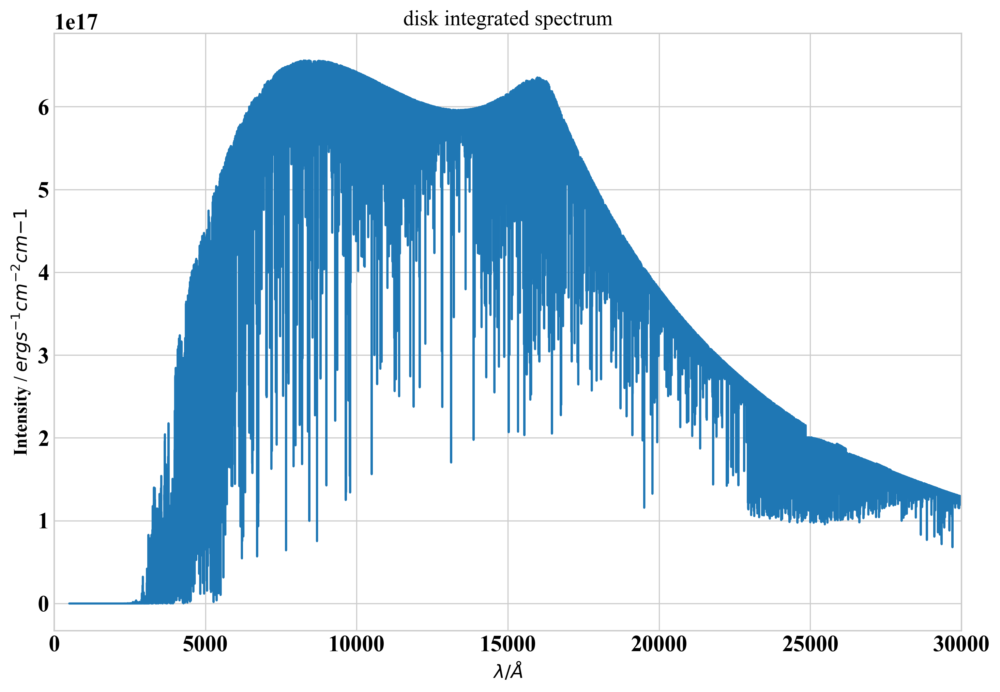

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


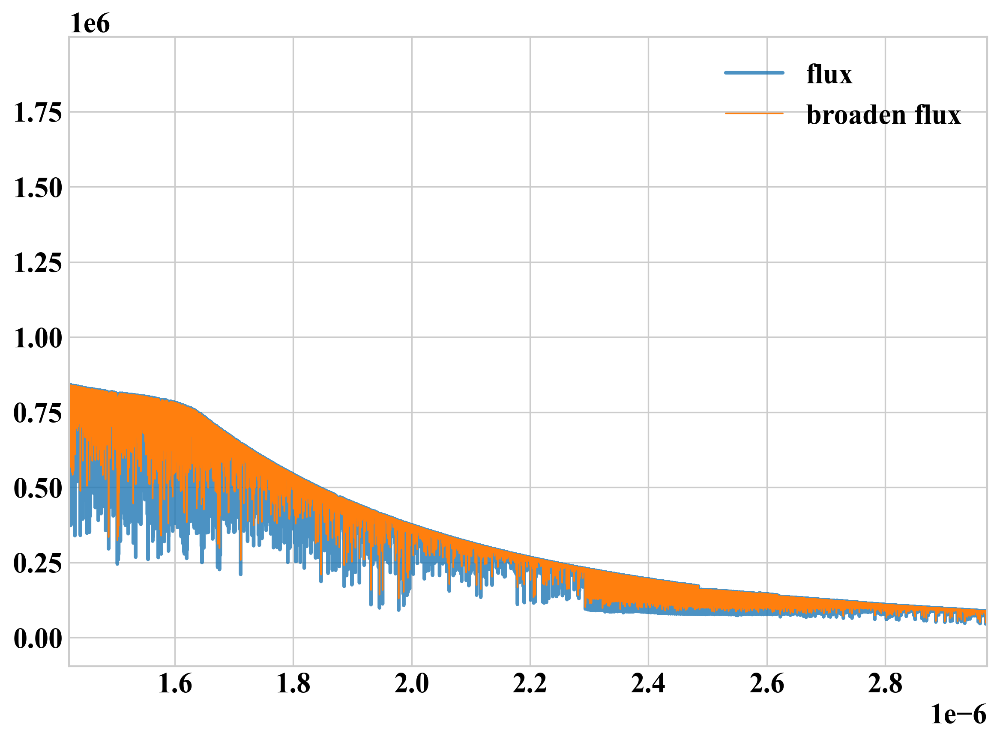

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 7.490599027947899 271021.25443366496 0.0010086962094780258
The star spectrum already exists, skipping download


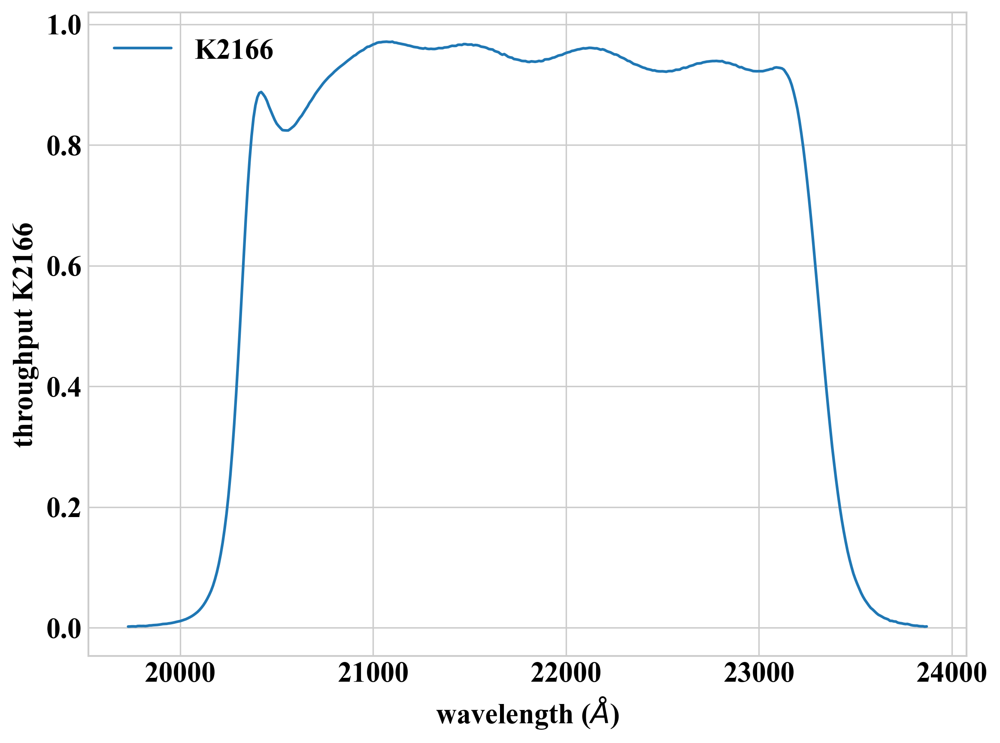

T, Z, G 4300 -0.0 4.0
limb darkening coefficient at K2166 band [0.3257]


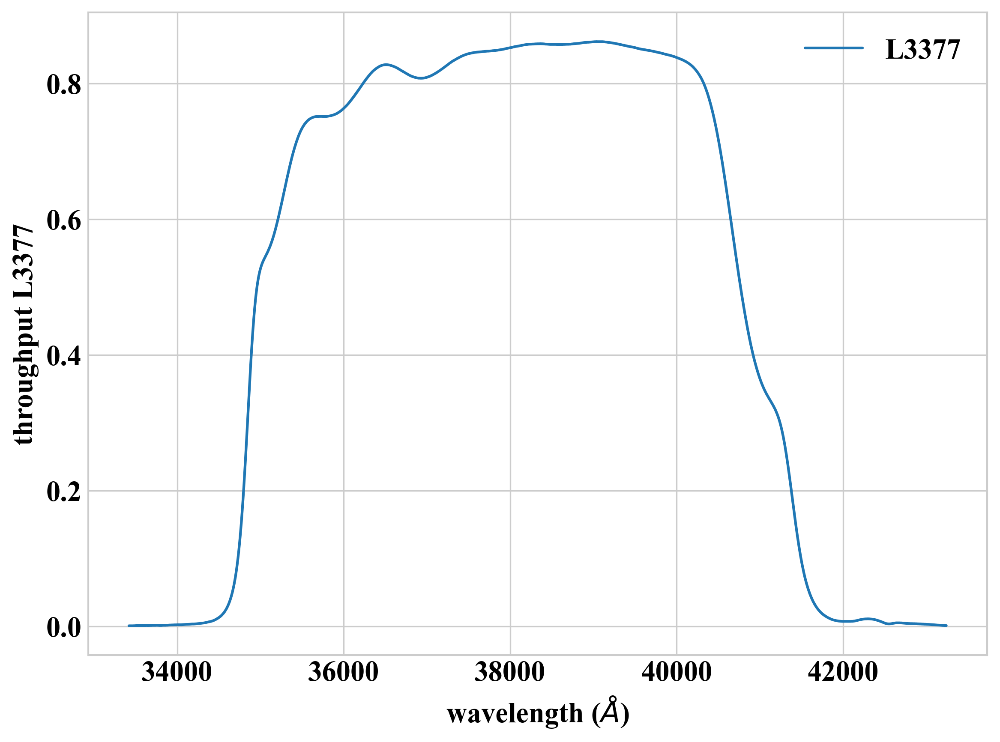

T, Z, G 4300 -0.0 4.0
limb darkening coefficient at L3377 band [0.2281]


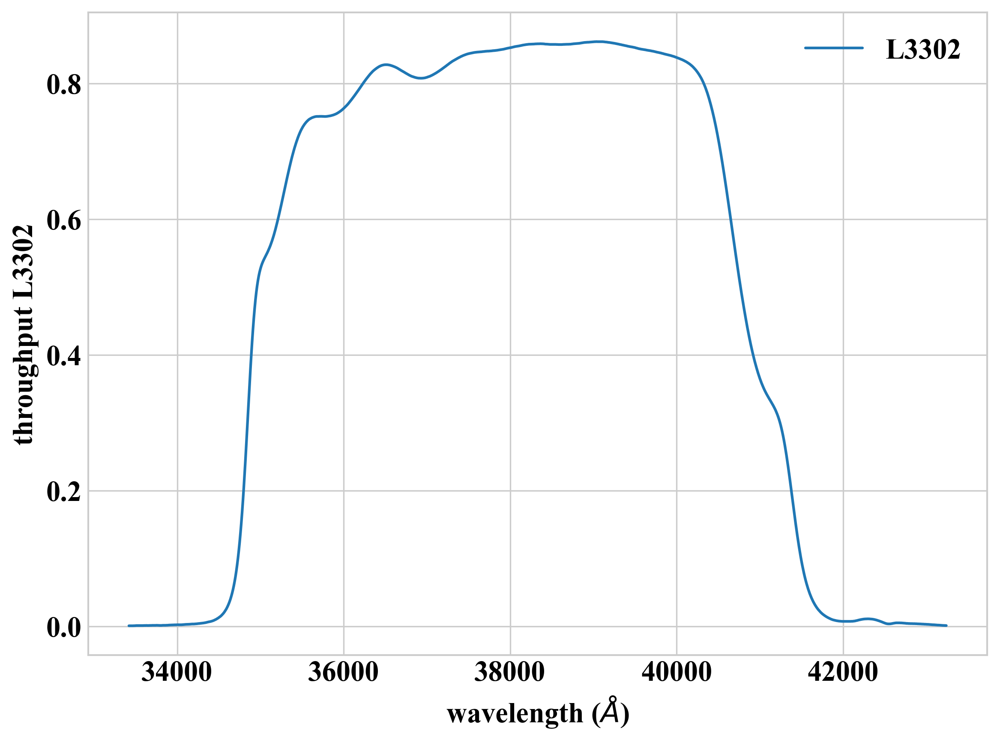

T, Z, G 4300 -0.0 4.0
limb darkening coefficient at L3302 band [0.2281]


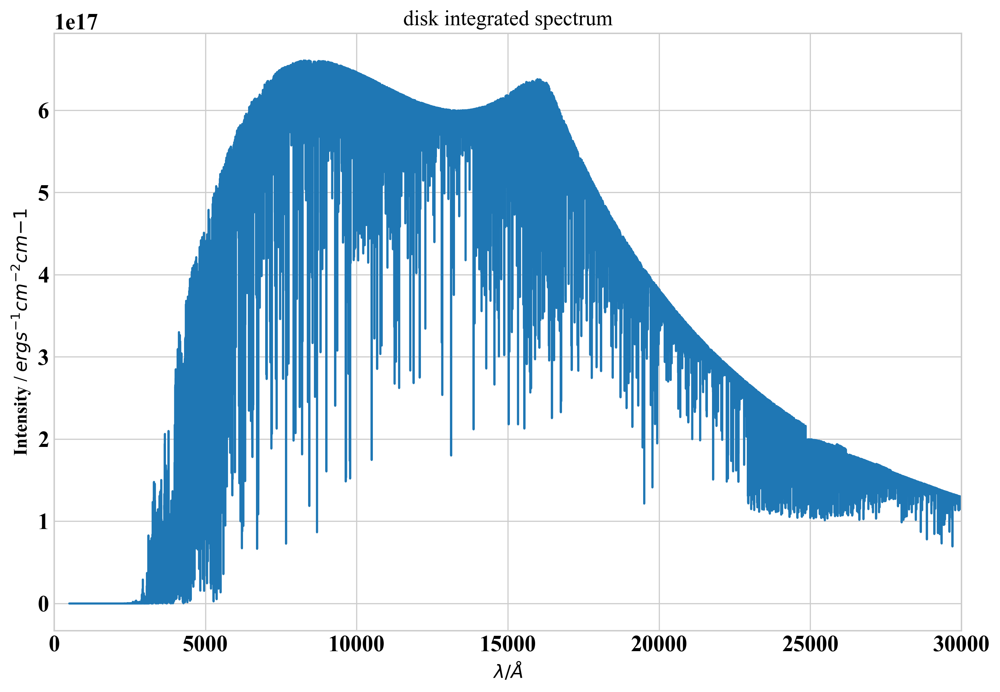

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


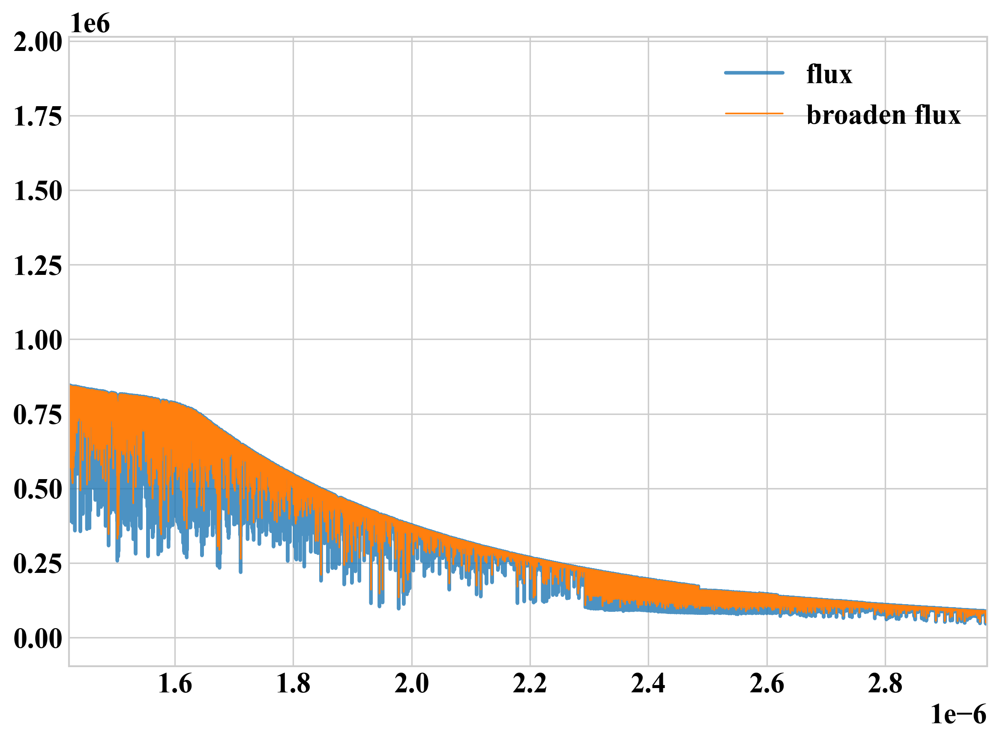

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 8.463768838354234 273101.8972590118 0.00041161620538457
The star spectrum already exists, skipping download


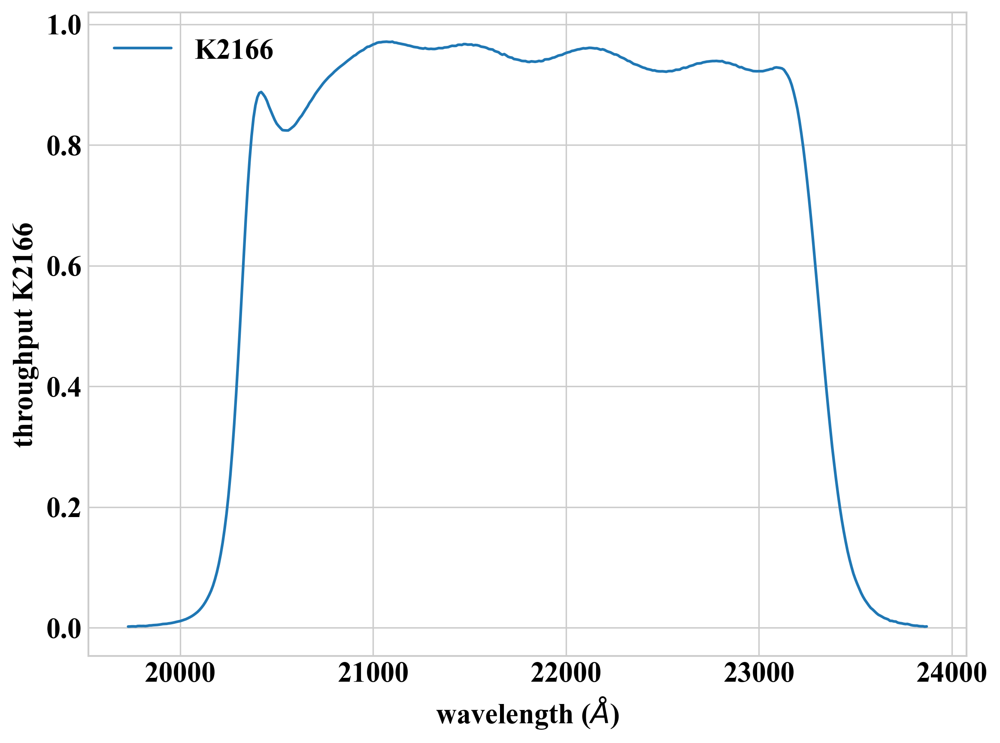

T, Z, G 4300 -0.0 4.0
limb darkening coefficient at K2166 band [0.3257]


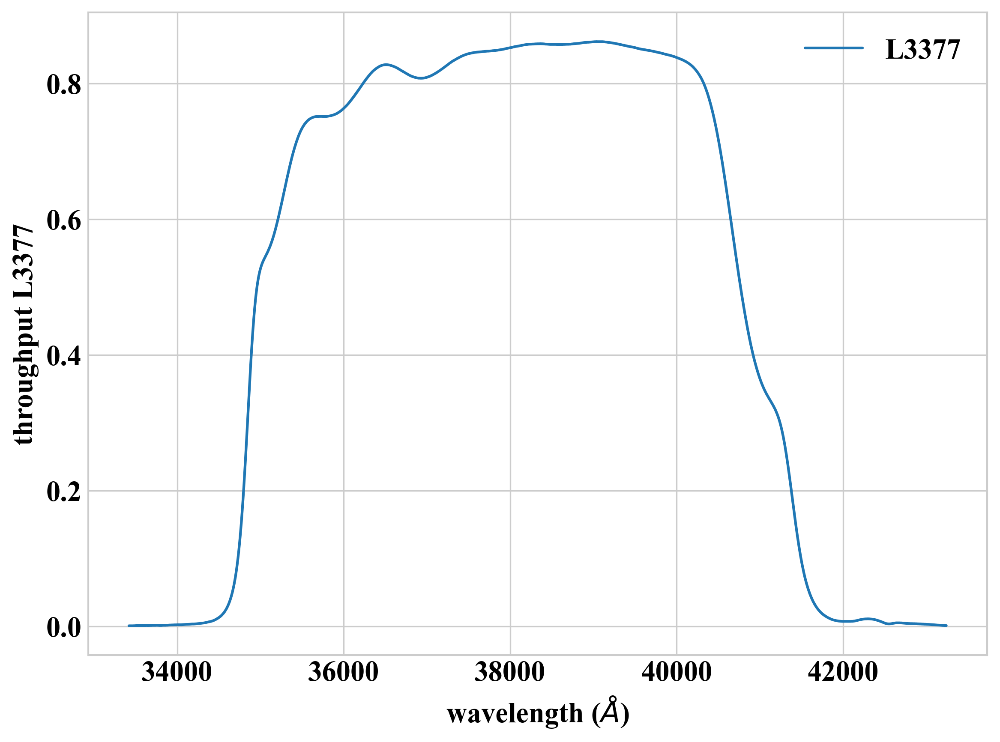

T, Z, G 4300 -0.0 4.0
limb darkening coefficient at L3377 band [0.2281]


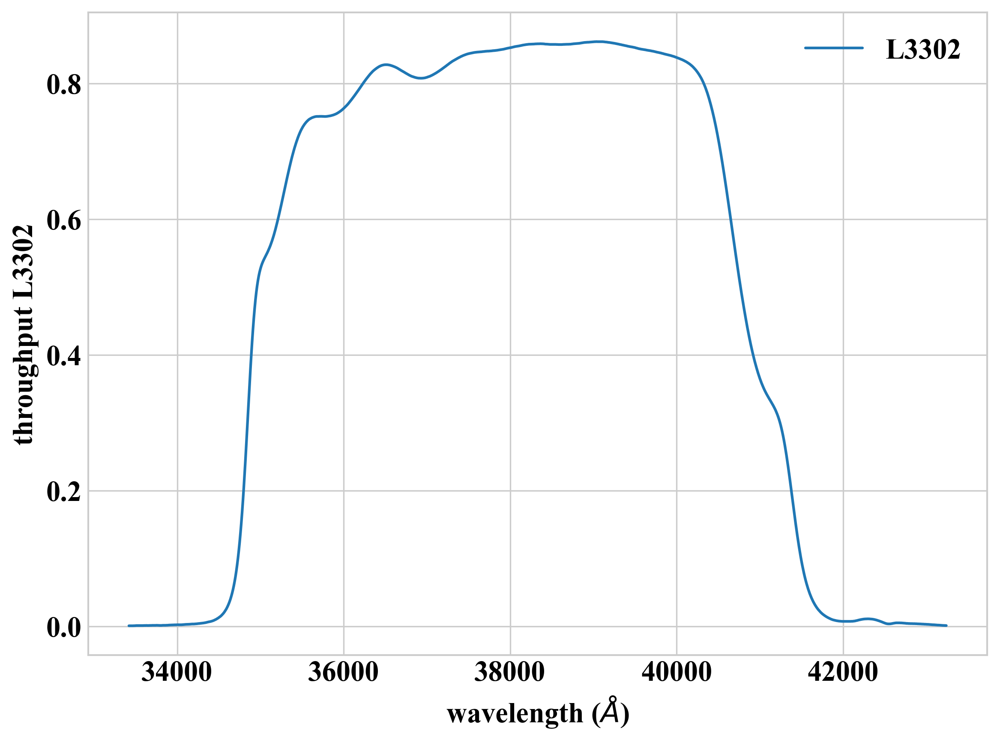

T, Z, G 4300 -0.0 4.0
limb darkening coefficient at L3302 band [0.2281]


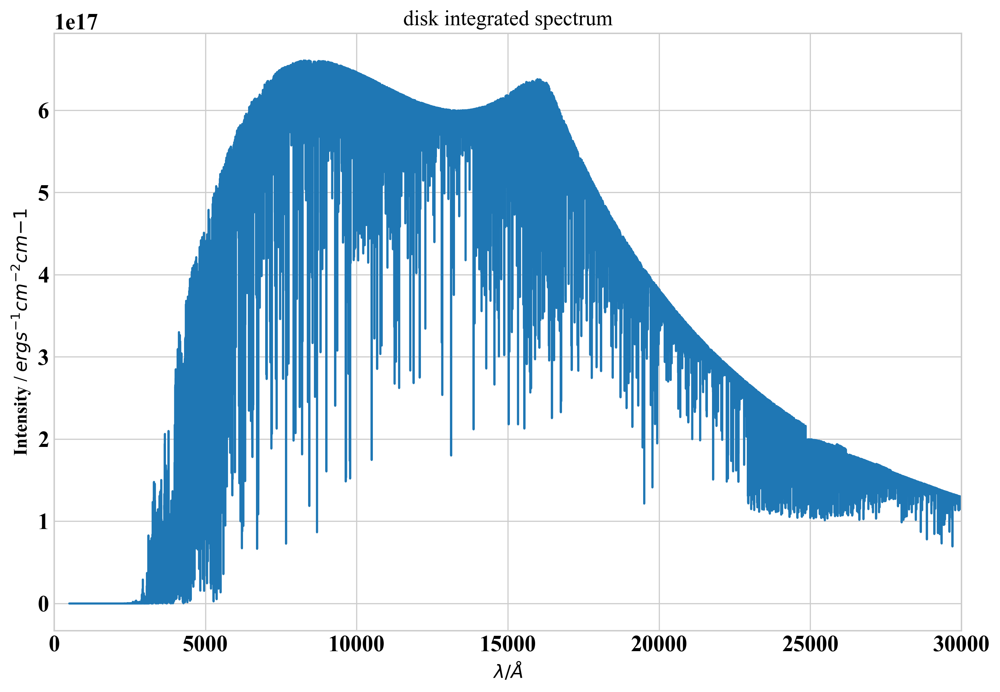

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


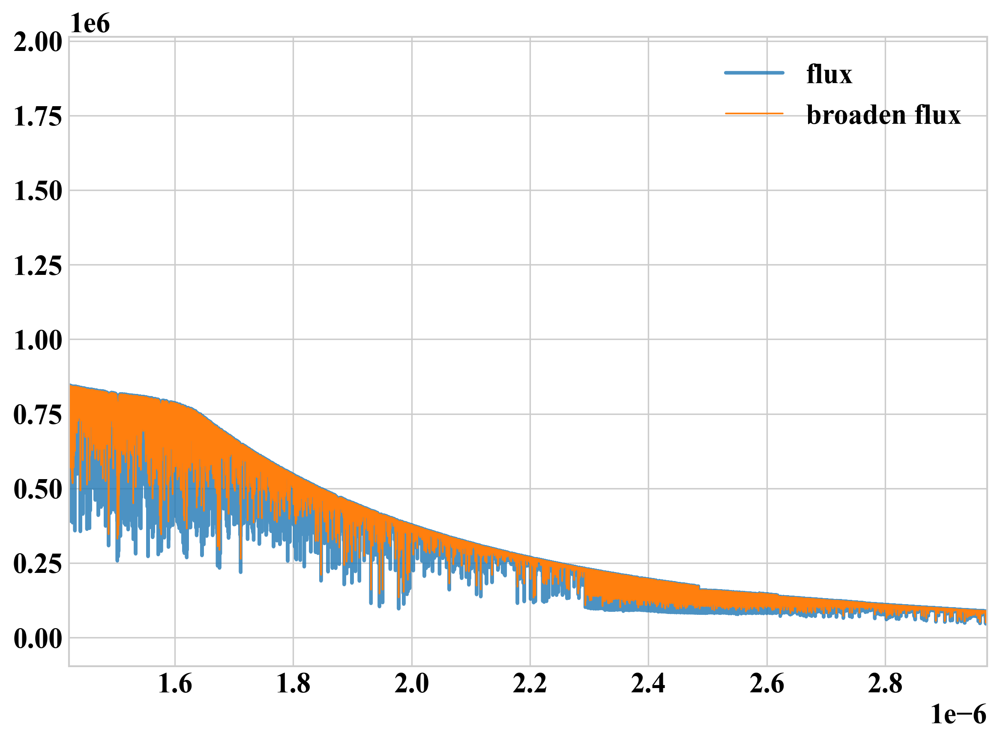

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 8.815015964257727 273101.8972590118 0.00029784726347632844
The star spectrum already exists, skipping download


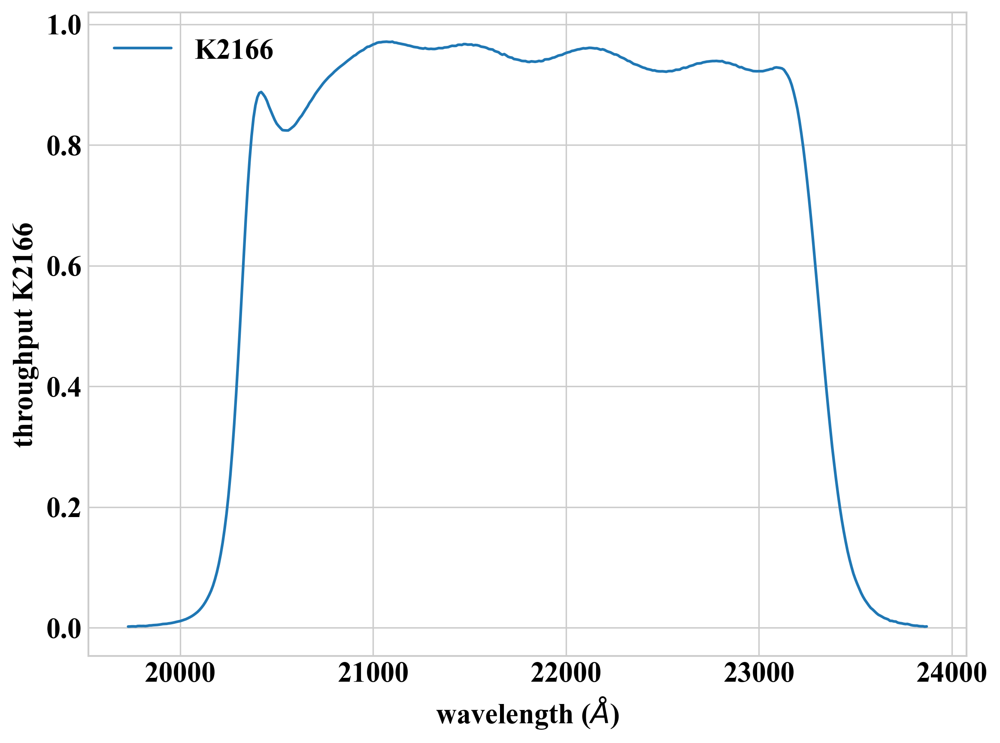

T, Z, G 4300 -0.0 4.0
limb darkening coefficient at K2166 band [0.3257]


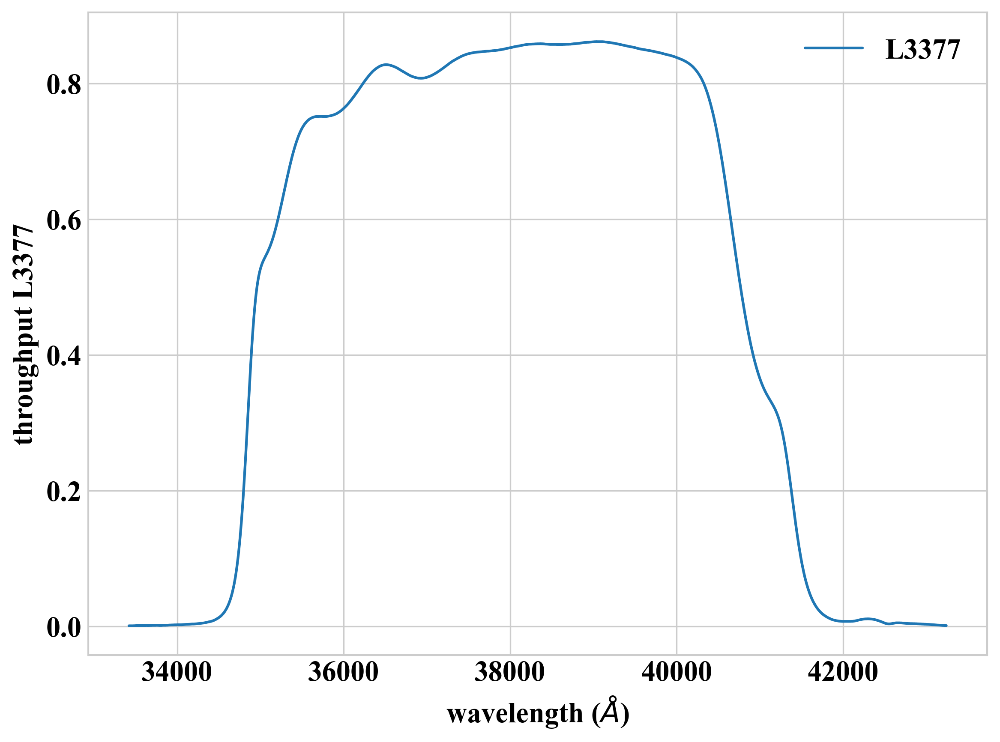

T, Z, G 4300 -0.0 4.0
limb darkening coefficient at L3377 band [0.2281]


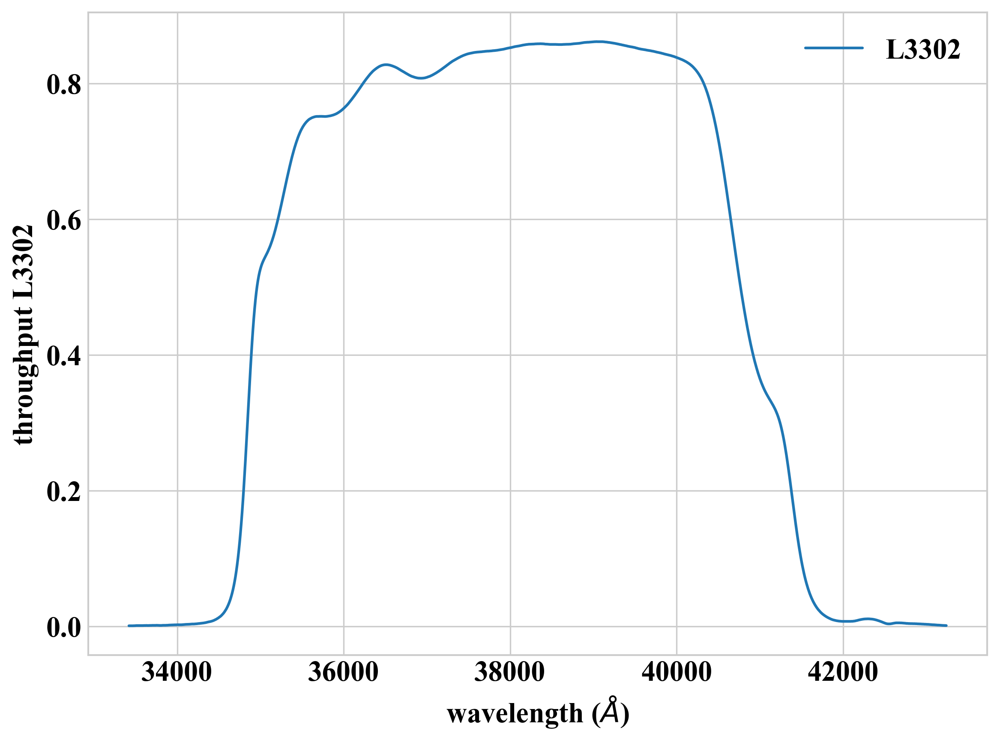

T, Z, G 4300 -0.0 4.0
limb darkening coefficient at L3302 band [0.2281]


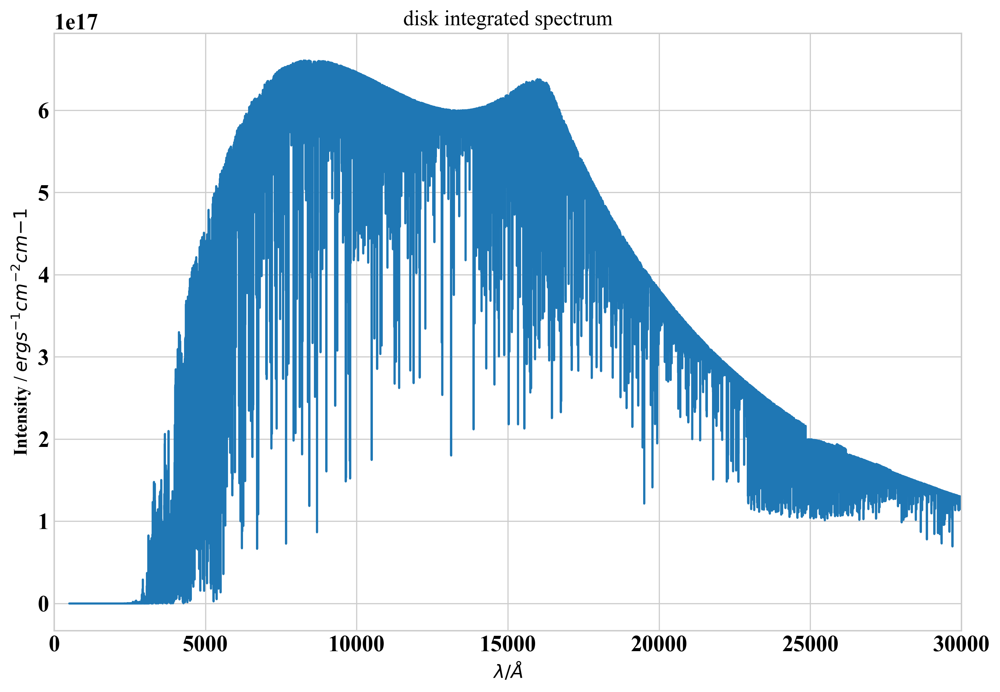

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


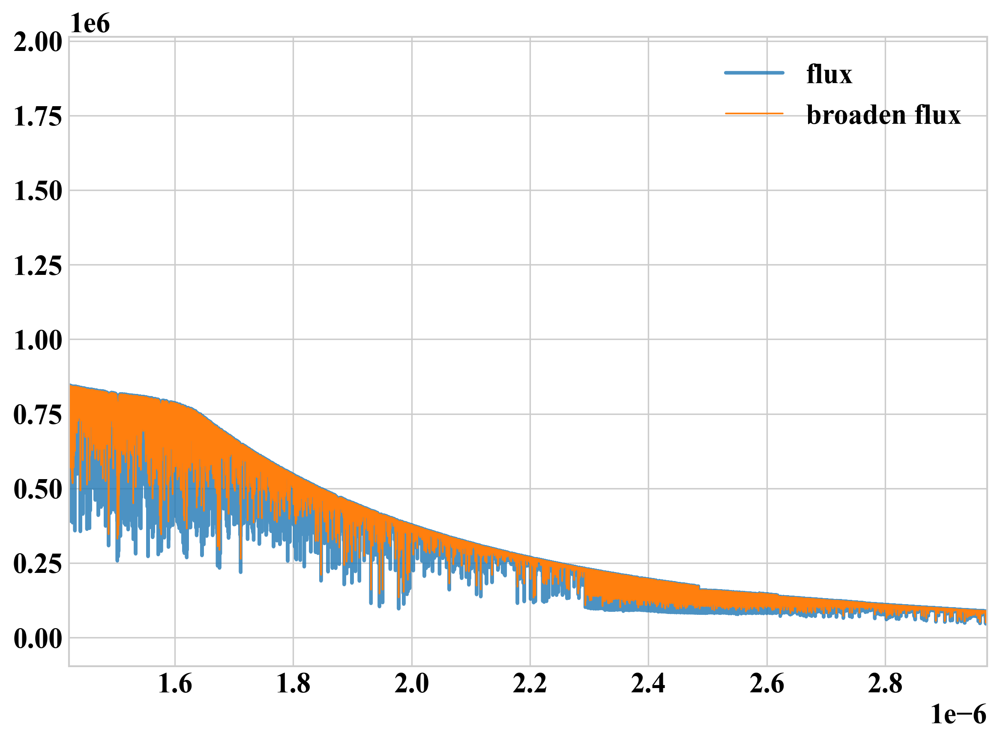

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 9.023637635573895 273101.8972590118 0.00024577909784326594
The star spectrum already exists, skipping download


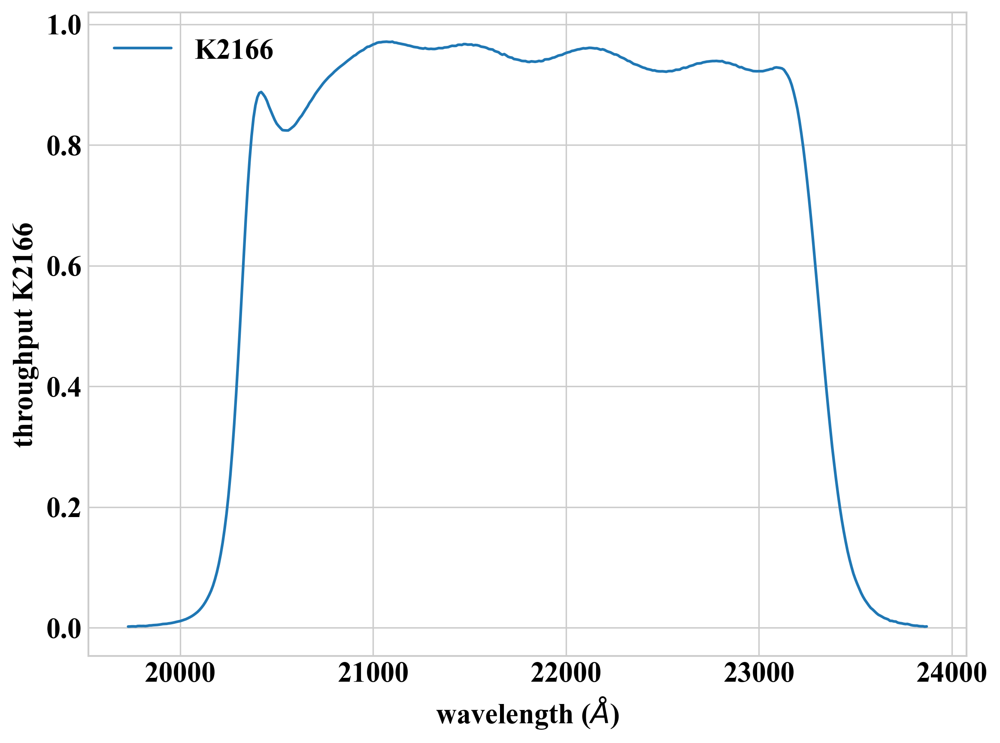

T, Z, G 4400 -0.0 4.0
limb darkening coefficient at K2166 band [0.321]


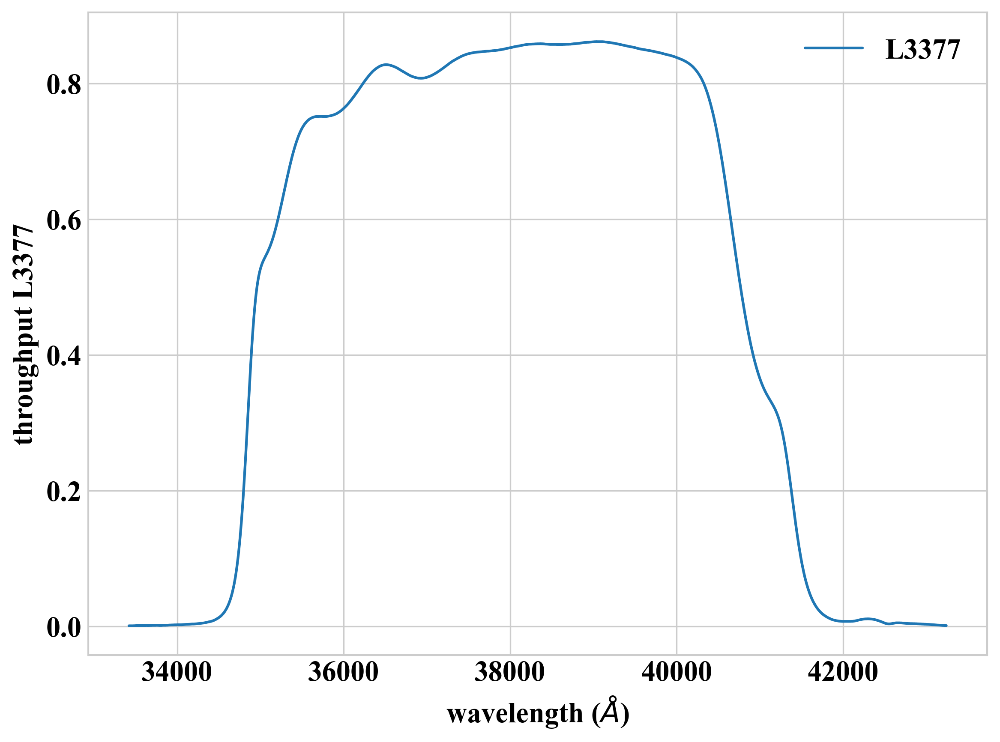

T, Z, G 4400 -0.0 4.0
limb darkening coefficient at L3377 band [0.2233]


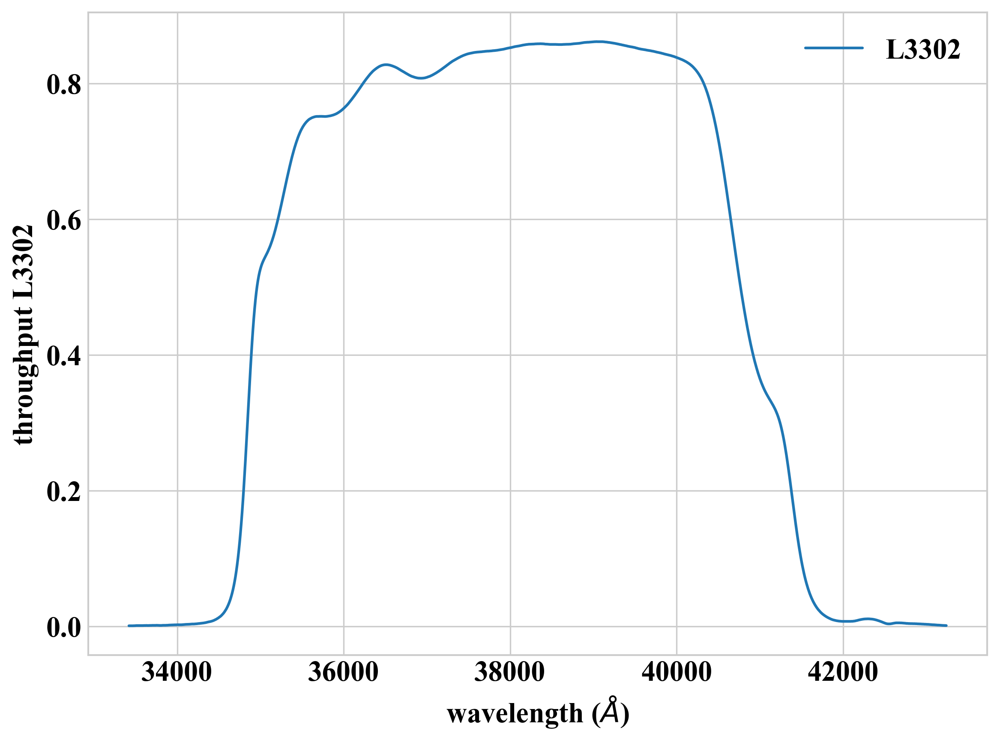

T, Z, G 4400 -0.0 4.0
limb darkening coefficient at L3302 band [0.2238]


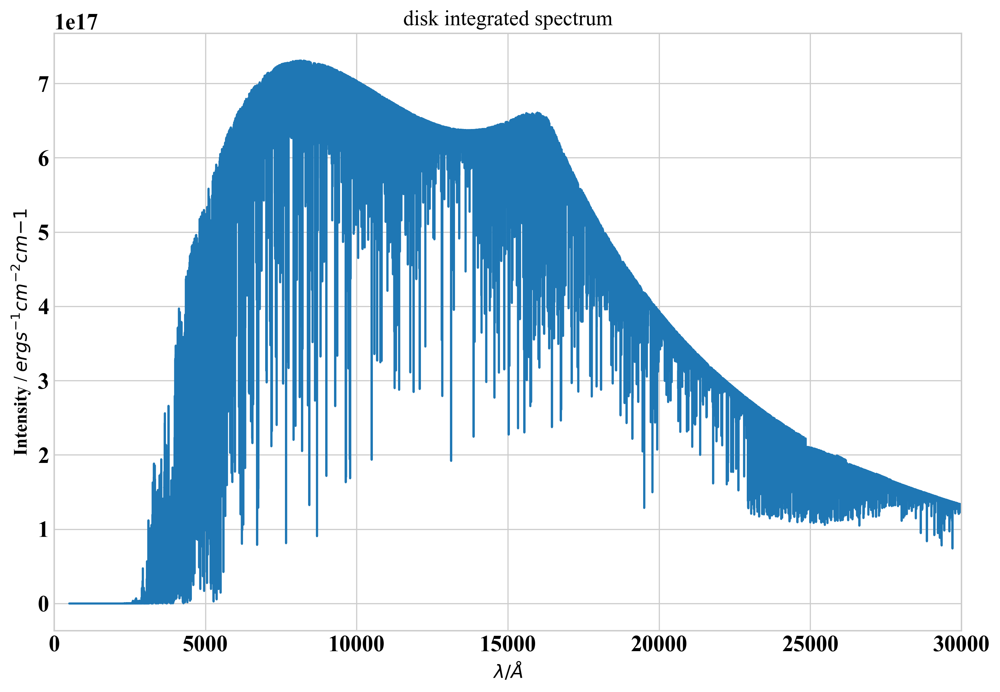

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


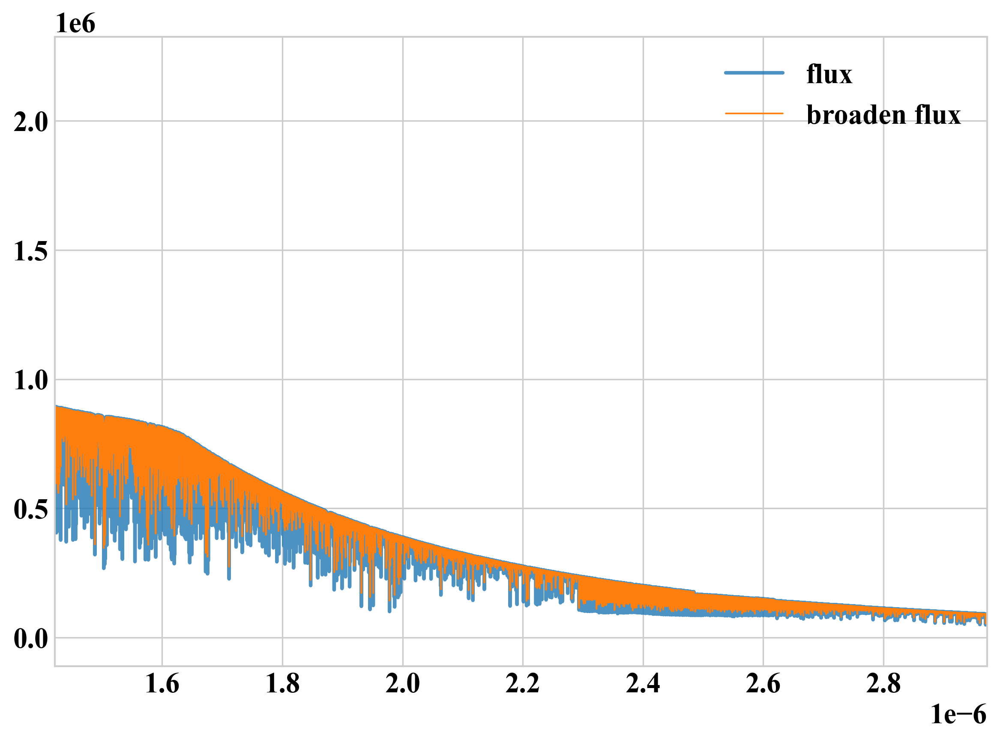

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 9.123165794765697 281301.0355907788 0.00022425063531216095
The star spectrum already exists, skipping download


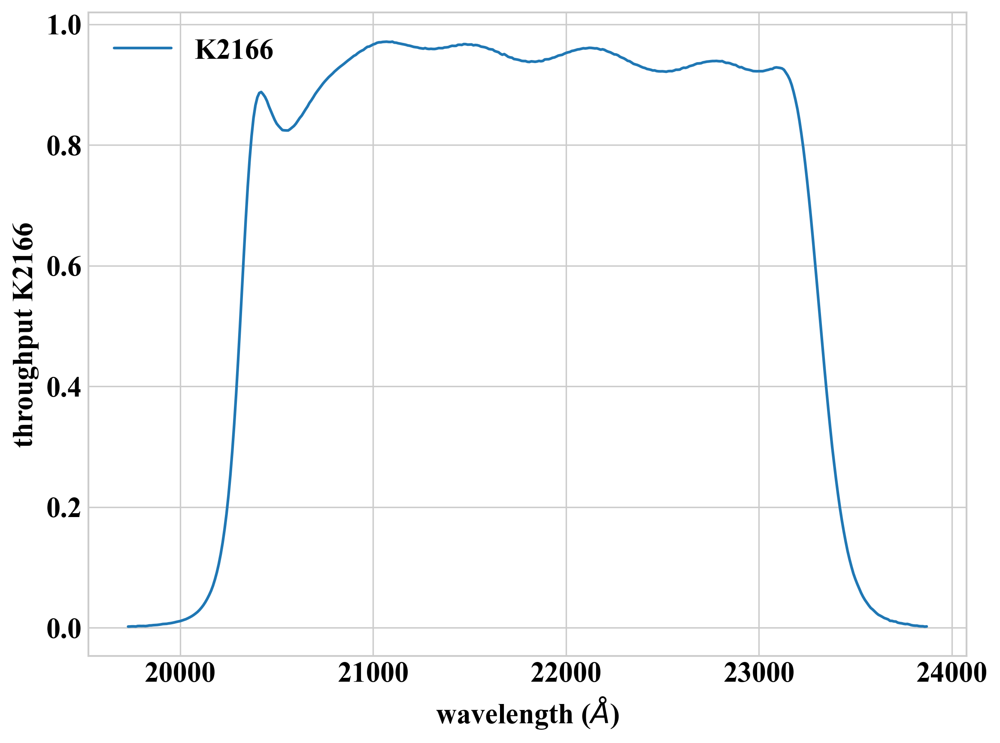

T, Z, G 4700 -0.0 4.0
limb darkening coefficient at K2166 band [0.3054]


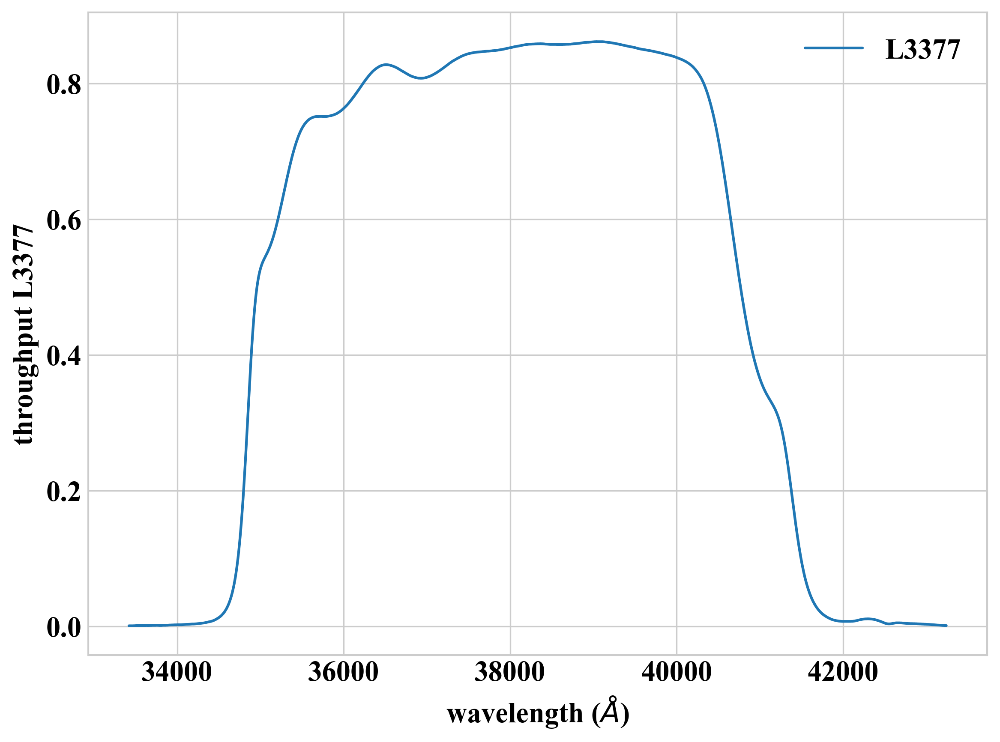

T, Z, G 4700 -0.0 4.0
limb darkening coefficient at L3377 band [0.2096]


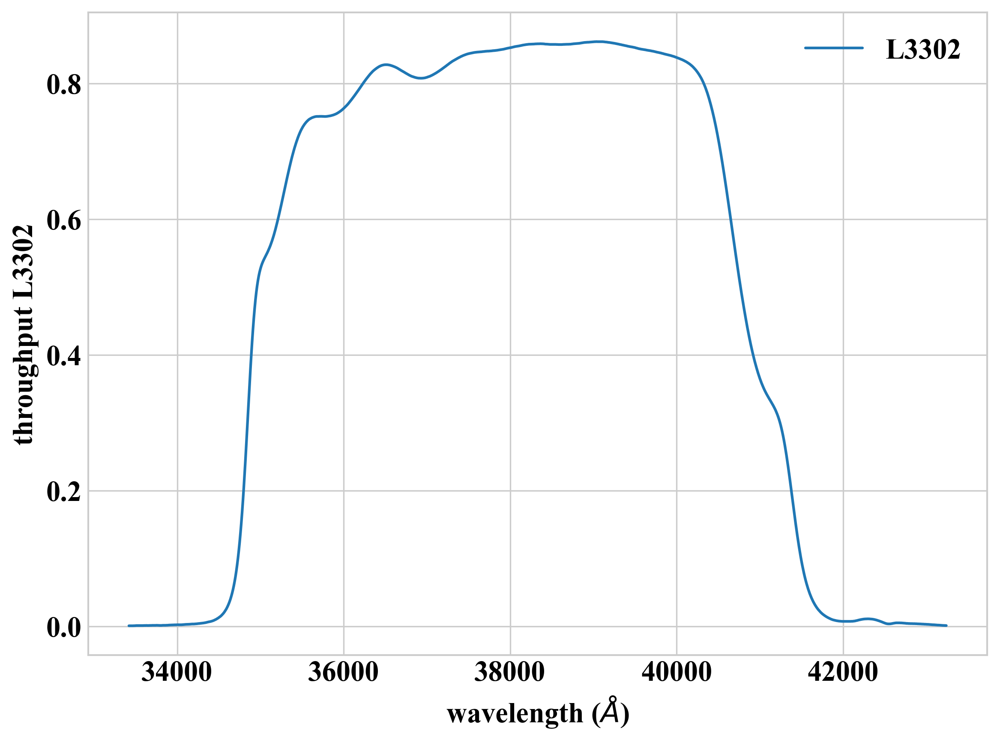

T, Z, G 4700 -0.0 4.0
limb darkening coefficient at L3302 band [0.2108]


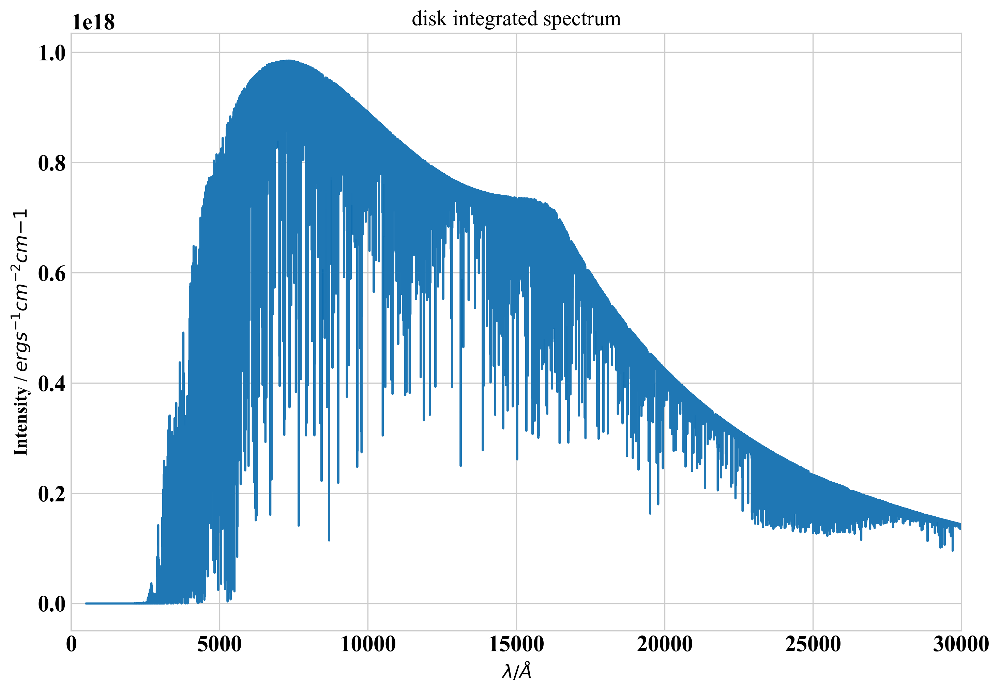

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


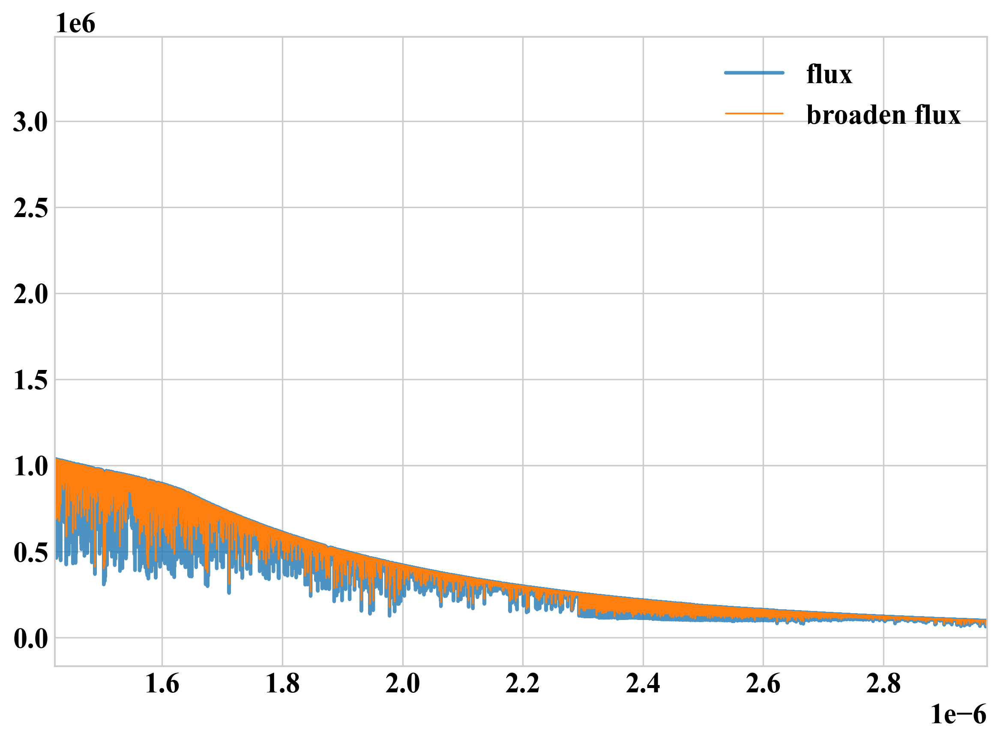

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 9.156639833582943 304513.1349023706 0.00021744231672073678
The star spectrum already exists, skipping download


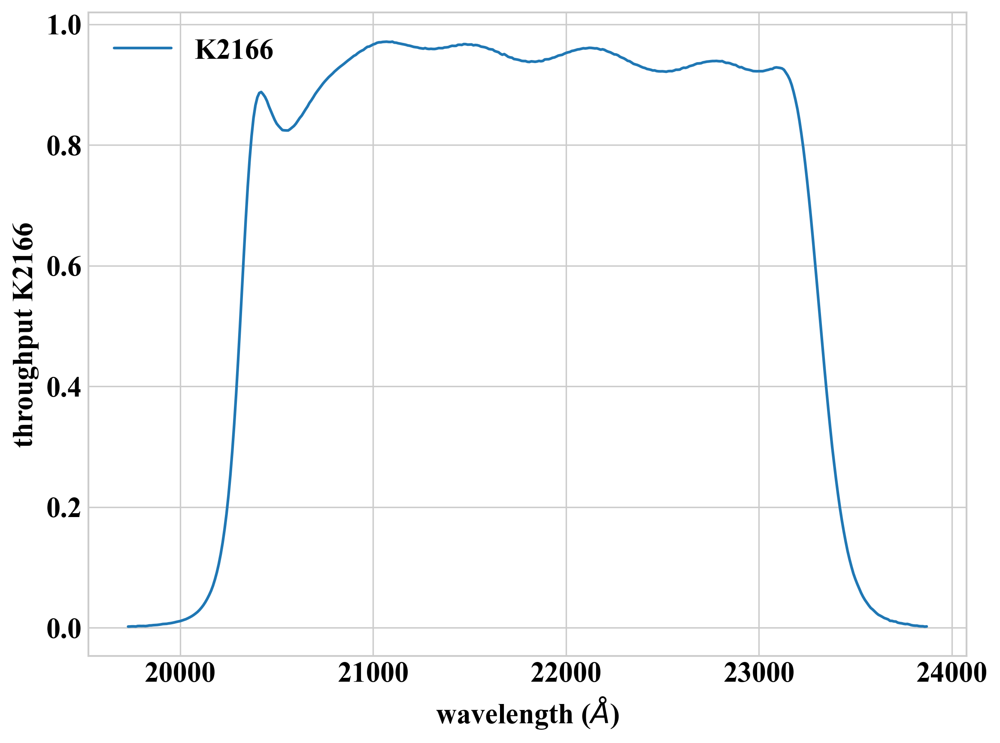

T, Z, G 4900 -0.0 4.0
limb darkening coefficient at K2166 band [0.296]


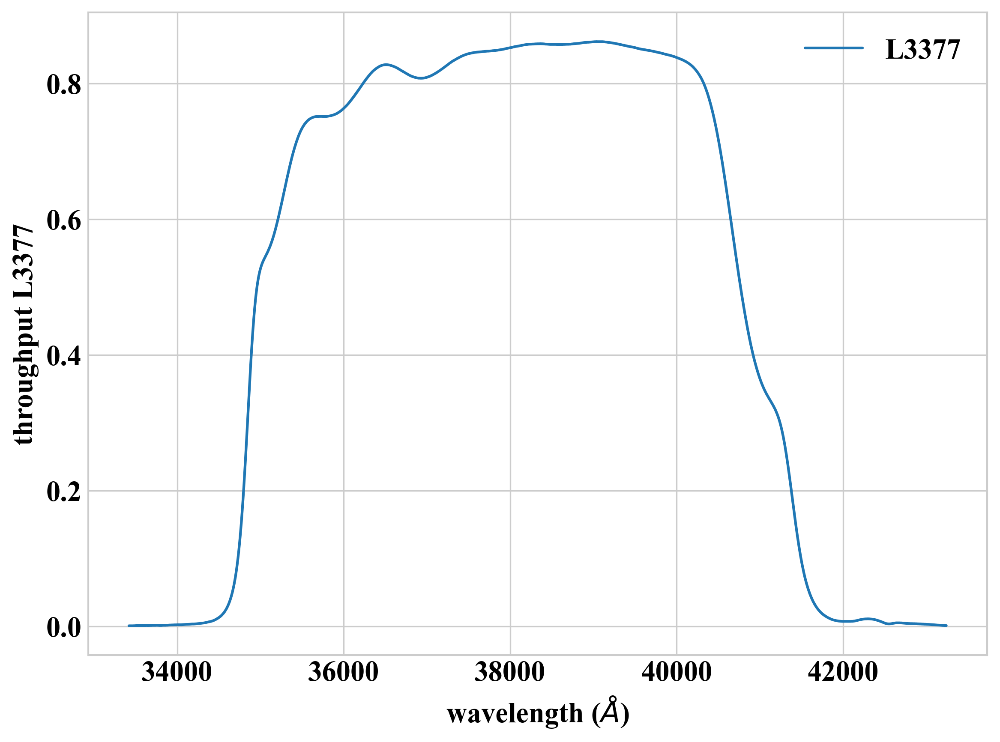

T, Z, G 4900 -0.0 4.0
limb darkening coefficient at L3377 band [0.2009]


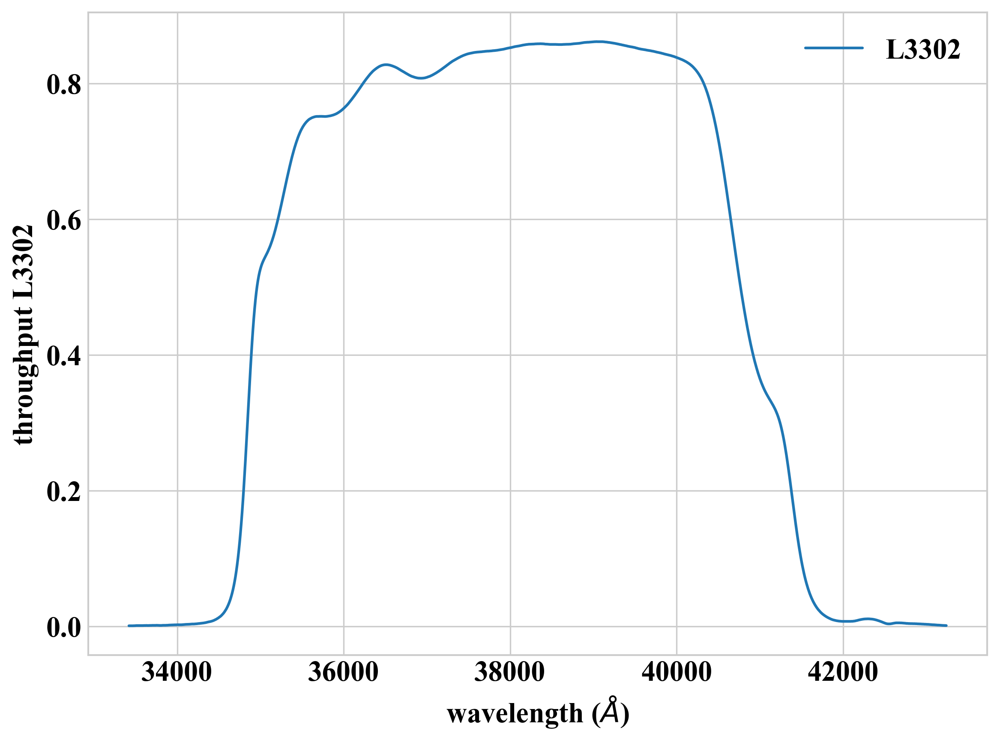

T, Z, G 4900 -0.0 4.0
limb darkening coefficient at L3302 band [0.2021]


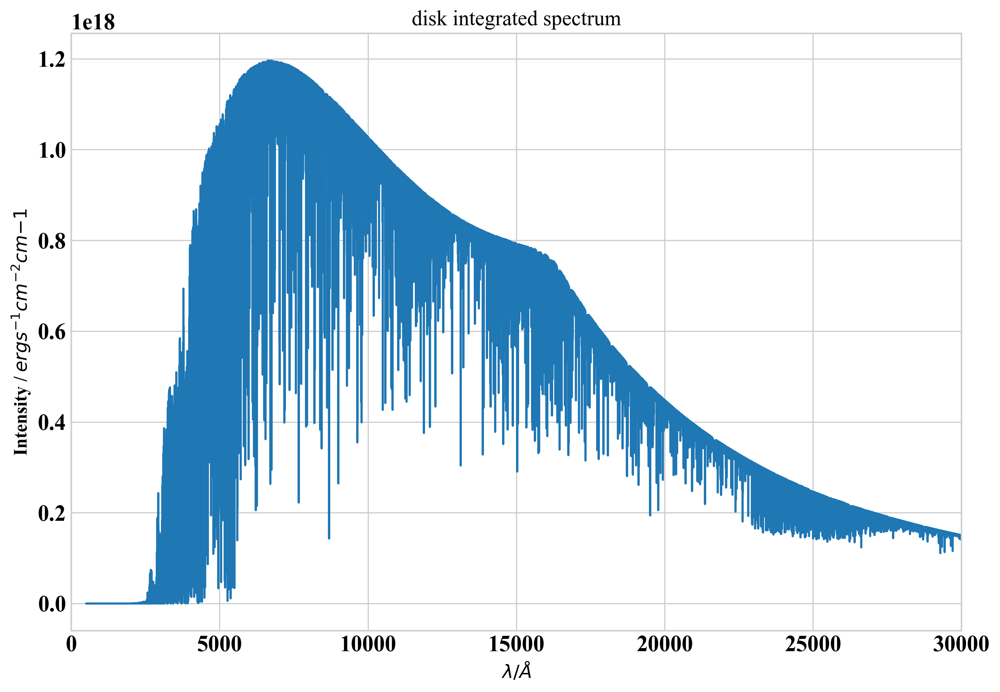

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


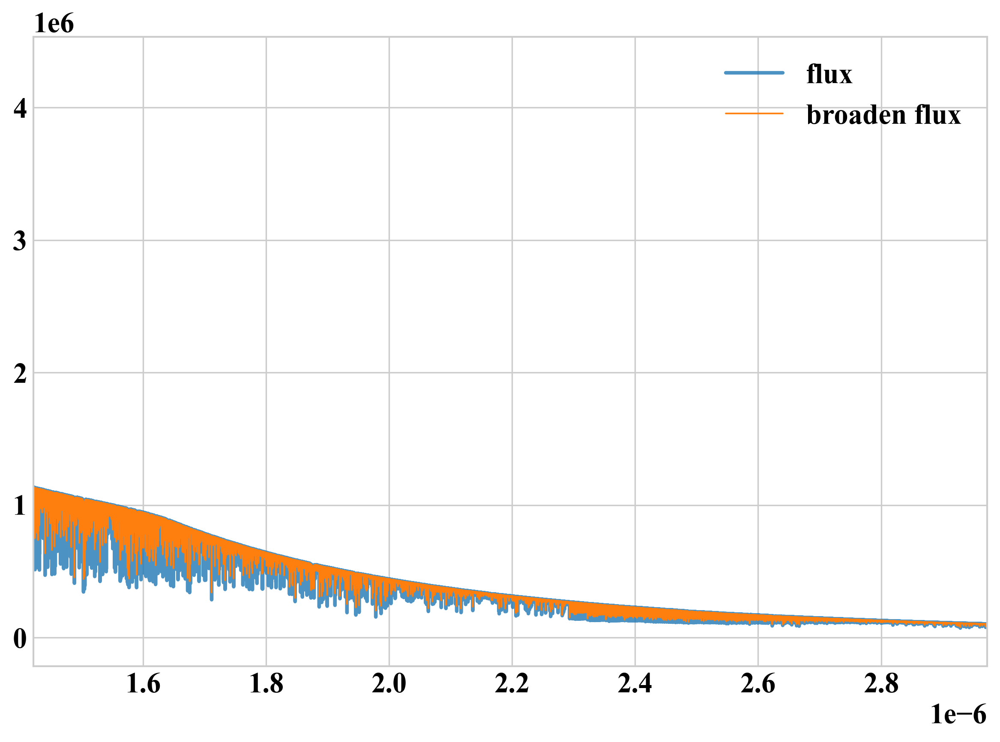

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 9.123459294726104 319971.55965207523 0.00022419002329877836
The star spectrum already exists, skipping download


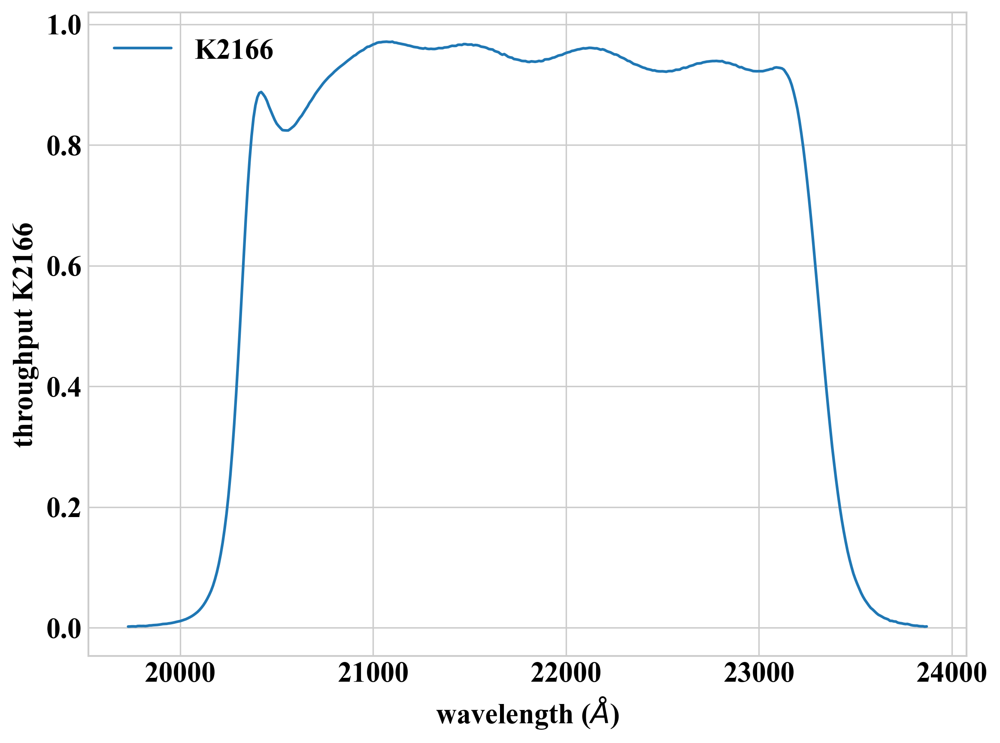

T, Z, G 5100 -0.0 4.0
limb darkening coefficient at K2166 band [0.2834]


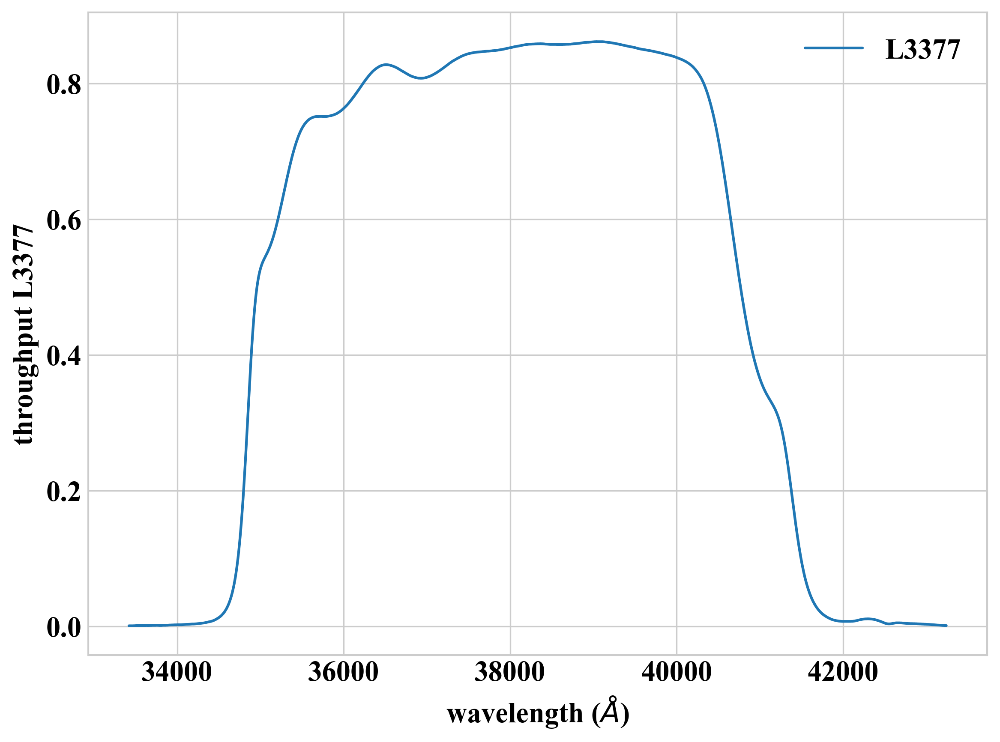

T, Z, G 5100 -0.0 4.0
limb darkening coefficient at L3377 band [0.1929]


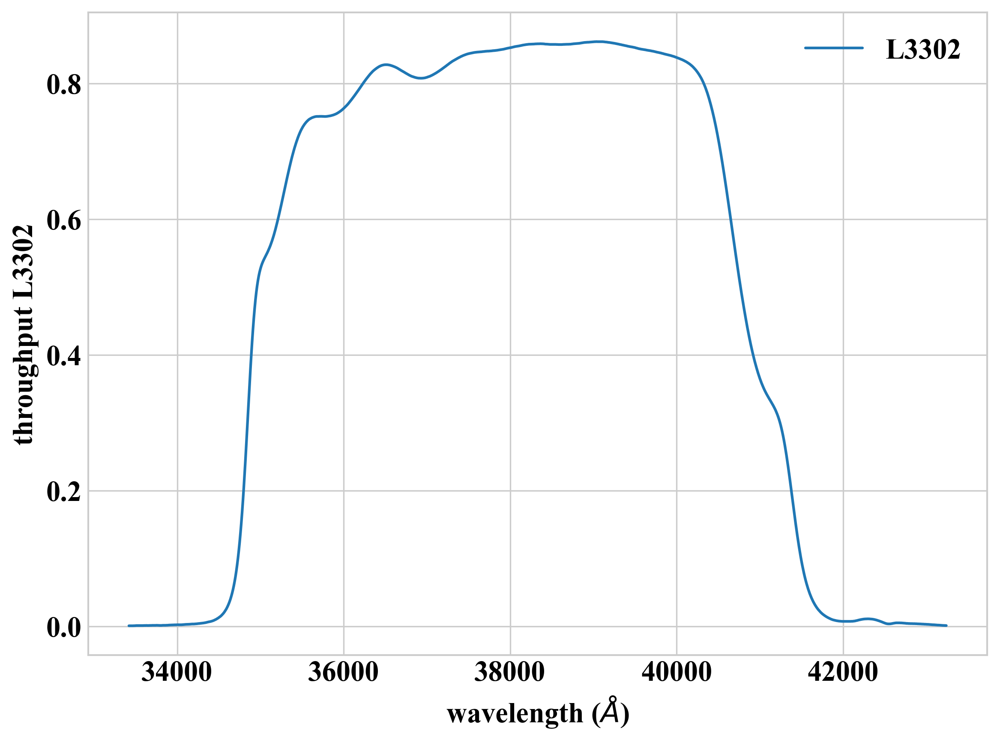

T, Z, G 5100 -0.0 4.0
limb darkening coefficient at L3302 band [0.1941]


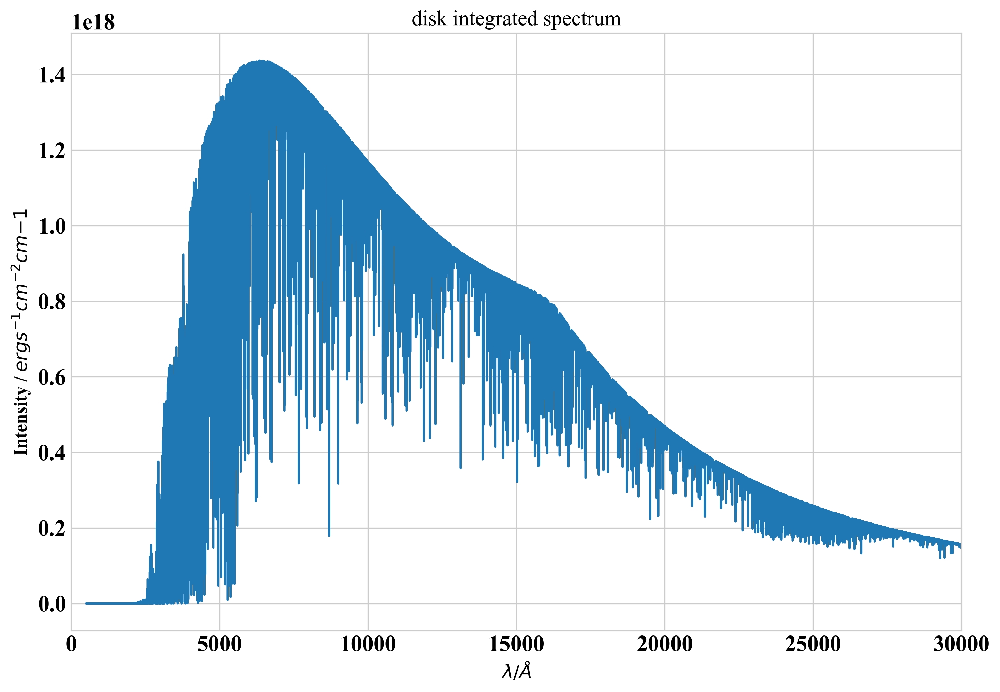

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


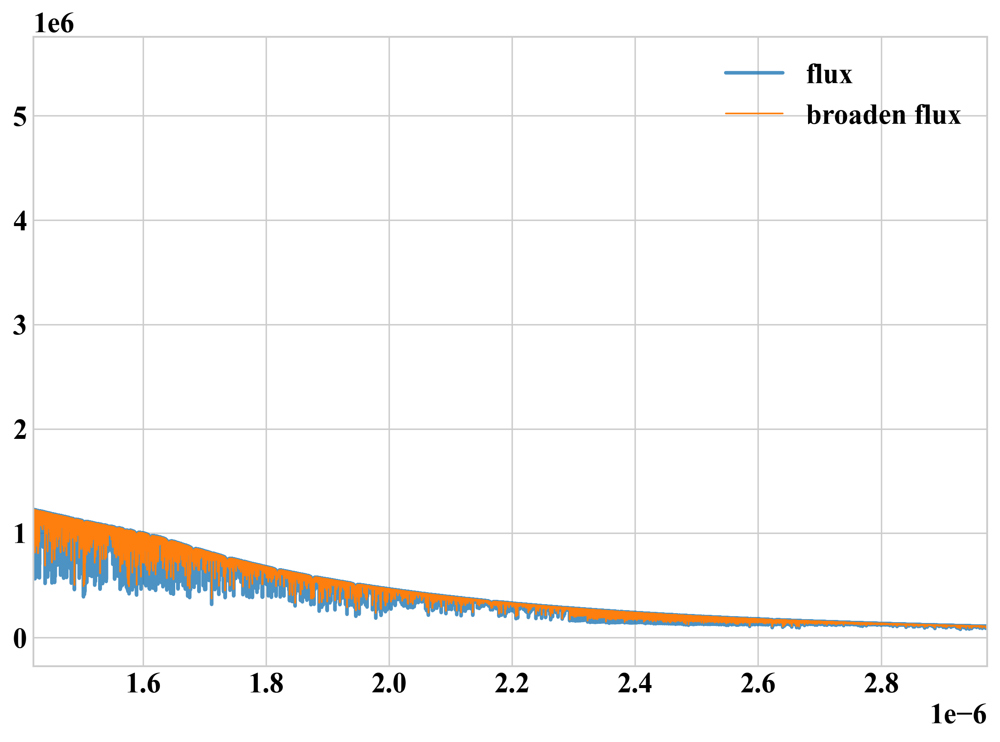

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 9.04529515327939 337399.086489586 0.00024092503940520391
The star spectrum already exists, skipping download


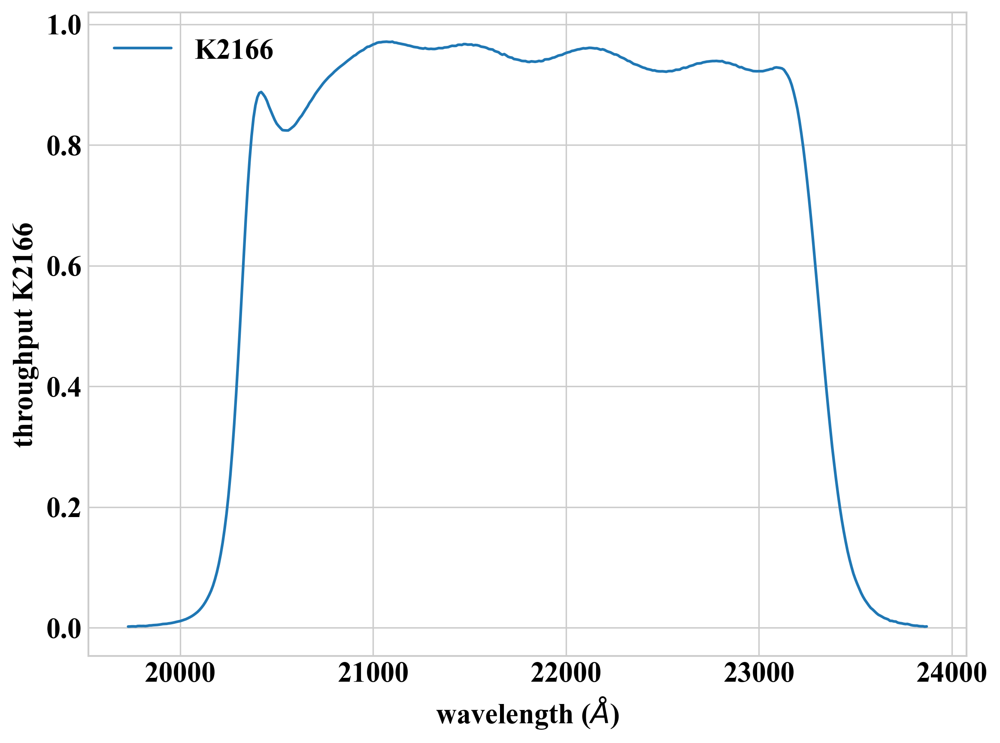

T, Z, G 5300 -0.0 4.0
limb darkening coefficient at K2166 band [0.2744]


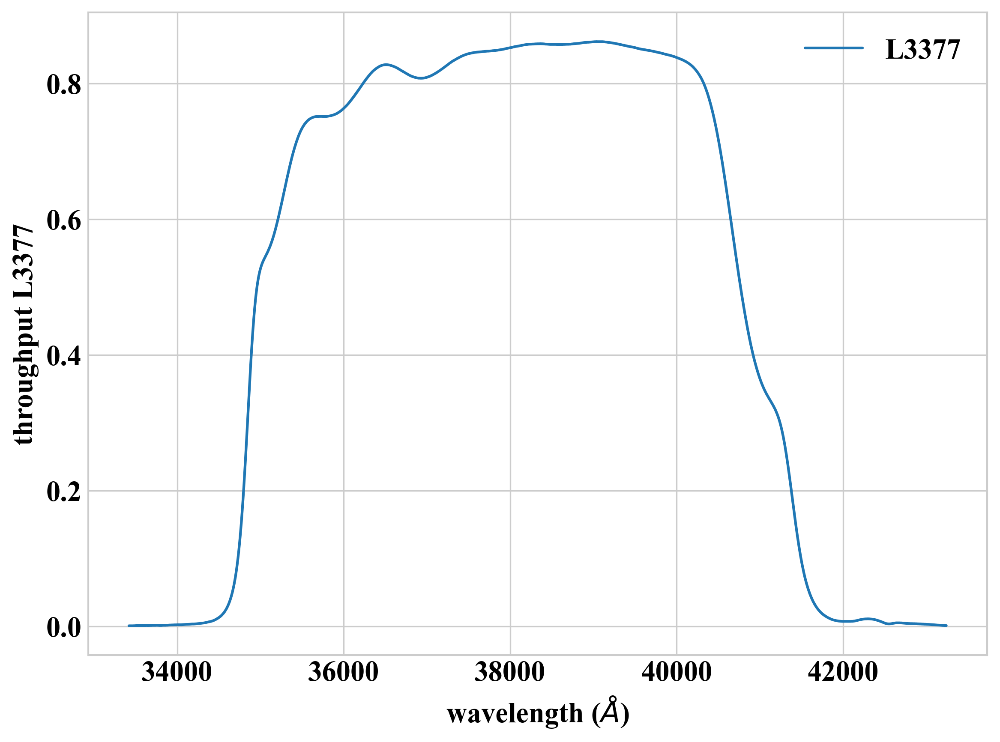

T, Z, G 5300 -0.0 4.0
limb darkening coefficient at L3377 band [0.185]


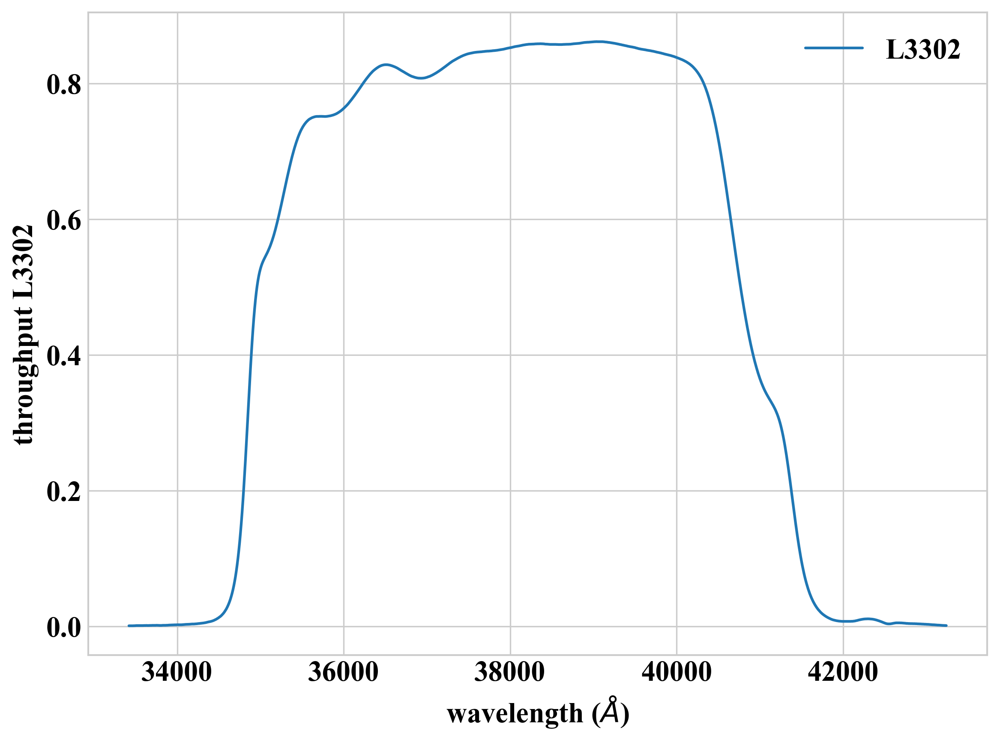

T, Z, G 5300 -0.0 4.0
limb darkening coefficient at L3302 band [0.1863]


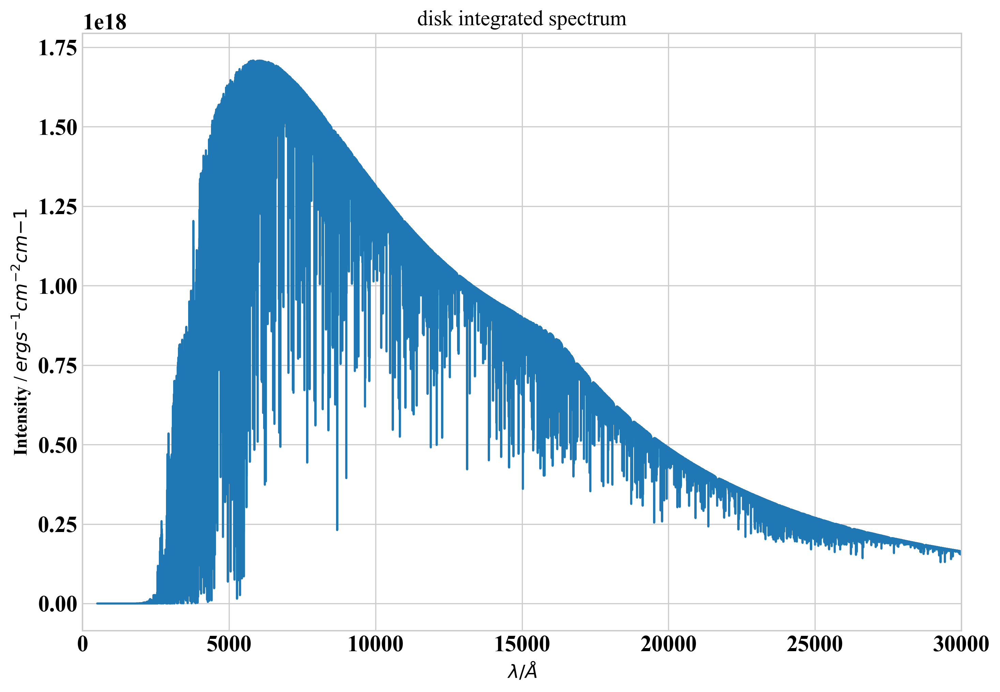

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


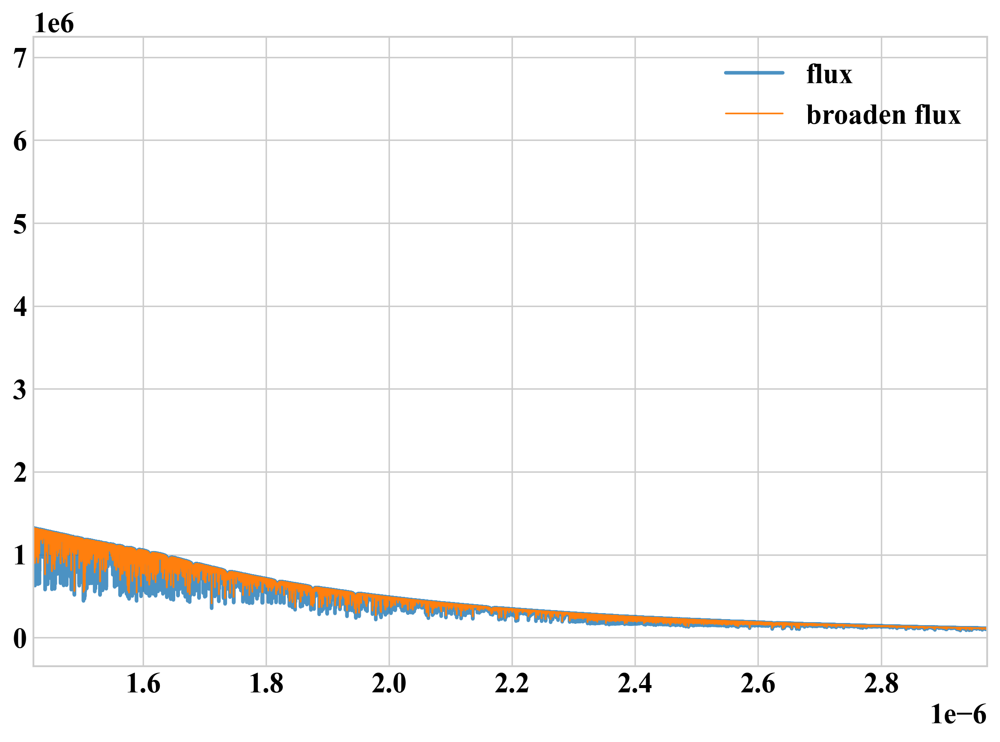

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 8.994613981475915 353521.93943797064 0.00025243781207548135
The star spectrum already exists, skipping download


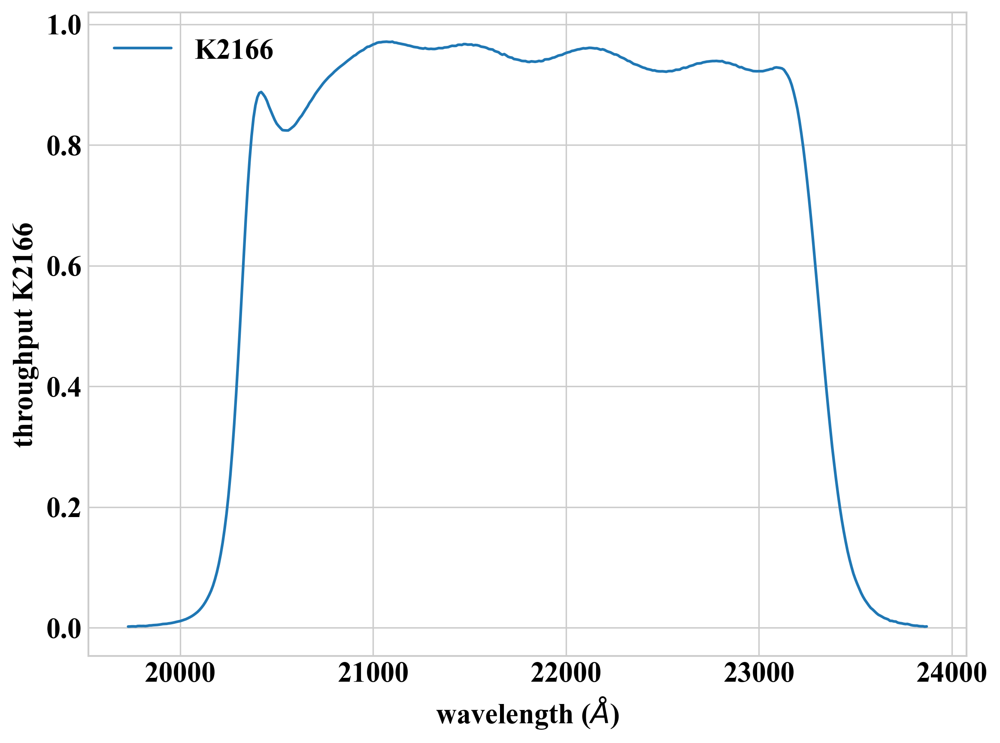

T, Z, G 5500 -0.0 4.0
limb darkening coefficient at K2166 band [0.2654]


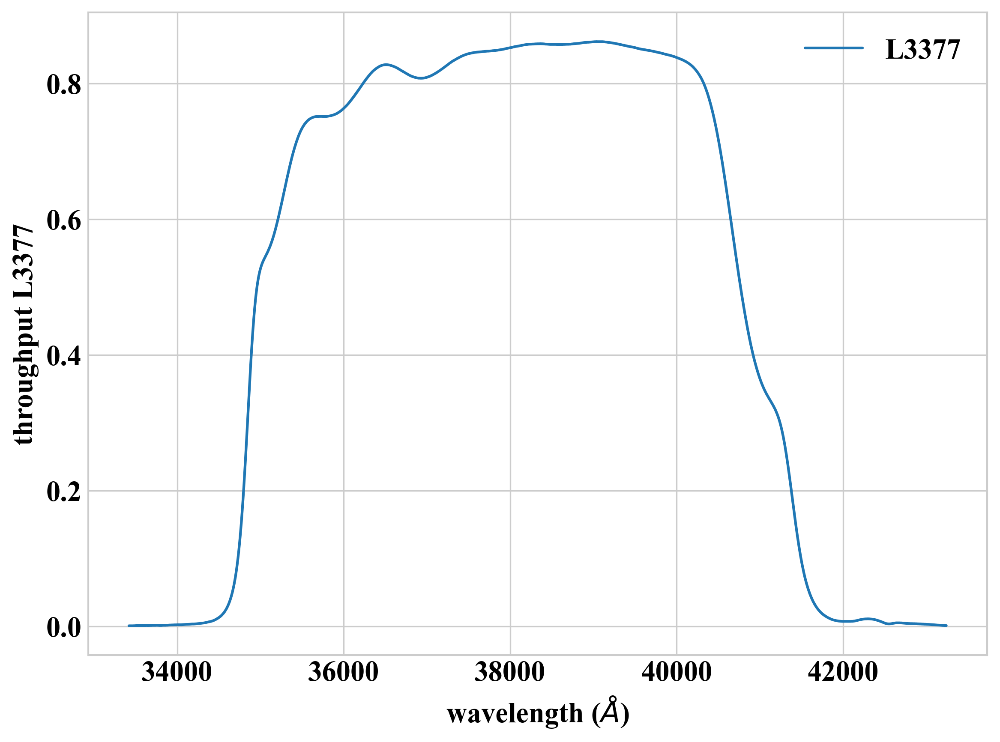

T, Z, G 5500 -0.0 4.0
limb darkening coefficient at L3377 band [0.1779]


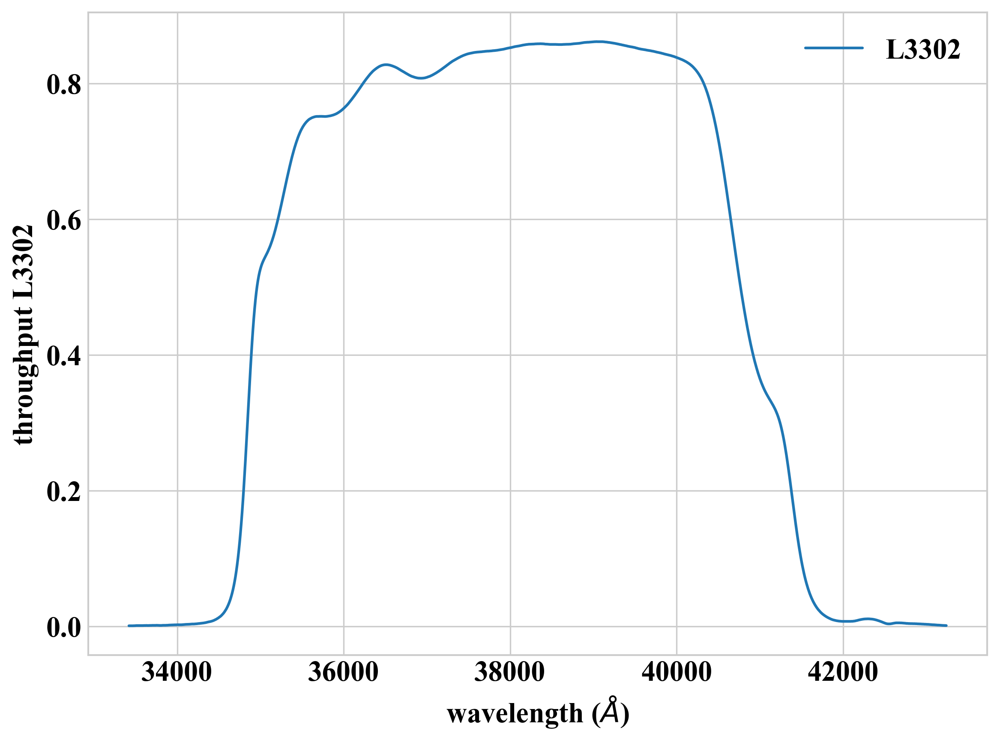

T, Z, G 5500 -0.0 4.0
limb darkening coefficient at L3302 band [0.1791]


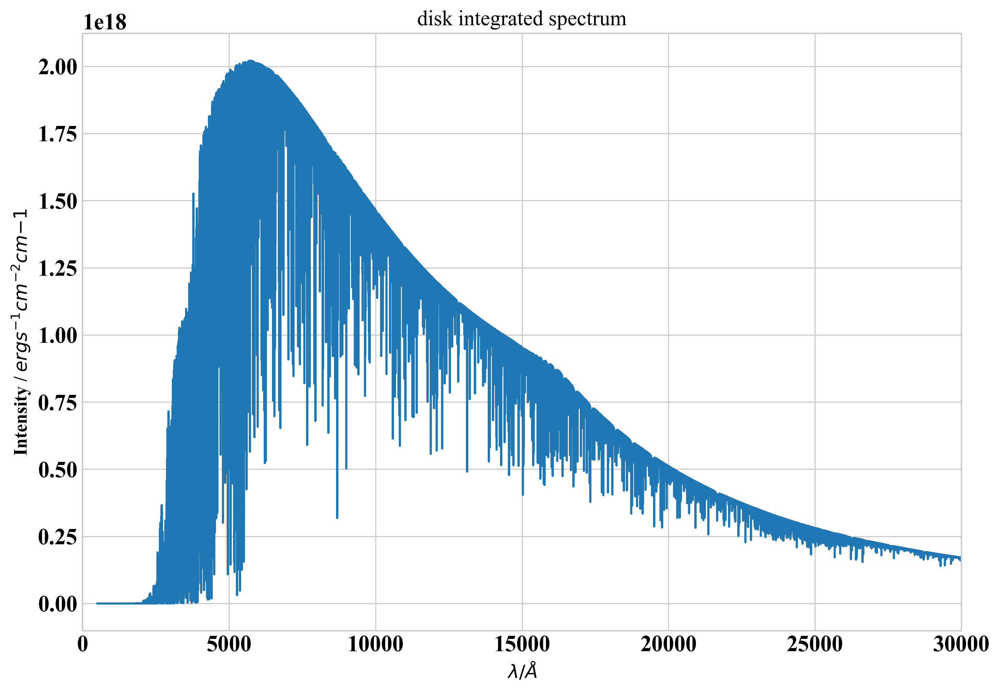

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


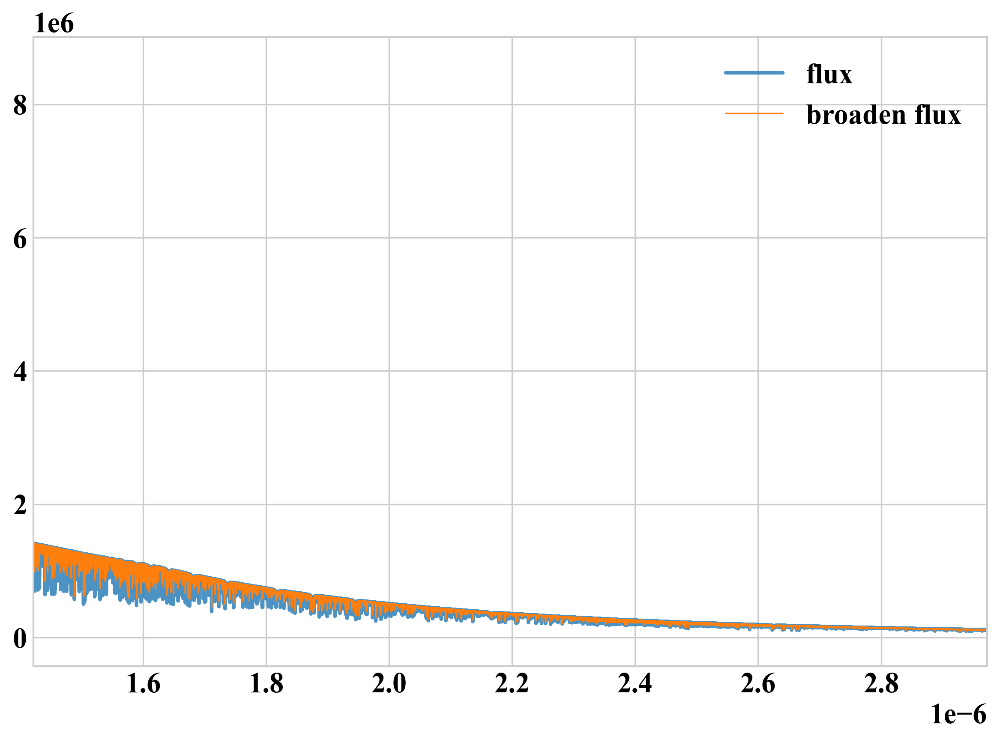

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 8.988760074282476 369235.1059333627 0.00025380254361330896
The star spectrum already exists, skipping download


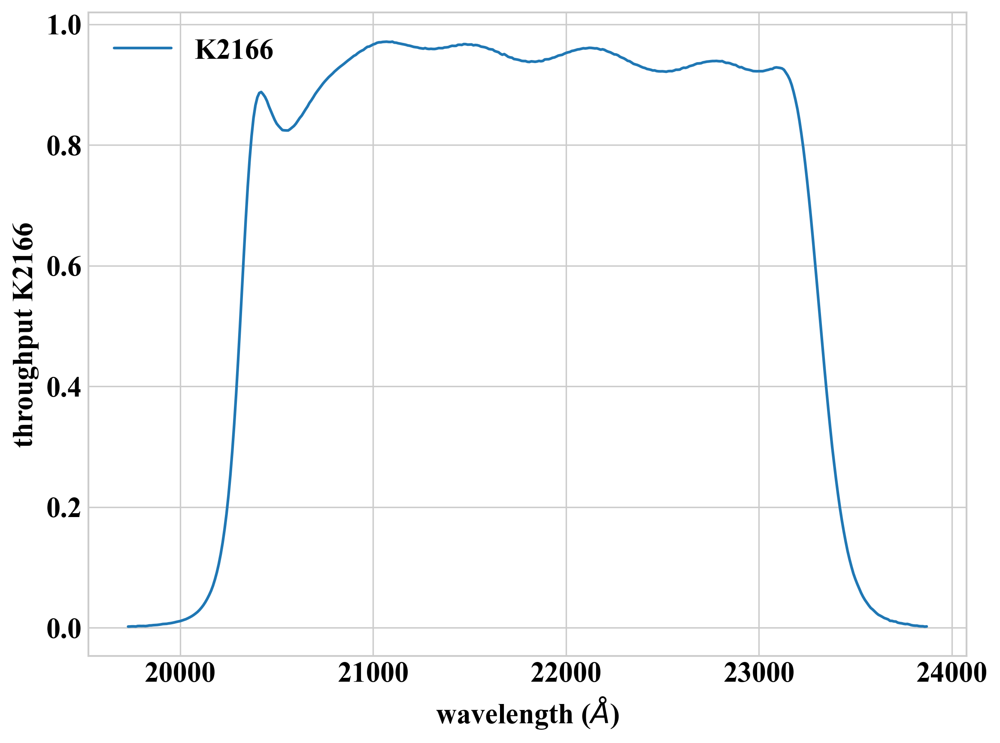

T, Z, G 5600 -0.0 4.0
limb darkening coefficient at K2166 band [0.261]


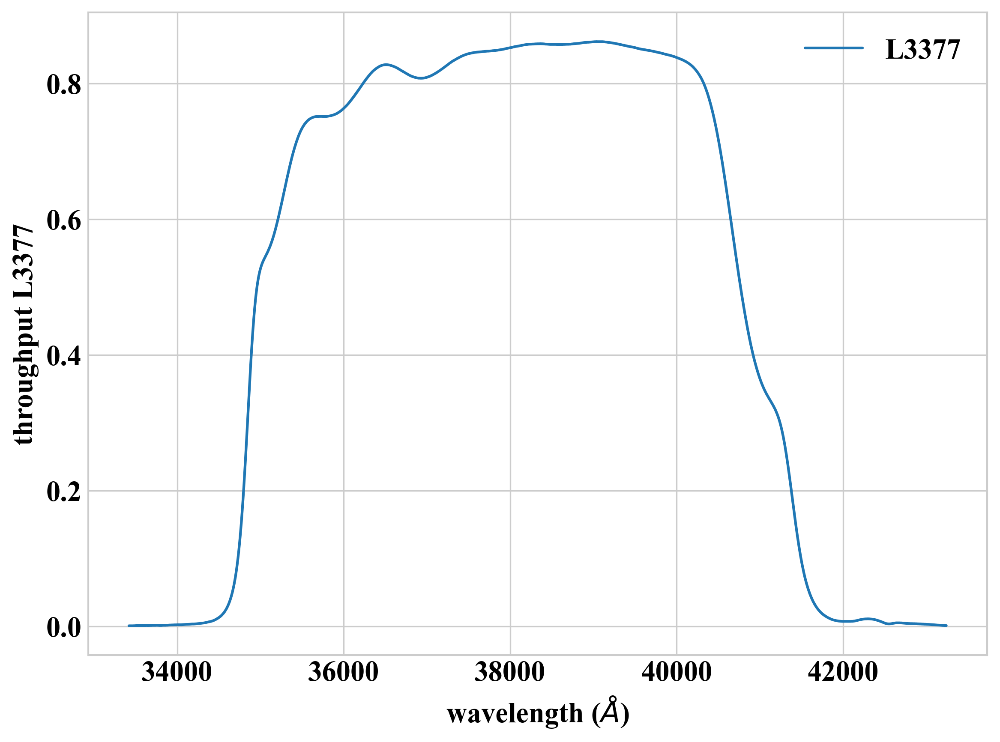

T, Z, G 5600 -0.0 4.0
limb darkening coefficient at L3377 band [0.1744]


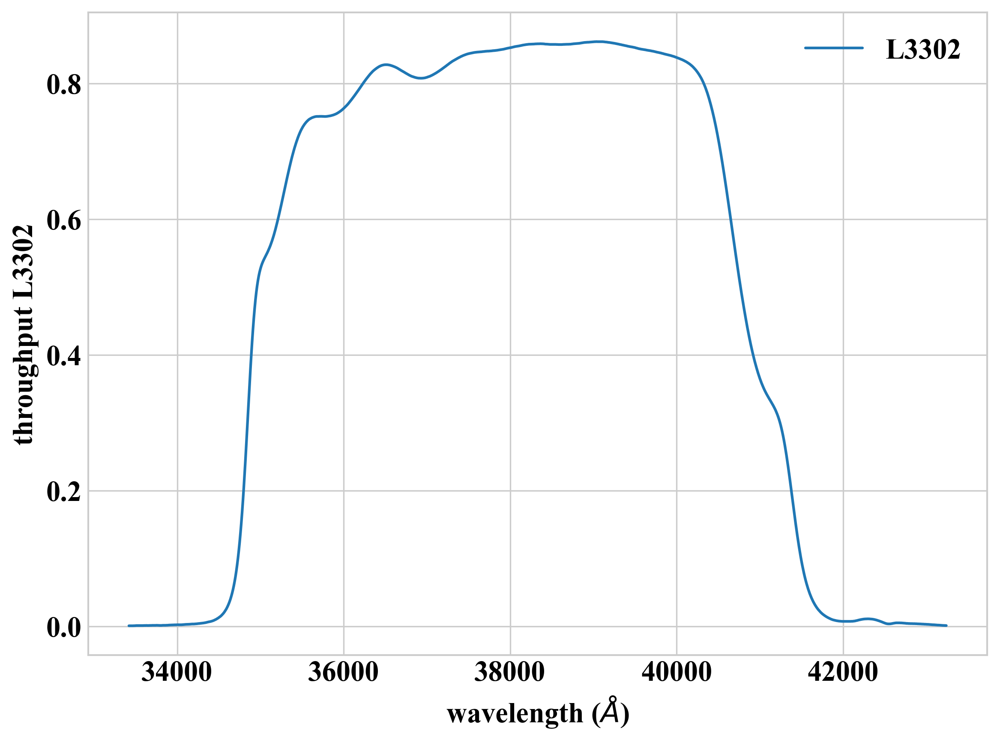

T, Z, G 5600 -0.0 4.0
limb darkening coefficient at L3302 band [0.1755]


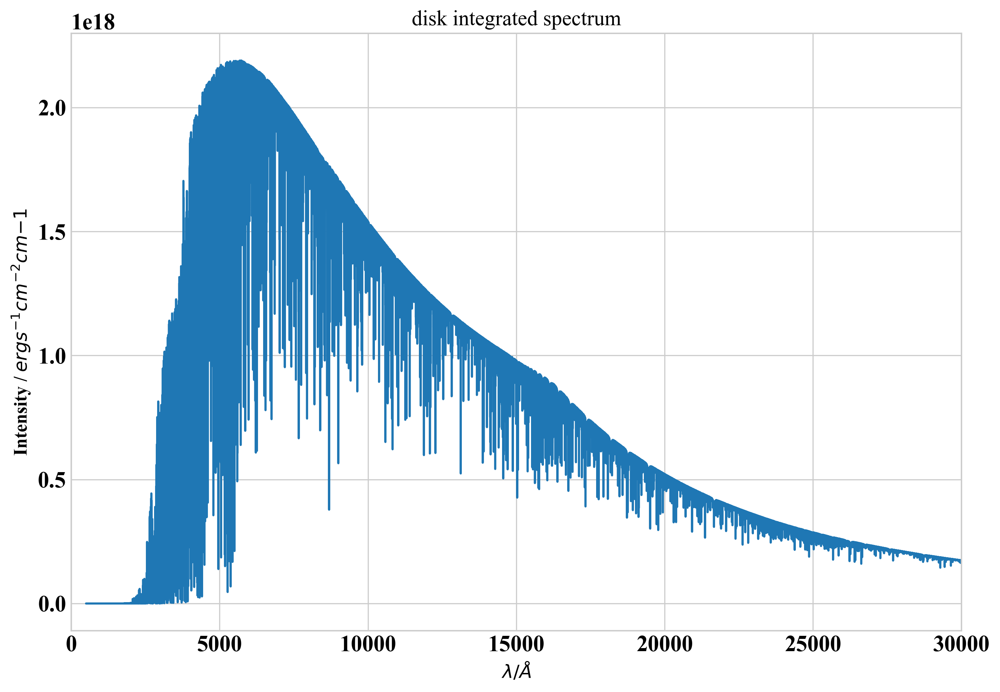

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


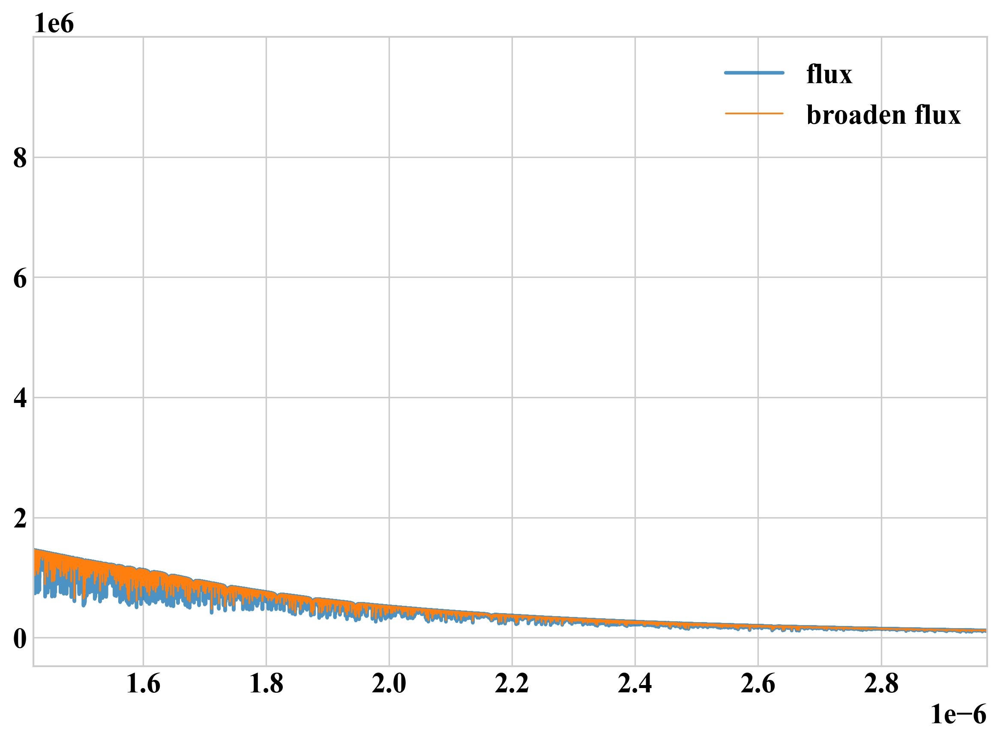

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 9.073048825817114 377036.82944002945 0.00023484454115316858
The star spectrum already exists, skipping download


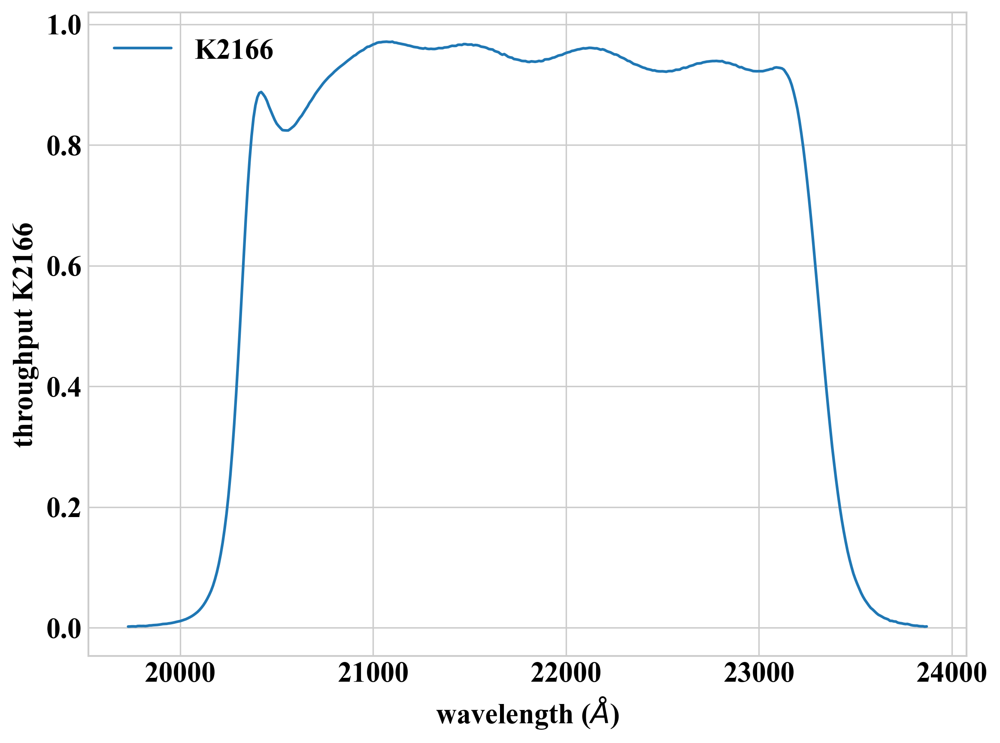

T, Z, G 5600 -0.0 4.5
limb darkening coefficient at K2166 band [0.2625]


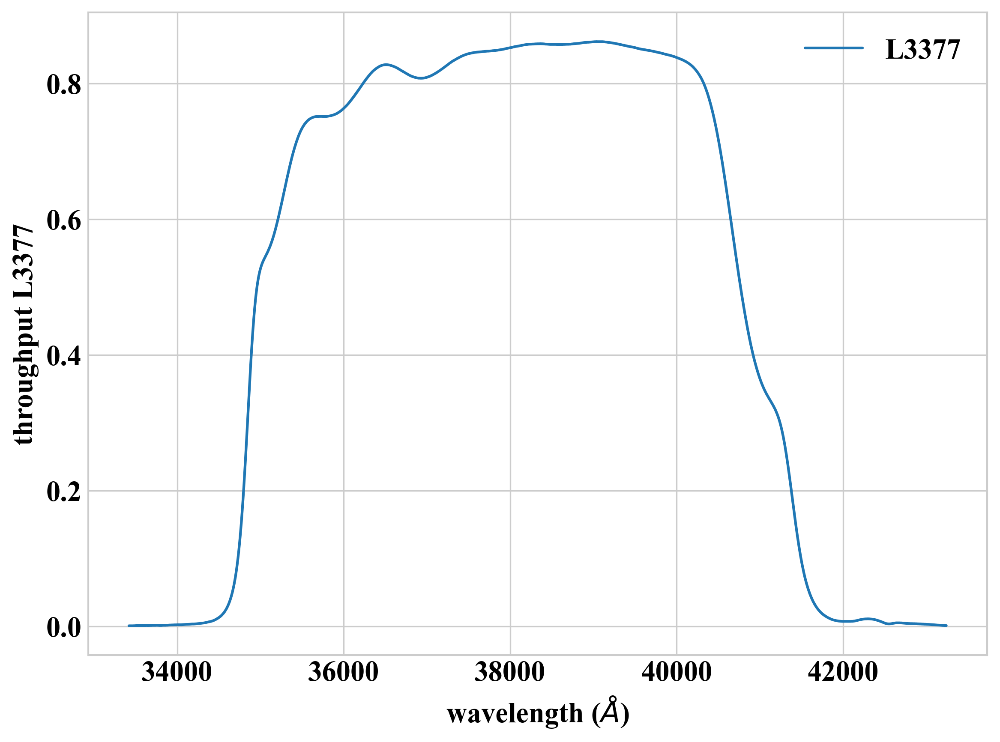

T, Z, G 5600 -0.0 4.5
limb darkening coefficient at L3377 band [0.1765]


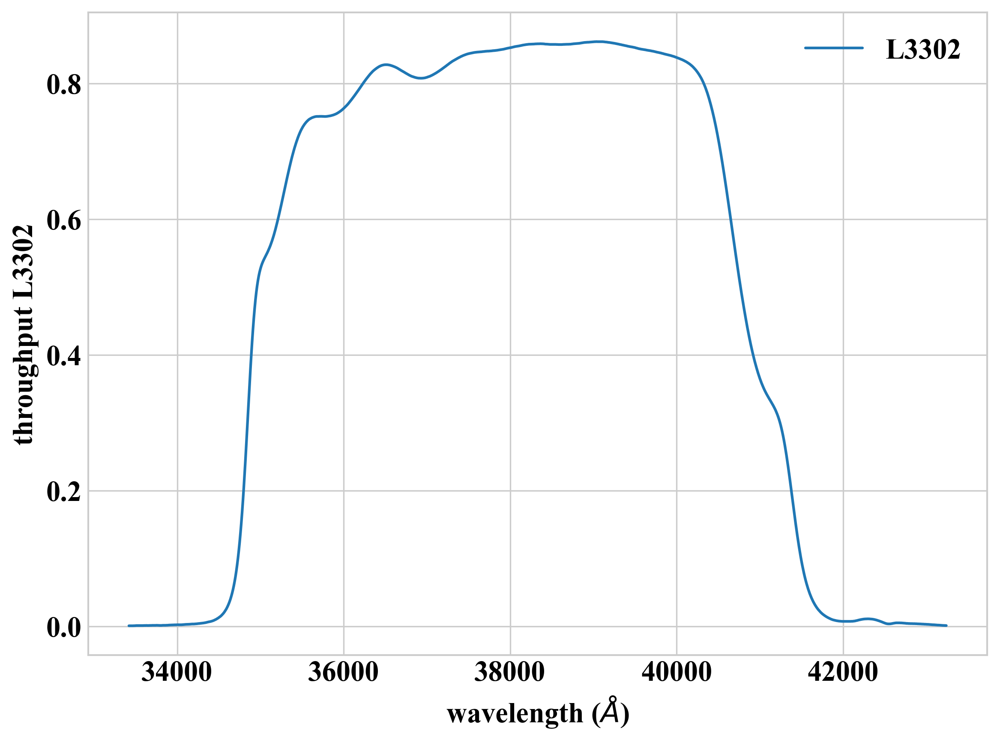

T, Z, G 5600 -0.0 4.5
limb darkening coefficient at L3302 band [0.1775]


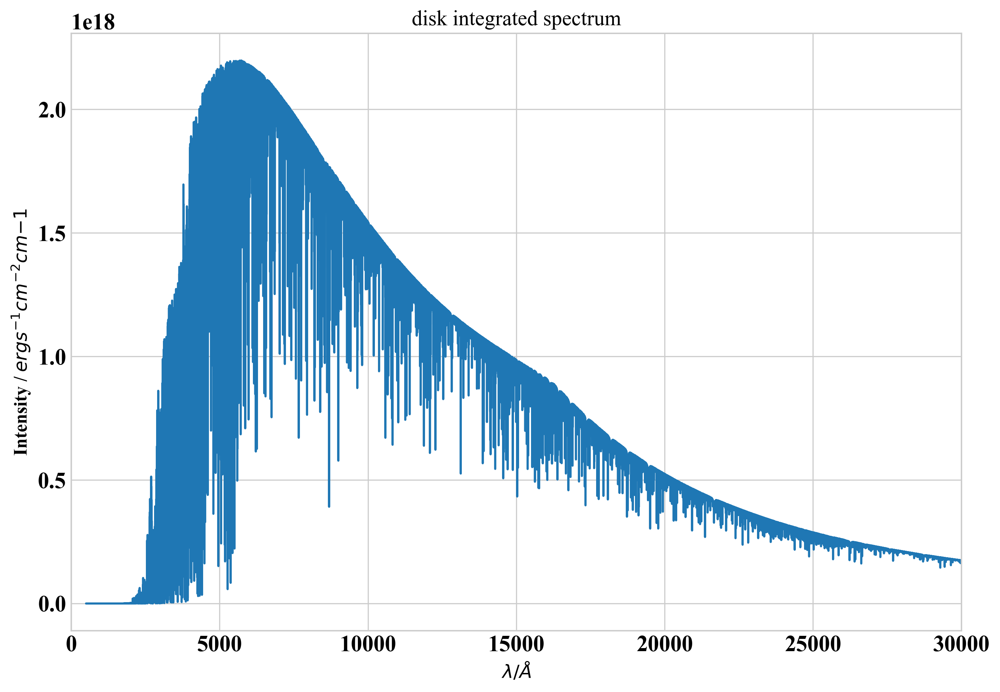

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


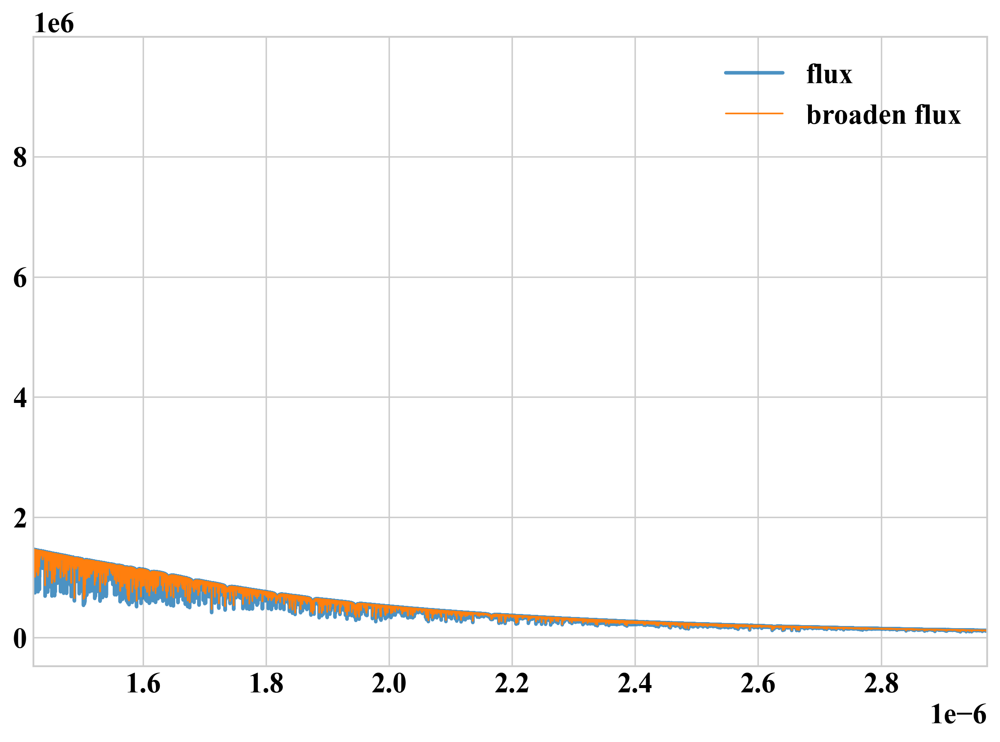

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 9.227064015081343 378854.48551010527 0.00020378602303654795
The star spectrum already exists, skipping download


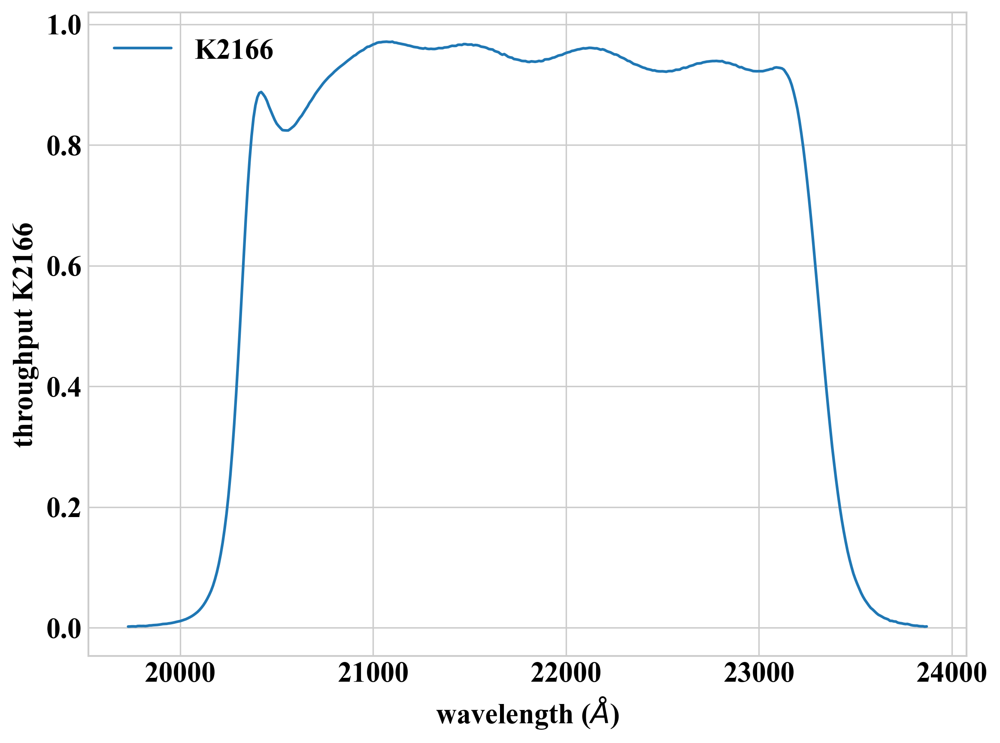

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at K2166 band [0.2668]


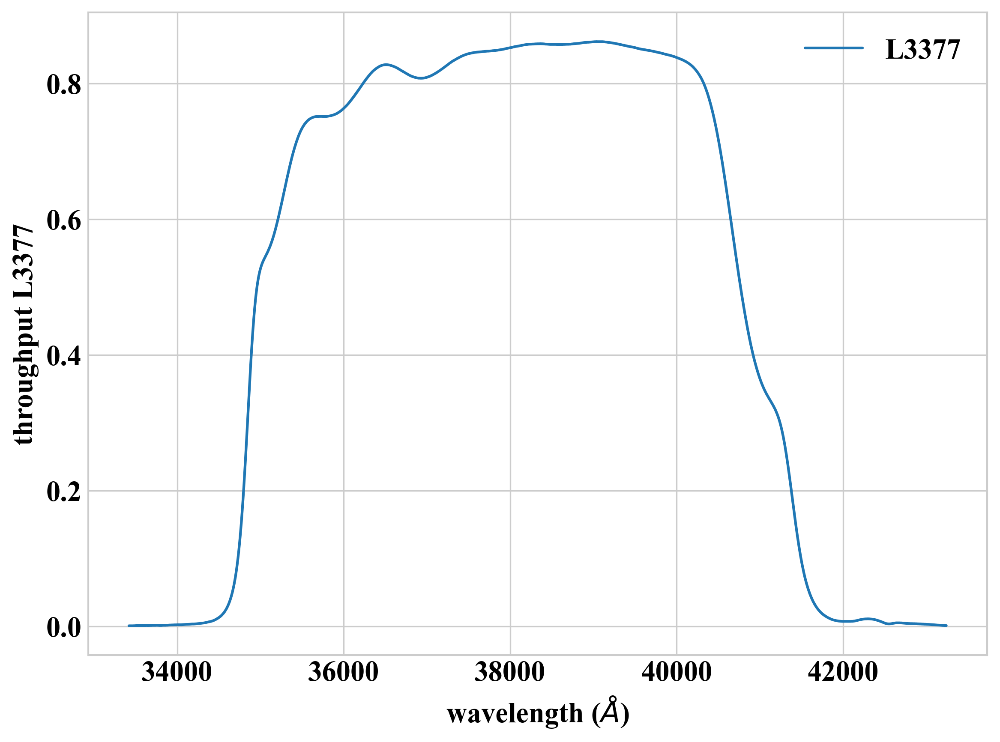

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3377 band [0.18]


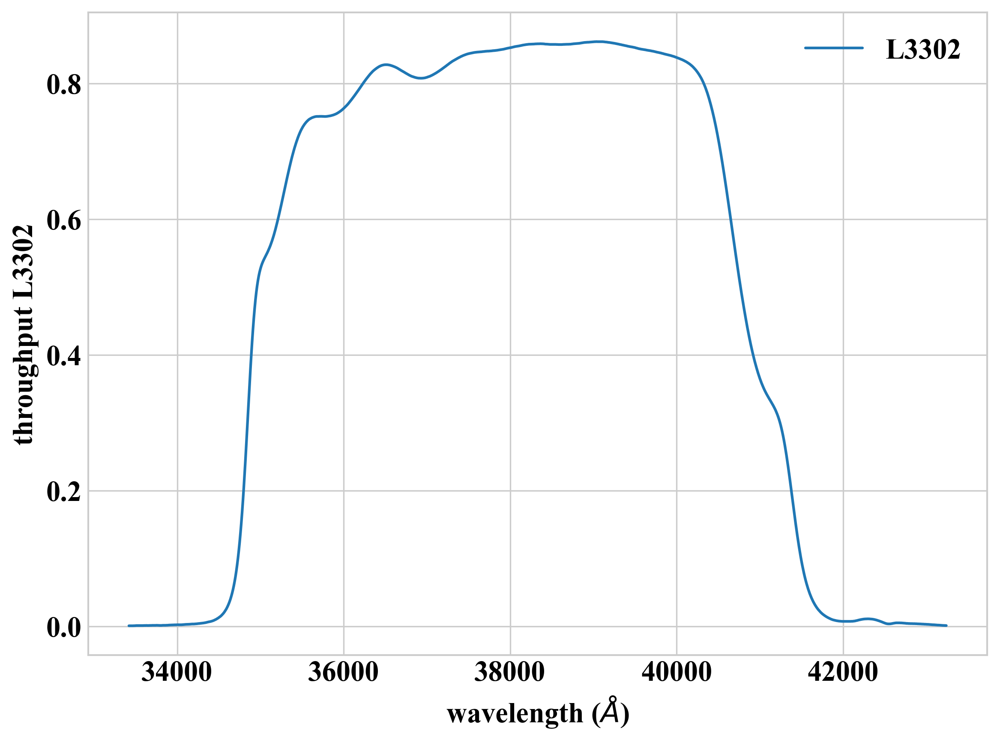

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3302 band [0.181]


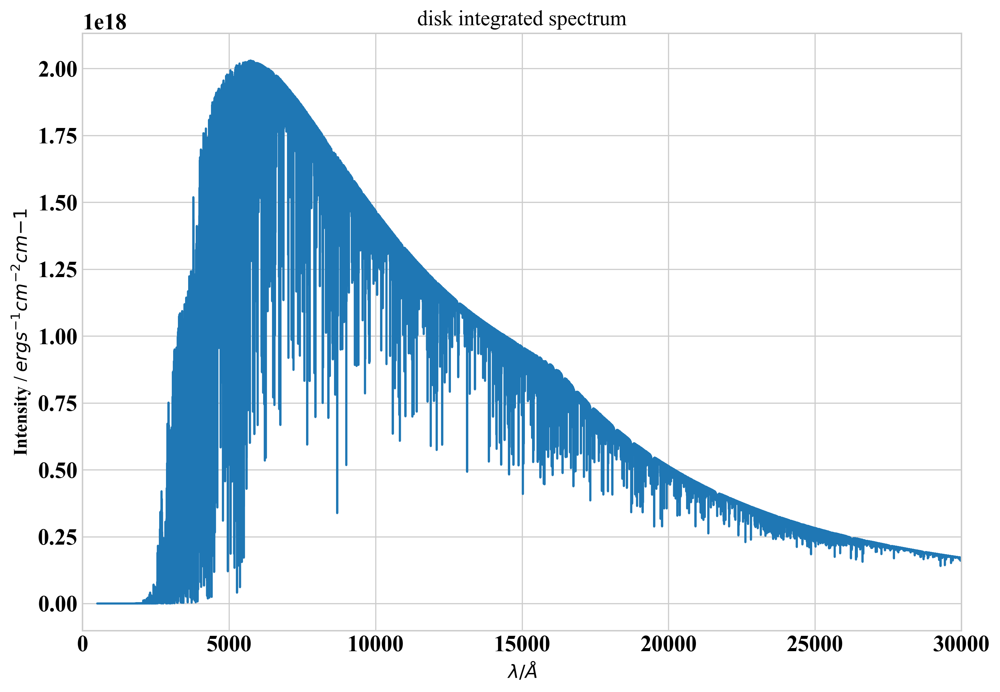

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


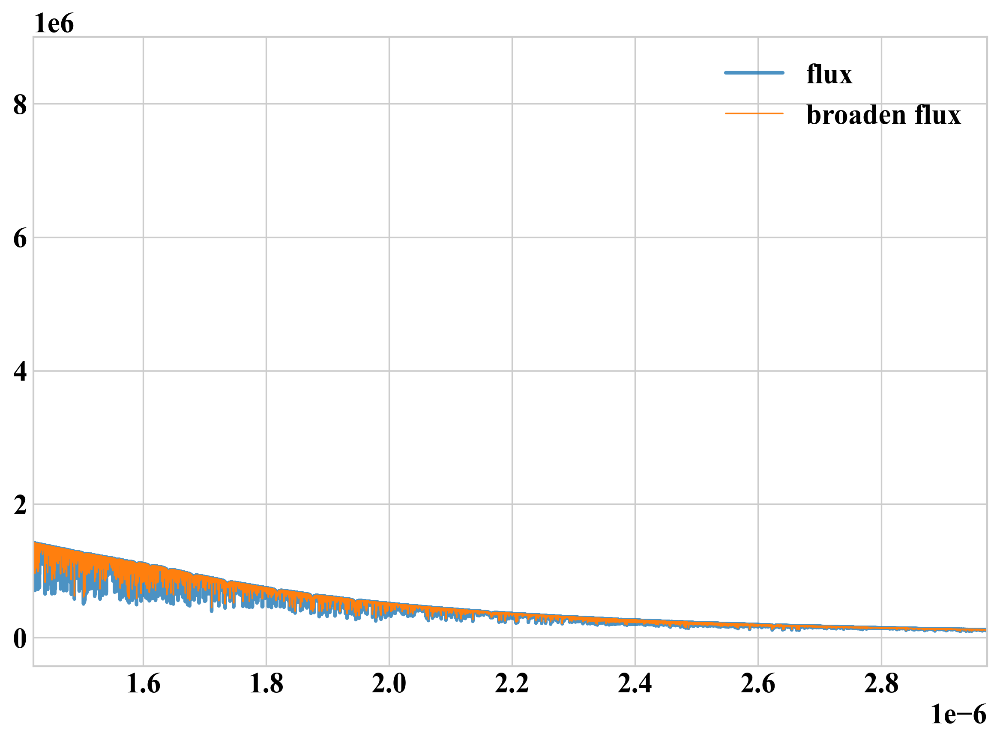

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 9.297881215795242 370882.36960508156 0.00019091828024979314
The star spectrum already exists, skipping download


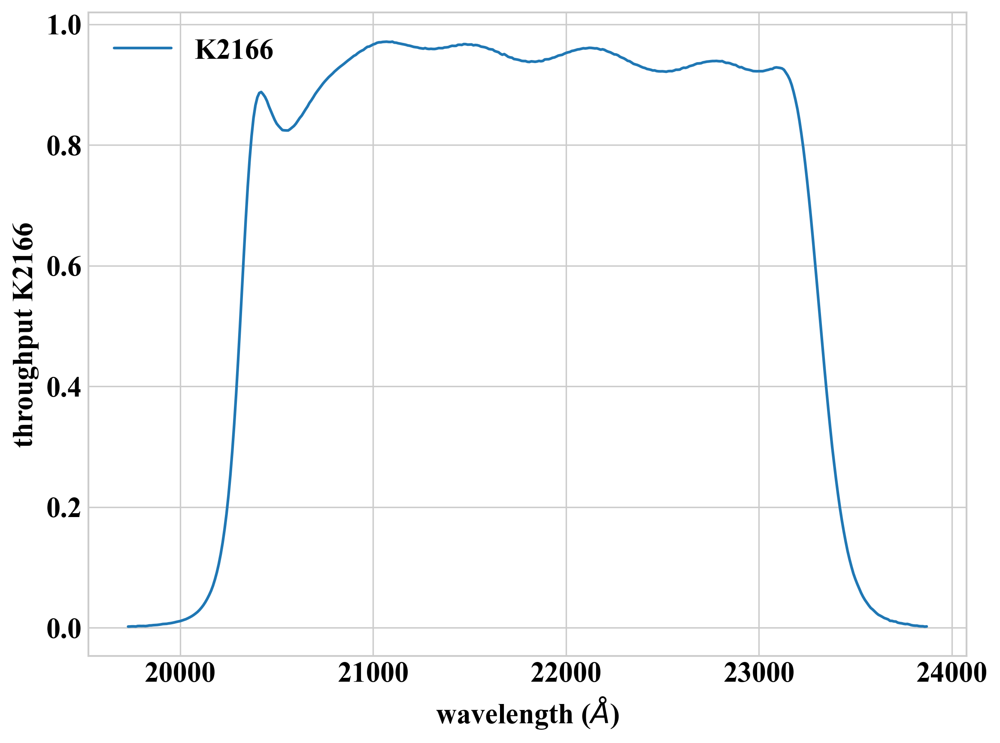

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at K2166 band [0.2668]


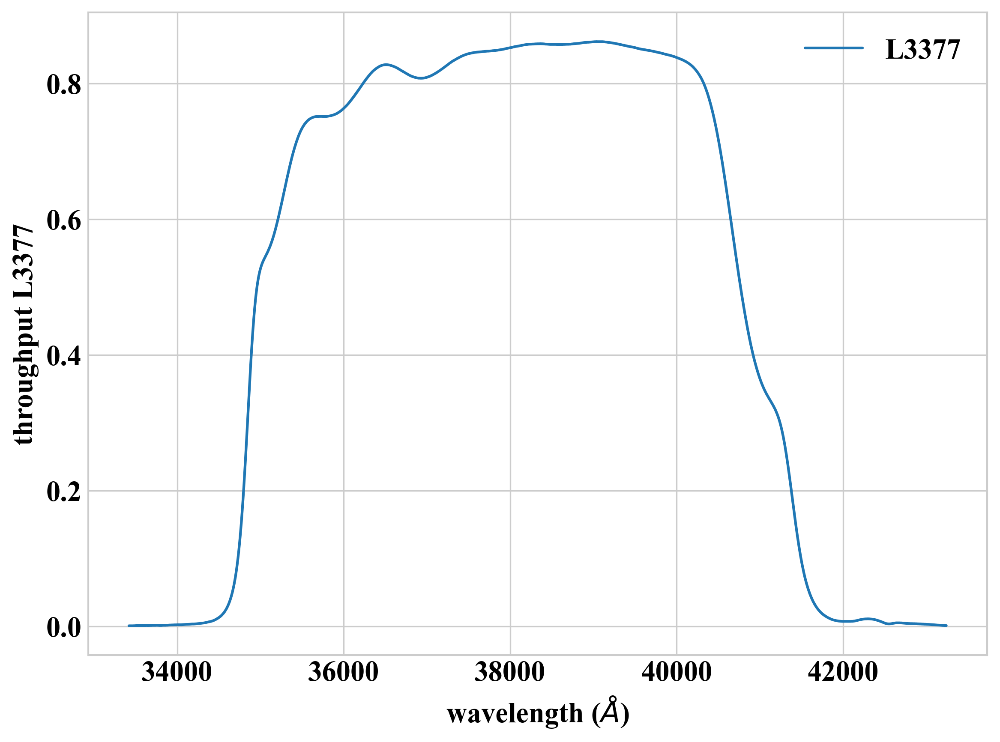

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3377 band [0.18]


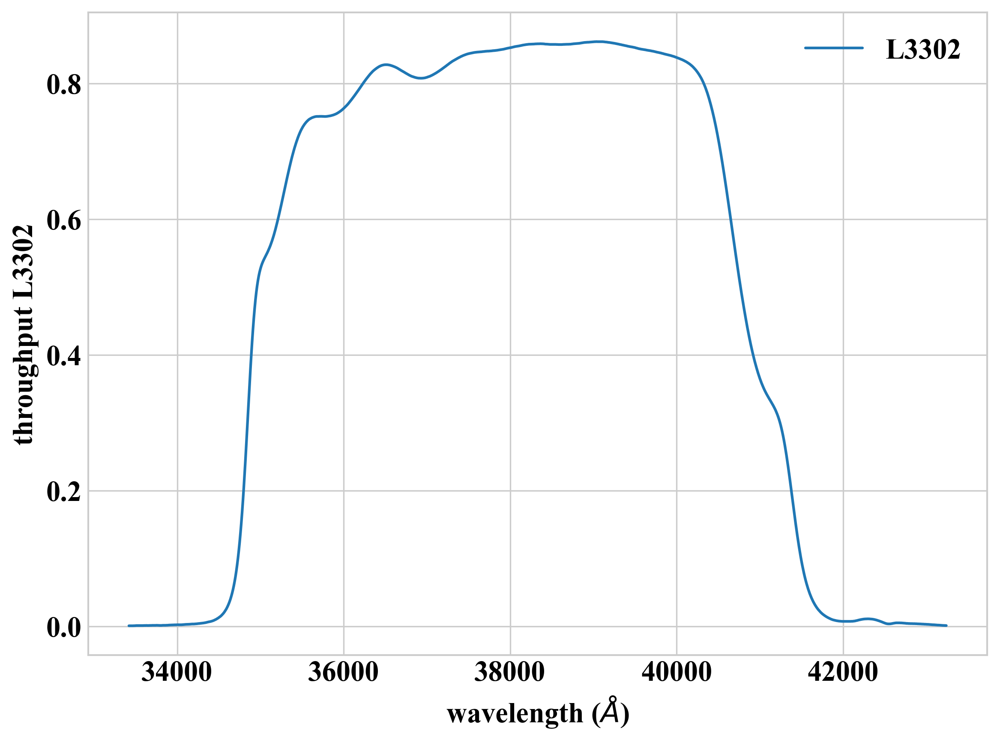

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3302 band [0.181]


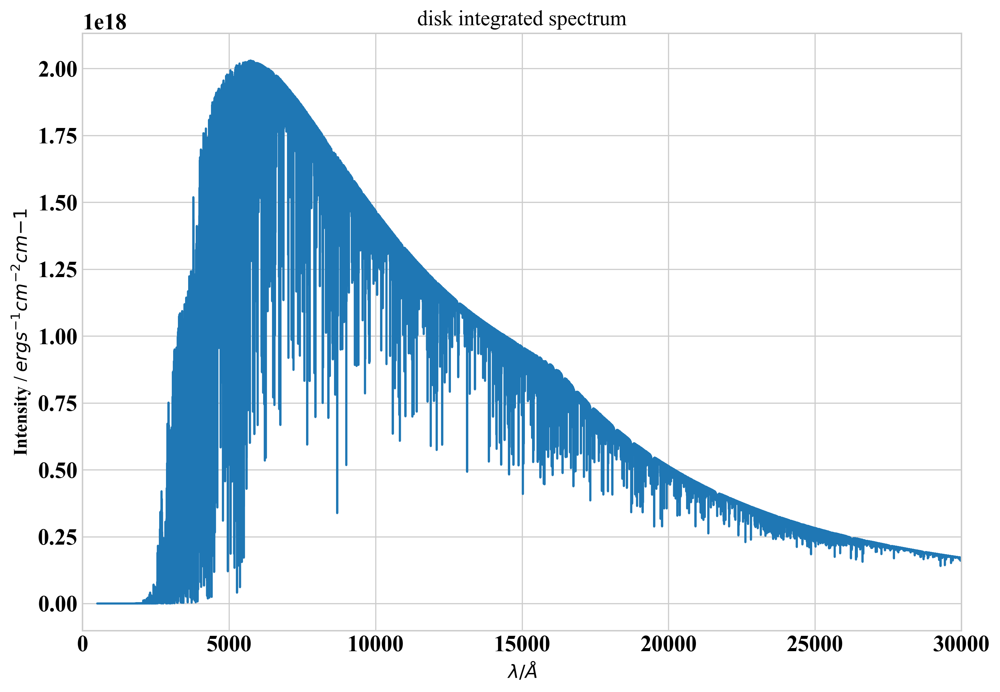

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


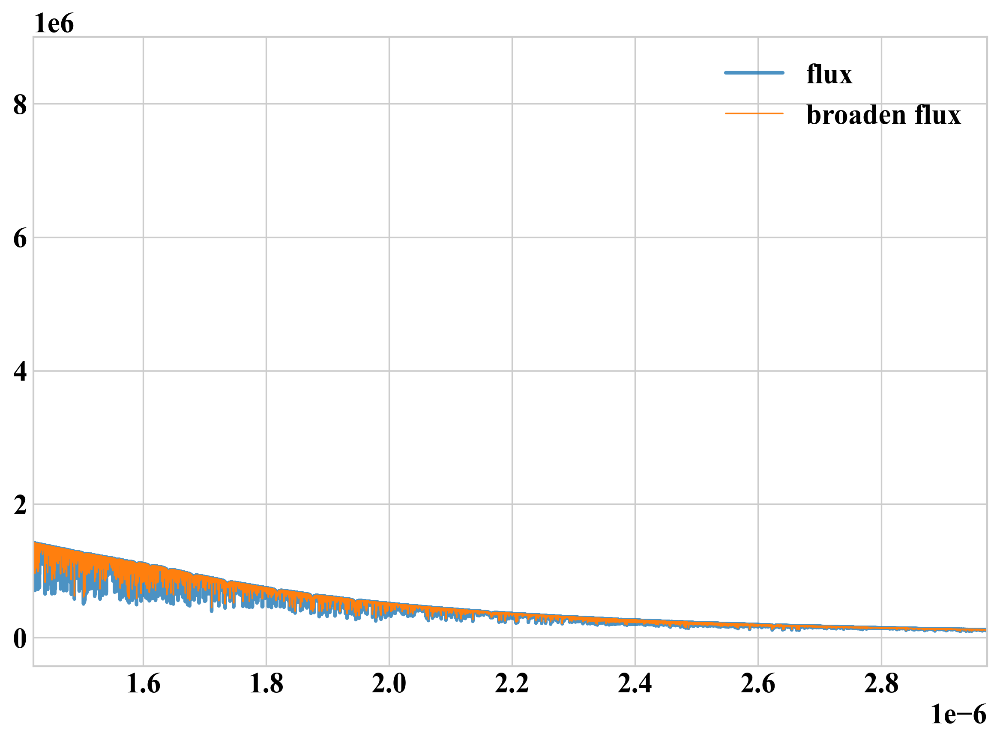

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 9.322143729767303 370882.36960508156 0.0001866992219578533
The star spectrum already exists, skipping download


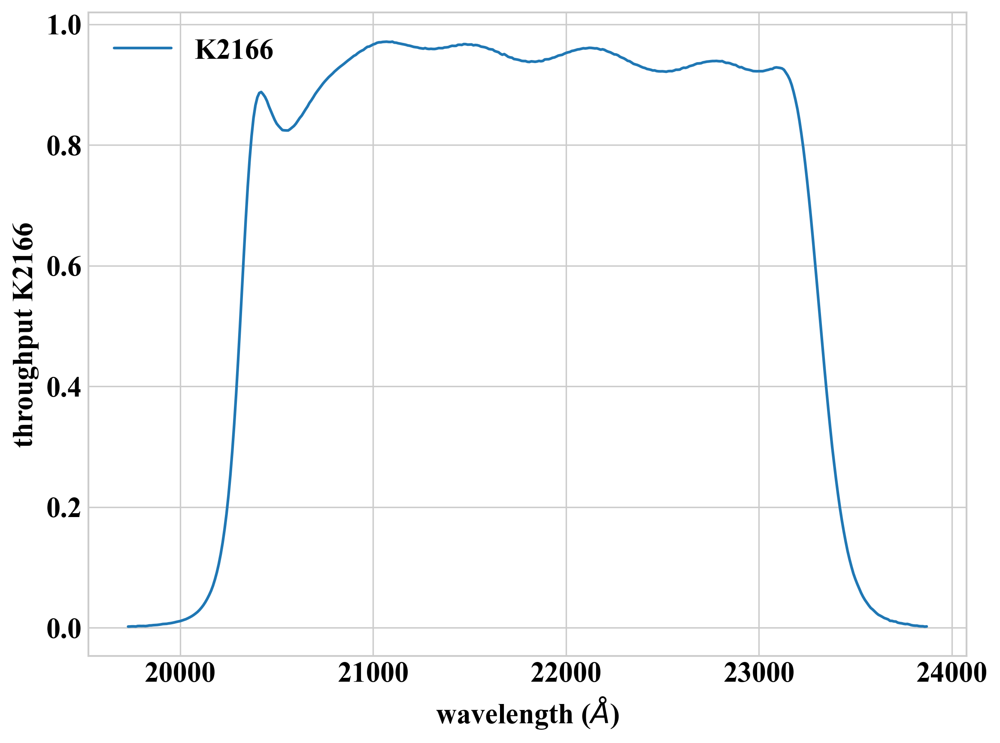

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at K2166 band [0.2668]


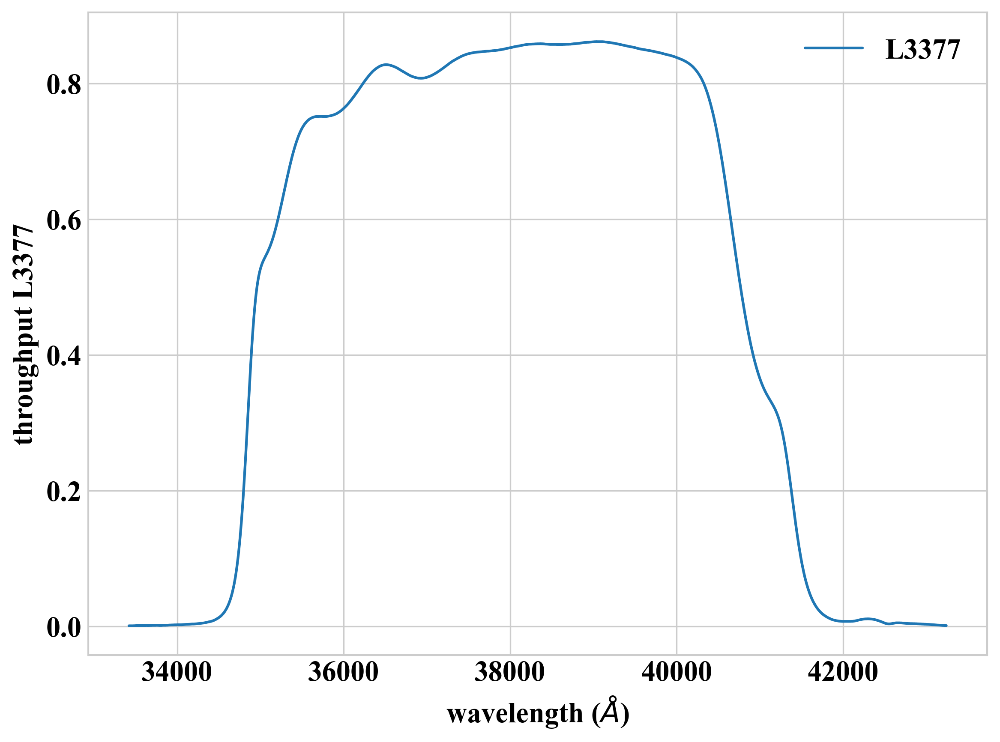

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3377 band [0.18]


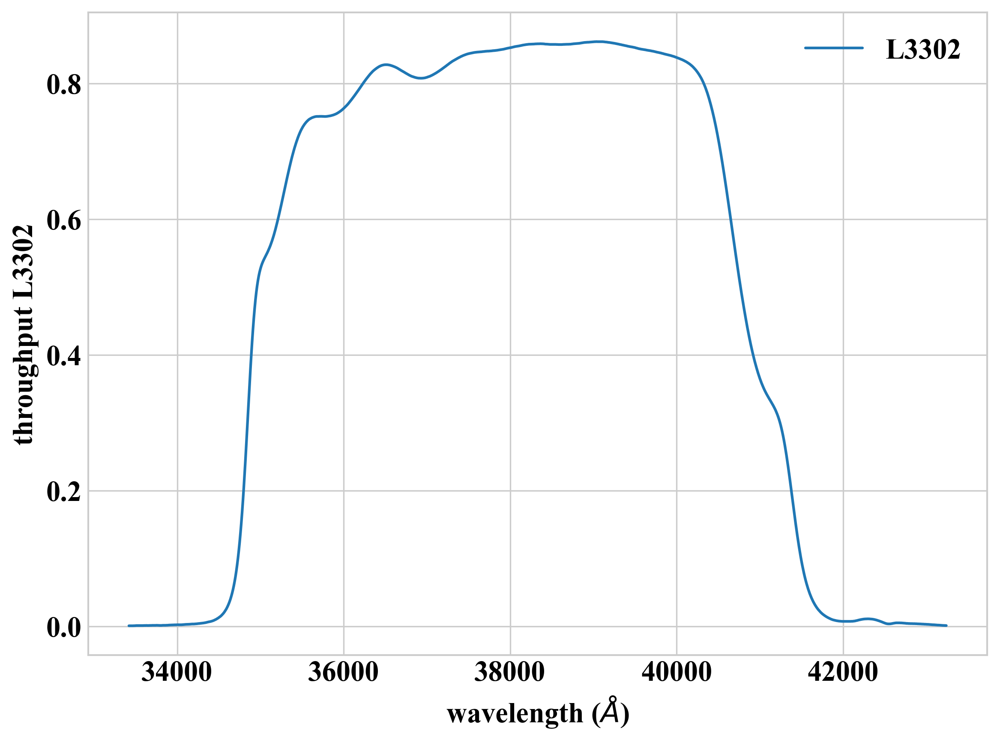

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3302 band [0.181]


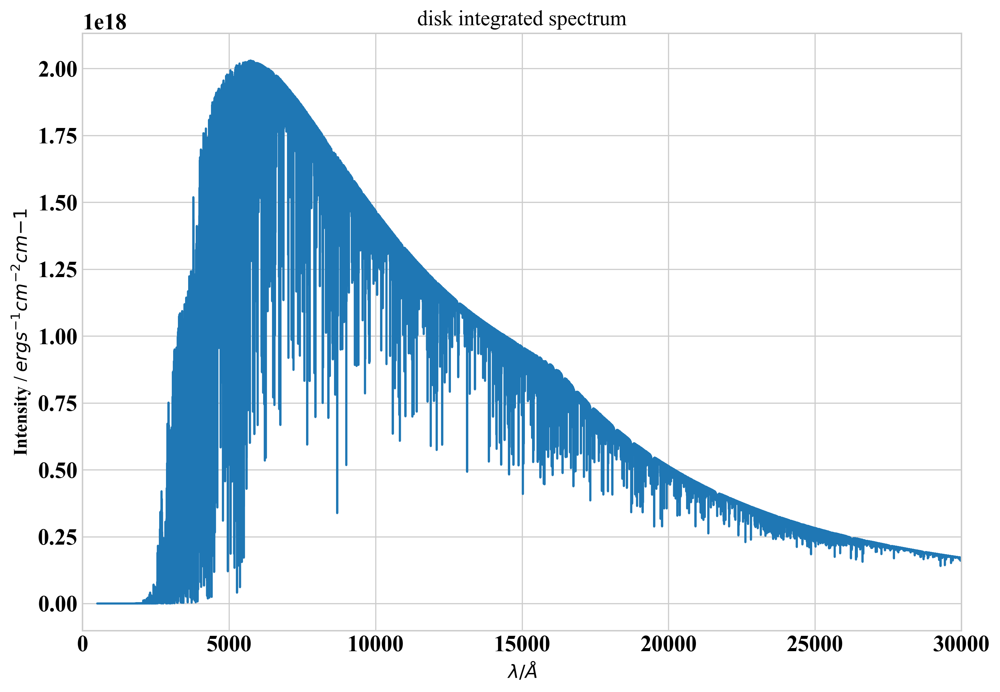

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


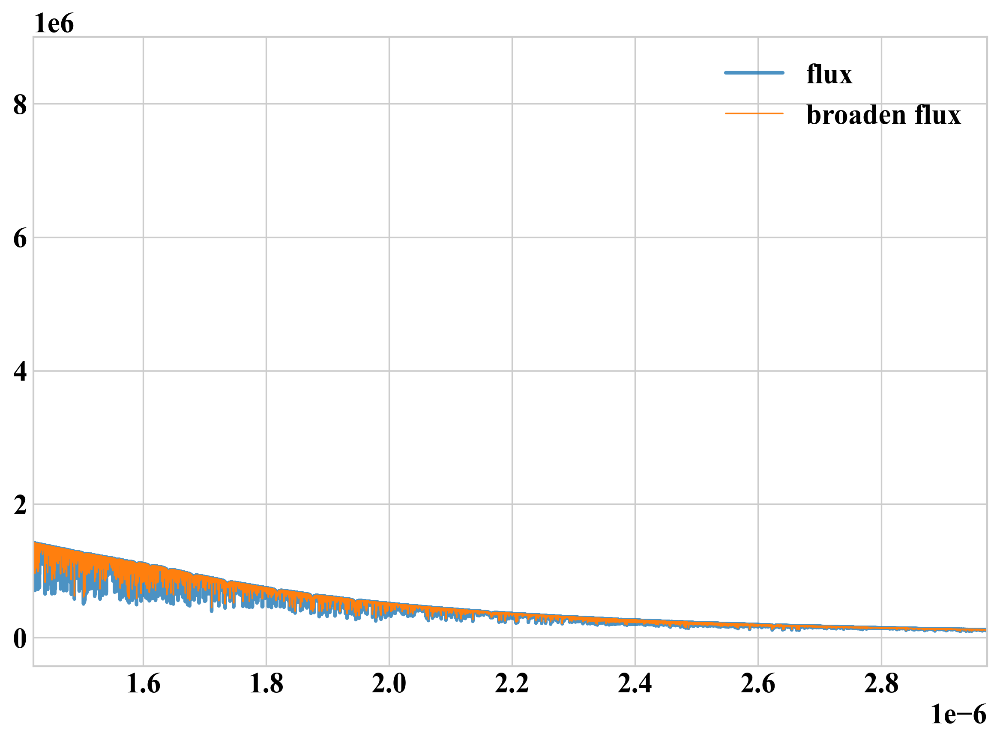

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 9.322143729767303 370882.36960508156 0.0001866992219578533
The star spectrum already exists, skipping download


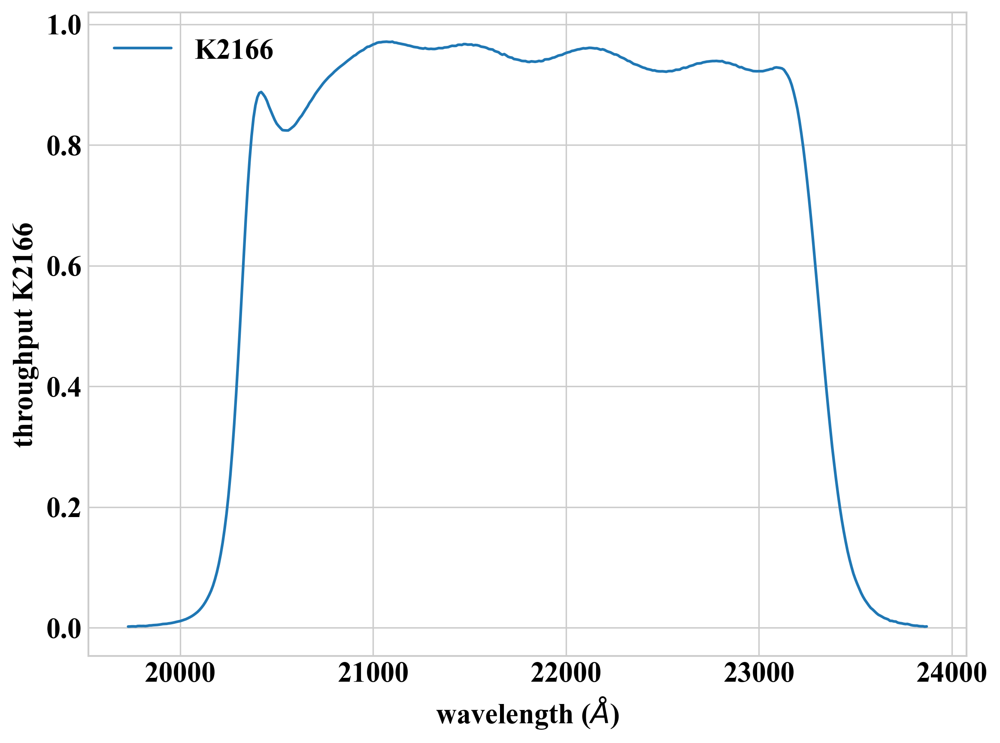

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at K2166 band [0.2668]


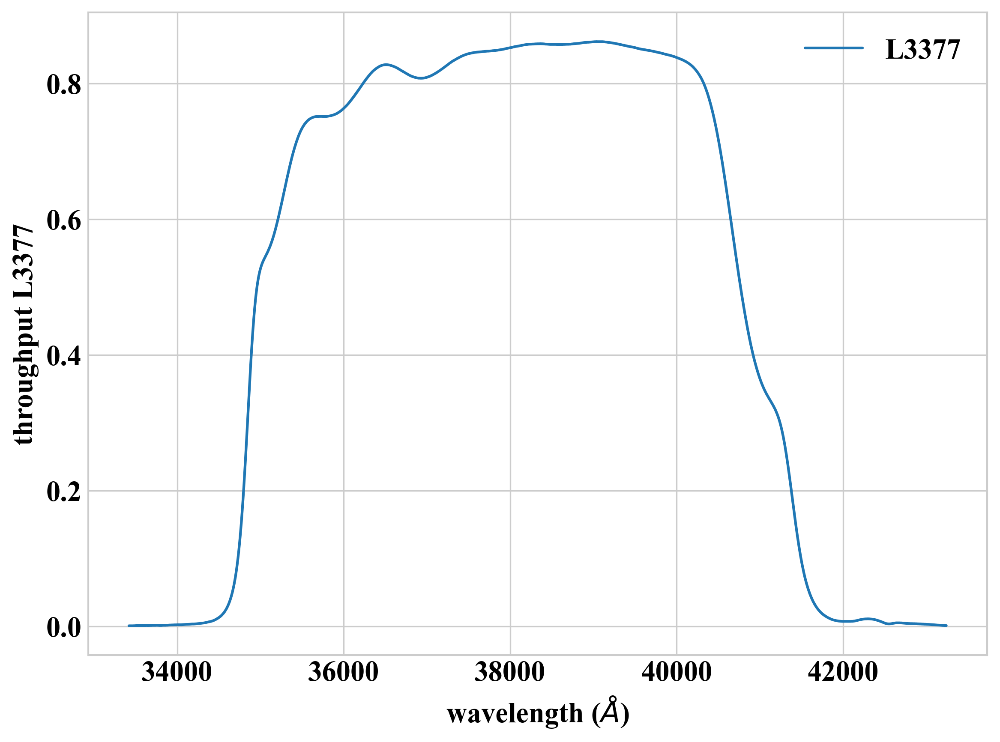

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3377 band [0.18]


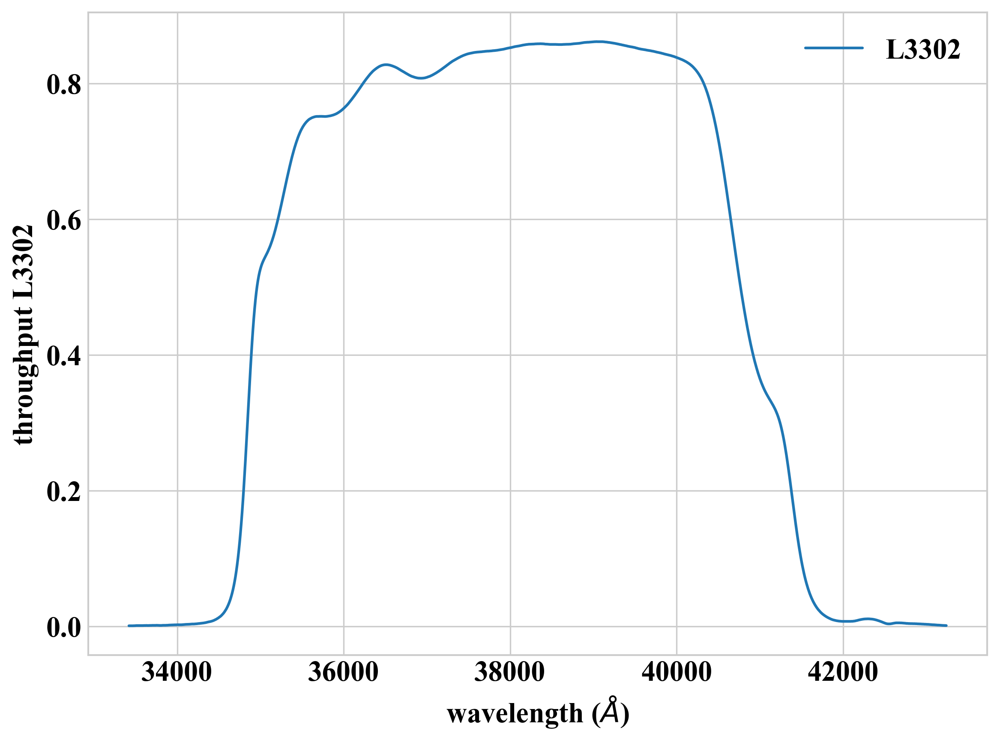

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3302 band [0.181]


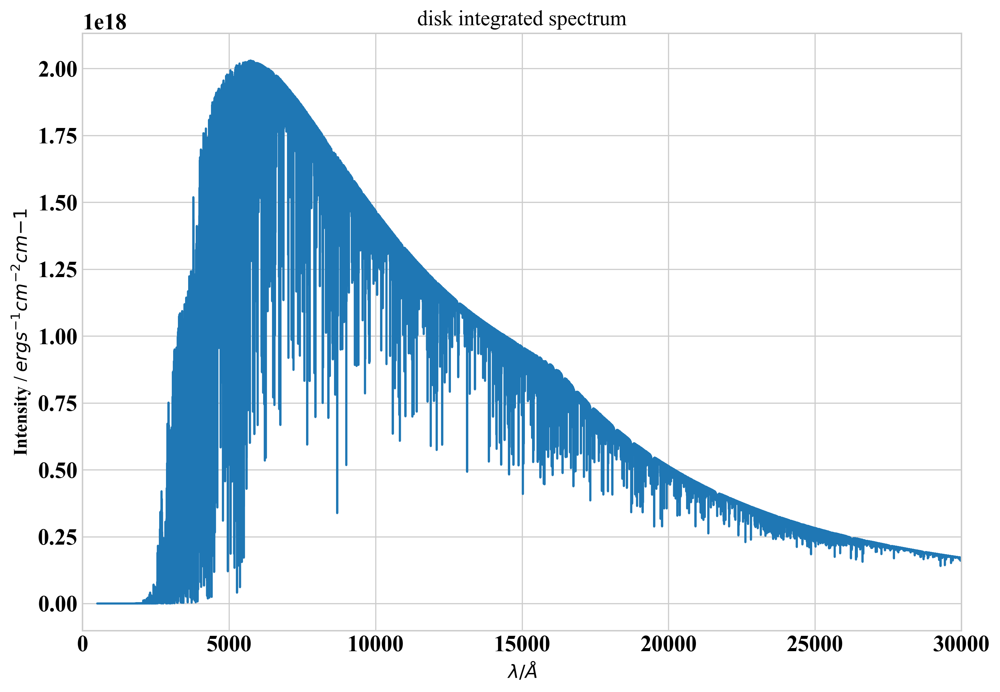

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


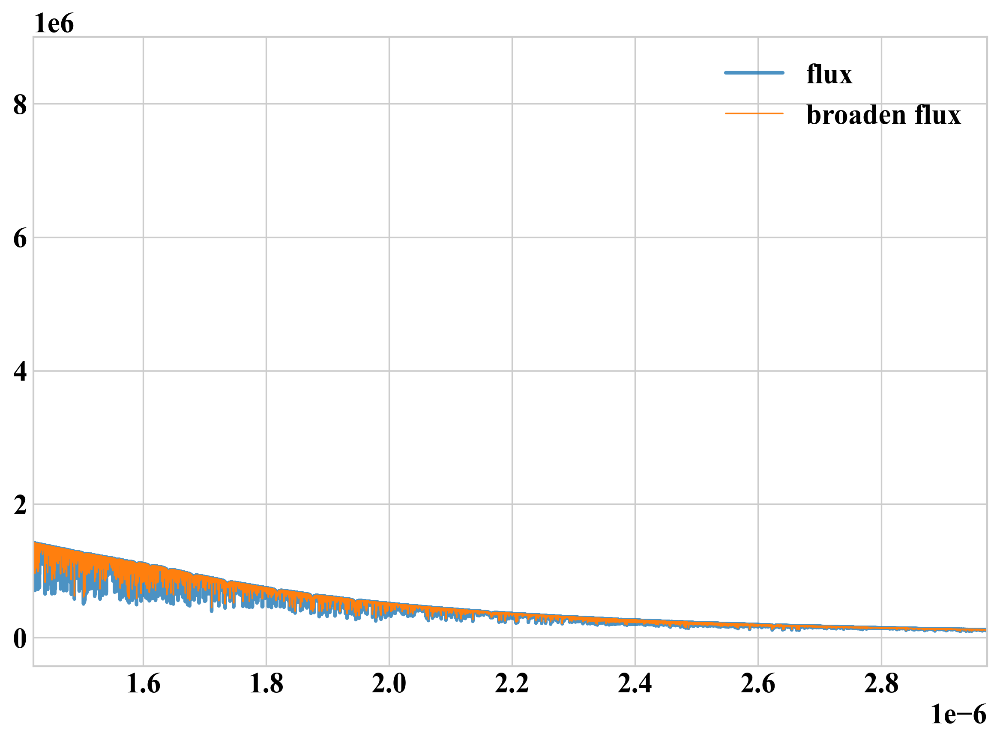

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 9.322143729767303 370882.36960508156 0.0001866992219578533
The star spectrum already exists, skipping download


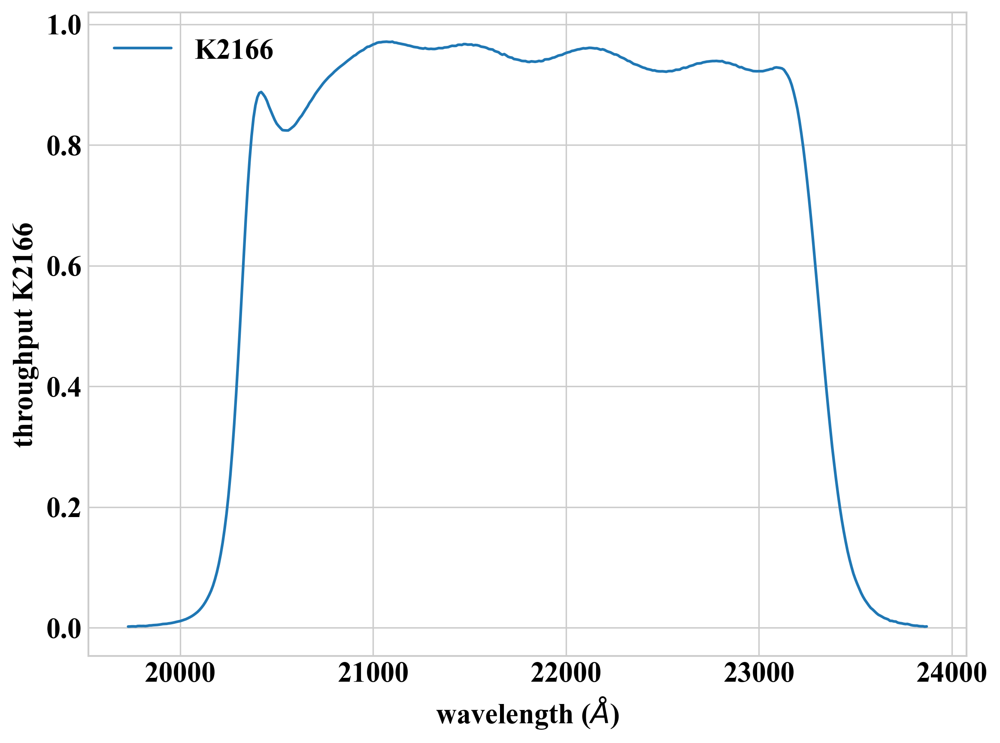

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at K2166 band [0.2668]


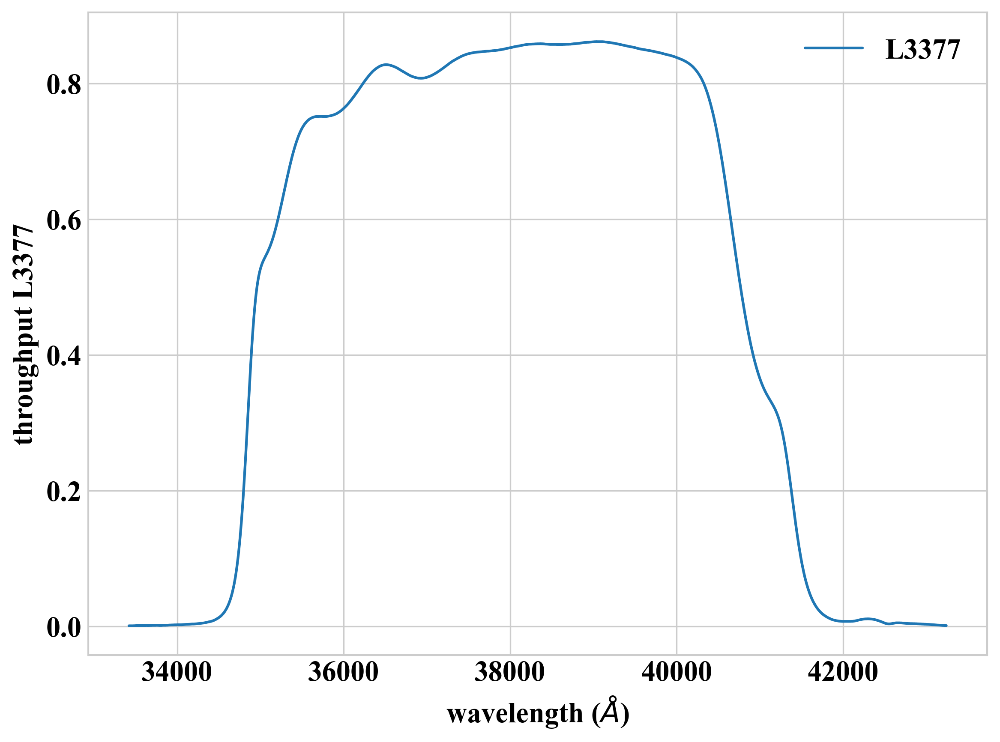

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3377 band [0.18]


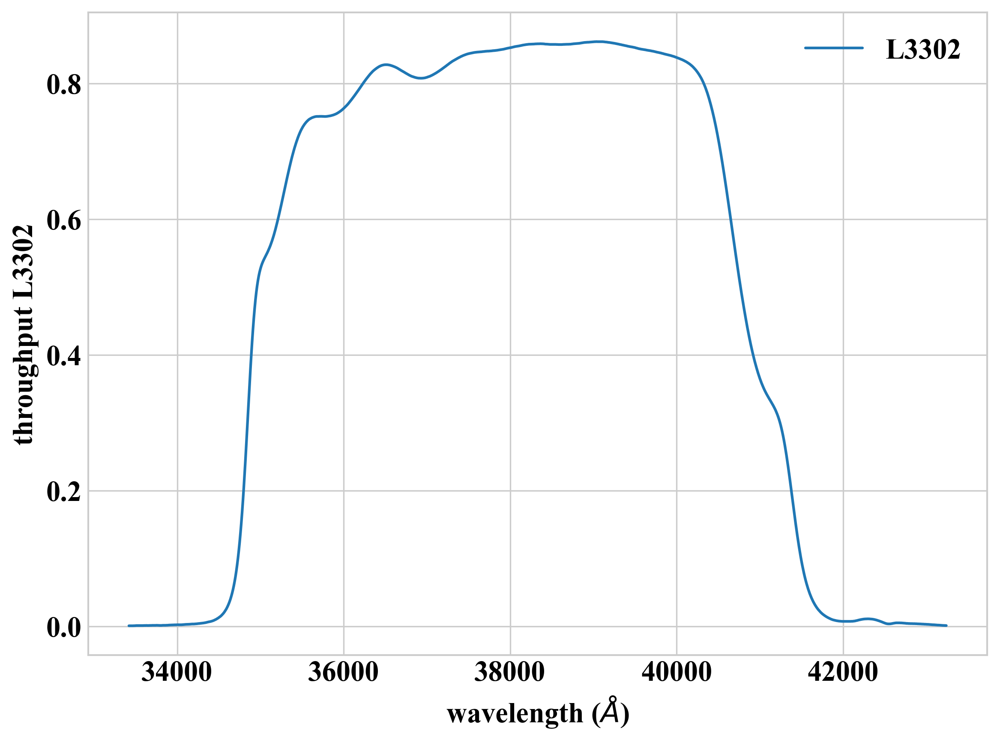

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3302 band [0.181]


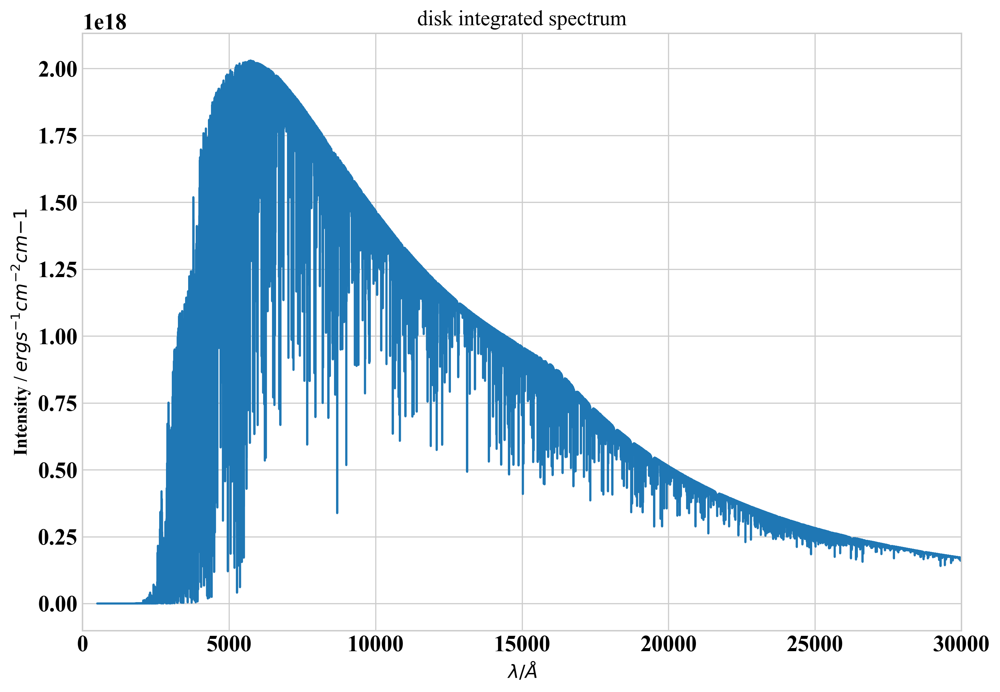

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


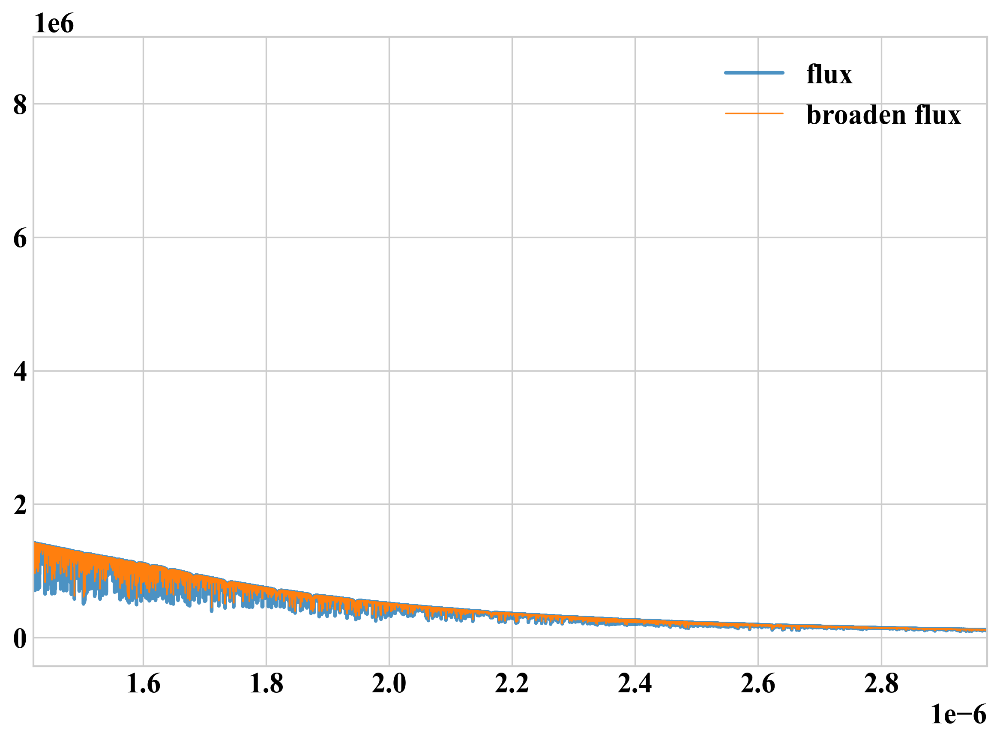

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 9.297881215795242 370882.36960508156 0.00019091828024979314
The star spectrum already exists, skipping download


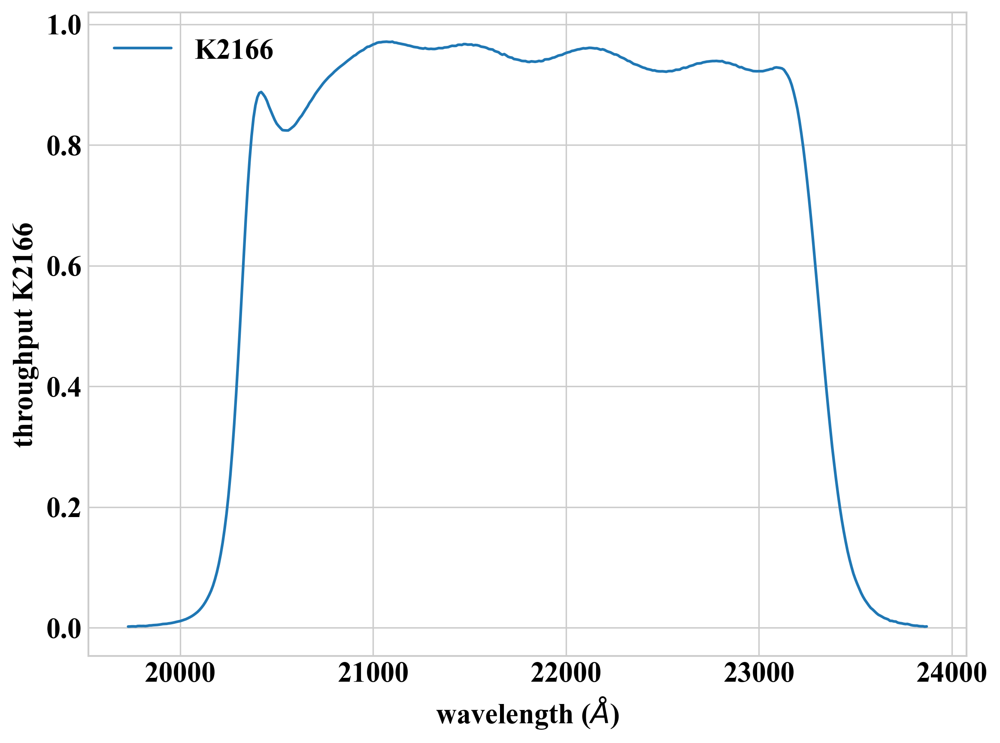

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at K2166 band [0.2668]


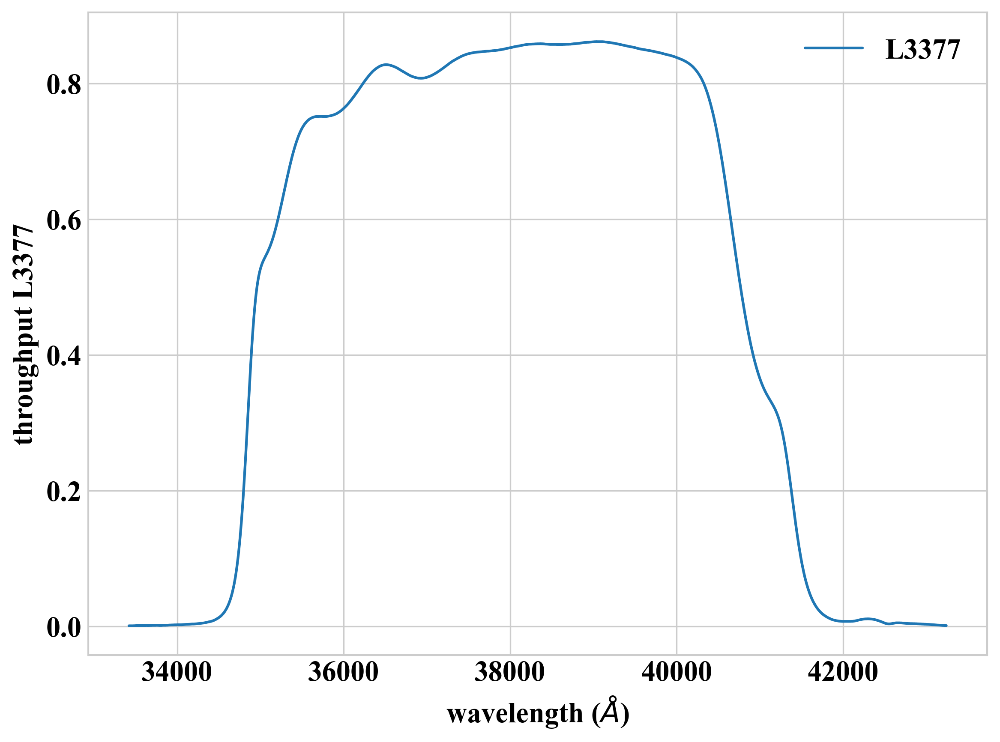

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3377 band [0.18]


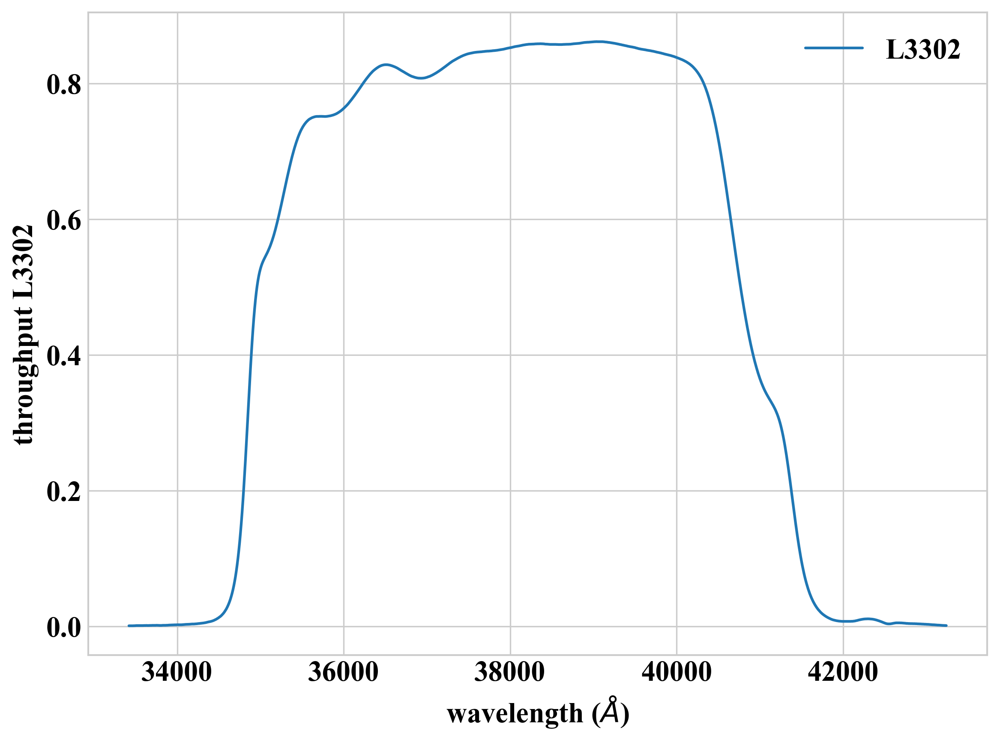

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3302 band [0.181]


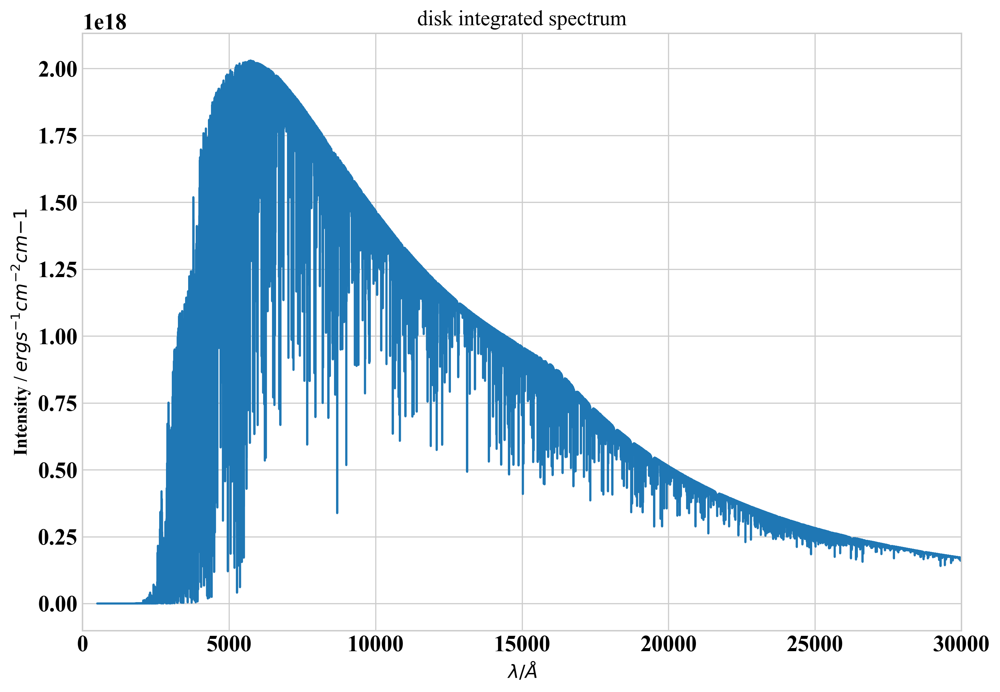

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


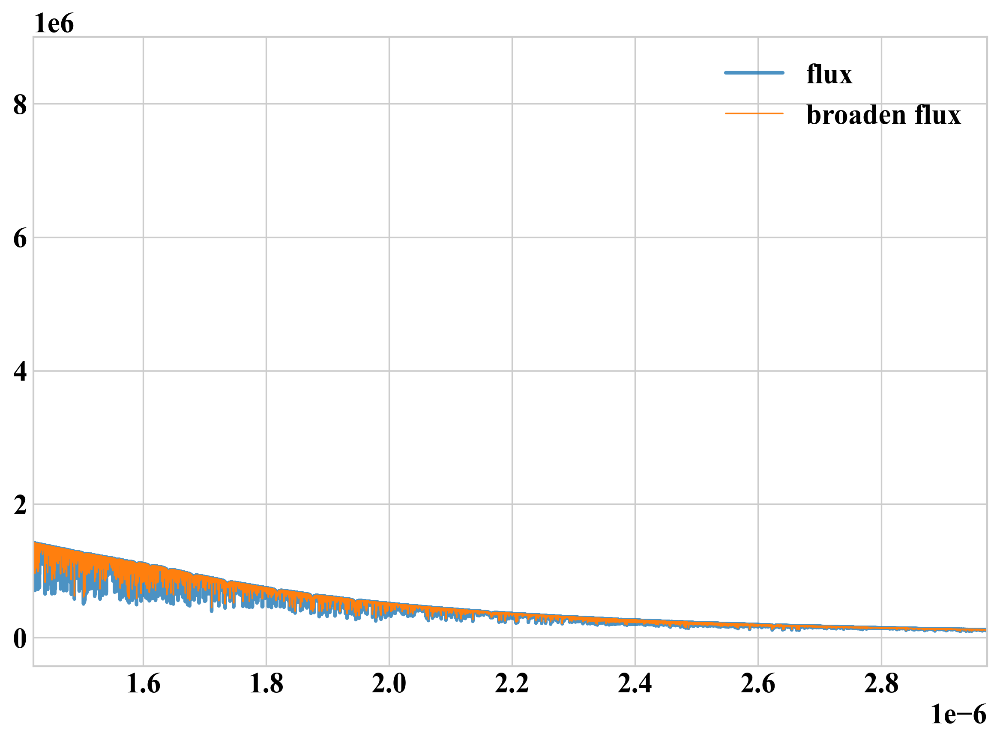

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 9.297881215795242 370882.36960508156 0.00019091828024979314
The star spectrum already exists, skipping download


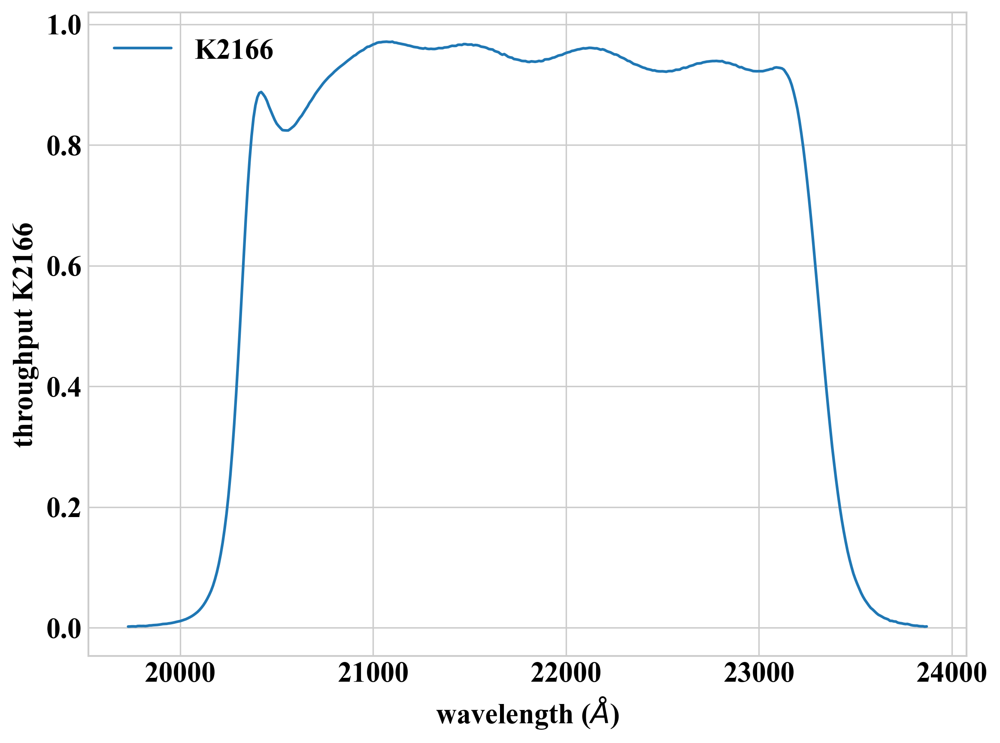

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at K2166 band [0.2668]


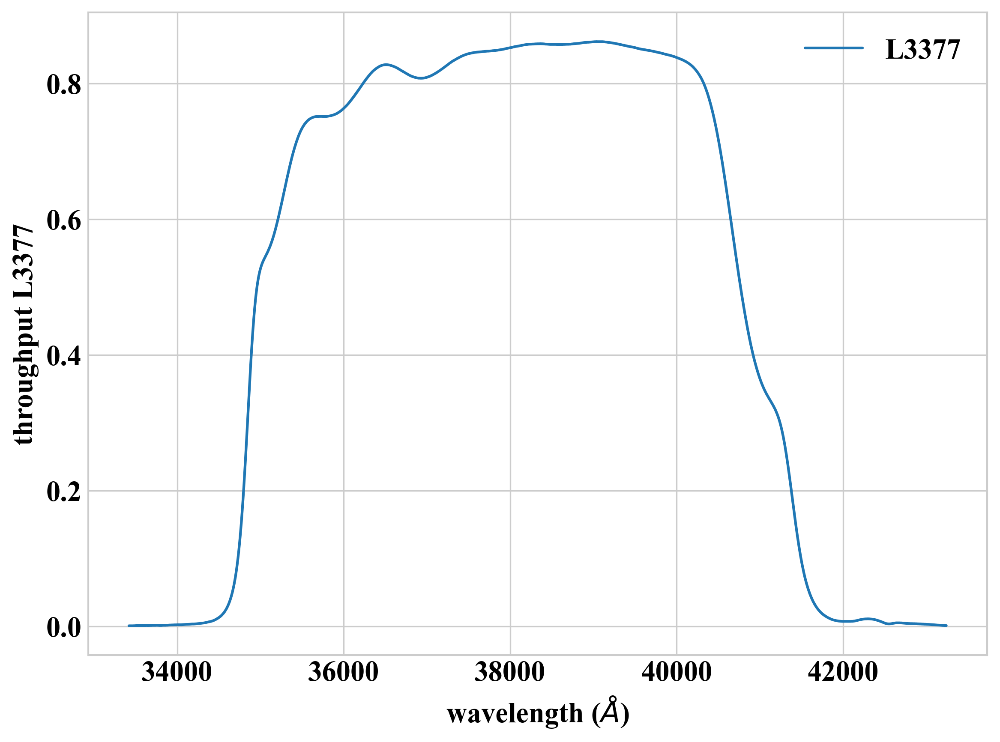

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3377 band [0.18]


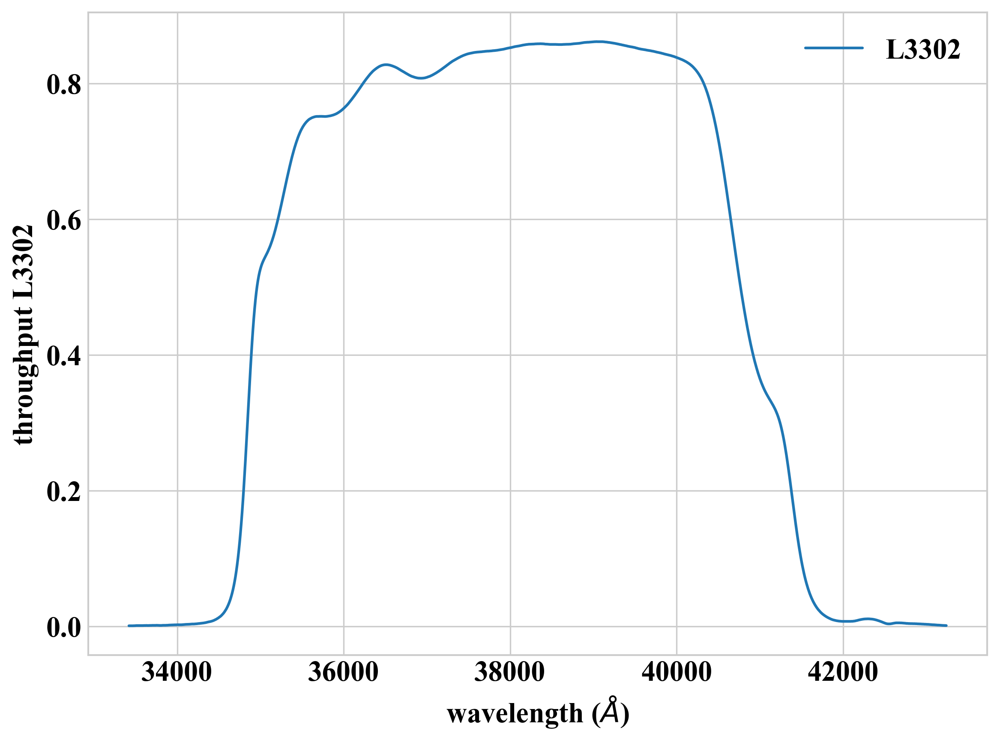

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3302 band [0.181]


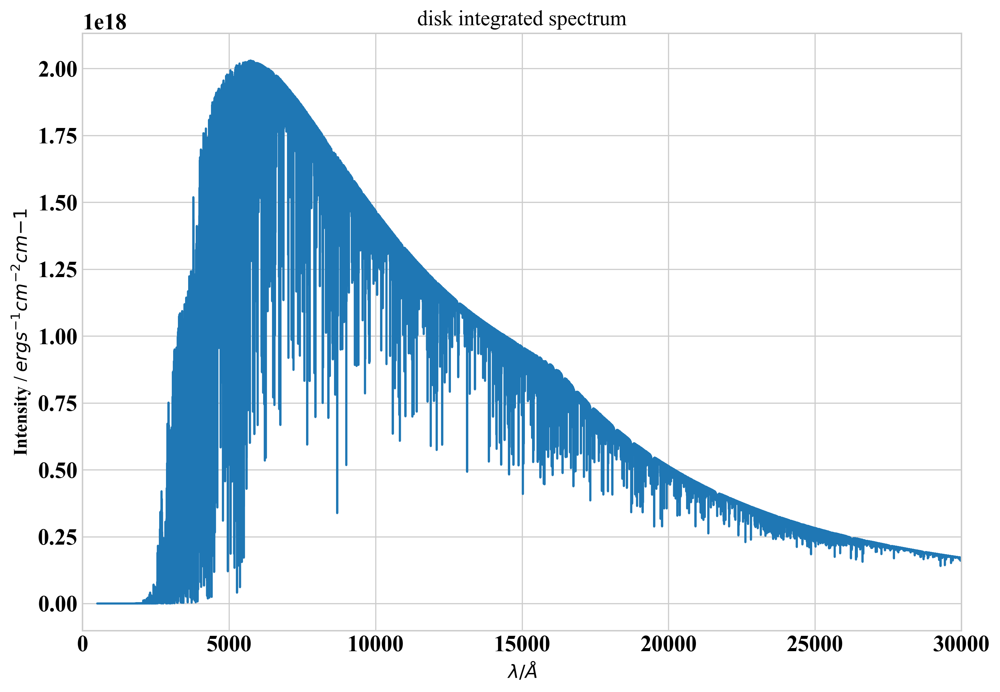

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


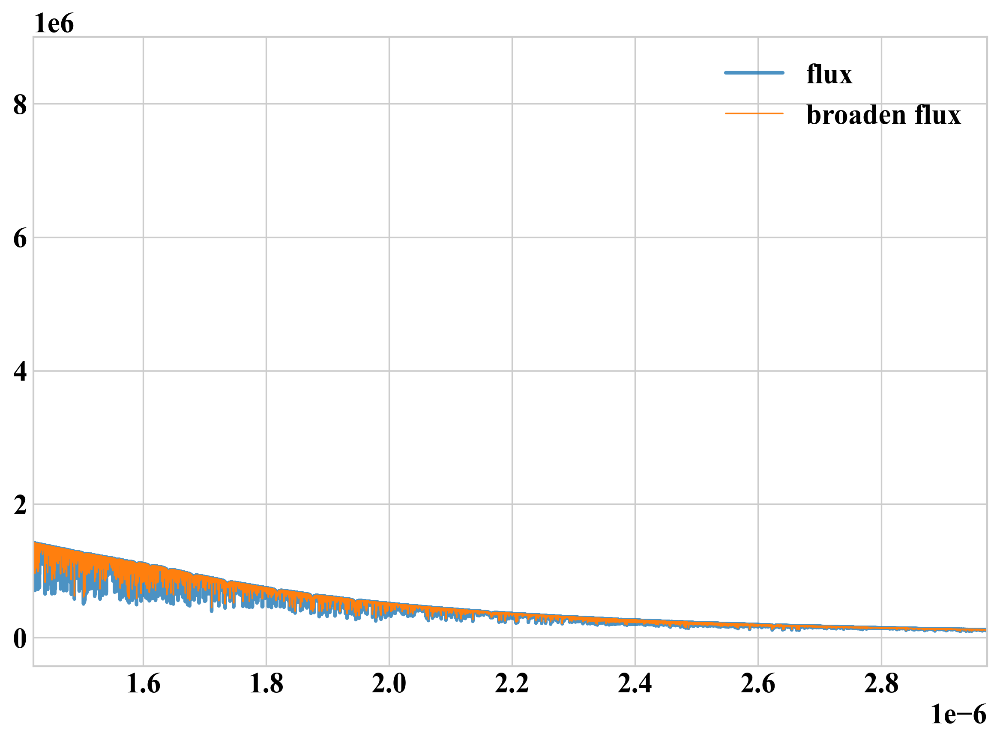

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 9.297881215795242 370882.36960508156 0.00019091828024979314
The star spectrum already exists, skipping download


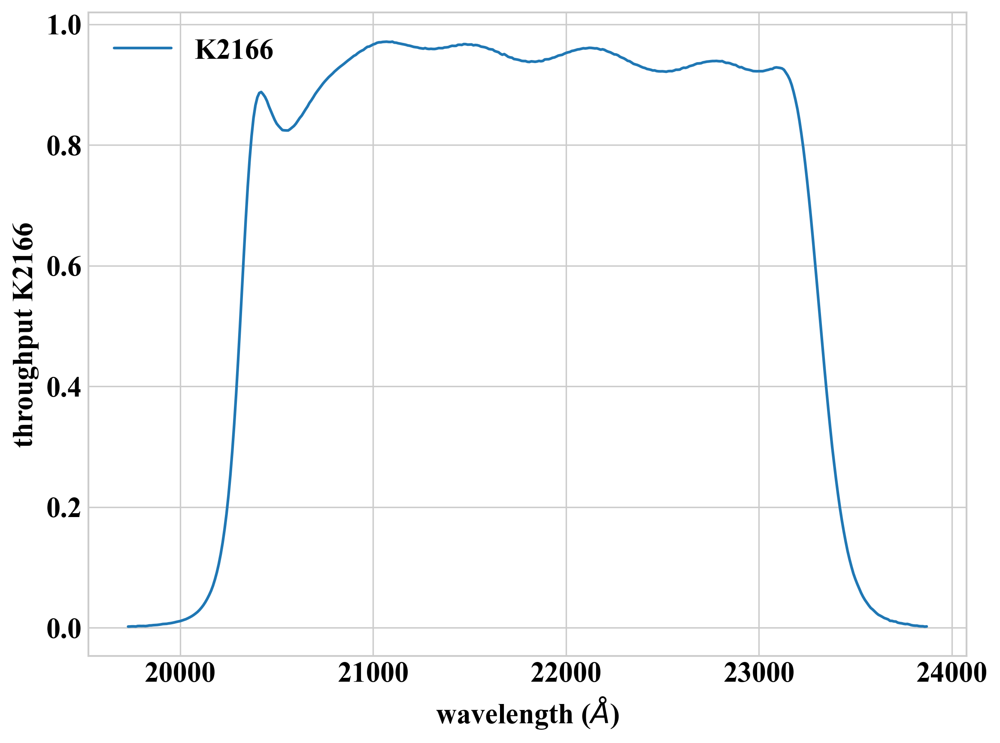

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at K2166 band [0.2668]


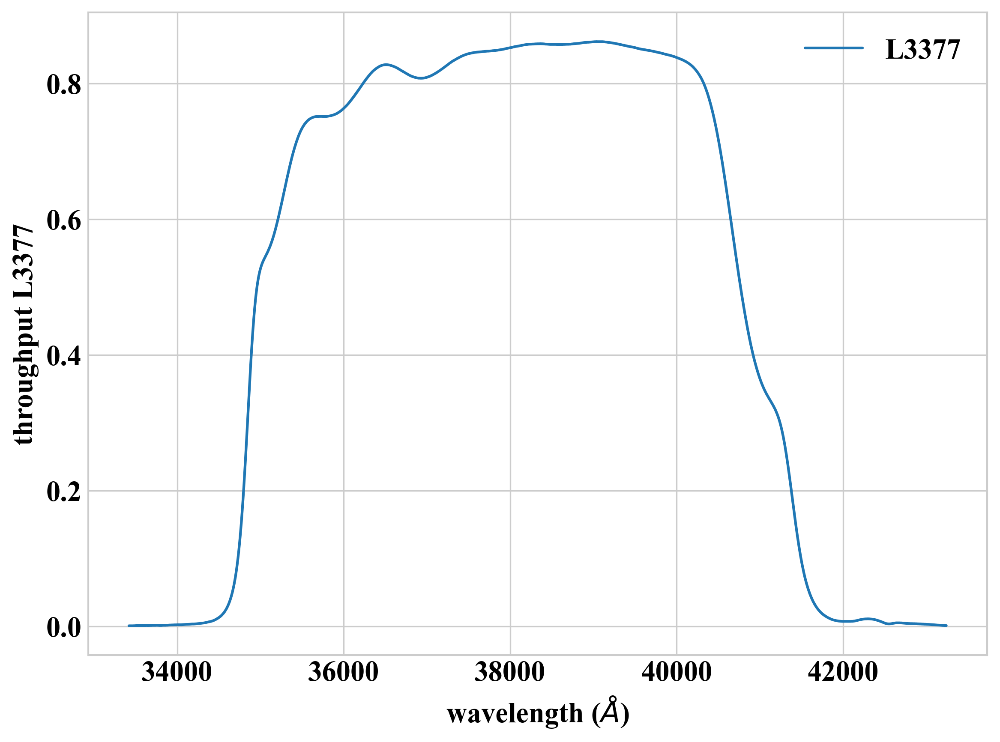

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3377 band [0.18]


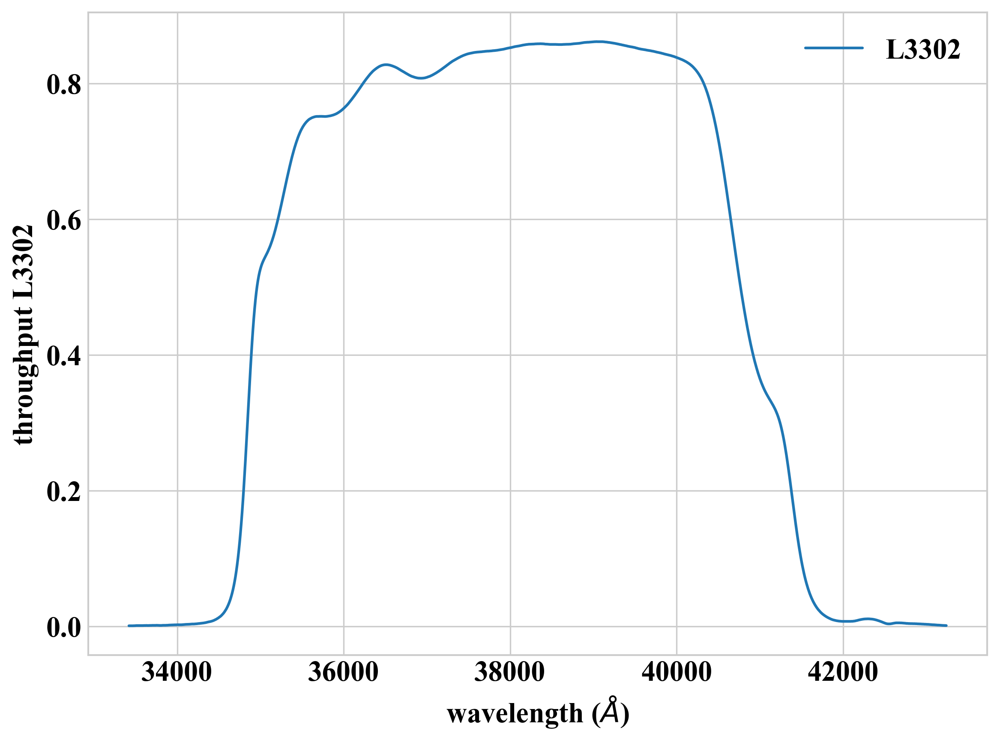

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3302 band [0.181]


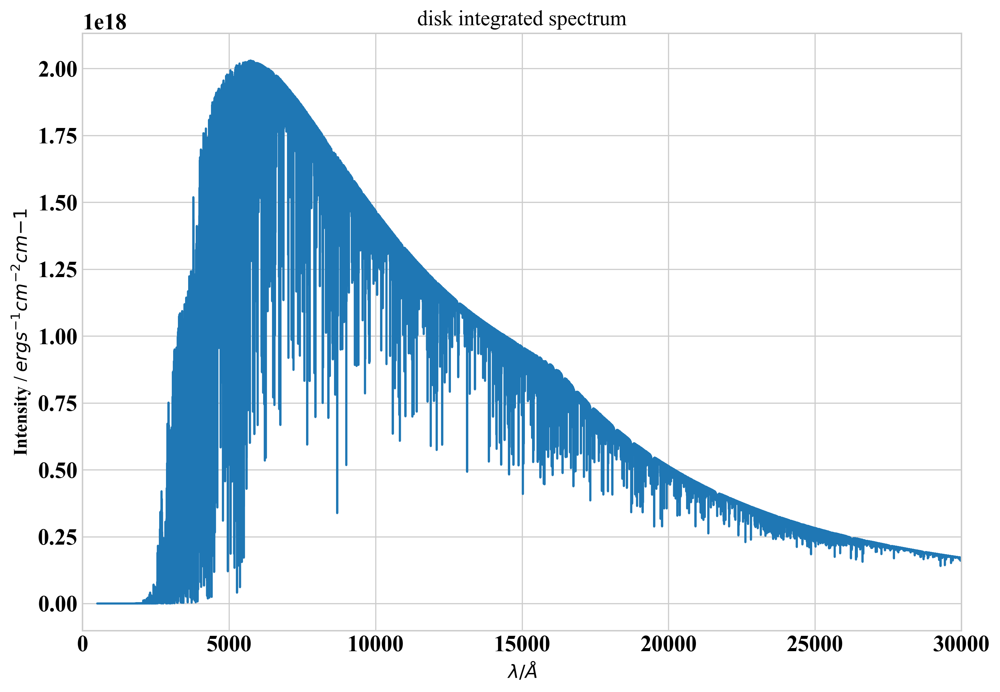

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


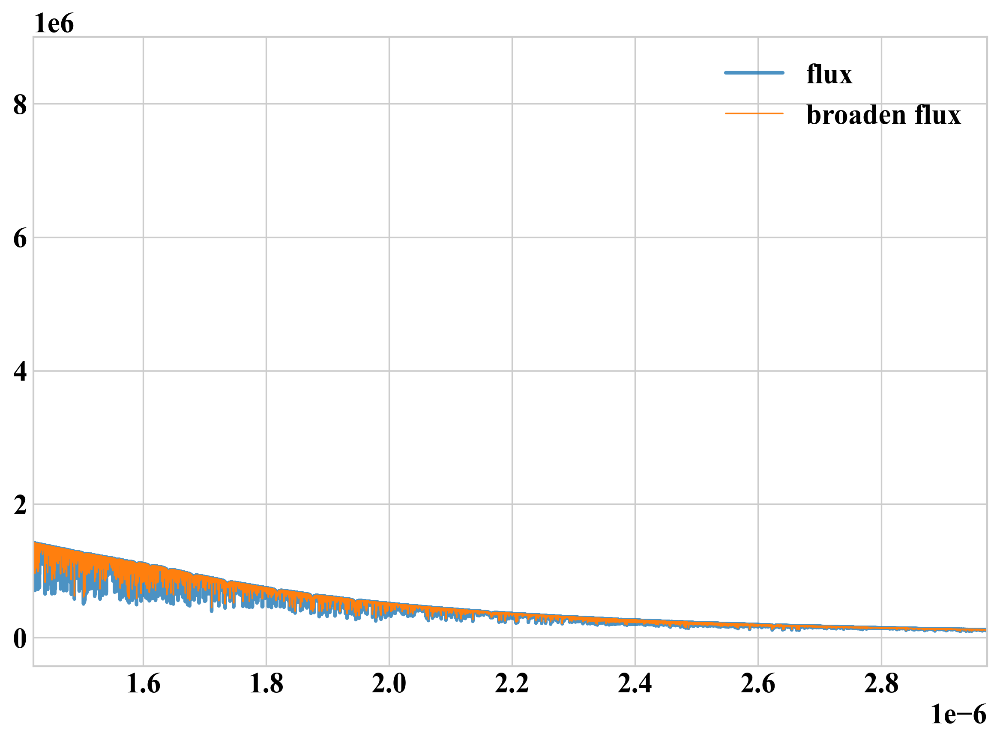

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 9.297881215795242 370882.36960508156 0.00019091828024979314
The star spectrum already exists, skipping download


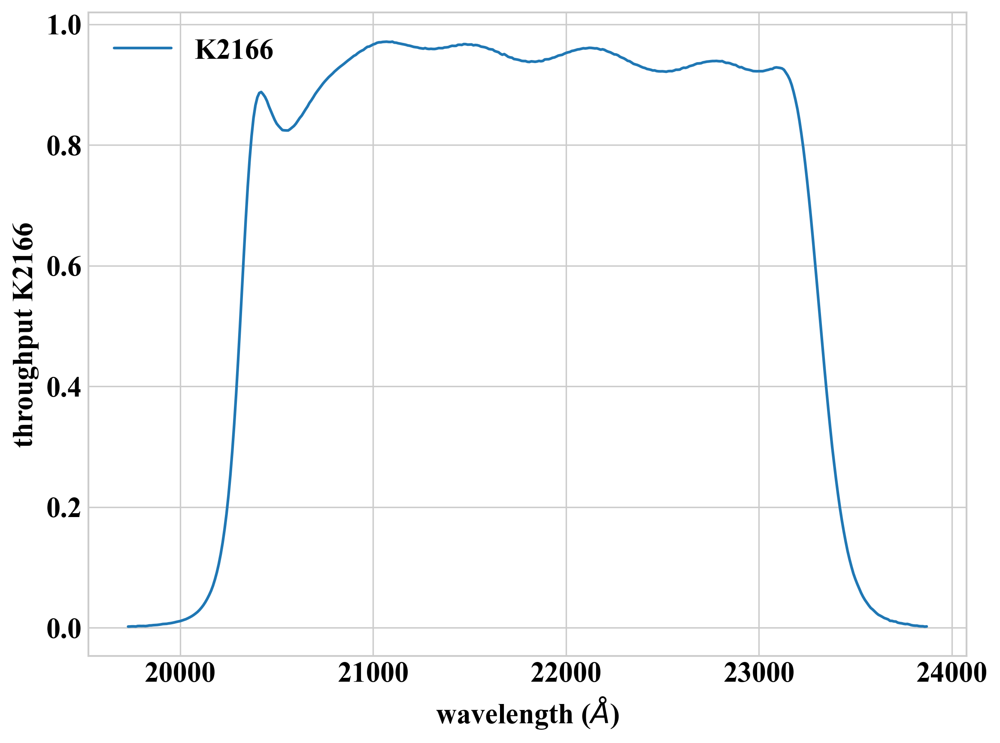

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at K2166 band [0.2668]


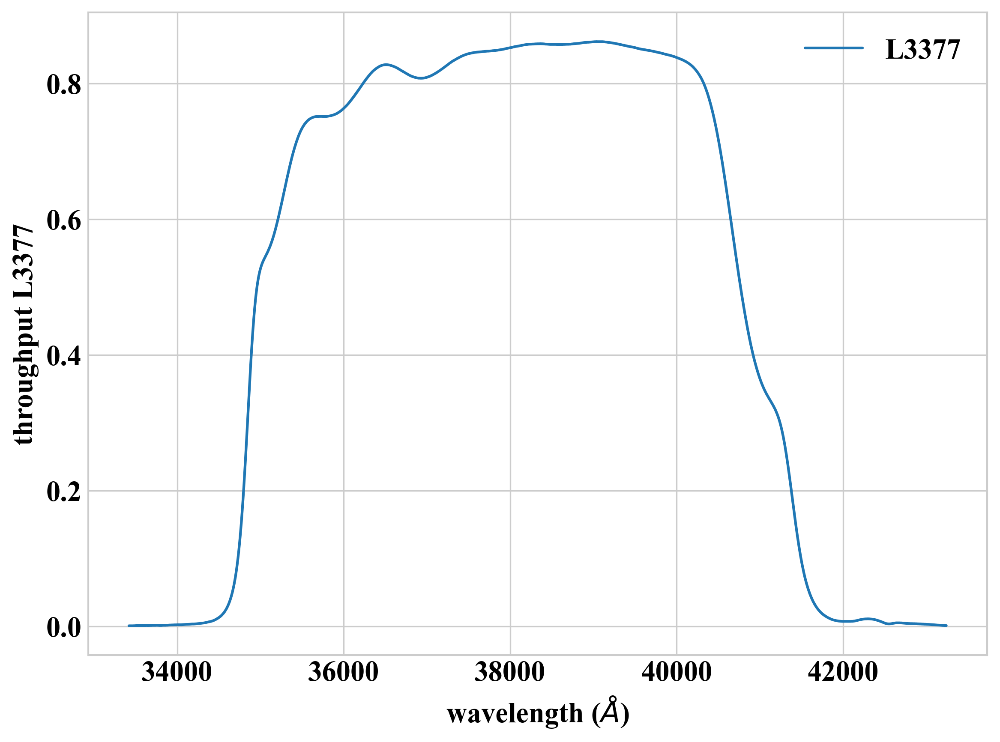

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3377 band [0.18]


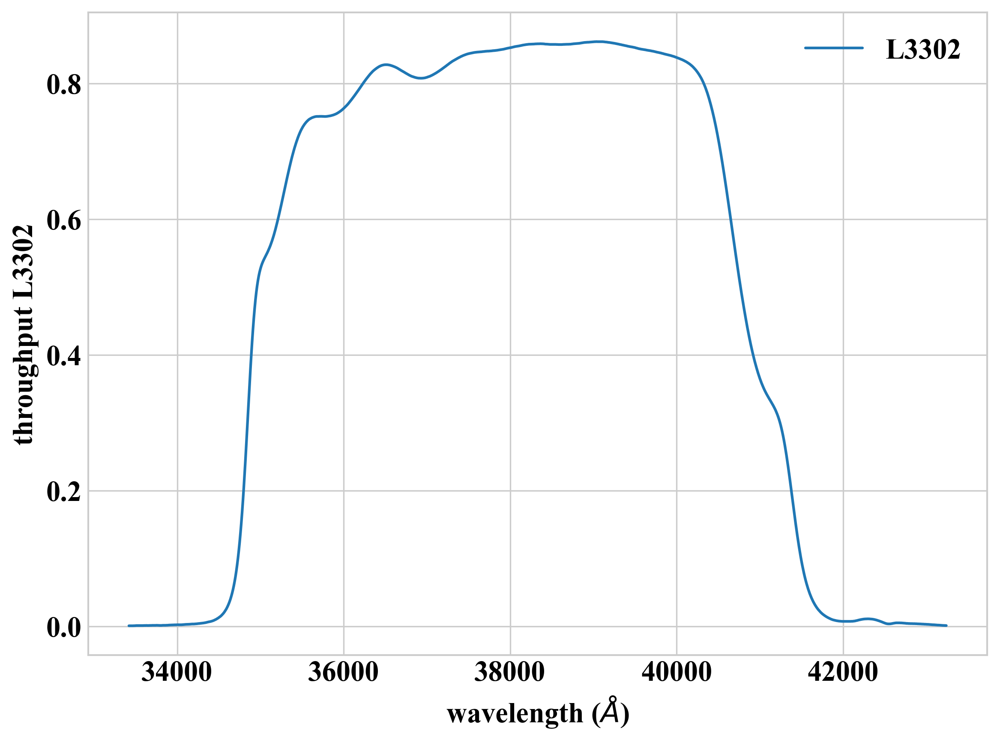

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3302 band [0.181]


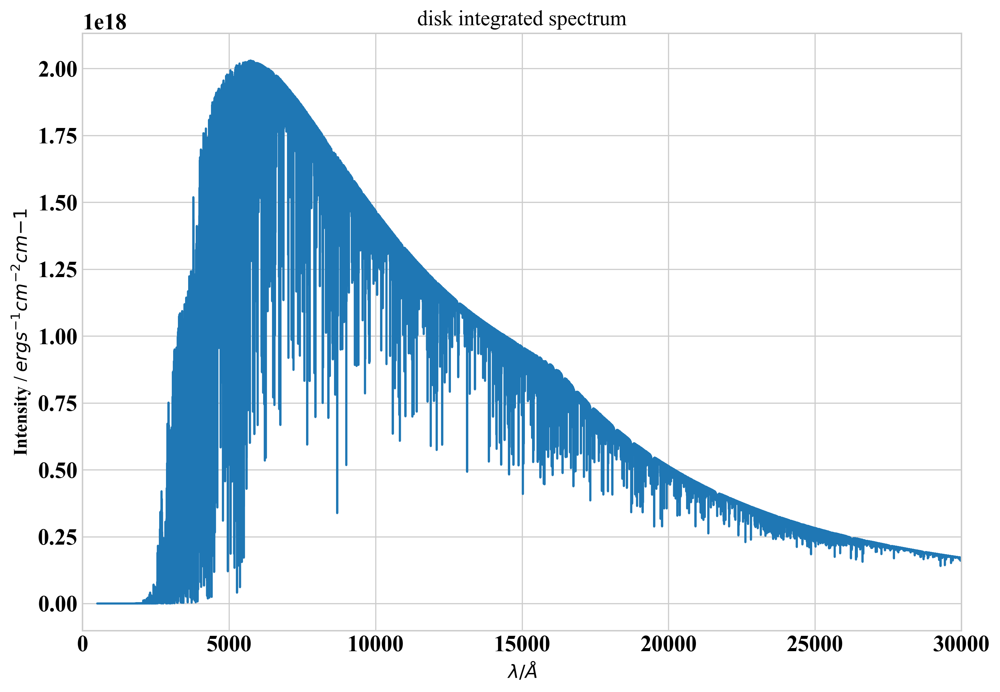

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


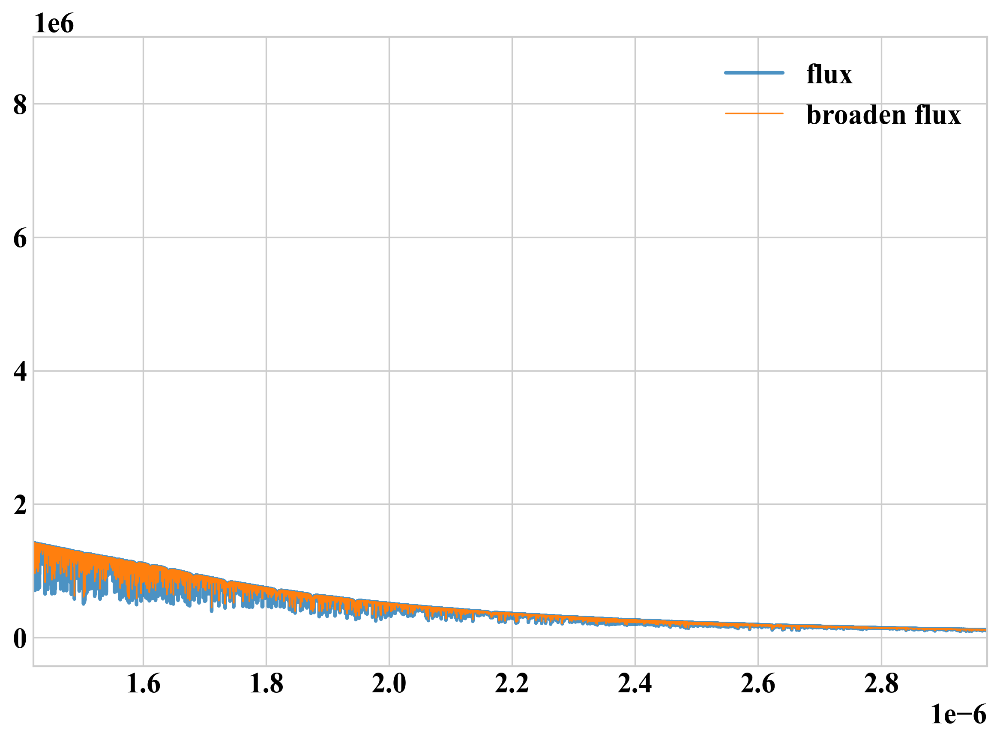

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 9.297881215795242 370882.36960508156 0.00019091828024979314
The star spectrum already exists, skipping download


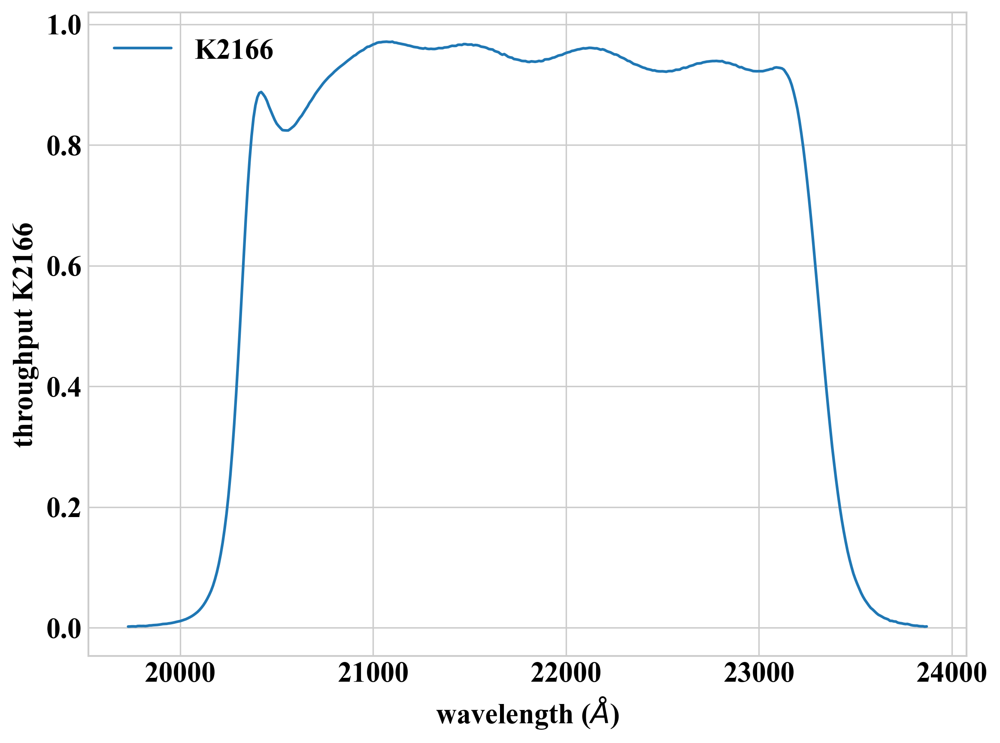

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at K2166 band [0.2668]


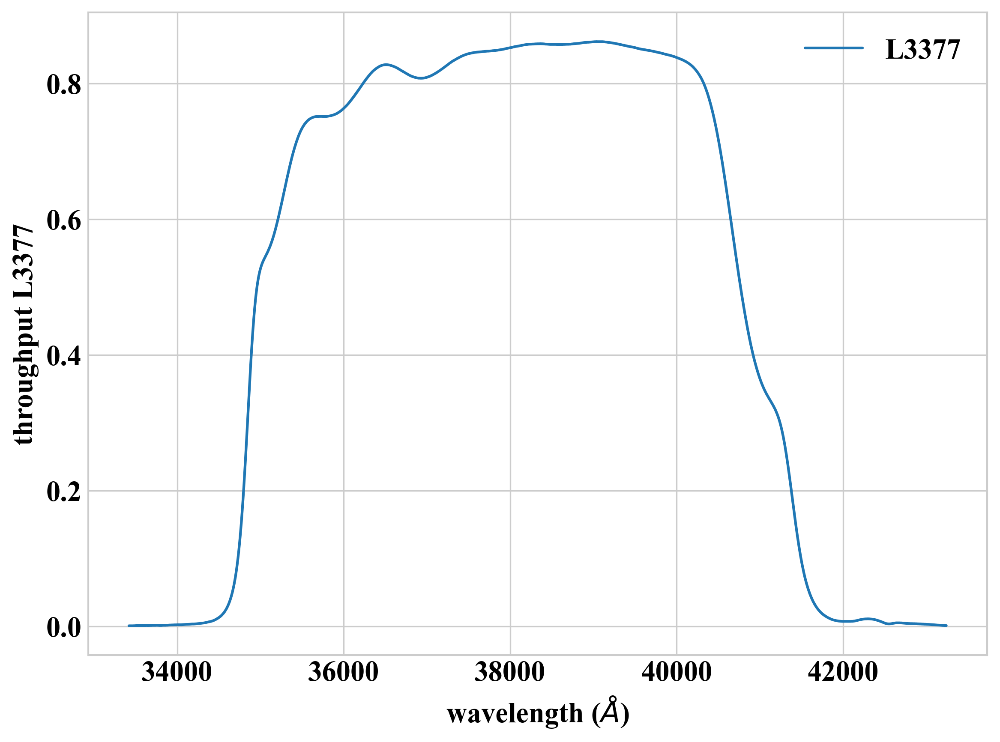

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3377 band [0.18]


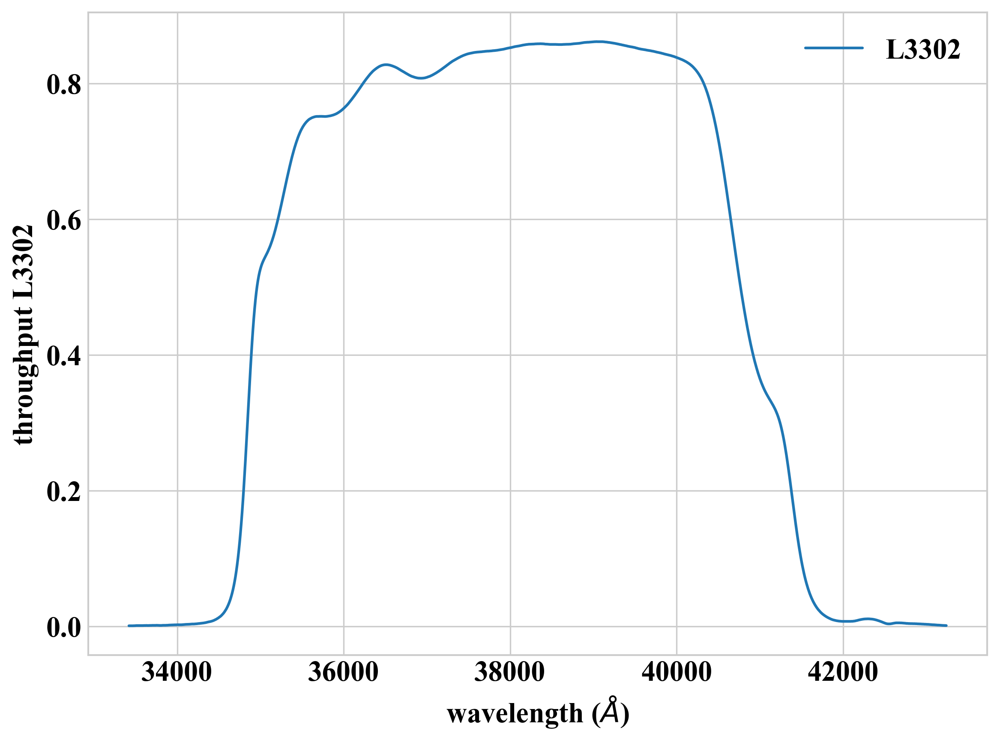

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3302 band [0.181]


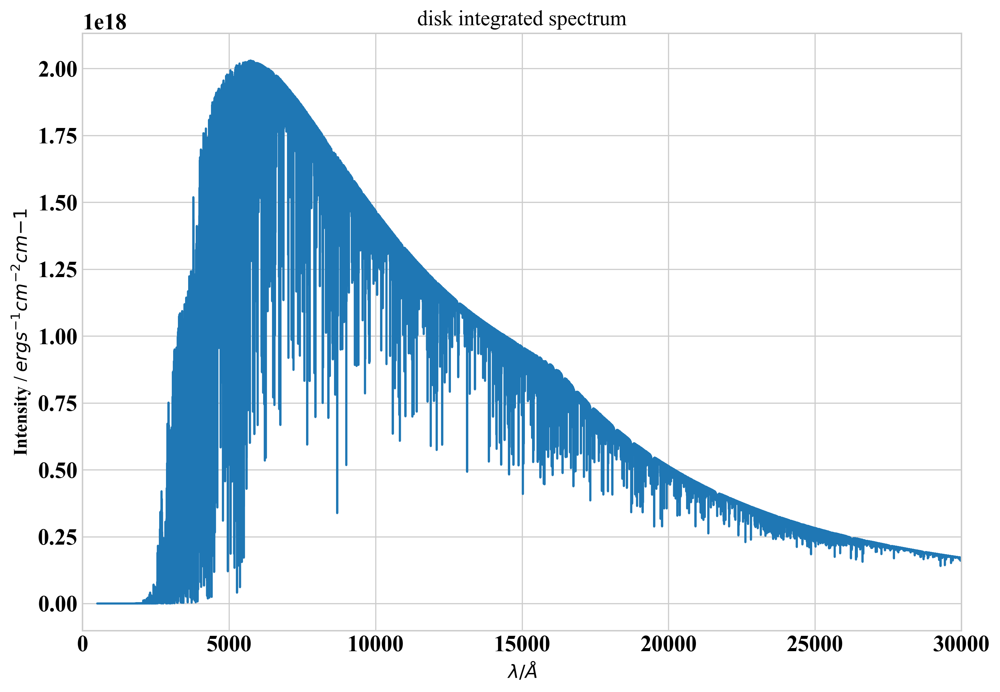

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


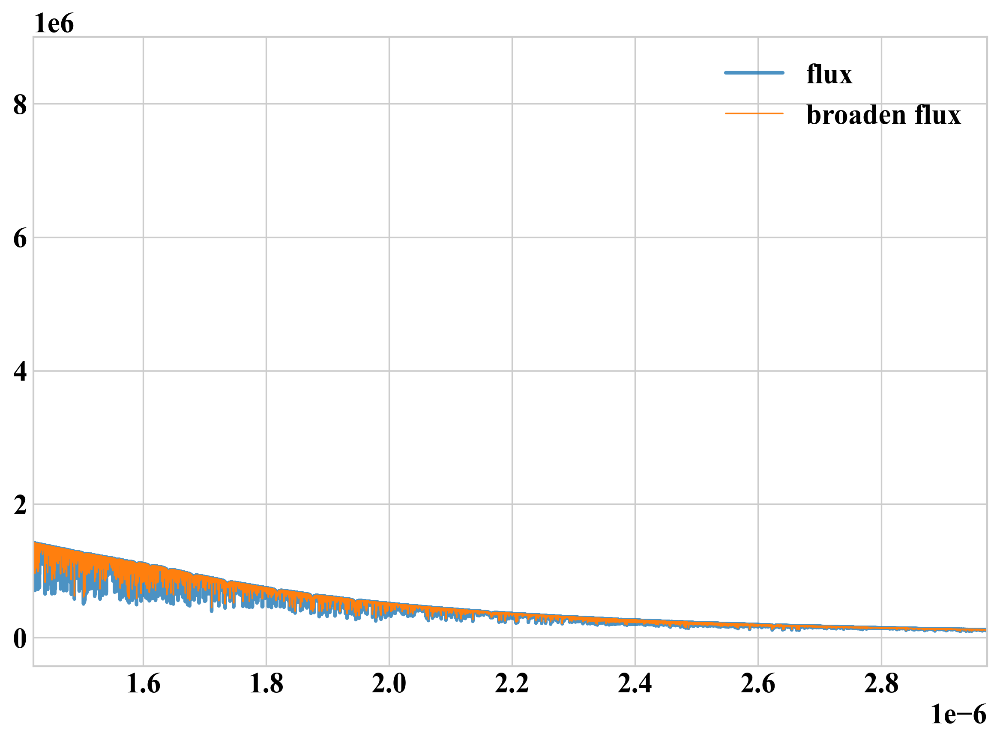

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 9.297881215795242 370882.36960508156 0.00019091828024979314
The star spectrum already exists, skipping download


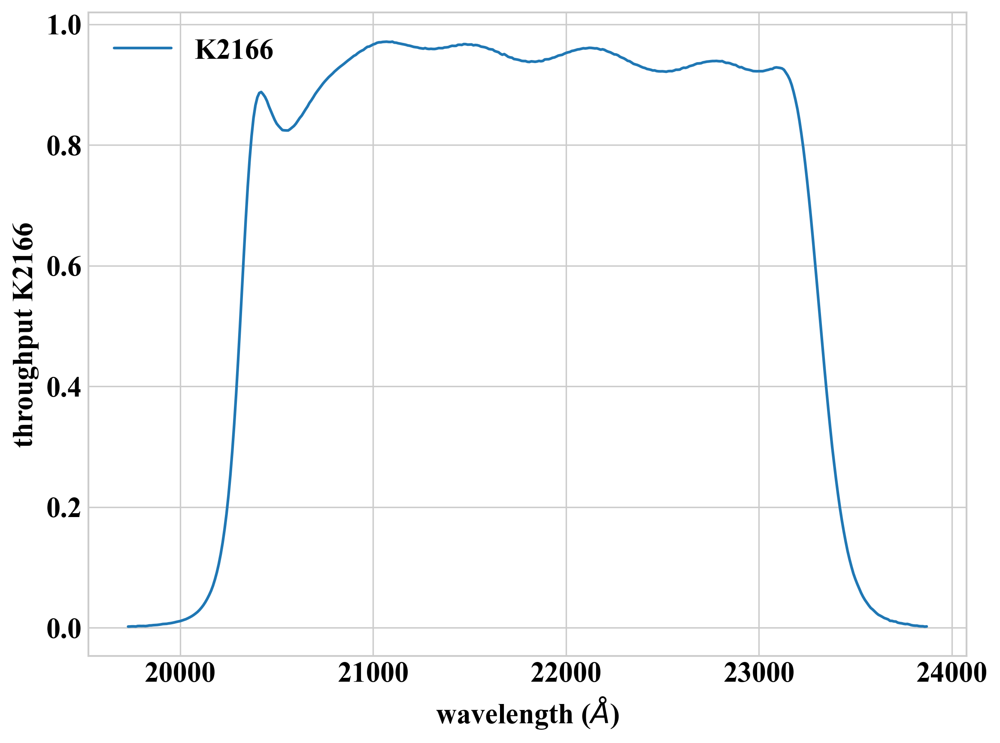

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at K2166 band [0.2668]


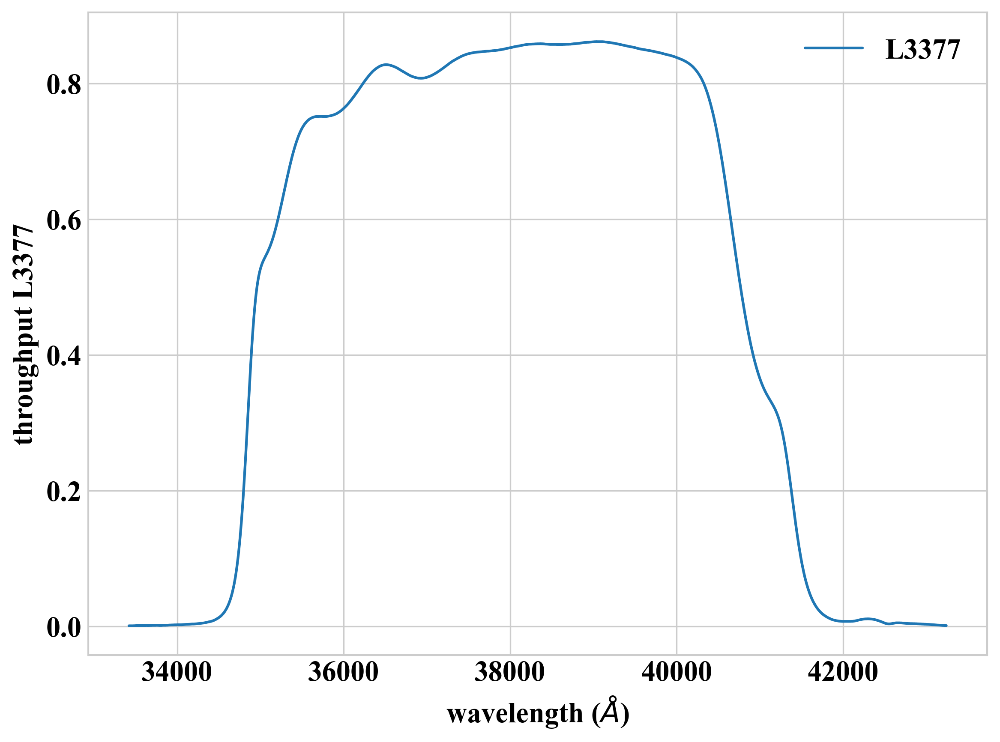

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3377 band [0.18]


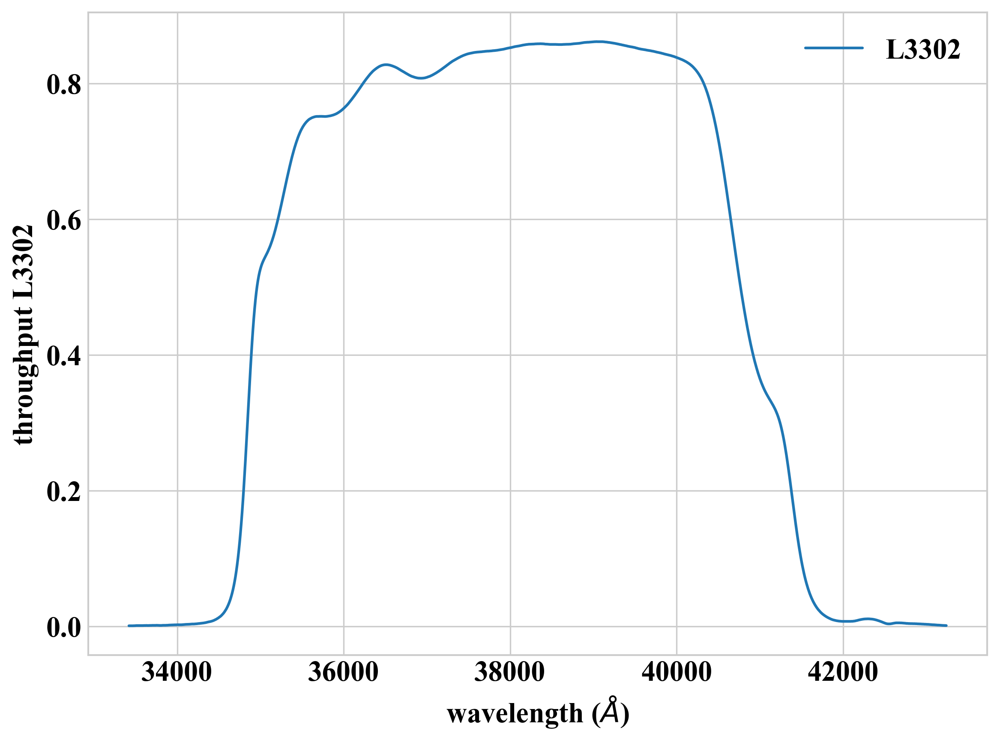

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3302 band [0.181]


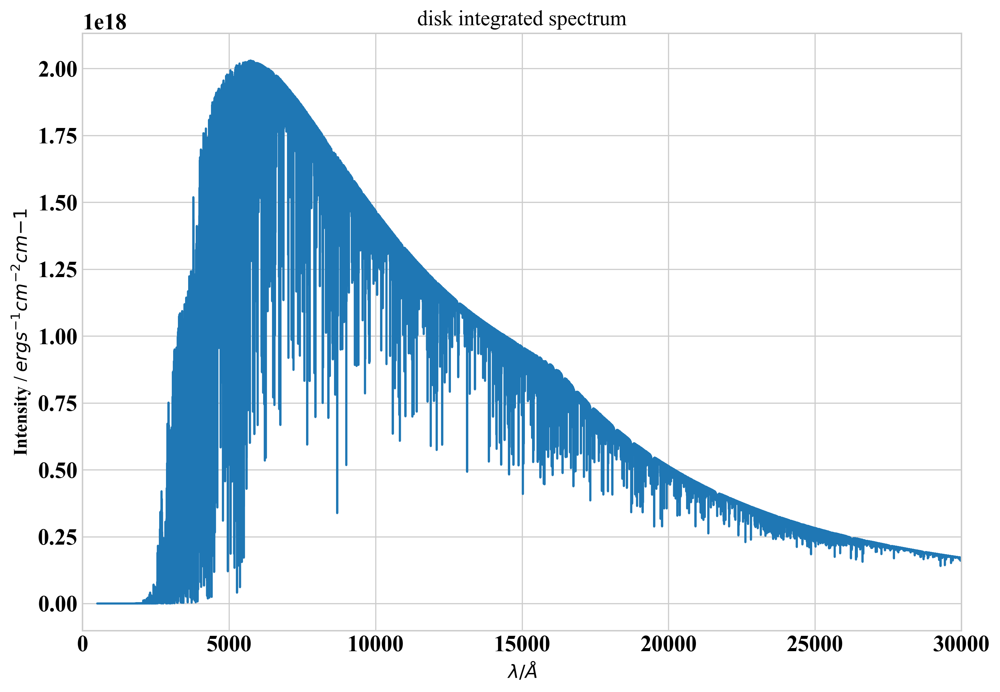

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


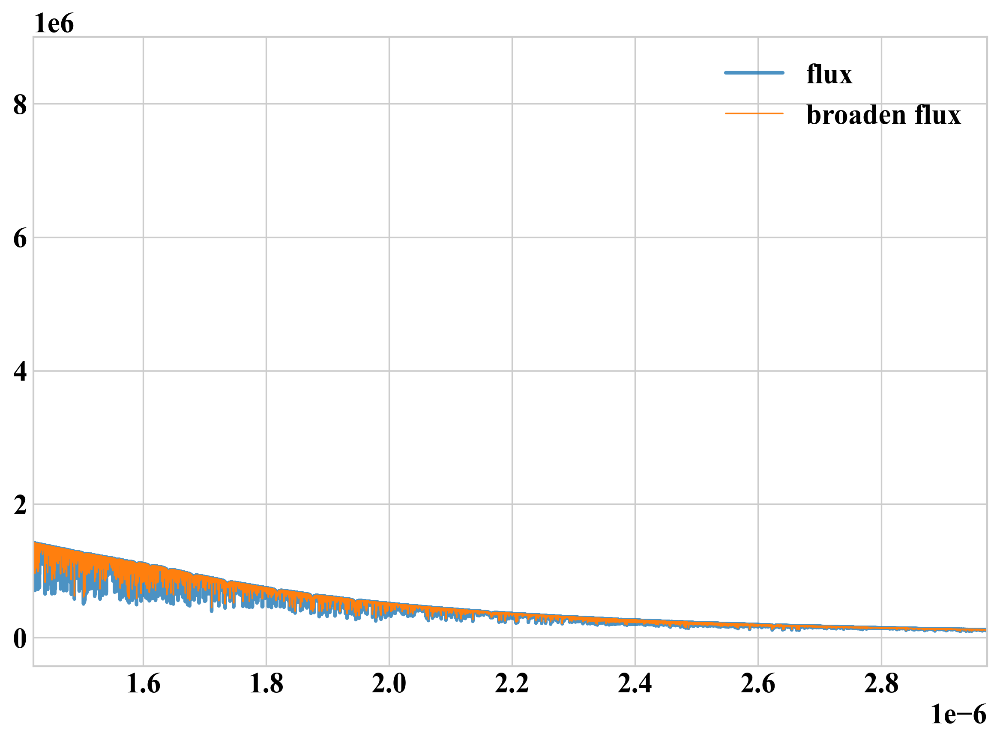

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 9.297881215795242 370882.36960508156 0.00019091828024979314
The star spectrum already exists, skipping download


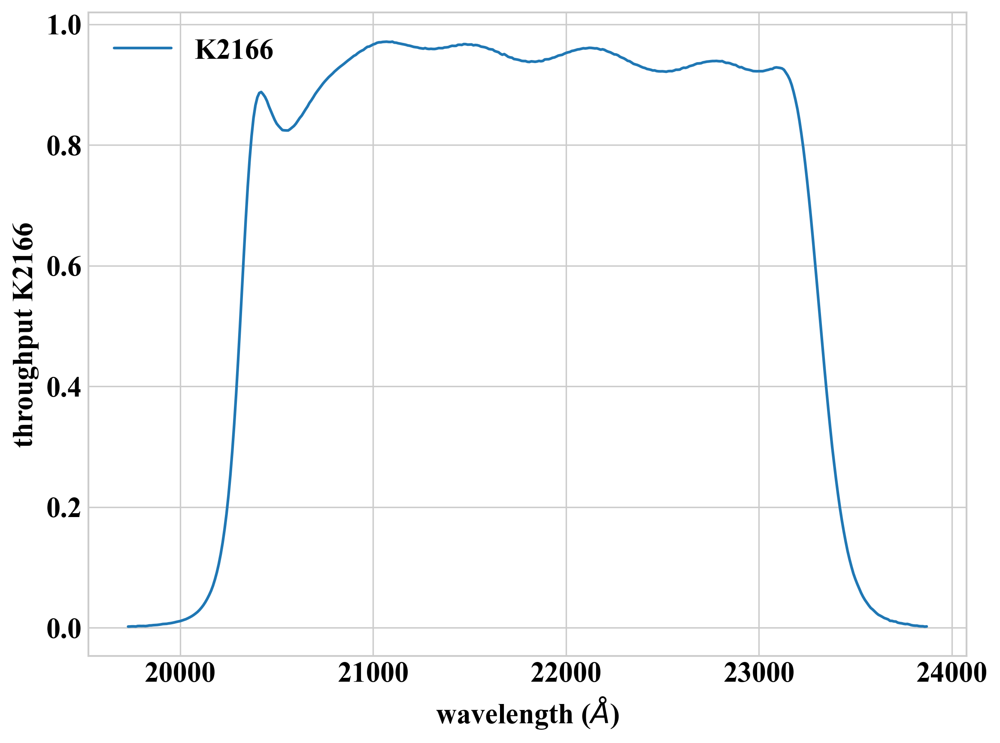

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at K2166 band [0.2668]


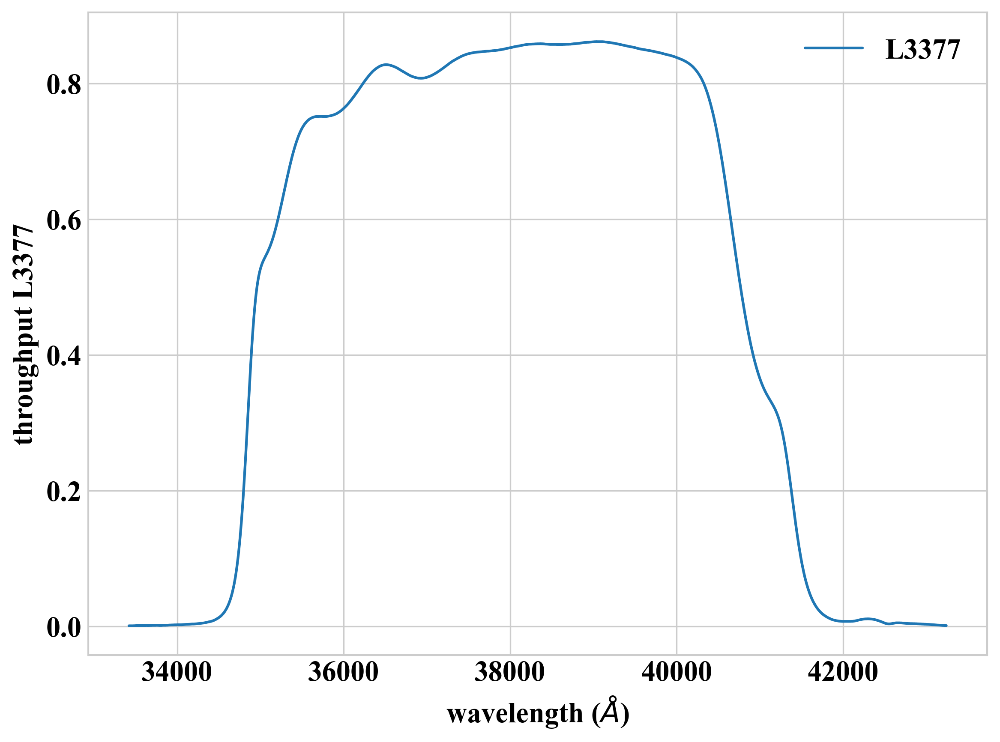

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3377 band [0.18]


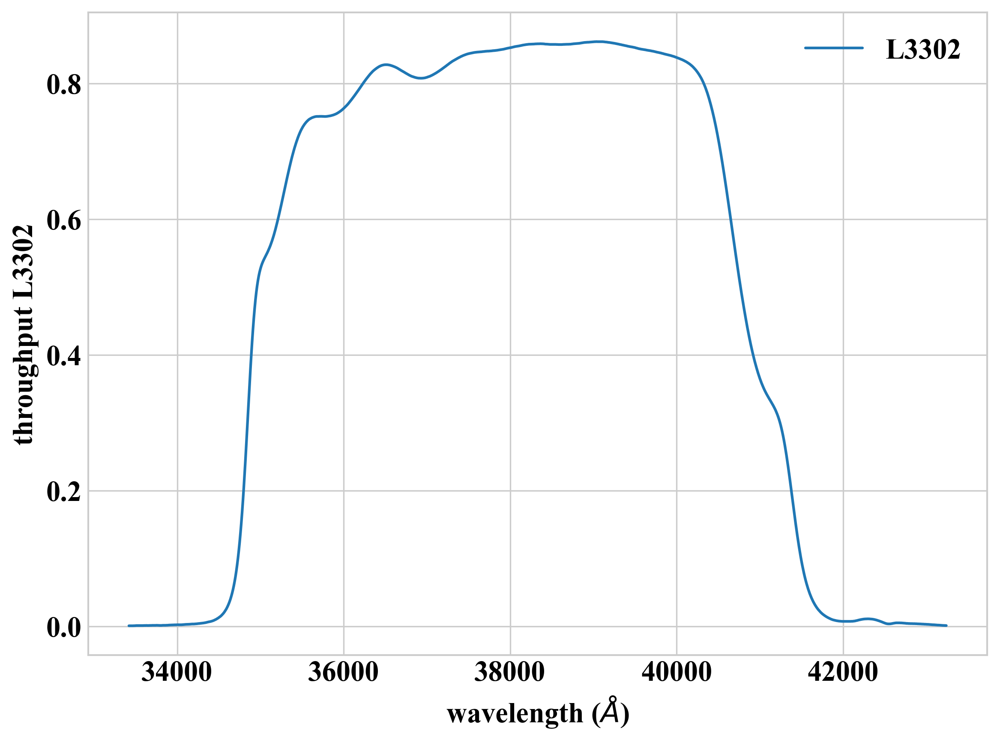

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3302 band [0.181]


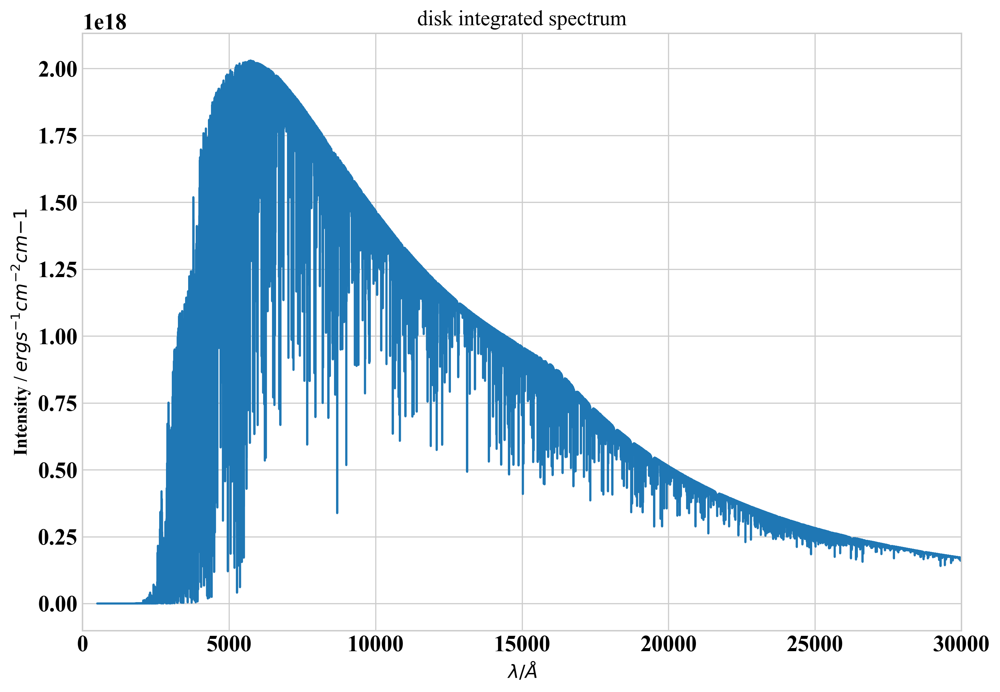

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


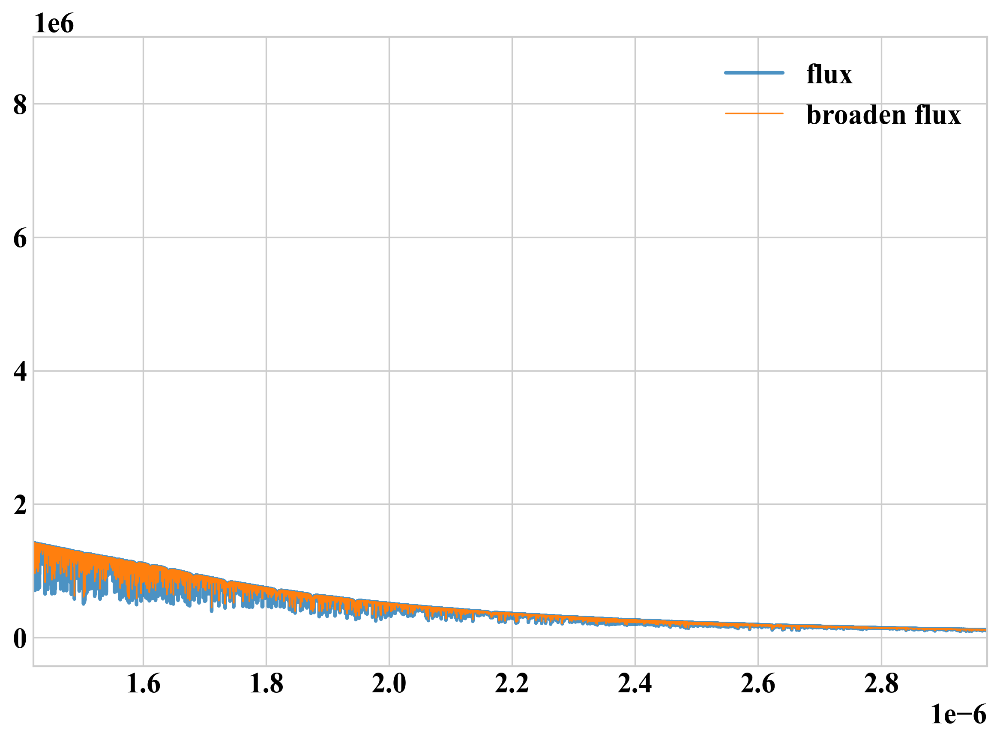

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 9.297881215795242 370882.36960508156 0.00019091828024979314
The star spectrum already exists, skipping download


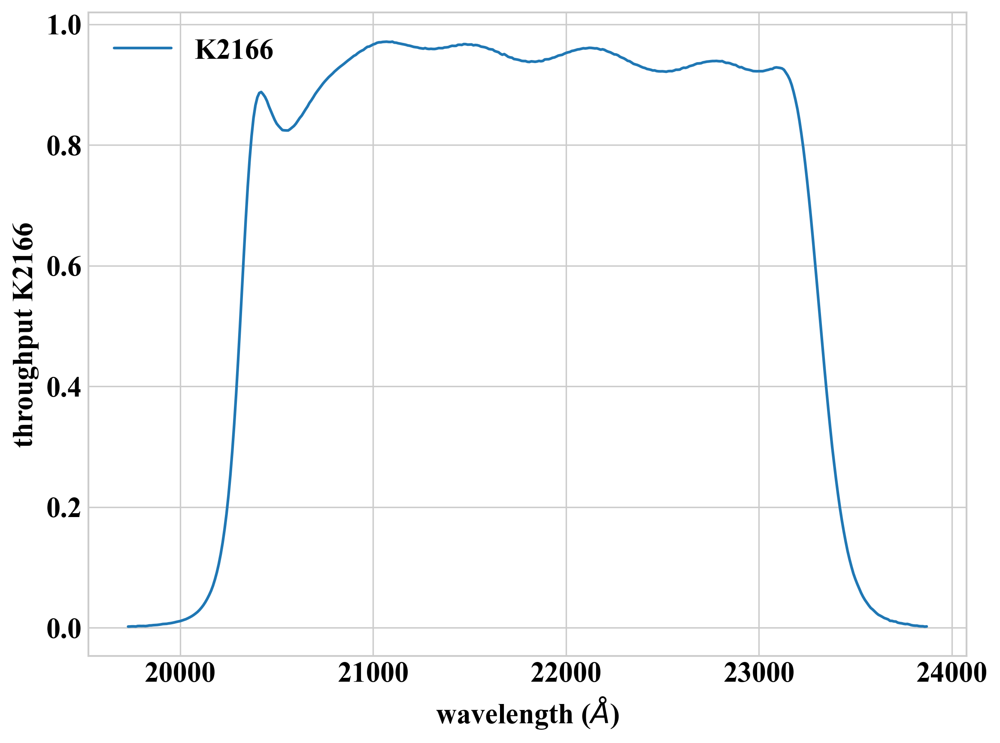

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at K2166 band [0.2668]


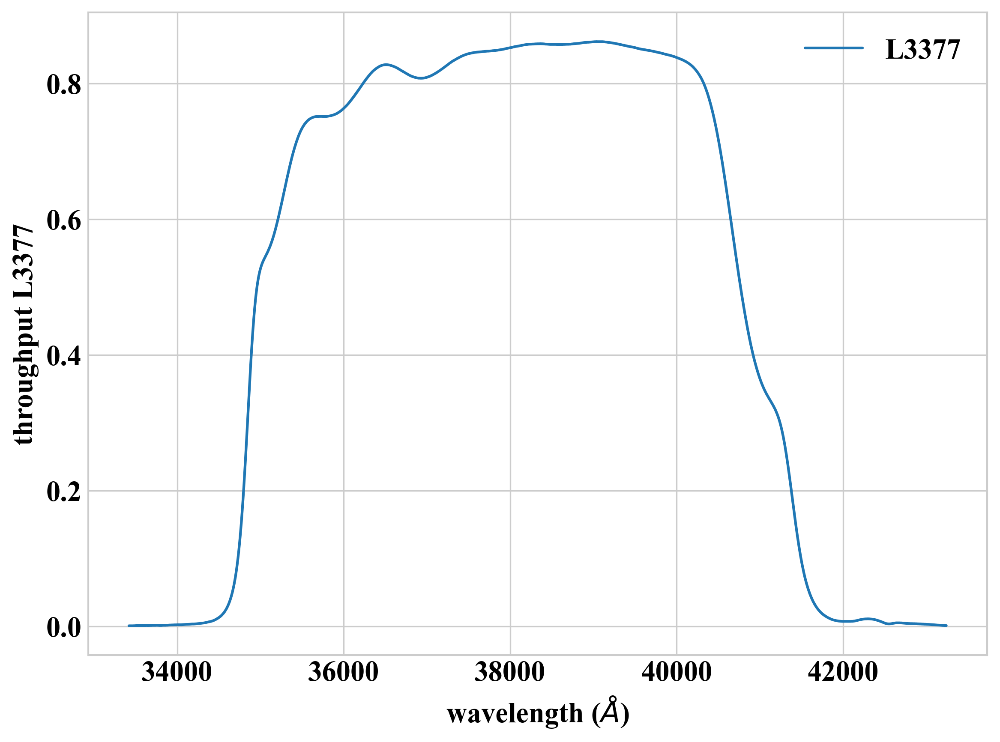

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3377 band [0.18]


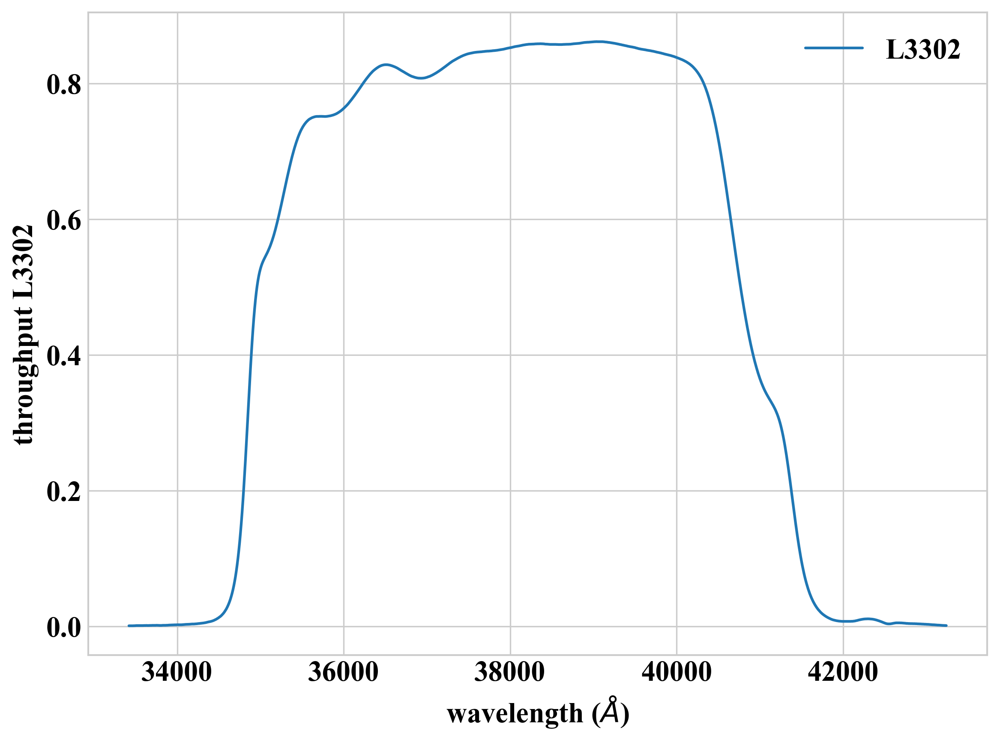

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3302 band [0.181]


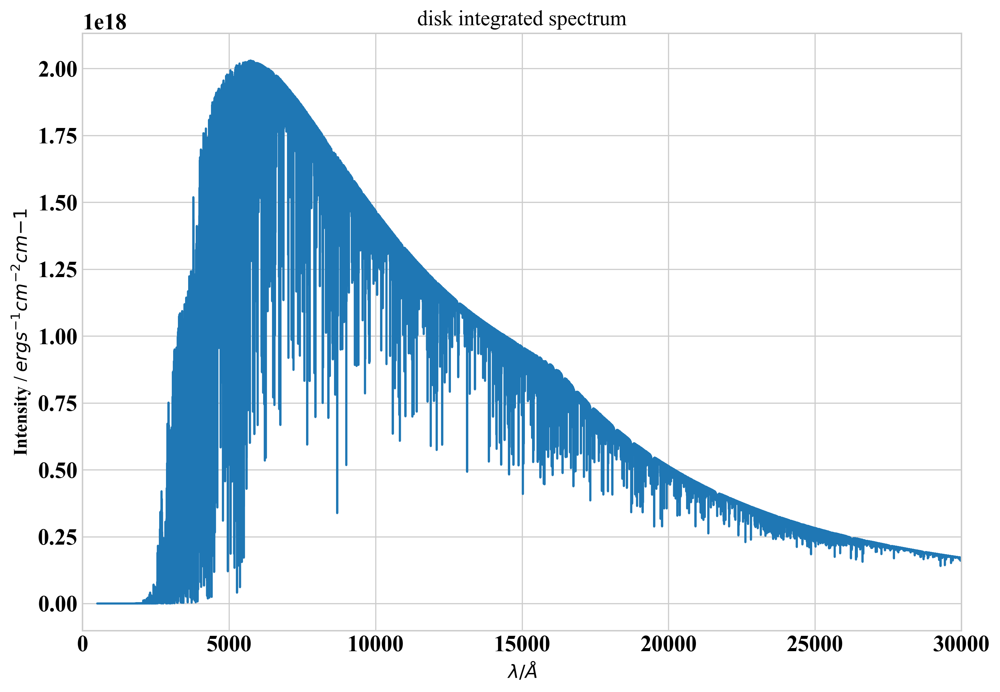

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


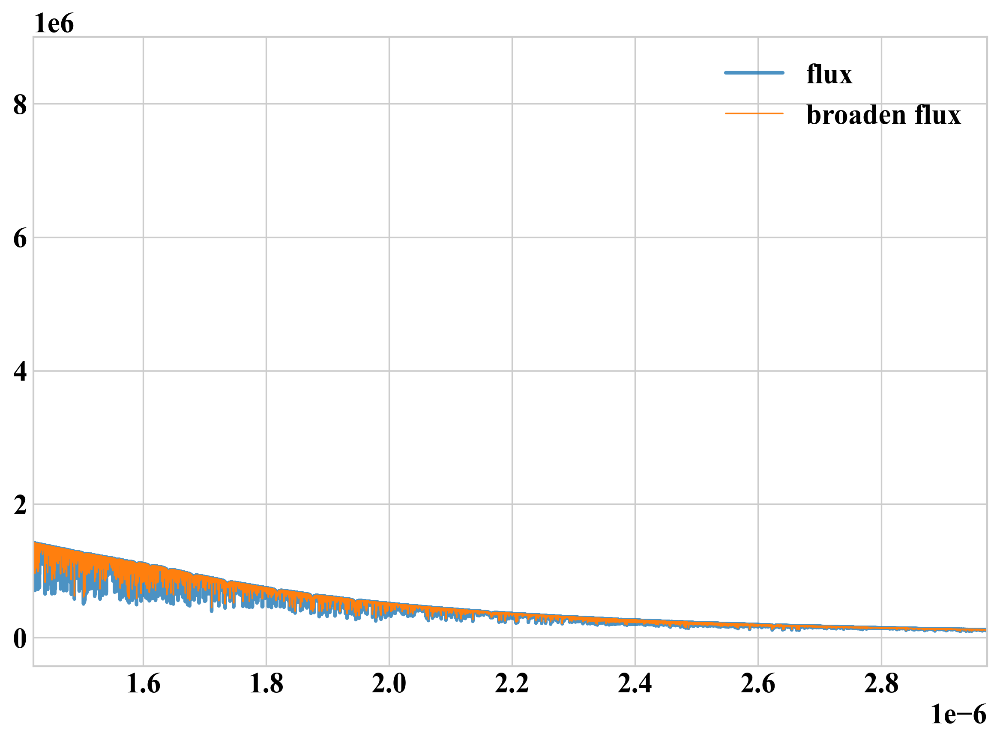

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 9.297881215795242 370882.36960508156 0.00019091828024979314
The star spectrum already exists, skipping download


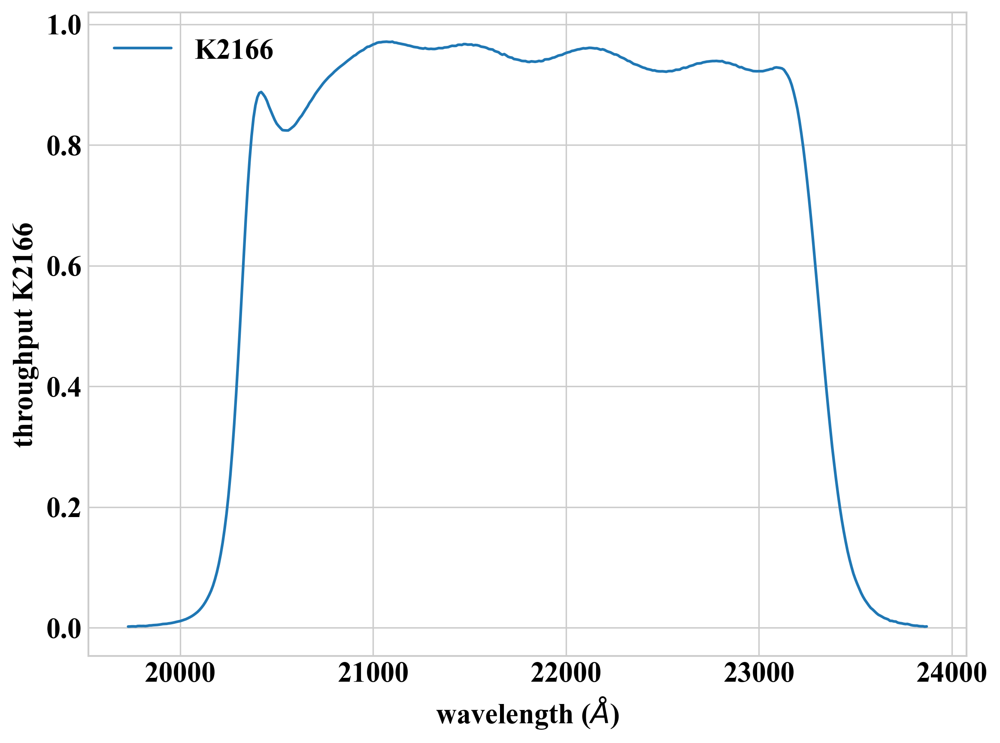

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at K2166 band [0.2668]


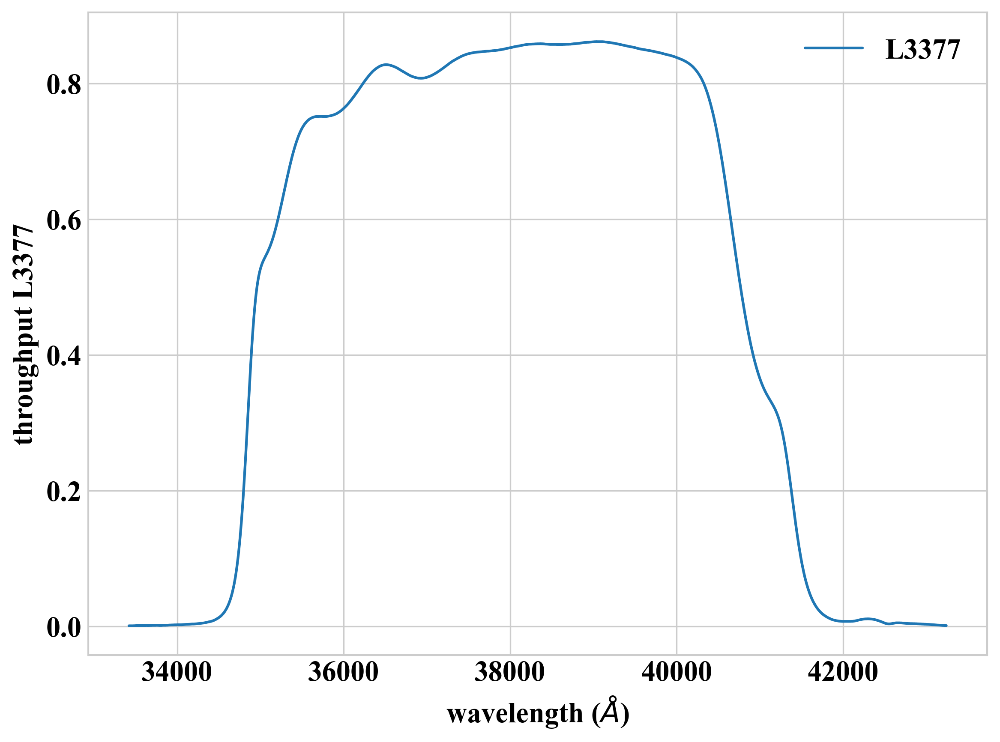

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3377 band [0.18]


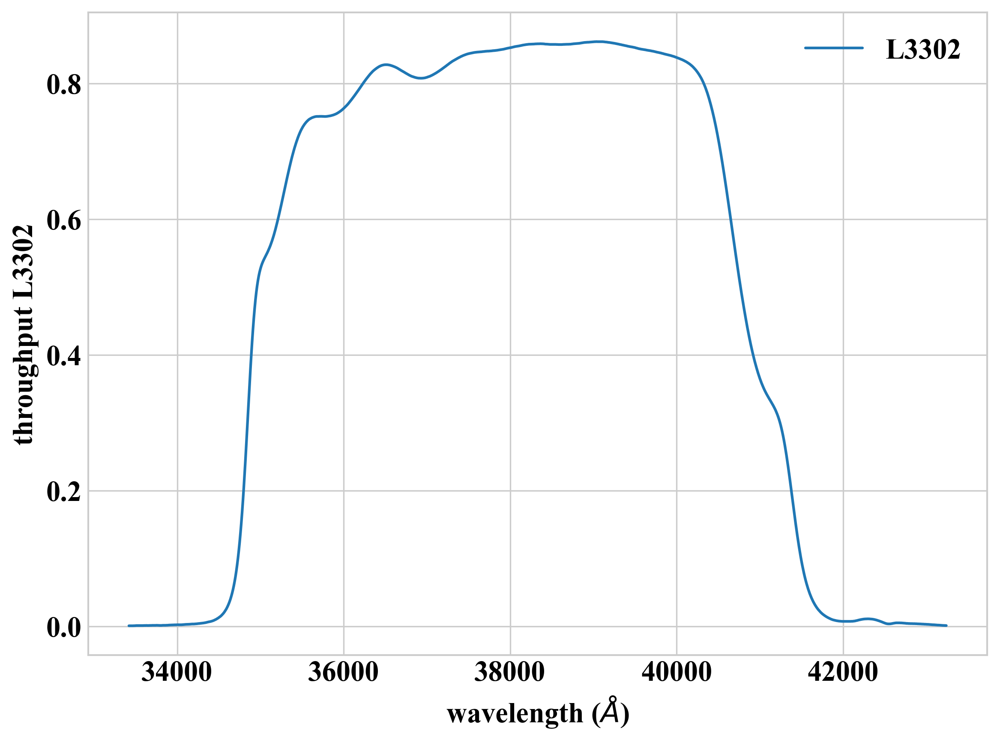

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3302 band [0.181]


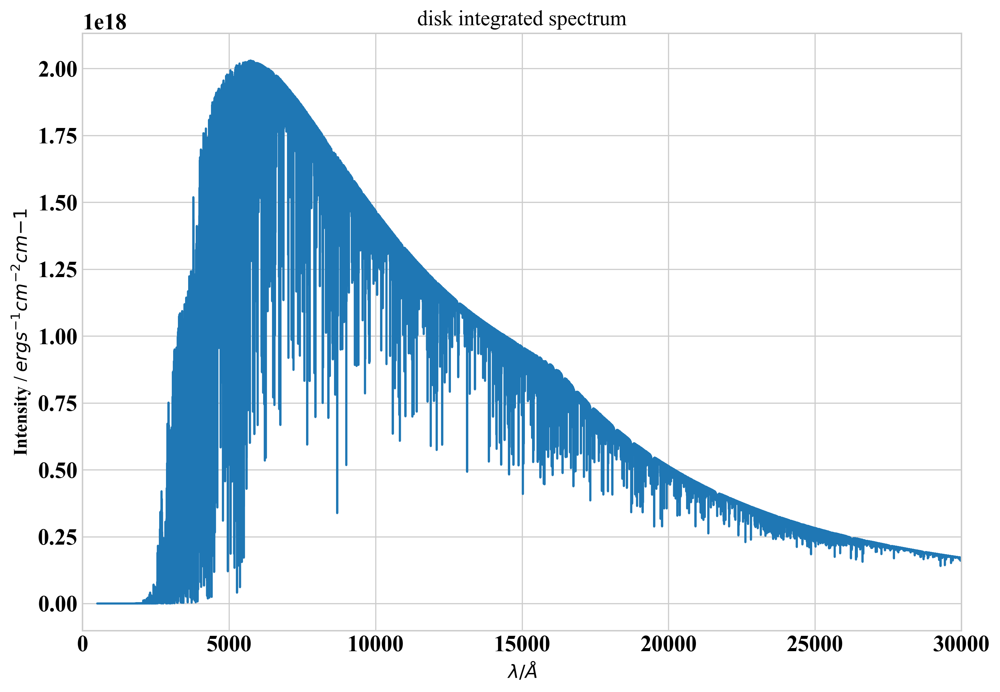

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


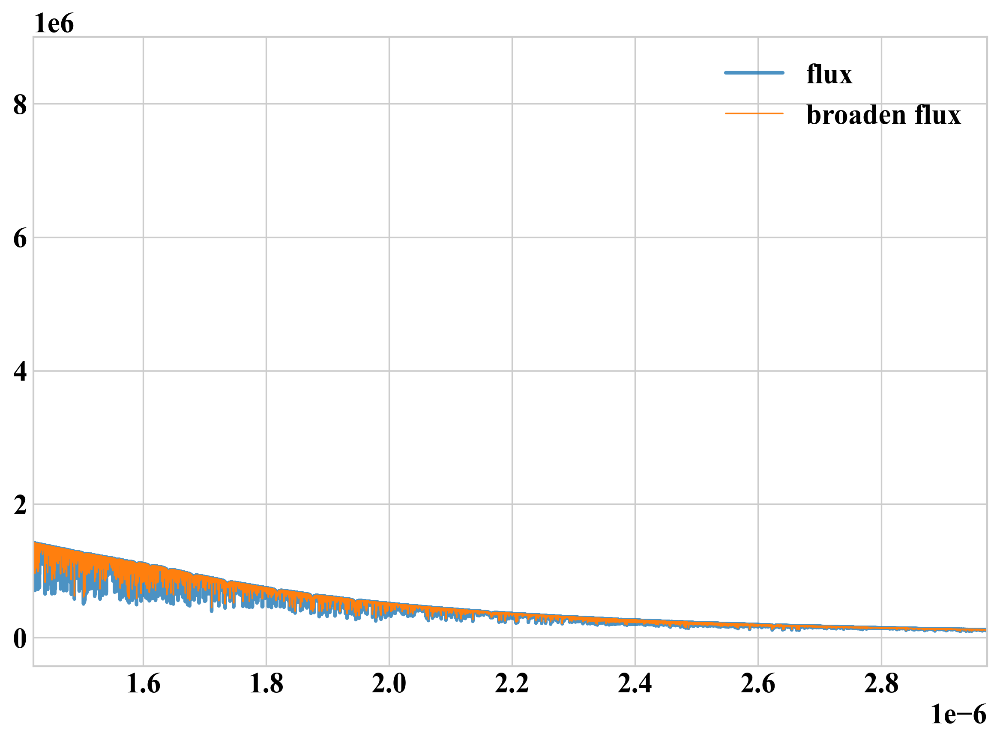

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 9.297881215795242 370882.36960508156 0.00019091828024979314
The star spectrum already exists, skipping download


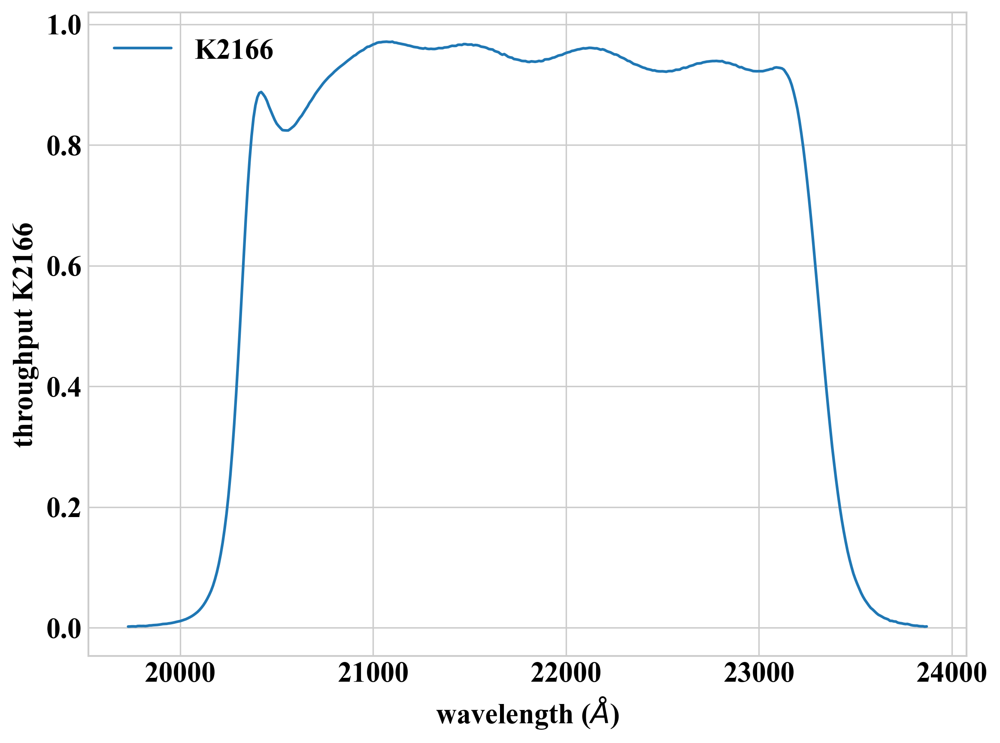

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at K2166 band [0.2668]


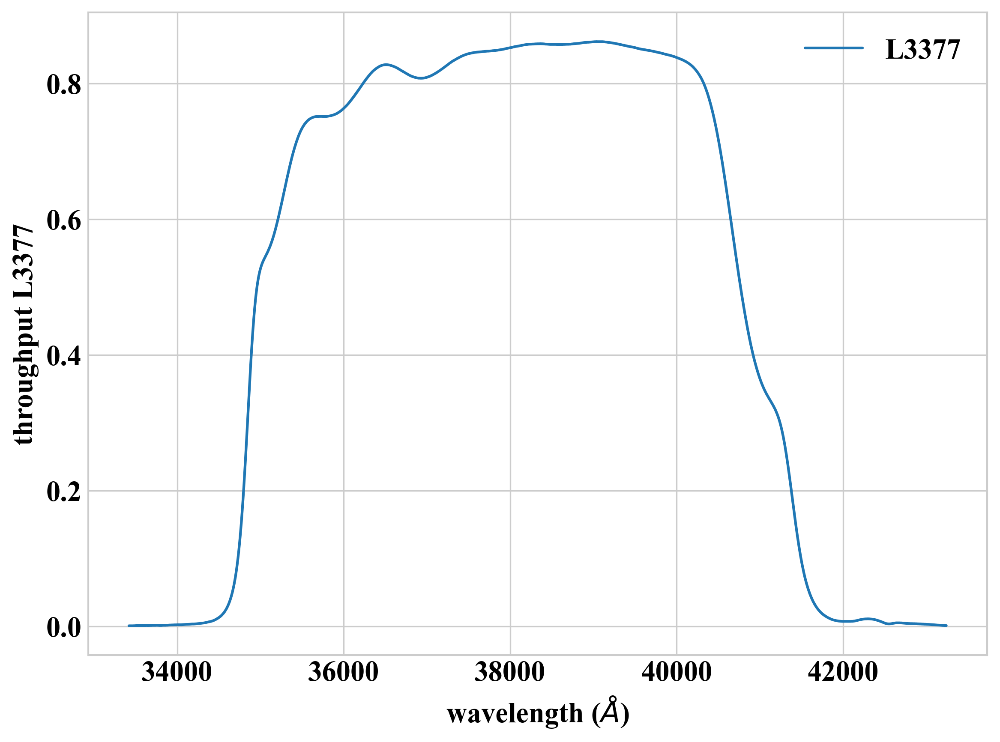

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3377 band [0.18]


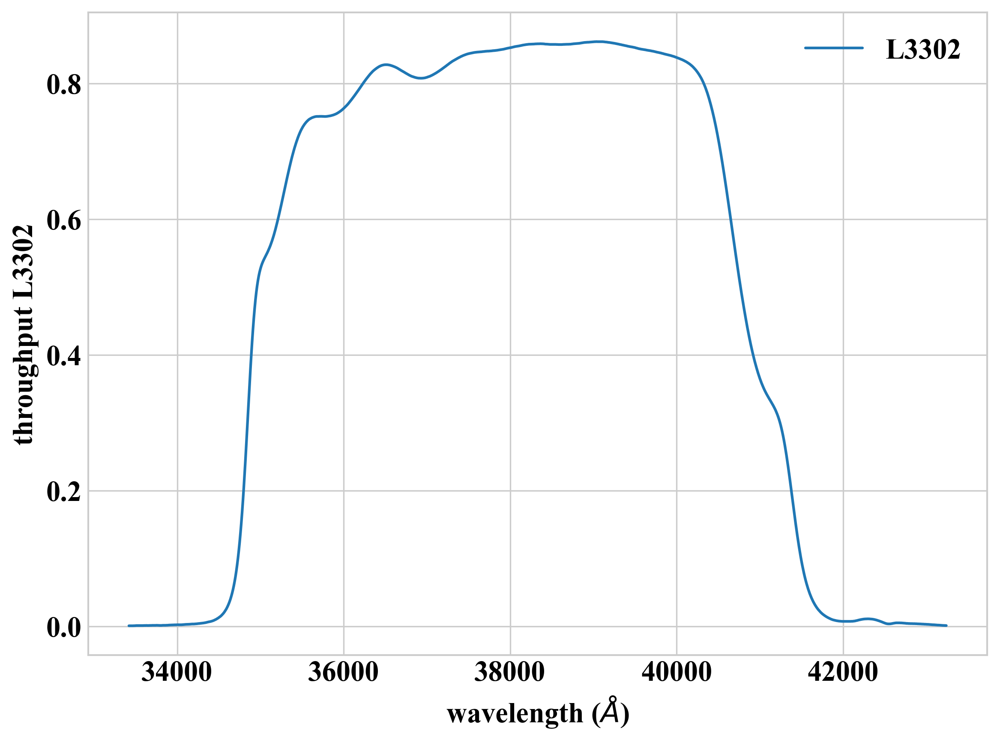

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3302 band [0.181]


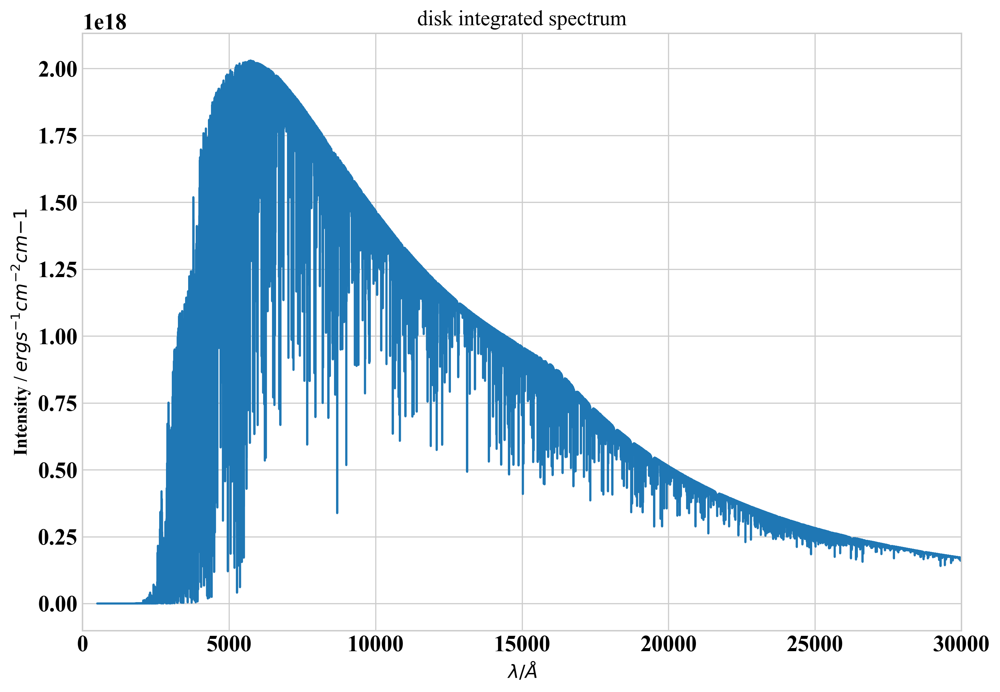

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


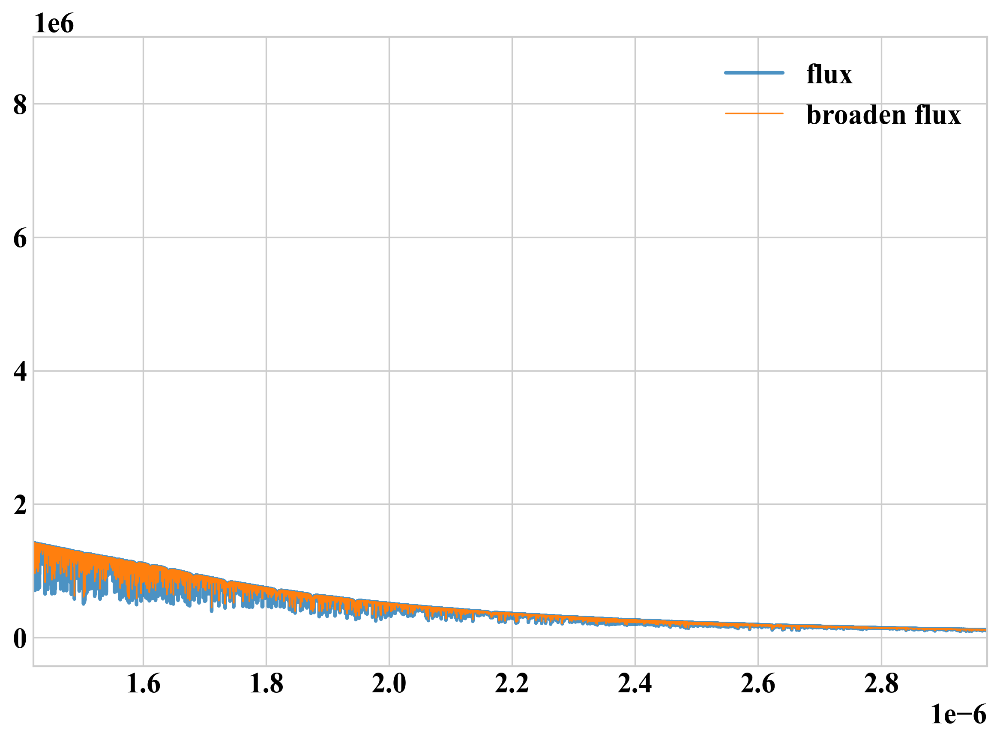

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 9.297881215795242 370882.36960508156 0.00019091828024979314
The star spectrum already exists, skipping download


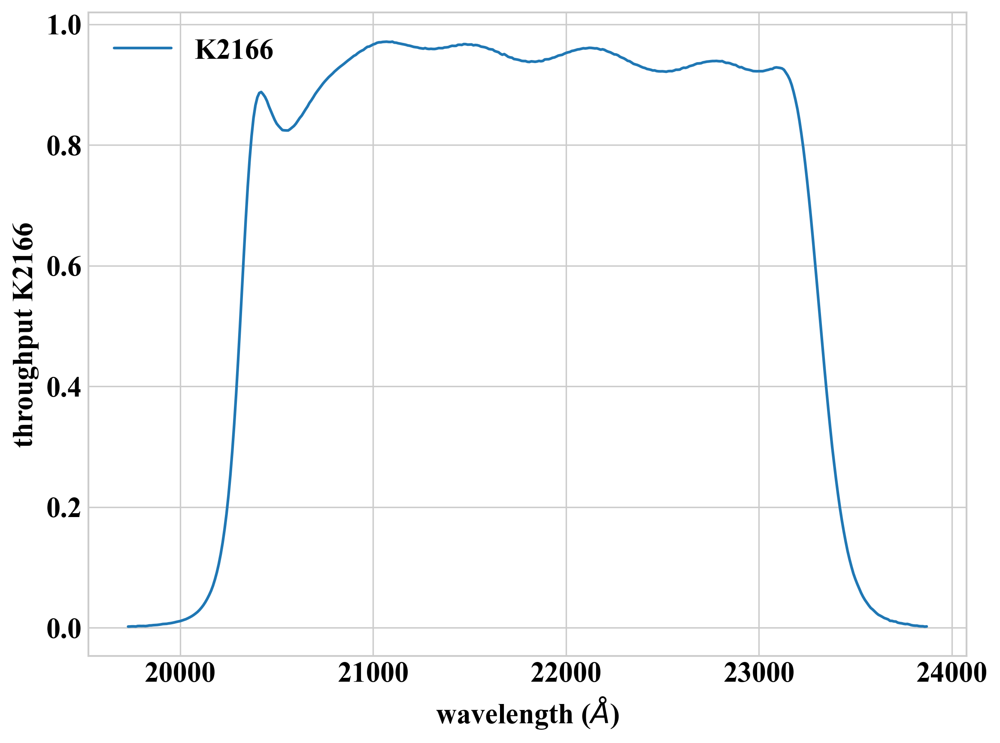

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at K2166 band [0.2668]


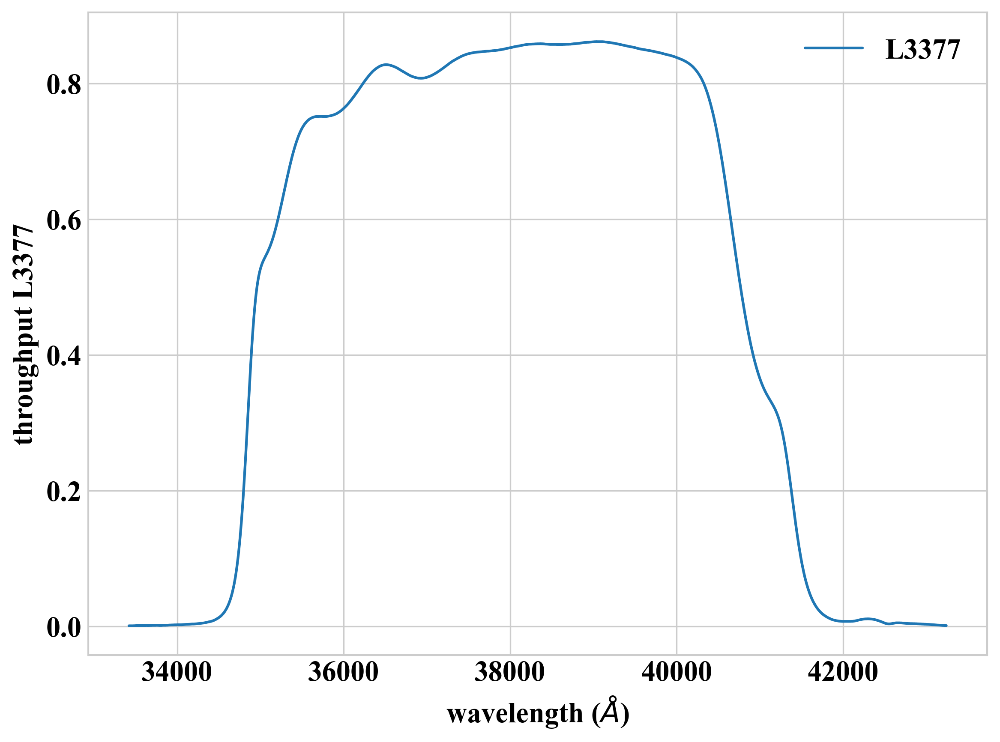

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3377 band [0.18]


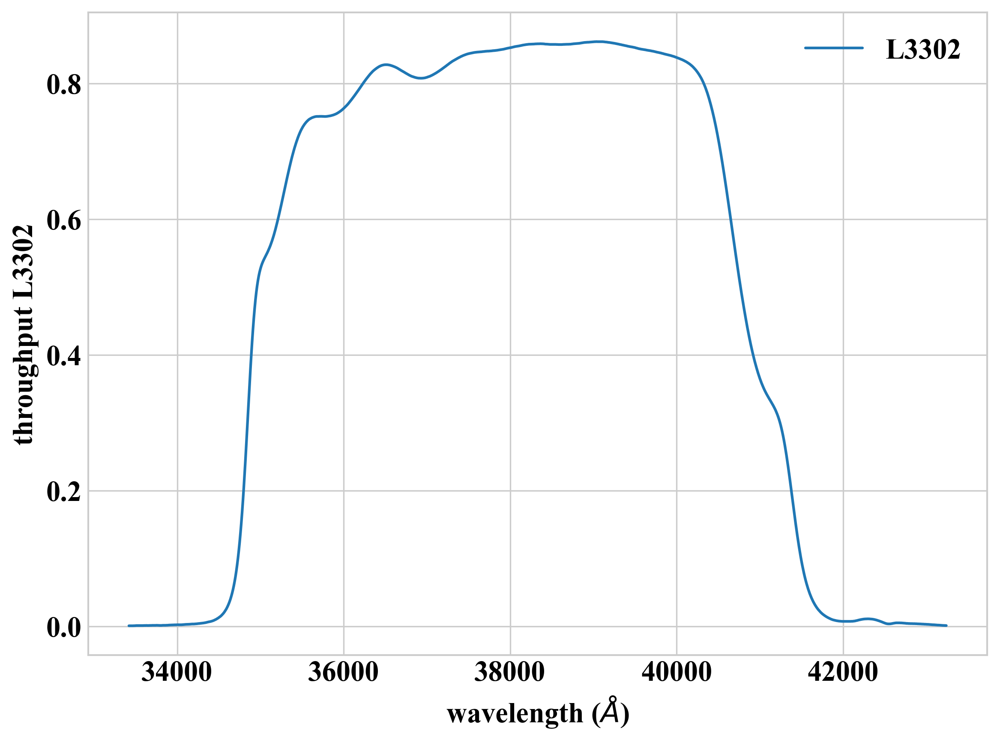

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3302 band [0.181]


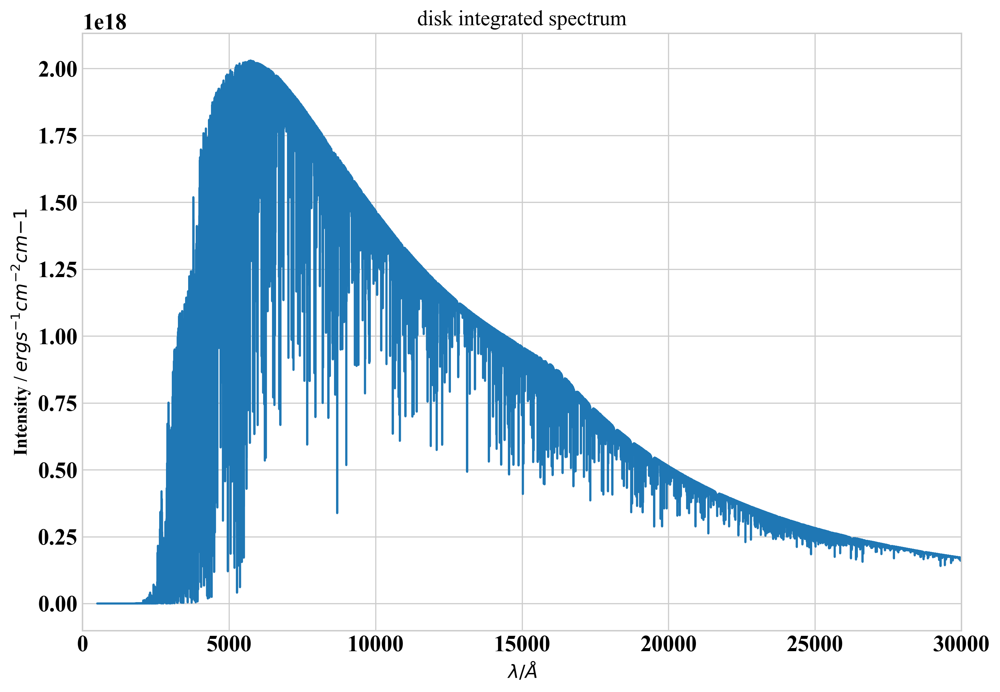

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


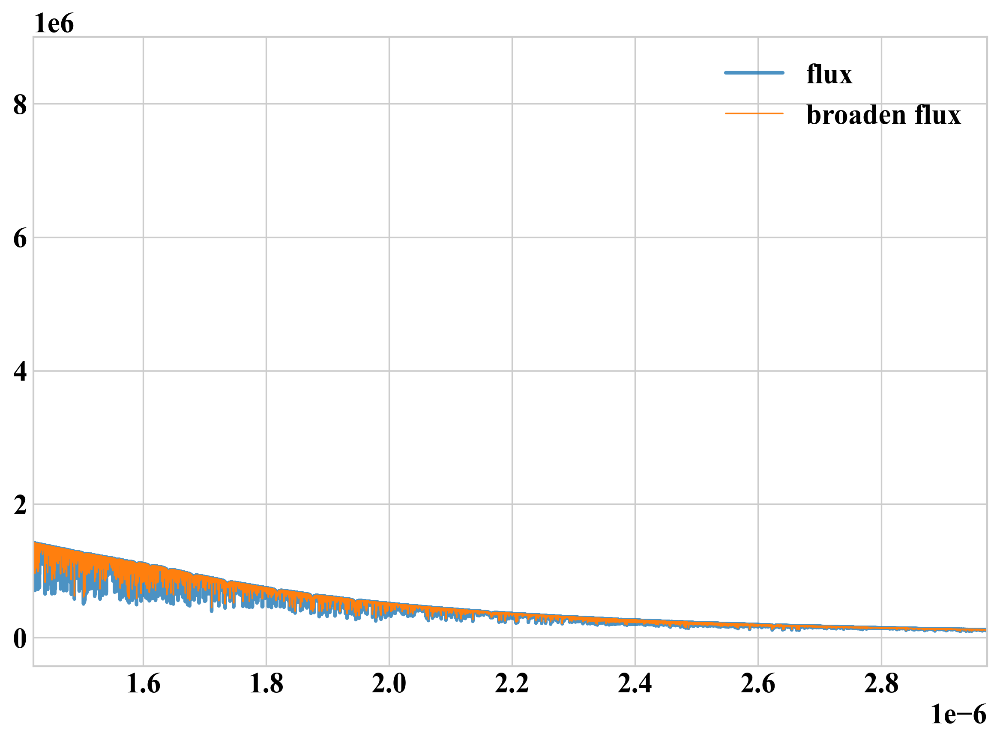

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 9.297881215795242 370882.36960508156 0.00019091828024979314
The star spectrum already exists, skipping download


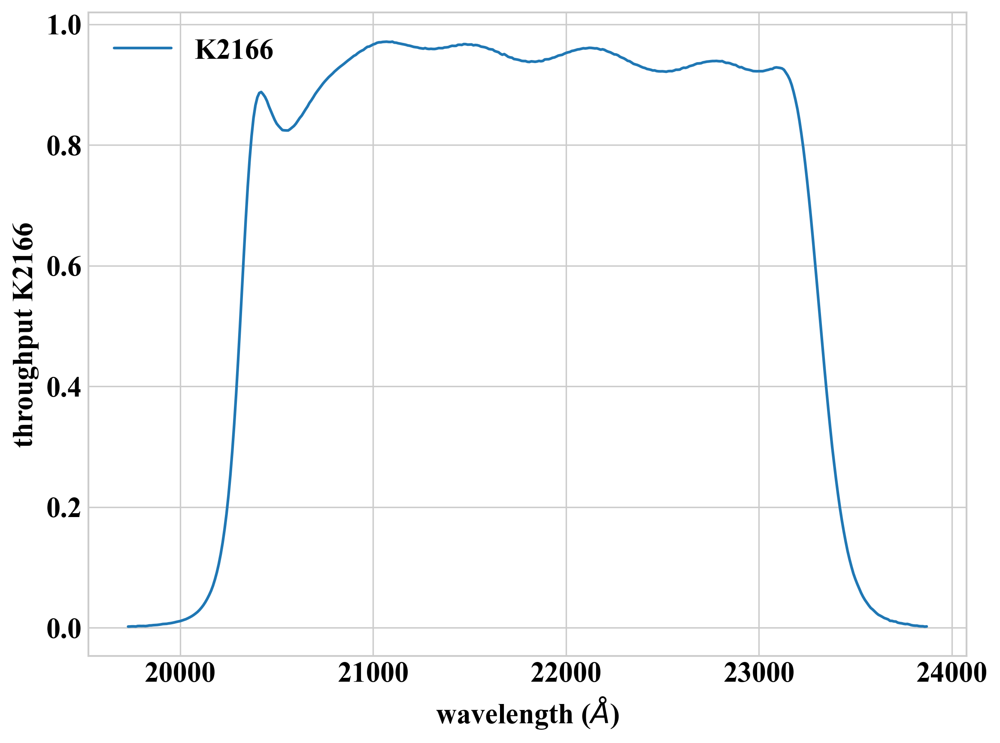

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at K2166 band [0.2668]


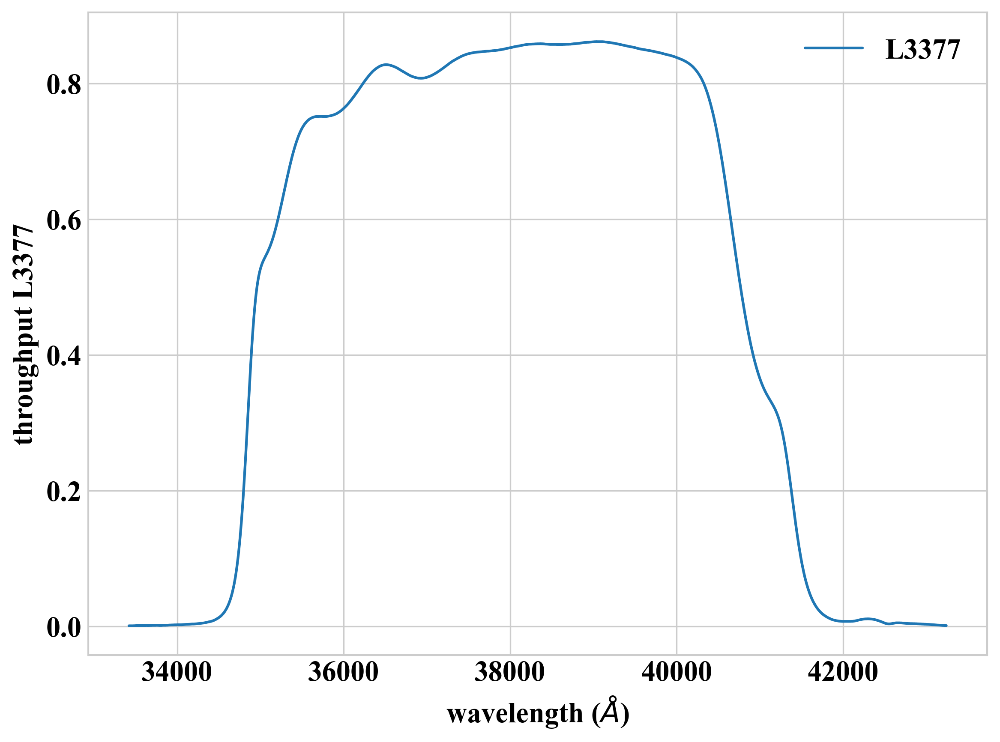

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3377 band [0.18]


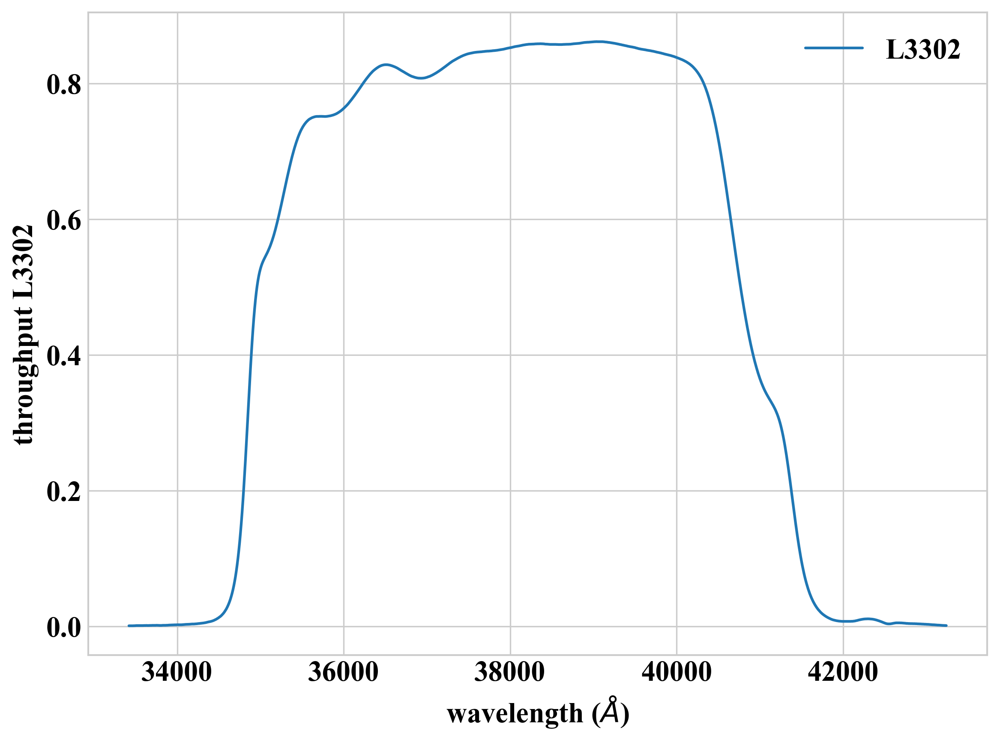

T, Z, G 5500 -0.0 4.5
limb darkening coefficient at L3302 band [0.181]


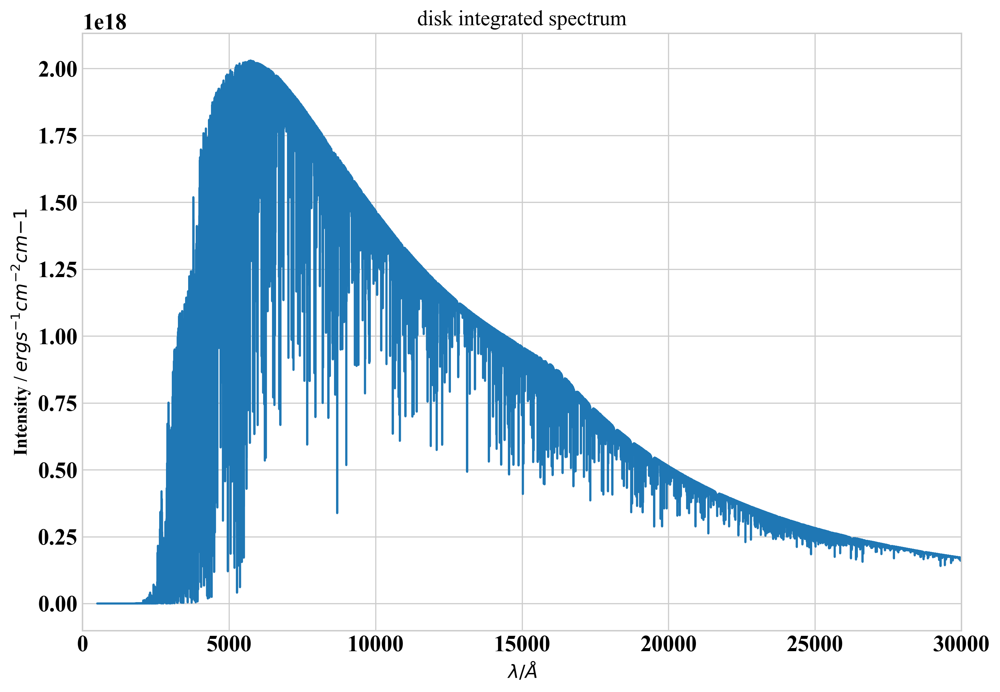

resolution of the input spectrum: 798959.2265859017
delta_lam: 0.03473252961678692
Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. 
----Convolution with LSF and rotational broadening kernel starts----


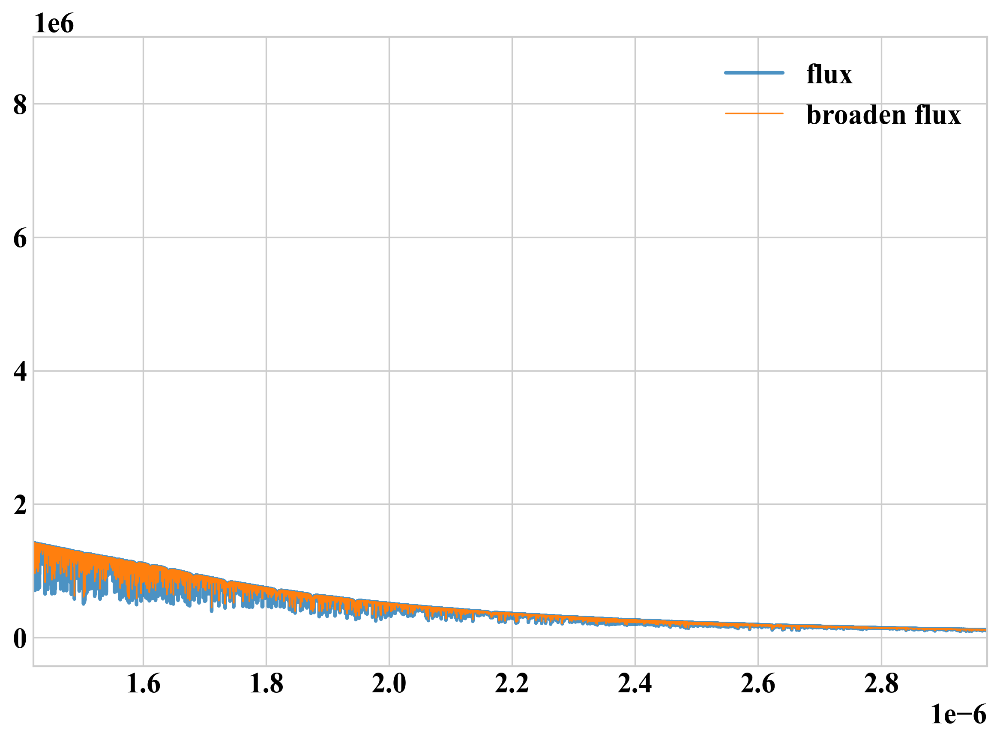

wavelength range: 1.9214748652175087e-06 2.4724051347834674e-06
magnitude in K band: 9.297881215795242 370882.36960508156 0.00019091828024979314


In [200]:
#Read R_star, log_t, Teff_star from data_BHAC15.txt
import scipy.ndimage
from exotic_ld import StellarLimbDarkening
from scipy import fftpack,signal
from scipy import interpolate, special
from astropy.io import fits
from astropy.table import Table

data_BHAC15=pd.read_csv(path+'BHAC15_tracks+structure.txt', delim_whitespace=True, comment='#', header=0)
data_BHAC15 =np.array(data_BHAC15) 
R_star_BHAC15=data_BHAC15[:,5]
log_t_BHAC15=data_BHAC15[:,1]
Teff_star_BHAC15=data_BHAC15[:,2]
G_star_BHAC15=data_BHAC15[:,4]
M_star_BHAC15=data_BHAC15[:,0]

t = np.arange(1, 90, 3)  # age in Myr 
log_t = np.log10(t * 1e6)  # convert age to log t(yr)

M_star = 1.0  # solar mass

#Findd the corresponding R_star, Z_star, G_star and Teff_star from BHAC15 models

data_BHAC15_1M = data_BHAC15[M_star_BHAC15 == M_star]
R_star_BHAC15_1M = data_BHAC15_1M[:,5]
Teff_star_BHAC15_1M = data_BHAC15_1M[:,2]
G_star_BHAC15_1M = data_BHAC15_1M[:,4]
log_t_BHAC15 = data_BHAC15_1M[:,1]

#find the closest log_t in BHAC15 models
closest_index = [np.abs(log_t_BHAC15 - val).argmin() for val in log_t]
R_s = R_star_BHAC15_1M[closest_index]
Z_s = 0.0
T_s = Teff_star_BHAC15_1M[closest_index]
G_s = G_star_BHAC15_1M[closest_index].round(2)


R_s = R_s.round(2)

print("Star parameters for 1.0 Msun:")
print("log_t:", log_t)
print("R_s (Rsun):", R_s)
print("Z_s:", Z_s)
print("T_s (K):", T_s)
print("G_s (log g):", G_s)

#Download the PHOENIX spectra for the star
Z_s = int(Z_s *2)/2 # round to the nearest 0.5
if Z_s  == 0.0:
    Z_s = -0.0

T_s = [int(T_i / 100) * 100 for T_i in T_s]  # round to the nearest 100
G_s = [int(G_i / 0.5) * 0.5 for G_i in G_s]  # round to the nearest 0.5

#create a csv file to store the star parameters for 1.0 Msun
star_params=pd.DataFrame({'log_t':log_t, 'R_s':R_s, 'Z_s':Z_s, 'T_s':T_s, 'G_s':G_s, 'Mag_K':np.zeros(len(log_t))})
star_params.to_csv(path+'star_params_1Msun.csv', index=False)

for folder_name in ['phoenix_spectra']:
    if not os.path.exists(path + folder_name):
        os.makedirs(path + folder_name)
    
    Z_star = Z_s
    star_magnitude_Kband = []

    for log_t, T_star, G_star, R_star in zip(log_t, T_s, G_s, R_s):

        #skip T = 4500 K since no PHOENIX model available
        if T_star == 4500:
            star_magnitude_Kband.append(np.nan)
            continue


        path_library='ftp://phoenix.astro.physik.uni-goettingen.de/HiResFITS/PHOENIX-ACES-AGSS-COND-2011/'
        path_spectrum ='Z%s/lte0%s-%s0%s.PHOENIX-ACES-AGSS-COND-2011-HiRes.fits'%(Z_star, T_star, G_star, Z_star)
        name_spectrum = '/lte0%s-%s0%s.PHOENIX-ACES-AGSS-COND-2011-HiRes.fits'%(T_star, G_star, Z_star)

        if not os.path.exists(path + folder_name + name_spectrum):
            os.system('wget %s%s -P %s%s'%(path_library, path_spectrum, path, folder_name))
        else:
            print('The star spectrum already exists, skipping download')

        #Run the brightness calculator to get the magnitude

        # Calculate the limb darkening coefficients
        # change the wavelength unit to angstrom 
        # IMPORTANT: THE SPECTRUM NEEDS TO COVER BOTH K and L BAND SINCE NO BRIGHTNESS MEASUREMENT AT L BAND

        # Calculate the limb darkening coefficients from K and L band

        wavelength_range=info.lambda_range['wave']

        def generate_synthetic_stellar_models(model_spec, n_mus, factor):
            # Generate I(lambda, mu).
            n_wvs = len(model_spec)
            mus = np.linspace(0, 1, n_mus)
            stellar_intensity = []

            for mu in mus:
                stellar_intensity.append(model_spec*factor)

            return mus, np.array(stellar_intensity).T


        ld_coffecients = np.zeros((len(wavelength_range), 1))

        for index in [-3,-2, -1]:
            
            wavelengths=[wavelength_range[index][0][0]*10, wavelength_range[index][-1][-1]*10]

            key = info.lambda_range['key'][index]

            if index in [-2, -1]:
                
                throughput=np.loadtxt(path+'/Paranal_ERIS_Lp.dat')
            
            else:
                throughput = np.loadtxt(path+'/SPHERE_IRDIS_B_%s.dat'%key[0])   

            wave_throughput=throughput[:,0]
            frac_throughput=throughput[:,1]

            plt.plot(wave_throughput,frac_throughput, label='%s'%key)
            plt.xlabel('wavelength ($\AA$)')
            plt.ylabel('throughput %s'%key)

            plt.legend()
            plt.show()

            print("T, Z, G", T_star, Z_star, G_star)

            sld=StellarLimbDarkening(ld_model='phoenix', ld_data_path='/Users/richard/project_EXOCRIRES/ld_data',\
                                    M_H=Z_star, Teff=T_star, logg=G_star)
            
            cs=sld.compute_linear_ld_coeffs(mode='custom', wavelength_range=wavelengths, custom_wavelengths=wave_throughput, custom_throughput=frac_throughput)

            print("limb darkening coefficient at %s band"%key, np.float16(cs))

            ld_coffecients[index] = np.float16(cs)

        rs = (1 - sld.mus**2)**0.5
        roots, weights = special.roots_legendre(500)
        a, b = (0., 1.)
        t = (b - a) / 2 * roots + (a + b) / 2

        spectrum = []
        for wv_idx in range(sld.stellar_wavelengths.shape[0]):

            i_interp_func = interpolate.interp1d(
                rs, sld.stellar_intensities[wv_idx, :], kind='linear',
                bounds_error=False, fill_value=0.)

            def integrand(_r):
                return i_interp_func(_r) * _r * 2. * np.pi

            spectrum.append((b - a) / 2. * integrand(t).dot(weights))

        plt.figure(figsize=(10, 7))
        plt.plot(sld.stellar_wavelengths, spectrum)
        plt.xlabel("$\lambda / \AA$", fontsize=13)
        plt.ylabel("Intensity / $erg s^{-1} cm^{-2} cm {-1}$", fontsize=13)
        plt.xlim(0, 3e4)

        plt.title('disk integrated spectrum', fontsize=15)
        plt.show()        

        #Calculate the broadened spectrum
        #Convolve a LSF
        

        flux=fits.open(path+'phoenix_spectra/lte0%s-%s0%s.PHOENIX-ACES-AGSS-COND-2011-HiRes.fits'%(T_star,G_star,Z_star))
        flux=flux[0].data
        wave=fits.open(path+'WAVE_PHOENIX-ACES-AGSS-COND-2011.fits')
        wave=wave[0].data

        

        def gaussian_broaden_spectrum(wavelength, flux, R):
            # Convert wavelength to log space
            log_wavelength = np.log(wavelength)
            
            # Define FWHM and standard deviation in log space
            fwhm_log = 1 / R
            sigma_log = fwhm_log / 2.355  # Convert FWHM to sigma
            
            # Convolve the flux with a Gaussian kernel in log space
            broadened_flux = scipy.ndimage.gaussian_filter1d(flux, sigma=sigma_log / (log_wavelength[1] - log_wavelength[0]))
            
            return broadened_flux

        def resolution_sample(ave_R, wavelength):
            
            lam_range=np.max(wavelength)-np.min(wavelength)
            
            lam_mid=(np.max(wavelength)+np.min(wavelength))/2
            
            N=ave_R*(lam_range/lam_mid)+1
            
            return (int(N))

        # Example: wavelengths, fluxes, and resolution R
        N_sample=len(wave)
        lam_range=np.max(wave)-np.min(wave)
        lam_mid=(np.max(wave)+np.min(wave))/2
        R_sample =  (N_sample-1)/(lam_range/lam_mid)
        print('resolution of the input spectrum:', R_sample)

        delta_lam=lam_mid/R_sample
        print("delta_lam:", delta_lam)

        ### Use pyasl.equidistantInterpolation to produce equidistantly sampled data

        if (wave[1]-wave[0]) != (wave[-1]-wave[-2]):

            print ('Sample grid is not equal. Use pyasl.equidistantInterpolation to produce equidistantly sampled data. ')

            step_size=1e-1
            new_wave, new_flux = pyasl.equidistantInterpolation(wave, flux, step_size)

        else:
            new_wave=wave
            new_flux=flux

        R=1e5
        reu=500 #redundant in nm


        # Broaden the spectrum at separate bands and then reduce the size
        new_wave*=1e-10 #m
        new_flux*=1e-8  #erg/s/cm2/A

        print ('----Convolution with LSF and rotational broadening kernel starts----')
        for i in range(len(info.lambda_range['wave']))[-3:-2]:

            ld_coefficient=ld_coffecients[i][0]
            rotation=5 #km/s, https://ui.adsabs.harvard.edu/abs/2006yCat..34630671R/abstract

            lam=info.lambda_range['wave'][i]

            mask=np.array((new_wave>=(lam[0][0]-reu)*1e-9) & (new_wave <=(lam[-1][-1]+reu)*1e-9))

            lb_coeff=np.float16(ld_coefficient)
            rflux=pyasl.fastRotBroad(wvl=new_wave[mask], flux=new_flux[mask], epsilon=ld_coefficient, vsini=rotation)
            broadened_flux = gaussian_broaden_spectrum(new_wave[mask], rflux, R)

            plt.plot(new_wave, new_flux, label='flux', alpha=0.8, linewidth=2)
            plt.plot(new_wave[mask], broadened_flux, label='broaden flux', linewidth=0.9)
            plt.xlim(new_wave[mask][0], new_wave[mask][-1])
            #plt.ylim(0,1e10)
            #plt.yscale('log')
            
            plt.legend()
            plt.show()

            #----------

            N=resolution_sample(R*2, new_wave[mask])

            wave_grid=np.linspace(np.min(new_wave[mask]), np.max(new_wave[mask]), N)

            inter_flux=np.interp(wave_grid, new_wave[mask], broadened_flux)

            spec_lowres=np.array([wave_grid, inter_flux]).T
            np.savetxt(path+'phoenix_spectra/upload_star_lowres_%s_rot_lsf.dat'%info.lambda_range['key'][i], spec_lowres)

            pc = 3.086e18 #cm

            r_sun =  6.96e10 # solar radius in cm

            Luminosity_sun = 3.828e33  # Solar luminosity in erg/s

            Luminosity_jup = 3.3e24  # Jupiter luminosity in erg/s

            k_band_wave=np.array(info.lambda_range['wave'][-3])

            #flux_K=np.load(path_a+'/f_pRT_Kband_t1700_g31nc_m0.0.npy')
            #wave_K=np.load(path_a+'/wave_pRT_Kband.npy')*1e-6

            spec_star=np.loadtxt(path+'phoenix_spectra/upload_star_lowres_K2166_rot_lsf.dat').T
            #spec_planet=np.array([wave_K, flux_K])

            brightness_caculator = analysis.planet_para(data_planet=spec_star)

            r_star = R_star*r_sun


            throughput = np.loadtxt(path+'SPHERE_IRDIS_B_K.dat')
            throughput[:,0] = throughput[:,0]*1e-10 #m
            mag_K=brightness_caculator.mag_direct(radius=r_star, distance=140*pc, solid_angle=4*np.pi, band=k_band_wave*1e-9, transmission=throughput.T, zero=4.08361e-11)
            print('magnitude in K band:', mag_K[0], mag_K[1], mag_K[2])

            star_magnitude_Kband.append(mag_K[0])

star_params['Mag_K']=star_magnitude_Kband

In [201]:
star_params

,log_t,R_s,Z_s,T_s,G_s,Mag_K
0,6.000000,2.42,-0.0,4300,3.5,7.490599
1,6.602060,1.54,-0.0,4300,4.0,8.463769
2,6.845098,1.31,-0.0,4300,4.0,8.815016
3,7.000000,1.19,-0.0,4300,4.0,9.023638
4,7.113943,1.12,-0.0,4400,4.0,9.123166
5,7.204120,1.08,-0.0,4500,4.0,NaN
6,7.278754,1.06,-0.0,4700,4.0,9.156640
7,7.342423,1.05,-0.0,4900,4.0,9.123459
8,7.397940,1.06,-0.0,5100,4.0,9.045295
9,7.447158,1.06,-0.0,5300,4.0,8.994614


/var/folders/w_/fqznltwj2pz2y345p5_rzn3r0000gn/T/ipykernel_1990/1982563694.py:88: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax2.legend()


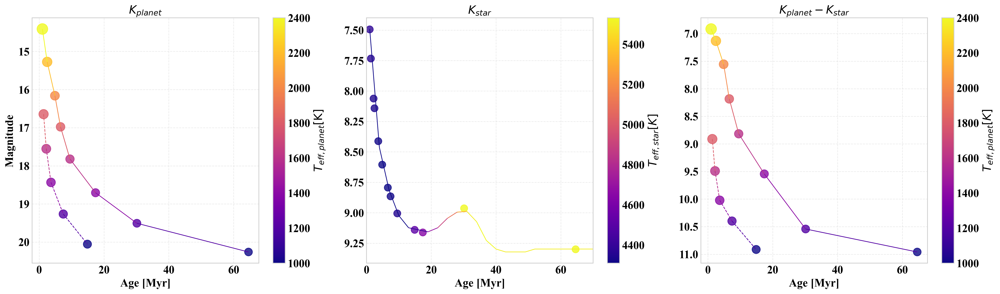

In [ ]:
import numpy as np

import matplotlib.colors as mcolors
import matplotlib.cm as cm
from matplotlib.collections import LineCollection

#Plot the planet magnitude, star magnitude and flux contrast on three panels

# Combine Teff arrays for normalization
all_Teff = np.concatenate([Teff_5, Teff_10])
norm = mcolors.Normalize(vmin=np.min(all_Teff), vmax=np.max(all_Teff))
cmap = cm.plasma

all_Teff_star = simulation_log['Teff_star'].values
norm_star = mcolors.Normalize(vmin=np.min(all_Teff_star), vmax=np.max(all_Teff_star))
cmap_star = cm.plasma


def colored_line(x, y, c, cmap, norm, lw=2, sizes=None, ax=None, marker_shape='o', line_style='-', scatter=True):
    """
    Draw a line colored according to values c
    """
    points = np.array([x, y]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    lc = LineCollection(segments, cmap=cmap, norm=norm, linewidth=lw, linestyle=line_style)
    lc.set_array(np.array(c[:-1]))  # color line segments by Teff
    if ax is not None:
        ax.add_collection(lc)
    else:
        plt.gca().add_collection(lc)
    
    # Scatter points
    if scatter == True:
        if sizes is None or len(sizes) != len(x):
            sizes = np.ones_like(x) * 100
        if ax is not None:
            ax.scatter(x, y, s=sizes, c=c, cmap=cmap, norm=norm, marker=marker_shape, alpha=0.8)
        else:
            plt.scatter(x, y, s=sizes, c=c, cmap=cmap, norm=norm, marker=marker_shape, alpha=0.8)
    return lc


fig, axes = plt.subplots(1, 3, figsize=(20, 6), dpi=300)

scale = 100

# Panel 3: Planet-to-Star Contrast in K Band
ax1 = axes[2]
lc5 = colored_line(Age_5, delta_mag_5, Teff_5, cmap, norm, lw=1, sizes=R_planet_5 * scale, ax=ax1, line_style='--')
lc10 = colored_line(Age_10, delta_mag_10, Teff_10, cmap, norm, lw=1, sizes=R_planet_10 * scale, ax=ax1)
ax1.set_xlabel("Age [Myr]")
#ax1.set_ylabel(r"magnitude")
ax1.set_title(r"$K_{planet} - K_{star}$")
ax1.invert_yaxis()
ax1.grid(True, which="both", ls="--", alpha=0.4)

# Add colorbar for the first panel
cbar = fig.colorbar(lc10, ax=ax1)
cbar.set_label(r"$T_{eff,planet} [K]$")

# Panel 2: K Band Star Magnitude and ignore the nan values
ax2 = axes[1]
r_star = star_params['R_s'].values
mag_star = star_params['Mag_K'].values
age_star = 10**(star_params['log_t'].values) * 1e-6  # convert log_t(yr) to Myr
Teff_star = star_params['T_s'].values

# Remove nan values
valid_indices = ~np.isnan(mag_star)
age_star = age_star[valid_indices]
mag_star = mag_star[valid_indices]
Teff_star = Teff_star[valid_indices]
r_star = r_star[valid_indices]

age_star, mag_star, Teff_star, r_star = zip(*sorted(zip(age_star, mag_star, Teff_star, r_star)))

lc_star = colored_line(age_star, mag_star, Teff_star, cmap_star, norm_star, lw=1, sizes=r_star * scale, ax=ax2, scatter=False)

#mark the simulation points with rings
age_sim = simulation_log['Age'].values
mag_sim = simulation_log['Mag_star_K'].values
Teff_sim = simulation_log['Teff_star'].values
r_sim = simulation_log['R_star'].values

age_sim, mag_sim, Teff_sim, r_sim = zip(*sorted(zip(age_sim, mag_sim, Teff_sim, r_sim)))
lc_star_sim = colored_line(age_sim, mag_sim, Teff_sim, cmap_star, norm_star, 
                            lw=0, sizes=r_sim * scale*2, ax=ax2, marker_shape='o')
ax2.legend()

ax2.set_xlabel("Age [Myr]")

ax2.set_title(r"$K_{star}$ ")
ax2.invert_yaxis()
ax2.grid(True, which="both", ls="--", alpha=0.4)

ax2.set_xlim(0, 70)

cbar_star = fig.colorbar(lc_star, ax=ax2)
cbar_star.set_label(r"$T_{eff,star} [K]$")

# Panel 3: Planet magnitude in K Band
ax3 = axes[0]
lc5 = colored_line(Age_5, Mag_planet_5, Teff_5, cmap, norm, lw=1, sizes=R_planet_5 * scale, ax=ax3, line_style='--')
lc10 = colored_line(Age_10, Mag_planet_10, Teff_10, cmap, norm, lw=1, sizes=R_planet_10 * scale, ax=ax3)
ax3.set_xlabel("Age [Myr]")
ax3.set_title(r"$K_{planet}$ ")

ax3.grid(True, which="both", ls="--", alpha=0.4)
ax3.invert_yaxis()
ax3.colorbar = fig.colorbar(lc10, ax=ax3)
ax3.colorbar.set_label(r"$T_{eff,planet} \mathrm{[K]}$")

ax3.set_ylabel(r"Magnitude")

plt.tight_layout()
plt.show()


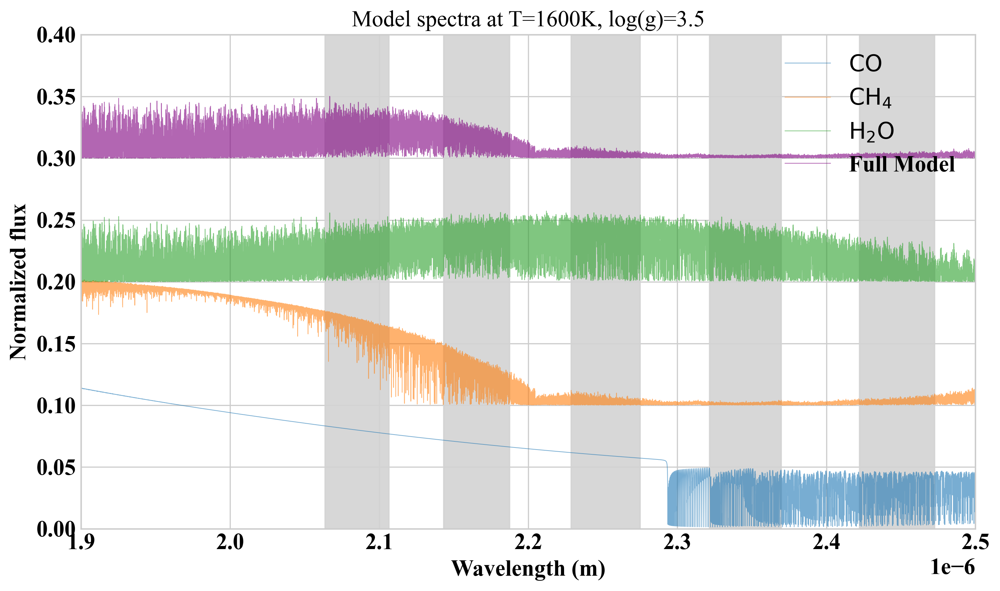

G_p_log for index 5: 31
G_p_log for index 7: 56
G_p_log for index 9: 100
G_p_log for index 11: 100


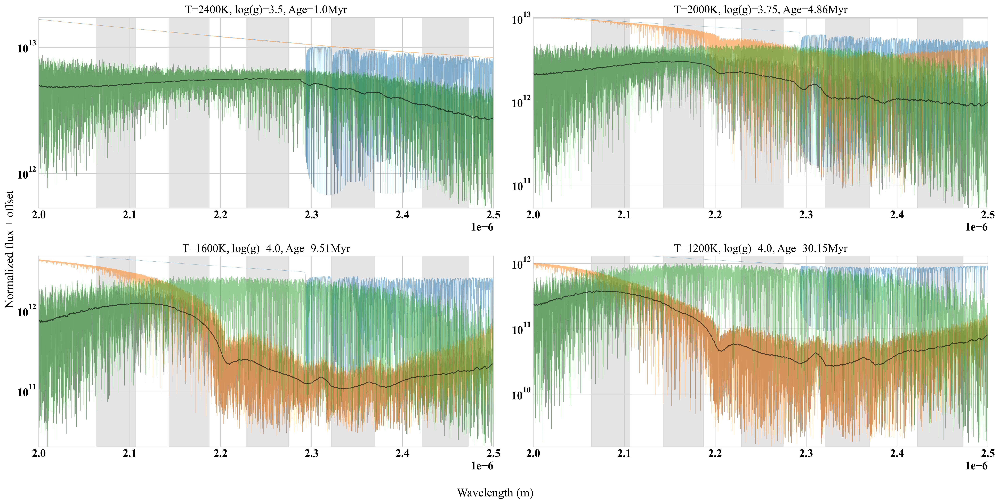

In [186]:
from scipy.signal import savgol_filter

def plot_spectrum_comparison(path, title, fMod_co, fMod_ch4, fMod_h2o, fMod, Normalize=True, shift=np.arange(0,0.5,0.1)):

    #Plot the fMod and mark the single molecule contributions using 1 - spectrum

    #plt.style.use('seaborn-v0_8-whitegrid')

    if Normalize == True:
        fMod_ch4 /= np.nanmax(fMod_ch4)
        fMod_co /= np.nanmax(fMod_co)
        fMod_h2o /= np.nanmax(fMod_h2o)
        fMod /= np.nanmax(fMod)

    plt.plot(wMod, fMod + shift[3], linewidth=0.5, label='Full Model', color='purple', alpha=0.6)
    plt.plot(wMod, fMod_co + shift[0], linewidth=0.5, label=r'$\mathrm{CO}$', alpha=0.6)
    plt.plot(wMod, fMod_ch4 + shift[1], linewidth=0.5, label=r'$\mathrm{CH_4}$', alpha=0.6)
    plt.plot(wMod, fMod_h2o + shift[2], linewidth=0.5, label=r'$\mathrm{H_2O}$', alpha=0.6)

    for i in range(2, 7):

        wave_min= lambda_range['wave'][3][i][0]*1e-9
        wave_max=lambda_range['wave'][3][i][-1]*1e-9
        plt.axvspan(wave_min, wave_max, color='lightgray', alpha=0.9)

    plt.xlabel('Wavelength (m)')
    plt.ylabel('Normalized flux')

    plt.xlim(1.9e-6,2.5e-6)
    plt.ylim(0,shift[-1])    

    plt.title(title)

    return plt





fMod_ch4_1600=np.load(path+'f_pRT_ch4_only_t1600_g31nc_m0.0.npy')
fMod_co_1600=np.load(path+'f_pRT_co_only_t1600_g31nc_m0.0.npy')
fMod_h2o_1600=np.load(path+'f_pRT_h2o_pokazatel_only_t1600_g31nc_m0.0.npy')
fMod_1600=np.load(path+'f_pRT_t1600_g31nc_m0.0.npy')

#k_ch4=np.nanmax(fMod)/np.nanmax(fMod_ch4)
#k_co=np.nanmax(fMod)/np.nanmax(fMod_co)


fMod_1600 /= np.nanmax(fMod_1600)
fMod_ch4_1600 /= np.nanmax(fMod_ch4_1600)
fMod_co_1600 /= np.nanmax(fMod_co_1600)
fMod_h2o_1600 /= np.nanmax(fMod_h2o_1600)


wMod = np.load(path+'wave_pRT.npy')
wMod = wMod * 1e-6 #m

lambda_range=info.lambda_range

mask_full=np.array(wMod*1e9>lambda_range['wave'][3][1][1])
mask_mo=np.array(wMod*1e9>lambda_range['wave'][3][1][1])

shift=np.arange(0,0.5,0.1)

plt.figure(figsize=(10,6))

#Use a journalistic style for the plot
#plt.style.use('seaborn-v0_8-whitegrid')
plt.plot(wMod, fMod_co_1600 + shift[0], linewidth=0.5, label=r'$\mathrm{CO}$', alpha=0.6)
plt.plot(wMod, fMod_ch4_1600 + shift[1], linewidth=0.5, label=r'$\mathrm{CH_4}$', alpha=0.6)
plt.plot(wMod, fMod_h2o_1600 + shift[2], linewidth=0.5, label=r'$\mathrm{H_2O}$', alpha=0.6)
plt.plot(wMod, fMod_1600 + shift[3], linewidth=0.5, label='Full Model', color='purple', alpha=0.6)

for i in range(2, 7):

    wave_min= lambda_range['wave'][3][i][0]*1e-9
    wave_max=lambda_range['wave'][3][i][-1]*1e-9
    plt.axvspan(wave_min, wave_max, color='lightgray', alpha=0.9)

plt.xlim(1.9e-6,2.5e-6)
plt.ylim(0,shift[-1])
plt.xlabel('Wavelength (m)')
plt.ylabel('Normalized flux')
plt.title('Model spectra at T=1600K, log(g)=3.5')
plt.legend(loc='upper right')
plt.show()


#Plot the spectrum of T=2400,2000, 1600, 1200K together in a 2x2 subplot


fig, ax = plt.subplots(2, 2, figsize=(20, 10), dpi=300)
#shift=np.arange(0.2,1.0,0.1)
shift = np.zeros(4)

wMod = np.load(path+'wave_pRT.npy')
wMod = wMod * 1e-6 #m

j=0
for i in [5, 7, 9, 11]:

    T_p = simulation_log['Teff_planet'][i]
    M_p = simulation_log['M_planet'][i]
    R_p = simulation_log['R_planet'][i]
    Age = simulation_log['Age'][i]
    G_p = simulation_log['G_planet'][i]

    #Convert log g to g in cm/s2 and keep only the integer part
    G_p_log=int((10**G_p)/100)


    print(f'G_p_log for index {i}: {G_p_log}')

    folder_name = f'{Scenario}{T_p}_{M_p}_{R_p}_{Age}'

    fMod_ch4=np.load(path+folder_name +f'/f_pRT_ch4_only_t{T_p}_g{G_p_log}nc_m0.0.npy')
    fMod_co=np.load(path+folder_name +f'/f_pRT_co_only_t{T_p}_g{G_p_log}nc_m0.0.npy')
    fMod_h2o=np.load(path+folder_name +f'/f_pRT_h2o_pokazatel_only_t{T_p}_g{G_p_log}nc_m0.0.npy')
    fMod=np.load(path+folder_name +f'/f_pRT_t{T_p}_g{G_p_log}nc_m0.0.npy')

    #fMod /= np.nanmax(fMod)
    #fMod_ch4 /= np.nanmax(fMod_ch4)
    #fMod_co /= np.nanmax(fMod_co)
    #fMod_h2o /= np.nanmax(fMod_h2o)

    #Subtract continuum using a lowpass filter
    #fMod -= savgol_filter(fMod, int(len(fMod/4)), 2)
    #fMod_ch4 -= savgol_filter(fMod_ch4, 5000, 1)
    #fMod_co -= savgol_filter(fMod_co, 5000, 1)
    #fMod_h2o -= savgol_filter(fMod_h2o, 5000, 1)

    ax[j // 2, j % 2].plot(wMod, fMod, linewidth=0.2, label='Full Model', color='darkgray', alpha=1.0)

    ax[j // 2, j % 2].plot(wMod, fMod_co, linewidth=0.3, label=r'$\mathrm{CO}$', alpha=0.5)
    
    ax[j // 2, j % 2].plot(wMod, fMod_ch4, linewidth=0.3, label=r'$\mathrm{CH_4}$', alpha=0.5)
    
    ax[j // 2, j % 2].plot(wMod, fMod_h2o, linewidth=0.3, label=r'$\mathrm{H_2O}$', alpha=0.5)

    ax[j // 2, j % 2].plot(wMod, savgol_filter(fMod, 5000, 1), linewidth=1, label=r'Continuum proxy', alpha=0.6, color='black')
    
    
    
    

    for k in range(2, 7):
    
        wave_min= lambda_range['wave'][3][k][0]*1e-9
        wave_max=lambda_range['wave'][3][k][-1]*1e-9
        ax[j // 2, j % 2].axvspan(wave_min, wave_max, color='lightgray', alpha=0.6)

    ax[j // 2, j % 2].set_xlim(2.0e-6,2.5e-6)
    wave_mask = (wMod >= 2.0e-6) & (wMod <= 2.5e-6)
    ax[j // 2, j % 2].set_ylim(np.nanmin(fMod[wave_mask])-10, np.nanmax(fMod[wave_mask])*2)
    ax[j // 2, j % 2].set_title(f'T={T_p}K, log(g)={G_p}, Age={Age}Myr')

    ax[j // 2, j % 2].set_yscale('symlog')
    j += 1

fig.supxlabel('Wavelength (m)')
fig.supylabel('Normalized flux + offset')



plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.tight_layout()

plt.show()


/var/folders/w_/fqznltwj2pz2y345p5_rzn3r0000gn/T/ipykernel_1990/246156222.py:90: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


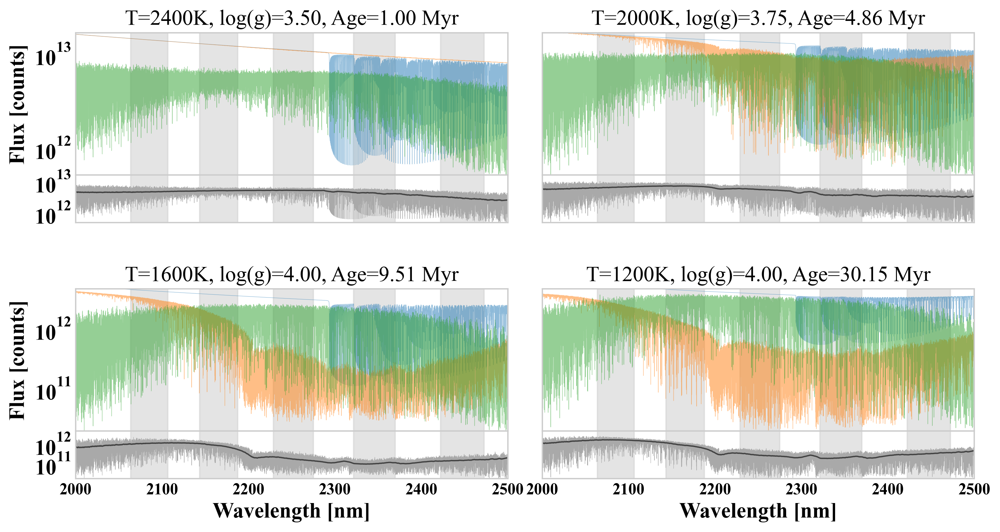

In [187]:

from matplotlib.gridspec import GridSpec
from scipy.signal import savgol_filter

# Load wavelength
wMod = np.load(path + 'wave_pRT.npy')*1e3  # nm
wave_mask = (wMod >= 2.0e3) & (wMod <= 2.5e3)

# Create main figure and grid (2x2 for your four cases)
fig = plt.figure(figsize=(12, 6), dpi=300)
main_gs = GridSpec(2, 2, figure=fig, wspace=0.08, hspace=0.35)

#matplotlib.rcParams.update({'font.size': 14})

j = 0
for i in [5, 7, 9, 11]:
    T_p = simulation_log['Teff_planet'][i]
    M_p = simulation_log['M_planet'][i]
    R_p = simulation_log['R_planet'][i]
    Age = simulation_log['Age'][i]
    G_p = simulation_log['G_planet'][i]

    G_p_log = int((10**G_p)/100)
    folder_name = f'{Scenario}{T_p}_{M_p}_{R_p}_{Age}'

    fMod_ch4 = np.load(path + folder_name + f'/f_pRT_ch4_only_t{T_p}_g{G_p_log}nc_m0.0.npy')
    fMod_co  = np.load(path + folder_name + f'/f_pRT_co_only_t{T_p}_g{G_p_log}nc_m0.0.npy')
    fMod_h2o = np.load(path + folder_name + f'/f_pRT_h2o_pokazatel_only_t{T_p}_g{G_p_log}nc_m0.0.npy')
    fMod     = np.load(path + folder_name + f'/f_pRT_t{T_p}_g{G_p_log}nc_m0.0.npy')

    # Create subgridspec inside each 2x2 cell → two vertical panels
    row, col = divmod(j, 2)
    sub_gs = main_gs[row, col].subgridspec(2, 1, height_ratios=[3, 1], hspace=0.0)

    # Upper panel: molecular components
    ax_upper = fig.add_subplot(sub_gs[0])
    ax_upper.plot(wMod, fMod_co, linewidth=0.3, label=r'$\mathrm{CO}$', alpha=0.5)
    ax_upper.plot(wMod, fMod_ch4, linewidth=0.3, label=r'$\mathrm{CH_4}$', alpha=0.5)
    ax_upper.plot(wMod, fMod_h2o, linewidth=0.3, label=r'$\mathrm{H_2O}$', alpha=0.5)
    
    ax_upper.set_yscale('symlog')
    ax_upper.set_xlim(2.0e3, 2.5e3)
    ax_upper.set_ylim(np.nanmin(fMod[wave_mask]) - 10, np.nanmax(fMod[wave_mask]) * 2)
    ax_upper.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)

    ax_upper.set_title(f'T={T_p}K, log(g)={G_p:.2f}, Age={Age:.2f} Myr')
    ax_upper.grid(False)
    

    for k in range(2, 7):
        wave_min = lambda_range['wave'][3][k][0] 
        wave_max = lambda_range['wave'][3][k][-1]
        ax_upper.axvspan(wave_min, wave_max, color='lightgray', alpha=0.6)

    # Lower panel: fMod only
    ax_lower = fig.add_subplot(sub_gs[1], sharex=ax_upper)
    ax_lower.plot(wMod, fMod, linewidth=0.25, color='darkgray', label='Full Model', alpha=1.0)
    ax_lower.plot(wMod, savgol_filter(fMod, 5000, 1), linewidth=1, label='Continuum proxy', alpha=0.6, color='black')
    for k in range(2, 7):
        wave_min = lambda_range['wave'][3][k][0]
        wave_max = lambda_range['wave'][3][k][-1]
        ax_lower.axvspan(wave_min, wave_max, color='lightgray', alpha=0.6)

    ax_lower.set_yscale('symlog')
    ax_lower.set_xlim(2.0e3, 2.5e3)
    ax_lower.grid(False)
    
    
    ax_lower.set_ylim(np.nanmin(fMod[wave_mask]) - 10, np.nanmax(fMod[wave_mask]) * 2)

    # Axis labels only on left/bottom subplots
    if col == 0:
        ax_upper.set_ylabel("Flux [counts]")
        ax_lower.set_ylabel("")  # Clear the ylabel for ax_lower
    else:
        ax_upper.set_yticklabels([])
        ax_lower.set_yticklabels([])

    if row == 1:
        ax_lower.set_xlabel("Wavelength [nm]")
        ax_lower.tick_params(axis='x', which='both', labelbottom=True, labelsize=12)
    else:
        ax_lower.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)



    j += 1

# Layout adjustments
plt.subplots_adjust(hspace=0.1, wspace=0.25)
plt.tight_layout()
plt.show()


0.7612808011232844
0.7920459147359398
0.8799622719231591
0.8746767540064456
0.8314204908164688
0.7464824863756448
0.6225146913497533


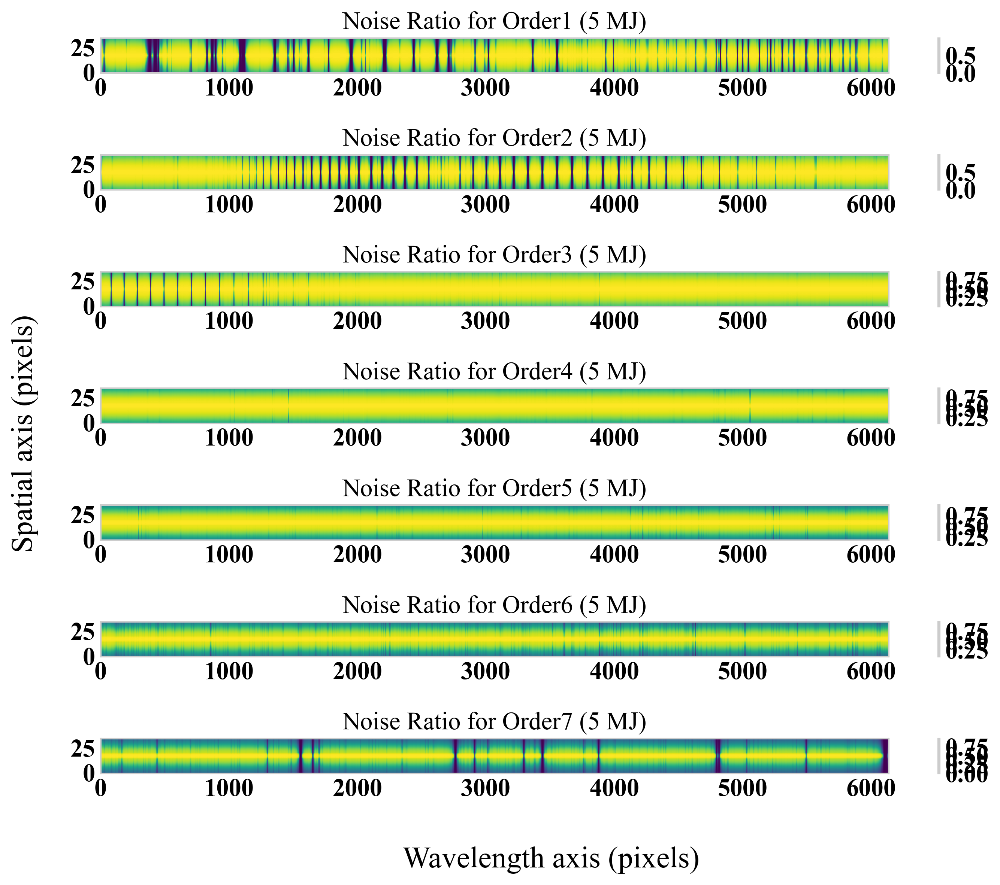

0.6678173575292117
0.6983290674772357
0.7876403146853839
0.7746963672404953
0.717021351496552
0.6185944545302171
0.4936088544714727


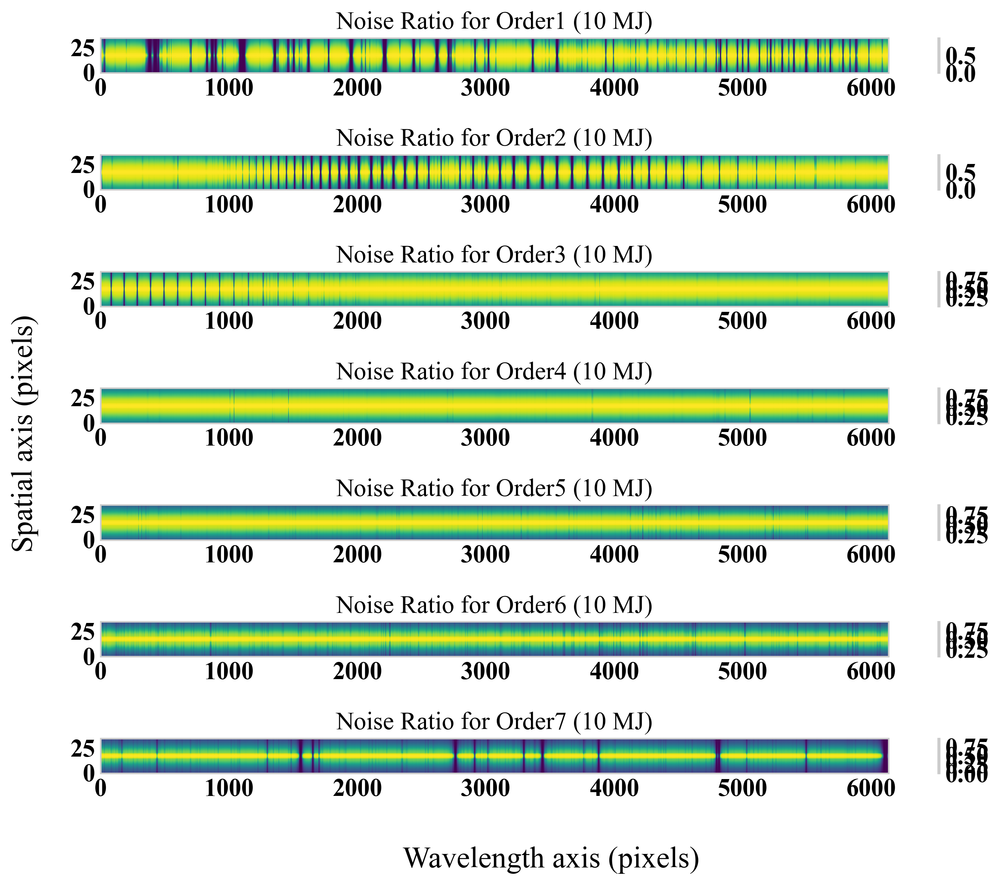

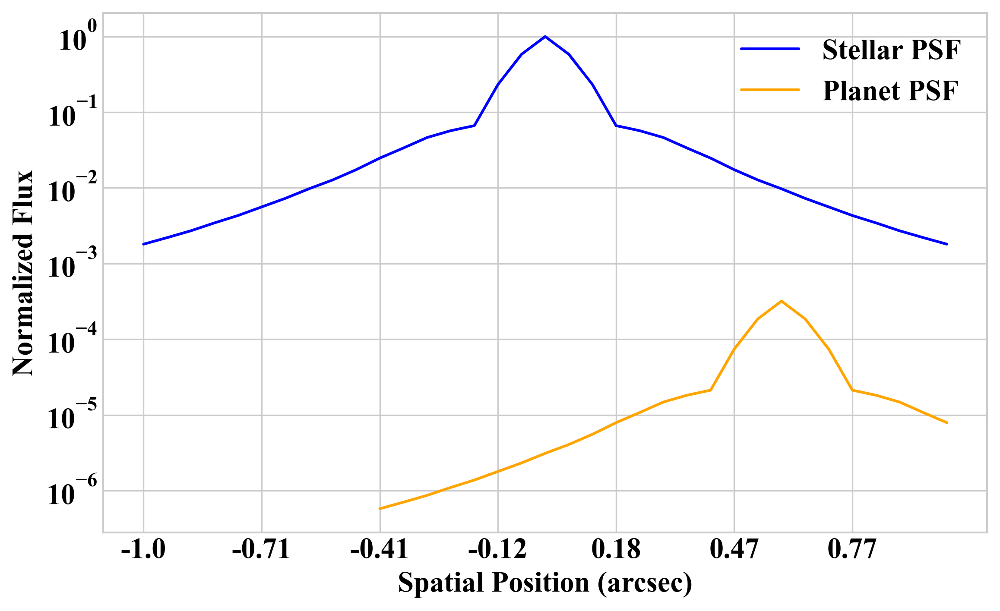

/var/folders/w_/fqznltwj2pz2y345p5_rzn3r0000gn/T/ipykernel_1990/3016569328.py:201: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0].set_xticklabels(np.round(np.arange(-17,19,5)*0.059,2))


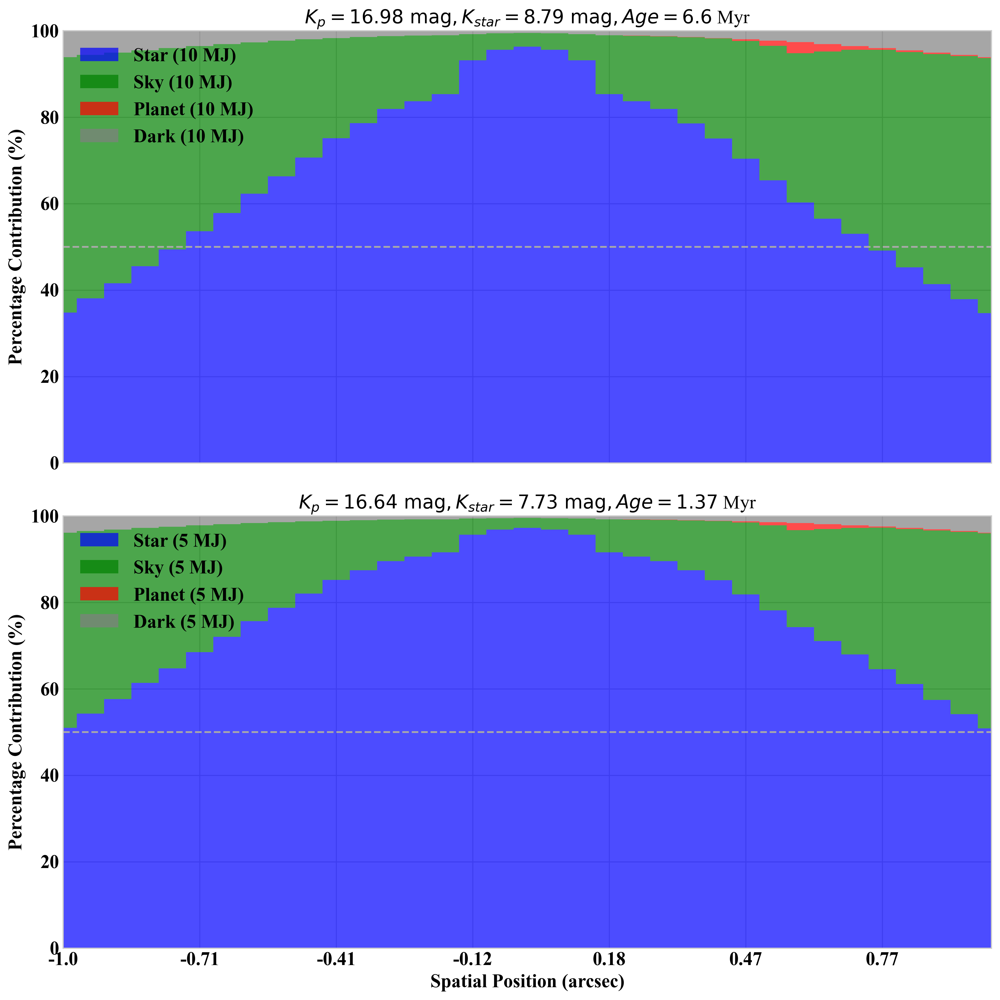

/var/folders/w_/fqznltwj2pz2y345p5_rzn3r0000gn/T/ipykernel_1990/3016569328.py:240: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


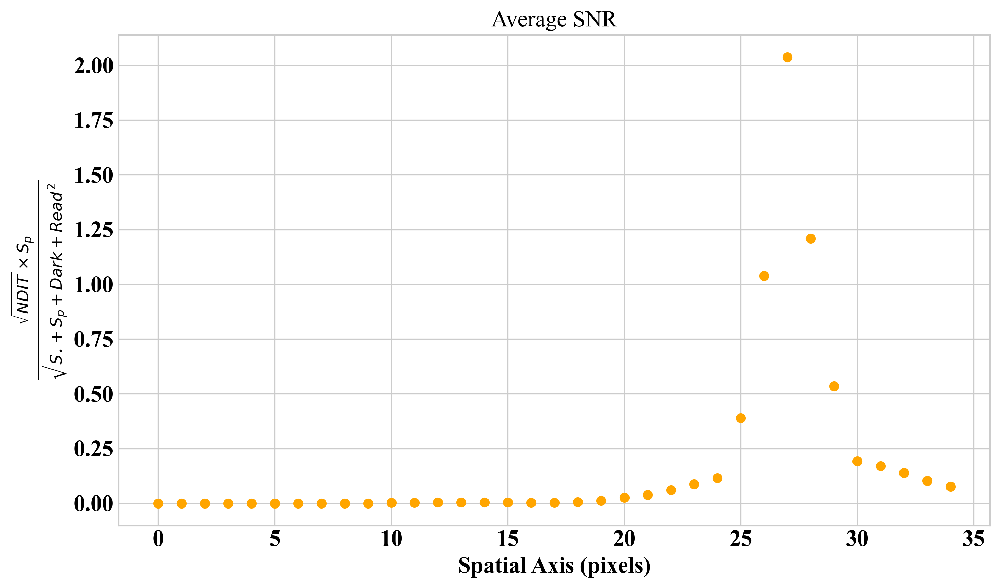

In [264]:
#Plotting the stellar photon noise budget over the total noise budget

stellar_contribution_10 = pd.read_csv(path + '/H1800_10_1.51_6.6/0308/star/K2166/stellar_simu_K2166.csv')
planet_contribution_10 = pd.read_csv(path + '/H1800_10_1.51_6.6/0308/planet/1800-4.0-0.0/K2166/planet_simu.csv')
sky_contribution_10 = pd.read_csv(path + '/H1800_10_1.51_6.6/0308/sky/K2166/sky_simu.csv')

stellar_contribution_5 = pd.read_csv(path + '/H1800_5_1.76_1.37/0308/star/K2166/stellar_simu_K2166.csv')
planet_contribution_5 = pd.read_csv(path + '/H1800_5_1.76_1.37/0308/planet/1800-3.5-0.0/K2166/planet_simu.csv')
sky_contribution_5 = pd.read_csv(path + '/H1800_5_1.76_1.37/0308/sky/K2166/sky_simu.csv')

stellar_psf_10 = np.zeros(shape = (7, 35, 2046*3))
stellar_psf_5 = np.zeros(shape = (7, 35, 2046*3))

planet_psf_10 = np.zeros(shape = (7, 35, 2046*3))
planet_psf_5 = np.zeros(shape = (7, 35, 2046*3))

sky_psf_10 = np.zeros(shape = (7, 35, 2046*3))
sky_psf_5 = np.zeros(shape = (7, 35, 2046*3))


for i in range(18):

    if i == 0:
        for n in range(7):

            stellar_psf_10[n][17][0:2046*3] = stellar_contribution_10['dat_diff_'+str(i)].values[(n*3)*2046:(n*3+3)*2046]
            planet_psf_10[n][17+10][0:2046*3] = planet_contribution_10['dat_diff_'+str(i)].values[(n*3)*2046:(n*3+3)*2046]
            sky_psf_10[n][17][0:2046*3] = sky_contribution_10['dat_diff_'+str(i)].values[(n*3)*2046:(n*3+3)*2046]

            stellar_psf_5[n][17][0:2046*3] = stellar_contribution_5['dat_diff_'+str(i)].values[(n*3)*2046:(n*3+3)*2046]
            planet_psf_5[n][17+10][0:2046*3] = planet_contribution_5['dat_diff_'+str(i)].values[(n*3)*2046:(n*3+3)*2046]
            sky_psf_5[n][17][0:2046*3] = sky_contribution_5['dat_diff_'+str(i)].values[(n*3)*2046:(n*3+3)*2046]


            

    else:
        for n in range(7):

            if 0 <= 17+i < stellar_psf_10.shape[1]:
                stellar_psf_10[n][17+i][0:2046*3] = stellar_contribution_10['dat_diff_'+str(i)].values[(n*3)*2046:(n*3+3)*2046]
                stellar_psf_5[n][17+i][0:2046*3] = stellar_contribution_5['dat_diff_'+str(i)].values[(n*3)*2046:(n*3+3)*2046]
                sky_psf_10[n][17+i][0:2046*3] = sky_contribution_10['dat_diff_'+str(i)].values[(n*3)*2046:(n*3+3)*2046]
                sky_psf_5[n][17+i][0:2046*3] = sky_contribution_5['dat_diff_'+str(i)].values[(n*3)*2046:(n*3+3)*2046]
            if 0 <= 17-i < stellar_psf_10.shape[1]:
                stellar_psf_10[n][17-i][0:2046*3] = stellar_contribution_10['dat_diff_'+str(i)].values[(n*3)*2046:(n*3+3)*2046]
                stellar_psf_5[n][17-i][0:2046*3] = stellar_contribution_5['dat_diff_'+str(i)].values[(n*3)*2046:(n*3+3)*2046]
                sky_psf_10[n][17-i][0:2046*3] = sky_contribution_10['dat_diff_'+str(i)].values[(n*3)*2046:(n*3+3)*2046]
                sky_psf_5[n][17-i][0:2046*3] = sky_contribution_5['dat_diff_'+str(i)].values[(n*3)*2046:(n*3+3)*2046]

            if 0 <= 17+i+10 < planet_psf_10.shape[1]:
                planet_psf_10[n][17+i+10][0:2046*3] = planet_contribution_10['dat_diff_'+str(i)].values[(n*3)*2046:(n*3+3)*2046]
                planet_psf_5[n][17+i+10][0:2046*3] = planet_contribution_5['dat_diff_'+str(i)].values[(n*3)*2046:(n*3+3)*2046]
            if 0 <= 17-i+10 < planet_psf_10.shape[1]:
                planet_psf_10[n][17-i+10][0:2046*3] = planet_contribution_10['dat_diff_'+str(i)].values[(n*3)*2046:(n*3+3)*2046]
                planet_psf_5[n][17-i+10][0:2046*3] = planet_contribution_5['dat_diff_'+str(i)].values[(n*3)*2046:(n*3+3)*2046]

            


    


nspec=1
nspat=105 #nspat for aperture 105
dark=0.003 #e-/pix/s, width of the distribution
read=6 #e-/pix, width of the distribution
ndark=600*dark #e-/pix/exposure


#Use the sqrt of the stellar counts per pixel to estimate the stellar photon noise
stellar_noise_10 = np.sqrt(stellar_psf_10)
stellar_noise_5 = np.sqrt(stellar_psf_5)


total_noise_10 = np.sqrt(stellar_psf_10 + planet_psf_10 + sky_psf_10 + read**2 + ndark)
total_noise_5 = np.sqrt(stellar_psf_5 + planet_psf_5 + sky_psf_5 + read**2 + ndark) 

total_signal_10 = stellar_psf_10 + planet_psf_10 + sky_psf_10 + ndark
total_signal_5 = stellar_psf_5 + planet_psf_5 + sky_psf_5 + ndark

#total_noise = 1
noise_ratio_10 =(stellar_noise_10 / total_noise_10)
noise_ratio_5 =(stellar_noise_5 / total_noise_5)

#Calculate overall SNR for planet
snr_10 = np.sqrt(80)*planet_psf_10 / total_noise_10 
snr_5 = np.sqrt(80)*planet_psf_5 / total_noise_5

#take average over the noise ratios
noise_ratio = np.array([noise_ratio_5, noise_ratio_10])

#plotting the ratio of stellar noise to total noise

noise_ratio = [noise_ratio_5, noise_ratio_10]
for j in range(2):  # Loop over the two noise ratios
    fig, axs = plt.subplots(7, 1, figsize=(10, 8))
    for i in range(7):
        im = axs[i].imshow(noise_ratio[j][i], aspect='auto', cmap='viridis')  # Update indexing for axs
        plt.colorbar(im, ax=axs[i])  # Add colorbar
        axs[i].set_title(f'Noise Ratio for Order{i+1} ({"5 MJ" if j==0 else "10 MJ"})')
        print (np.nanmean(noise_ratio[j][i]))
        #axs[i].set_title(r'$ \frac{\sqrt{S_{\star}}}{\text{Total Noise Budget}} $')
        

        #axs[i].yticks([])  # Hide y-axis ticks since it's just one row

        #inverse the y-axis
        axs[i].invert_yaxis()  # Update to use axs[i] instead of plt.gca()

        #remove the grid
        axs[i].grid(False)

        #plt.hlines(17+10, xmin=0, xmax=noise_ratio.shape[2], colors='red', linestyles='dashed', label='Planet Position')
    fig.supxlabel('Wavelength axis (pixels)')
    fig.supylabel('Spatial axis (pixels)')
    plt.tight_layout()
    plt.show()


#plot the wavelength-integrated PSF files for stellar and planetary contributions
stellar_psf_sum_10 = np.nansum(stellar_psf_10, axis=-1)
planet_psf_sum_10 = np.nansum(planet_psf_10, axis=-1)

stellar_psf_sum_5 = np.nansum(stellar_psf_5, axis=-1)
planet_psf_sum_5 = np.nansum(planet_psf_5, axis=-1)


planet_psf_sum_5[planet_psf_sum_5 == 0] = np.nan
planet_psf_sum_10[planet_psf_sum_10 == 0] = np.nan 

plt.figure(figsize=(8,5))
plt.plot(stellar_psf_sum_10[-3]/np.nanmax(stellar_psf_sum_10[-3]), color='blue', label='Stellar PSF')
plt.plot(planet_psf_sum_10[-3]/np.nanmax(stellar_psf_sum_10[-3]), label='Planet PSF', color='orange')

'''
plt.plot(stellar_psf_sum_5[1]/np.nanmax(stellar_psf_sum_5[1]), color='green', label='Stellar PSF 5 MJ')
plt.plot(planet_psf_sum_5[1]/np.nanmax(stellar_psf_sum_5[1]), label='Planet PSF 5 MJ', color='red')
'''

#plt.title('Integrated PSF Profiles')
plt.xticks(np.arange(0,35,5), labels=np.round(np.arange(-17, 18, 5)*0.059, 2))
plt.xlabel('Spatial Position (arcsec)')
plt.ylabel('Normalized Flux')

plt.yscale('log')
plt.legend()
plt.show()


# Normalize the contribution percentages so that they sum up to 100% at each spatial position



dark_percentage_10 = np.nanmean(ndark / total_signal_10, axis=(-1, 0))
#read_percentage_10 = np.nanmean(read / total_signal_10, axis=(-1, 0))
stellar_percentage_10 = np.nanmean(stellar_psf_10 / total_signal_10, axis=(-1, 0))
planet_percentage_10 = np.nanmean(planet_psf_10 / total_signal_10, axis=(-1, 0))
sky_percentage_10 = np.nanmean(sky_psf_10 / total_signal_10, axis=(-1, 0))

dark_percentage_5 = np.nanmean(ndark / total_signal_5, axis=(-1, 0))
#read_percentage_5 = np.nanmean(read / total_signal_5, axis=(-1, 0))
stellar_percentage_5 = np.nanmean(stellar_psf_5 / total_signal_5, axis=(-1, 0)) 
planet_percentage_5 = np.nanmean(planet_psf_5 / total_signal_5, axis=(-1, 0)) 
sky_percentage_5 = np.nanmean(sky_psf_5 / total_signal_5, axis=(-1, 0)) 

# Combine the percentages for 5 MJ and 10 MJ planets

percentages_10 = np.array([stellar_percentage_10, sky_percentage_10, planet_percentage_10, dark_percentage_10])
percentages_5 = np.array([stellar_percentage_5, sky_percentage_5, planet_percentage_5, dark_percentage_5])

# Normalize the percentages to ensure they sum to 100% at each spatial position
#percentages_10 /= np.sum(percentages_10, axis=0)
#percentages_5 /= np.sum(percentages_5, axis=0)

# Convert to percentage scale
#percentages_10 *= 100
#percentages_5 *= 100

# Define labels and colors

labels=['Star', 'Sky', 'Planet', 'Dark']
colors=['blue', 'green', 'red', 'gray']


# Plot histograms for the signal percentage contributions
fig, axs = plt.subplots(2, 1, figsize=(12, 12), sharex=True)
width = 1

x=np.arange(percentages_10.shape[1])  # Spatial positions

# Plot for 10 MJ planet
for i in range(len(labels)):
    shift = np.sum(percentages_10[0:i, :], axis=0) if i > 0 else 0
    axs[0].bar(x, (percentages_10[i] / np.sum(percentages_10, axis=0)) * 100, width, 
               bottom=(shift / np.sum(percentages_10, axis=0)) * 100, 
               label=f'{labels[i]} (10 MJ)', color=colors[i], alpha=0.7)

axs[0].set_title(f'$K_p ={Mag_planet_10[3].round(2)} \ \mathrm{{mag}}, K_{{star}} ={Mag_star_10[3].round(2)} \ \mathrm{{mag}}, Age={Age_10[3]}$ Myr')
axs[0].set_ylabel('Percentage Contribution (%)')
axs[0].set_xticklabels(np.round(np.arange(-17,19,5)*0.059,2))
axs[0].set_xlim(0, percentages_10.shape[1]-1)
axs[0].set_ylim(0, 100)
axs[0].hlines(50, xmin=0, xmax=percentages_10.shape[1]-1, colors='darkgray', linestyles='dashed')
axs[0].legend(loc='upper left')

# Plot for 5 MJ planet

for i in range(len(labels)):
    shift = np.sum(percentages_5[0:i, :], axis=0) if i > 0 else 0
    axs[1].bar(x, (percentages_5[i] / np.sum(percentages_5, axis=0)) * 100, width, 
               bottom=(shift / np.sum(percentages_5, axis=0)) * 100, 
               label=f'{labels[i]} (5 MJ)', color=colors[i], alpha=0.7)

axs[1].set_title(f'$K_p={Mag_planet_5[0].round(2)} \ \mathrm{{mag}}, K_{{star}}={Mag_star_5[0].round(2)} \ \mathrm{{mag}}, Age={Age_5[0]}$ Myr')
axs[1].set_xlabel('Spatial Position (arcsec)')
axs[1].set_ylabel('Percentage Contribution (%)')
axs[1].set_xlim(0, percentages_10.shape[1]-1)
axs[1].set_ylim(0, 100)
axs[1].hlines(50, xmin=0, xmax=percentages_10.shape[1]-1, colors='darkgray', linestyles='dashed')
axs[1].legend(loc='upper left')


# Adjust layout and display the plot
plt.tight_layout()
plt.show()

# SNR
avg_snr_10 = np.nanmean(snr_10, axis=-1)
avg_snr_5 = np.nanmean(snr_5, axis=-1)  
avg_snr_10 = np.nanmean(avg_snr_10[0:7,:], axis=0)
avg_snr_5 = np.nanmean(avg_snr_5[0:7,:], axis=0)
plt.figure(figsize=(10,6))
plt.scatter(np.arange(0,35,1), avg_snr_10, color='orange')
#plt.scatter(np.arange(0,35,1), avg_snr_5, label='5 MJ Planet', color='orange')  
plt.title('Average SNR')
plt.xlabel('Spatial Axis (pixels)')
plt.ylabel(r'$ \frac{\sqrt{NDIT} \times S_p}{\sqrt{S_{\star} + S_p + Dark + Read^2}} $')
plt.yscale('linear')
plt.legend()
plt.show()



In [189]:
dark_percentage_10 = np.nanmean(ndark / total_signal_10, axis=(-1,0))
read_percentage_10 = np.nanmean(read / total_signal_10, axis=(-1,0))
stellar_percentage_10 = np.nanmean(stellar_psf_10 / total_signal_10, axis=(-1,0))
planet_percentage_10 = np.nanmean(planet_psf_10 / total_signal_10, axis=(-1,0))
sky_percentage_10 = np.nanmean(sky_psf_10 / total_signal_10, axis=(-1,0))
print(dark_percentage_10+read_percentage_10+stellar_percentage_10+planet_percentage_10+sky_percentage_10)

[1.11474527 1.10350917 1.09273428 1.08236158 1.07308046 1.06424546
 1.05662452 1.04957205 1.04377116 1.03838442 1.03355927 1.0299362
 1.02688714 1.02494738 1.02371172 1.01889657 1.01645301 1.01508353
 1.01645297 1.0188963  1.02370913 1.0249422  1.026876   1.02991125
 1.03350832 1.03811118 1.04271713 1.04681103 1.05412281 1.06261252
 1.07221375 1.0813067  1.09156708 1.10235238 1.11362356]


/var/folders/w_/fqznltwj2pz2y345p5_rzn3r0000gn/T/ipykernel_1990/2209305726.py:160: RuntimeWarning: invalid value encountered in divide
  planet_flux_contrast_matrix[i-5][ch][pos] = np.nanmedian(planet_psf[ch][17] / stellar_psf[ch][pos])
/var/folders/w_/fqznltwj2pz2y345p5_rzn3r0000gn/T/ipykernel_1990/2209305726.py:160: RuntimeWarning: invalid value encountered in divide
  planet_flux_contrast_matrix[i-5][ch][pos] = np.nanmedian(planet_psf[ch][17] / stellar_psf[ch][pos])
/var/folders/w_/fqznltwj2pz2y345p5_rzn3r0000gn/T/ipykernel_1990/2209305726.py:160: RuntimeWarning: invalid value encountered in divide
  planet_flux_contrast_matrix[i-5][ch][pos] = np.nanmedian(planet_psf[ch][17] / stellar_psf[ch][pos])
/var/folders/w_/fqznltwj2pz2y345p5_rzn3r0000gn/T/ipykernel_1990/2209305726.py:160: RuntimeWarning: invalid value encountered in divide
  planet_flux_contrast_matrix[i-5][ch][pos] = np.nanmedian(planet_psf[ch][17] / stellar_psf[ch][pos])
/var/folders/w_/fqznltwj2pz2y345p5_rzn3r0000gn/T/ipy

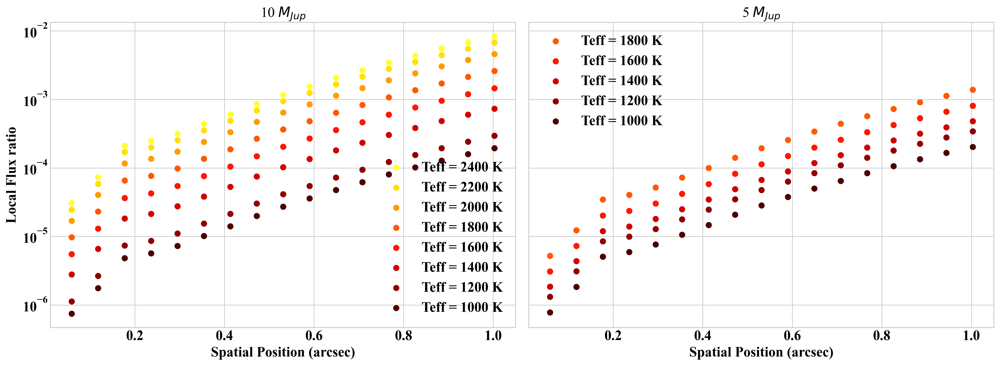

In [190]:

input_json_name='H1800_10_1.51_6.60.json'
key=lambda_range['key'][-3]


filename=path+'/spectra_input/upload_lowres_star_%s_10km_rot_lsf.dat'%key

day= '0308'
name_model='2200-4.0-0.0'

nspec=1
nspat=105 #nspat for aperture 105
dark=0.003 #e-/pix/s, width of the distribution
read=6 #e-/pix, width of the distribution
npix=nspec*nspat
dit=600
ndark=dit*dark*nspec*nspat #e-/pix/exposure





#define a function to calculate planet poisition SNR and plot the result


def SNR_planet_position(stellar_psf, planet_psf, planet_position, normalize=False, sum_up=False):
    """
    Calculate the SNR at the planet position given stellar and planetary PSF arrays.
    
    Parameters:
    stellar_psf : 2D array
        The stellar PSF counts.
    planet_psf : 2D array
        The planetary PSF counts.
    planet_position : int
        The pixel index of the planet position.
        
    Returns:
    snr : float
        The calculated SNR at the planet position.
    """
    if sum_up == True:
        stellar_psf = np.nansum(stellar_psf, axis=-1)
        planet_psf = np.nansum(planet_psf, axis=-1)

    if normalize:
        stellar_psf = stellar_psf / np.nanmax(stellar_psf)
        planet_psf = planet_psf / np.nanmax(planet_psf)

    stellar_counts = stellar_psf[planet_position]
    planet_counts = np.nanmax(planet_psf) # Assuming planet PSF is centered at index 17
    
    # Avoid division by zero
    total_noise = np.sqrt(stellar_counts + planet_counts)
    #total_noise[total_noise == 0] = np.nan
    
    snr = planet_counts / total_noise


    return snr

#calcualte the PSF gain for each position with respect to the neighbor postion
'''
def psf_gain(stellar_psf,normalize=False, center=17):
    """
    Calculate the PSF gain at each position given stellar PSF array.
    
    Parameters:
    stellar_psf : 2D array
        The stellar PSF counts.
        
    Returns:
    psf_gain : 1D array
        The calculated PSF gain at each position.
    """
    psf_gain = np.zeros_like(stellar_psf)
    if normalize:
        stellar_psf = stellar_psf / np.nanmax(stellar_psf)

    for i in range(len(stellar_psf)):
        if i == center:
            psf_gain = np.zeros_like(stellar_psf)
        else:
            psf_gain[i] = 1- ( stellar_psf[i] / stellar_psf[center] )

    return psf_gain
'''
#Example usage
planet_position = np.arange(18, 35, 1)  # Example planet position index




#Set up the simulation parameters

#set up global font size
plt.rcParams.update({'font.size': 14})

#Create a colormap list for the temperature
cmap = plt.get_cmap('hot_r')  # Use the reversed 'hot' colormap
colors = [cmap(i) for i in np.linspace(0.2, 0.9, len(simulation_log.index[5:]))]




Teff_10_10 = simulation_log['Teff_planet'][simulation_log.index[5:]].values

fig, axes = plt.subplots(1,2, figsize=(16, 6), sharey=True)

lambda_range=info.lambda_range

po = 10
snr_matrix=np.zeros((len(simulation_log.index[5:]), 7, 35))
planet_flux_contrast_matrix=np.zeros((len(simulation_log.index[5:]), 7, 35))
for i in simulation_log.index[5:]:

    T_p = simulation_log['Teff_planet'][i]  # in K
    M_p = simulation_log['M_planet'][i]  # in Mjup
    R_p = simulation_log['R_planet'][i]  # in Rjup
    Age = simulation_log['Age'][i]  # in Myr, round 2 decimal places
    G_p = simulation_log['G_planet'][i]  # in cgs
    Z_p = simulation_log['Z_planet'][i]  # in dex

    Scenario = simulation_log['formation_scenario'][i]  # 'H' for hot start, 'C' for cold start

    folder_name = f'{Scenario}{T_p}_{M_p}_{R_p}_{Age}'

    data_star = pd.read_csv(path + f'/{folder_name}/0308/star/K2166/stellar_simu_K2166.csv')
    data_planet = pd.read_csv(path + f'/{folder_name}/0308/planet/{T_p}-{G_p}-{Z_p}/K2166/planet_simu.csv')

    stellar_psf = np.zeros(shape=(7, 35, 2046 * 3))
    planet_psf = np.zeros(shape=(7, 35, 2046 * 3))

    for col in range(18):

        if col == 0:
            for n in range(7):

                stellar_psf[n][17][0:2046 * 3] = data_star['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]
                planet_psf[n][17+po][0:2046 * 3] = data_planet['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]

        else:
            for n in range(7):

                if 0 <= 17 + col < stellar_psf.shape[1]:
                    stellar_psf[n][17 + col][0:2046 * 3] = data_star['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]
                if 0 <= 17 - col < stellar_psf.shape[1]:
                    stellar_psf[n][17 - col][0:2046 * 3] = data_star['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]

                if 0 <= 17 + col + po < planet_psf.shape[1]:
                    planet_psf[n][17 + col + po][0:2046 * 3] = data_planet['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]
                if 0 <= 17 - col + po < planet_psf.shape[1]:
                    planet_psf[n][17 - col + po][0:2046 * 3] = data_planet['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]
    # Calculate average planet-to-star flux contrast matrix
    

    planet_flux_contrast = np.zeros((7, 35))

    for ch in range(7):
        for pos in range(35):
            planet_flux_contrast_matrix[i-5][ch][pos] = np.nanmedian(planet_psf[ch][17] / stellar_psf[ch][pos])

            #snr_matrix[i - 5][ch][pos] = SNR_planet_position(stellar_psf[ch], planet_psf[ch], pos, normalize=False, sum_up=True)     

# Calculate the average flux contrast across all orders

avg_flux_contrast = np.nanmean(planet_flux_contrast_matrix[:,0:5], axis=1)

# Plot the flux contrast matrix as an image with a colorbar marked with Teff, y axis as the average flux contrast, x axis as the spatial position

positions = np.arange(18, 35, 1)
flux_contrast_values = avg_flux_contrast[:, 18:35]  # Average across rows to match positions
for i in range(flux_contrast_values.shape[0]):
    axes[0].scatter((positions-17)*0.059, flux_contrast_values[i], c=colors[i], cmap='viridis', marker='o', label='Teff = %s K' % Teff_10_10[i])

cbar.set_label('Average Flux Contrast across Orders')
axes[0].set_xlabel('Spatial Position (arcsec)')
axes[0].set_ylabel('Local Flux ratio')
axes[0].set_title(r'10 $M_{Jup}$')
#plt.hlines(17 + po, xmin=0, xmax=avg_flux_contrast_matrix.shape[1], colors='red', linestyles='dashed', label='Planet Position')
axes[0].legend()
axes[0].set_yscale('log')



planet_position = np.arange(18, 35, 1)  # Example planet position index




#Set up the simulation parameters

#set up global font size
plt.rcParams.update({'font.size': 14})

#Create a colormap list for the temperature
cmap = plt.get_cmap('hot_r')  # Use the reversed 'hot' colormap
colors = [cmap(i) for i in np.linspace(0.2, 0.9, len(simulation_log.index[5:]))]
colors = colors[3:]




Teff_10_5 = simulation_log['Teff_planet'][simulation_log.index[0:5]].values



lambda_range=info.lambda_range

po = 10
snr_matrix=np.zeros((len(simulation_log.index[0:5]), 7, 35))
planet_flux_contrast_matrix=np.zeros((len(simulation_log.index[0:5]), 7, 35))
for i in simulation_log.index[0:5]:

    T_p = simulation_log['Teff_planet'][i]  # in K
    M_p = simulation_log['M_planet'][i]  # in Mjup
    R_p = simulation_log['R_planet'][i]  # in Rjup
    Age = simulation_log['Age'][i]  # in Myr, round 2 decimal places
    G_p = simulation_log['G_planet'][i]  # in cgs
    Z_p = simulation_log['Z_planet'][i]  # in dex

    Scenario = simulation_log['formation_scenario'][i]  # 'H' for hot start, 'C' for cold start

    folder_name = f'{Scenario}{T_p}_{M_p}_{R_p}_{Age}'

    data_star = pd.read_csv(path + f'/{folder_name}/0308/star/K2166/stellar_simu_K2166.csv')
    data_planet = pd.read_csv(path + f'/{folder_name}/0308/planet/{T_p}-{G_p}-{Z_p}/K2166/planet_simu.csv')

    stellar_psf = np.zeros(shape=(7, 35, 2046 * 3))
    planet_psf = np.zeros(shape=(7, 35, 2046 * 3))

    for col in range(18):

        if col == 0:
            for n in range(7):

                stellar_psf[n][17][0:2046 * 3] = data_star['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]
                planet_psf[n][17+po][0:2046 * 3] = data_planet['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]

        else:
            for n in range(7):

                if 0 <= 17 + col < stellar_psf.shape[1]:
                    stellar_psf[n][17 + col][0:2046 * 3] = data_star['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]
                if 0 <= 17 - col < stellar_psf.shape[1]:
                    stellar_psf[n][17 - col][0:2046 * 3] = data_star['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]

                if 0 <= 17 + col + po < planet_psf.shape[1]:
                    planet_psf[n][17 + col + po][0:2046 * 3] = data_planet['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]
                if 0 <= 17 - col + po < planet_psf.shape[1]:
                    planet_psf[n][17 - col + po][0:2046 * 3] = data_planet['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]
    # Calculate average planet-to-star flux contrast matrix
    

    planet_flux_contrast = np.zeros((7, 35))

    for ch in range(7):
        for pos in range(35):
            planet_flux_contrast_matrix[i-5][ch][pos] = np.nanmedian(planet_psf[ch][17] / stellar_psf[ch][pos])

            #snr_matrix[i - 5][ch][pos] = SNR_planet_position(stellar_psf[ch], planet_psf[ch], pos, normalize=False, sum_up=True)     

# Calculate the average flux contrast across all orders

avg_flux_contrast = np.nanmean(planet_flux_contrast_matrix[:,0:5], axis=1)

# Plot the flux contrast matrix as an image with a colorbar marked with Teff, y axis as the average flux contrast, x axis as the spatial position

positions = np.arange(18, 35, 1)
flux_contrast_values = avg_flux_contrast[:, 18:35]  # Average across rows to match positions
for i in range(flux_contrast_values.shape[0]):
    axes[1].scatter((positions-17)*0.059, flux_contrast_values[i], c=colors[i], cmap='viridis', marker='o', label='Teff = %s K' % Teff_10_5[i])
#cbar = plt.colorbar()

axes[1].set_xlabel('Spatial Position (arcsec)')
#axes[1].set_ylabel('Average Flux Contrast')
axes[1].set_title(r'5 $M_{Jup}$')
#plt.hlines(17 + po, xmin=0, xmax=avg_flux_contrast_matrix.shape[1], colors='red', linestyles='dashed', label='Planet Position')
axes[1].legend()
axes[1].set_yscale('log')

plt.tight_layout()
plt.show()

/Users/richard/.local/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


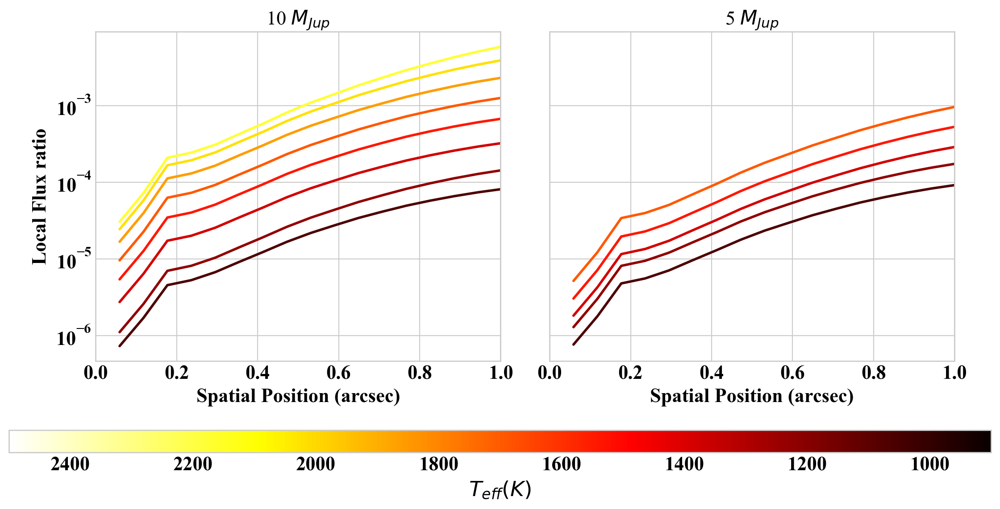

In [254]:
# same plot but for the local flux ratio including the sky background and dark current
plt.rcParams.update({'font.size': 19})

input_json_name='H1800_10_1.51_6.60.json'
key=lambda_range['key'][-3]


filename=path+'/spectra_input/upload_lowres_star_%s_10km_rot_lsf.dat'%key

day= '0308'
name_model='2200-4.0-0.0'

nspec=1
nspat=105 #nspat for aperture 105
dark=0.003 #e-/pix/s, width of the distribution
read=6 #e-/pix, width of the distribution
npix=nspec*nspat
dit=600
ndark=dit*dark #e-/pix/exposure


plt.rcParams.update({'font.size': 18})



#define a function to calculate planet poisition SNR and plot the result


def SNR_planet_position(stellar_psf, planet_psf, planet_position, normalize=False, sum_up=False):
    """
    Calculate the SNR at the planet position given stellar and planetary PSF arrays.
    
    Parameters:
    stellar_psf : 2D array
        The stellar PSF counts.
    planet_psf : 2D array
        The planetary PSF counts.
    planet_position : int
        The pixel index of the planet position.
        
    Returns:
    snr : float
        The calculated SNR at the planet position.
    """
    if sum_up == True:
        stellar_psf = np.nansum(stellar_psf, axis=-1)
        planet_psf = np.nansum(planet_psf, axis=-1)

    if normalize:
        stellar_psf = stellar_psf / np.nanmax(stellar_psf)
        planet_psf = planet_psf / np.nanmax(planet_psf)

    stellar_counts = stellar_psf[planet_position]
    planet_counts = np.nanmax(planet_psf) # Assuming planet PSF is centered at index 17
    
    # Avoid division by zero
    total_noise = np.sqrt(stellar_counts + planet_counts)
    #total_noise[total_noise == 0] = np.nan
    
    snr = planet_counts / total_noise


    return snr

#calcualte the PSF gain for each position with respect to the neighbor postion
'''
def psf_gain(stellar_psf,normalize=False, center=17):
    """
    Calculate the PSF gain at each position given stellar PSF array.
    
    Parameters:
    stellar_psf : 2D array
        The stellar PSF counts.
        
    Returns:
    psf_gain : 1D array
        The calculated PSF gain at each position.
    """
    psf_gain = np.zeros_like(stellar_psf)
    if normalize:
        stellar_psf = stellar_psf / np.nanmax(stellar_psf)

    for i in range(len(stellar_psf)):
        if i == center:
            psf_gain = np.zeros_like(stellar_psf)
        else:
            psf_gain[i] = 1- ( stellar_psf[i] / stellar_psf[center] )

    return psf_gain
'''
#Example usage
planet_position = np.arange(18, 35, 1)  # Example planet position index




#Set up the simulation parameters


#Create a colormap list for the temperature
cmap = plt.get_cmap('hot_r')  # Use the reversed 'hot' colormap
colors = [cmap(i) for i in np.linspace(0.2, 0.9, len(simulation_log.index[5:]))]




Teff_10_10 = simulation_log['Teff_planet'][simulation_log.index[5:]].values

fig, axes = plt.subplots(1,2, figsize=(11, 5), sharey=True, dpi=200)

lambda_range=info.lambda_range

po = 10
snr_matrix=np.zeros((len(simulation_log.index[5:]), 7, 35))
planet_flux_contrast_matrix=np.zeros((len(simulation_log.index[5:]), 7, 35))
for i in simulation_log.index[5:]:

    T_p = simulation_log['Teff_planet'][i]  # in K
    M_p = simulation_log['M_planet'][i]  # in Mjup
    R_p = simulation_log['R_planet'][i]  # in Rjup
    Age = simulation_log['Age'][i]  # in Myr, round 2 decimal places
    G_p = simulation_log['G_planet'][i]  # in cgs
    Z_p = simulation_log['Z_planet'][i]  # in dex

    Scenario = simulation_log['formation_scenario'][i]  # 'H' for hot start, 'C' for cold start

    folder_name = f'{Scenario}{T_p}_{M_p}_{R_p}_{Age}'

    data_star = pd.read_csv(path + f'/{folder_name}/0308/star/K2166/stellar_simu_K2166.csv')
    data_planet = pd.read_csv(path + f'/{folder_name}/0308/planet/{T_p}-{G_p}-{Z_p}/K2166/planet_simu.csv')
    data_sky = pd.read_csv(path + f'/{folder_name}/0308/sky/K2166/sky_simu.csv')

    stellar_psf = np.zeros(shape=(7, 35, 2046 * 3))
    planet_psf = np.zeros(shape=(7, 35, 2046 * 3))
    sky_psf = np.zeros(shape=(7, 35, 2046 * 3))

    for col in range(18):

        if col == 0:
            for n in range(7):

                stellar_psf[n][17][0:2046 * 3] = data_star['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]
                planet_psf[n][17+po][0:2046 * 3] = data_planet['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]

        else:
            for n in range(7):

                if 0 <= 17 + col < stellar_psf.shape[1]:
                    stellar_psf[n][17 + col][0:2046 * 3] = data_star['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]
                if 0 <= 17 - col < stellar_psf.shape[1]:
                    stellar_psf[n][17 - col][0:2046 * 3] = data_star['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]

                if 0 <= 17 + col + po < planet_psf.shape[1]:
                    planet_psf[n][17 + col + po][0:2046 * 3] = data_planet['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]
                if 0 <= 17 - col + po < planet_psf.shape[1]:
                    planet_psf[n][17 - col + po][0:2046 * 3] = data_planet['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]

                if 0 <= 17 + col < sky_psf.shape[1]:
                    sky_psf[n][17 + col][0:2046 * 3] = data_sky['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]
                if 0 <= 17 - col < sky_psf.shape[1]:
                    sky_psf[n][17 - col][0:2046 * 3] = data_sky['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]    
    # Calculate average planet-to-star flux contrast matrix
    

    planet_flux_contrast = np.zeros((7, 35))

    for ch in range(7):
        for pos in range(35):
            planet_flux_contrast_matrix[i-5][ch][pos] = np.nanmedian(planet_psf[ch][17] / ( stellar_psf[ch][pos] + sky_psf[ch][pos] + ndark ) )

            #snr_matrix[i - 5][ch][pos] = SNR_planet_position(stellar_psf[ch], planet_psf[ch], pos, normalize=False, sum_up=True)     

# Calculate the average flux contrast across all orders

avg_flux_contrast = np.nanmean(planet_flux_contrast_matrix[:,0:5], axis=1)

# Plot the flux contrast matrix as an image with a colorbar marked with Teff, y axis as the average flux contrast, x axis as the spatial position

positions = np.arange(18, 35, 1)
flux_contrast_values = avg_flux_contrast[:, 18:35]  # Average across rows to match positions
for i in range(flux_contrast_values.shape[0]):
    '''
    axes[0].scatter((positions-17)*0.059, flux_contrast_values[i], c=colors[i], 
                    cmap='viridis', marker='o', label='Teff = %s K' % Teff_10_10[i]
                    )
    '''
    #plot the curve
    axes[0].plot((positions-17)*0.059, flux_contrast_values[i], color=colors[i], alpha=1, linewidth=2)



cbar.set_label('Average Flux Contrast across Orders')
axes[0].set_xlabel('Spatial Position (arcsec)')
axes[0].set_ylabel('Local Flux ratio')
axes[0].set_title(r'10 $M_{Jup}$')
#plt.hlines(17 + po, xmin=0, xmax=avg_flux_contrast_matrix.shape[1], colors='red', linestyles='dashed', label='Planet Position')
#axes[0].legend()
axes[0].set_yscale('log')
axes[0].set_xlim(0,1)


planet_position = np.arange(18, 35, 1)  # Example planet position index




#Set up the simulation parameters


#Create a colormap list for the temperature
cmap = plt.get_cmap('hot_r')  # Use the reversed 'hot' colormap
colors = [cmap(i) for i in np.linspace(0.2, 0.9, len(simulation_log.index[5:]))]
colors = colors[3:]




Teff_10_5 = simulation_log['Teff_planet'][simulation_log.index[0:5]].values



lambda_range=info.lambda_range

po = 10
snr_matrix=np.zeros((len(simulation_log.index[0:5]), 7, 35))
planet_flux_contrast_matrix=np.zeros((len(simulation_log.index[0:5]), 7, 35))
for i in simulation_log.index[0:5]:

    T_p = simulation_log['Teff_planet'][i]  # in K
    M_p = simulation_log['M_planet'][i]  # in Mjup
    R_p = simulation_log['R_planet'][i]  # in Rjup
    Age = simulation_log['Age'][i]  # in Myr, round 2 decimal places
    G_p = simulation_log['G_planet'][i]  # in cgs
    Z_p = simulation_log['Z_planet'][i]  # in dex

    Scenario = simulation_log['formation_scenario'][i]  # 'H' for hot start, 'C' for cold start

    folder_name = f'{Scenario}{T_p}_{M_p}_{R_p}_{Age}'

    data_star = pd.read_csv(path + f'/{folder_name}/0308/star/K2166/stellar_simu_K2166.csv')
    data_planet = pd.read_csv(path + f'/{folder_name}/0308/planet/{T_p}-{G_p}-{Z_p}/K2166/planet_simu.csv')
    data_sky = pd.read_csv(path + f'/{folder_name}/0308/sky/K2166/sky_simu.csv')

    stellar_psf = np.zeros(shape=(7, 35, 2046 * 3))
    planet_psf = np.zeros(shape=(7, 35, 2046 * 3))
    sky_psf = np.zeros(shape=(7, 35, 2046 * 3))

    for col in range(18):

        if col == 0:
            for n in range(7):

                stellar_psf[n][17][0:2046 * 3] = data_star['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]
                planet_psf[n][17+po][0:2046 * 3] = data_planet['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]
                sky_psf[n][17][0:2046 * 3] = data_sky['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]

        else:
            for n in range(7):

                if 0 <= 17 + col < stellar_psf.shape[1]:
                    stellar_psf[n][17 + col][0:2046 * 3] = data_star['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]
                if 0 <= 17 - col < stellar_psf.shape[1]:
                    stellar_psf[n][17 - col][0:2046 * 3] = data_star['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]

                if 0 <= 17 + col + po < planet_psf.shape[1]:
                    planet_psf[n][17 + col + po][0:2046 * 3] = data_planet['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]
                if 0 <= 17 - col + po < planet_psf.shape[1]:
                    planet_psf[n][17 - col + po][0:2046 * 3] = data_planet['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]

                if 0 <= 17 + col < sky_psf.shape[1]:
                    sky_psf[n][17 + col][0:2046 * 3] = data_sky['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]
                if 0 <= 17 - col < sky_psf.shape[1]:
                    sky_psf[n][17 - col][0:2046 * 3] = data_sky['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]
    # Calculate average planet-to-star flux contrast matrix
    

    planet_flux_contrast = np.zeros((7, 35))

    for ch in range(7):
        for pos in range(35):
            planet_flux_contrast_matrix[i-5][ch][pos] = np.nanmedian(planet_psf[ch][17] / (stellar_psf[ch][pos] + sky_psf[ch][pos] + ndark) )

            #snr_matrix[i - 5][ch][pos] = SNR_planet_position(stellar_psf[ch], planet_psf[ch], pos, normalize=False, sum_up=True)     

# Calculate the average flux contrast across all orders

avg_flux_contrast = np.nanmean(planet_flux_contrast_matrix[:,0:5], axis=1)

# Plot the flux contrast matrix as an image with a colorbar marked with Teff, y axis as the average flux contrast, x axis as the spatial position

positions = np.arange(18, 35, 1)
flux_contrast_values = avg_flux_contrast[:, 18:35]  # Average across rows to match positions
for i in range(flux_contrast_values.shape[0]):
    '''
    axes[1].scatter((positions-17)*0.059, flux_contrast_values[i], c=colors[i], cmap='viridis', marker='o', label='Teff = %s K' % Teff_10_5[i])
    '''
    axes[1].plot((positions-17)*0.059, flux_contrast_values[i], color=colors[i], alpha=1, linewidth=2)
    #cbar = plt.colorbar()

axes[1].set_xlabel('Spatial Position (arcsec)')
#axes[1].set_ylabel('Average Flux Contrast')
axes[1].set_title(r'5 $M_{Jup}$')
#plt.hlines(17 + po, xmin=0, xmax=avg_flux_contrast_matrix.shape[1], colors='red', linestyles='dashed', label='Planet Position')
#axes[1].legend()
axes[1].set_yscale('log')
axes[1].set_xlim(0,1)

#plot a horizontal color bar below the two plots indicating the colors and temperatures of the curves, using temperature and age as the labelticks



# Add the color bar according to the colors used in the scatter plot
cbar_ax = fig.add_axes([0, -0.05, 1.0, 0.05])  # Adjusted [left, bottom, width, height] to match the plot length
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=min(Teff_10_10)-100, vmax=max(Teff_10_10)+100))
sm.set_array([])
cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal', pad=1.2, aspect=30)  # Increased pad value to avoid overlap
cbar.set_label(r'$T_{eff} (K)$', fontsize=17)
cbar.set_ticks(Teff_10_10)
cbar.set_ticklabels([str(teff) for teff in Teff_10_10[::-1]])

#plt.tight_layout()
plt.show()



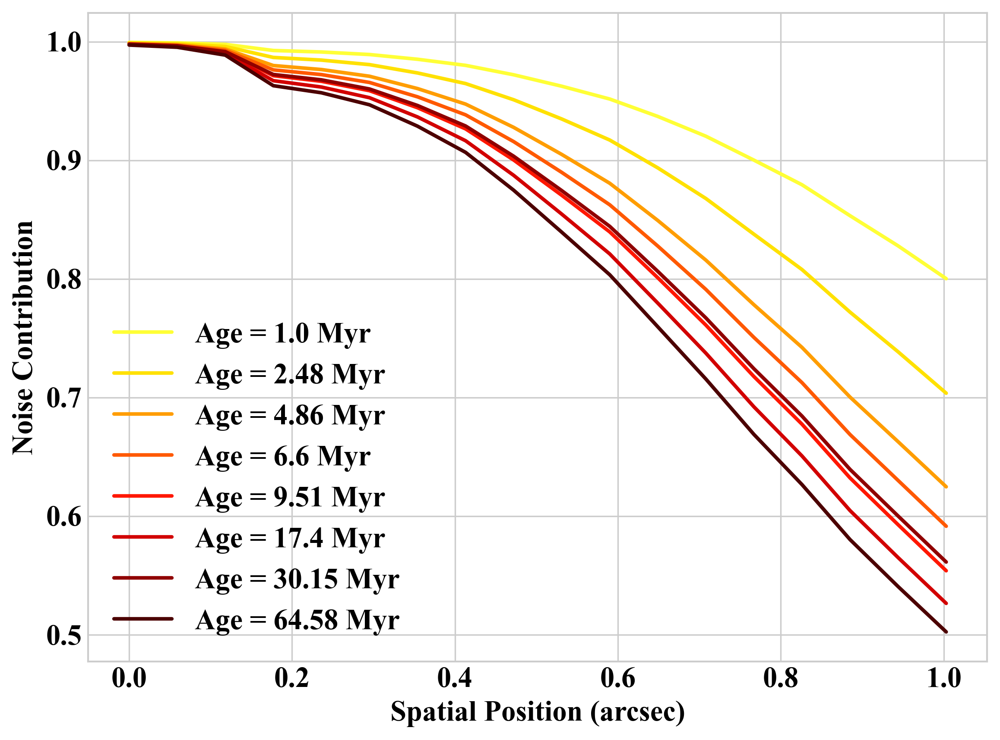

In [255]:
# Plot the noise contribution using sqrt of stellar psf/sqrt of (stellar psf + sky psf + dark + read^2) as a function of spatial position for each temperature
plt.rcParams.update({'font.size': 16})
fig, ax = plt.subplots(figsize=(8, 6))

cmap = plt.get_cmap('hot_r')  # Use the reversed 'hot' colormap
colors = [cmap(i) for i in np.linspace(0.2, 0.9, len(simulation_log.index[5:]))]
colors = colors

ndark=dit*dark #e-/pix/exposure

for i in simulation_log.index[5:]:

    T_p = simulation_log['Teff_planet'][i]  # in K
    M_p = simulation_log['M_planet'][i]  # in Mjup
    R_p = simulation_log['R_planet'][i]  # in Rjup
    Age = simulation_log['Age'][i]  # in Myr, round 2 decimal places
    G_p = simulation_log['G_planet'][i]  # in cgs
    Z_p = simulation_log['Z_planet'][i]  # in dex

    Scenario = simulation_log['formation_scenario'][i]  # 'H' for hot start, 'C' for cold start

    folder_name = f'{Scenario}{T_p}_{M_p}_{R_p}_{Age}'

    data_star = pd.read_csv(path + f'/{folder_name}/0308/star/K2166/stellar_simu_K2166.csv')
    data_planet = pd.read_csv(path + f'/{folder_name}/0308/planet/{T_p}-{G_p}-{Z_p}/K2166/planet_simu.csv')
    data_sky = pd.read_csv(path + f'/{folder_name}/0308/sky/K2166/sky_simu.csv')

    stellar_psf = np.zeros(shape=(7, 35, 2046 * 3))
    planet_psf = np.zeros(shape=(7, 35, 2046 * 3))
    sky_psf = np.zeros(shape=(7, 35, 2046 * 3))

    for col in range(18):

        if col == 0:
            for n in range(7):

                stellar_psf[n][17][0:2046 * 3] = data_star['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]
                planet_psf[n][17+po][0:2046 * 3] = data_planet['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]
                sky_psf[n][17][0:2046 * 3] = data_sky['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]

        else:
            for n in range(7):

                if 0 <= 17 + col < stellar_psf.shape[1]:
                    stellar_psf[n][17 + col][0:2046 * 3] = data_star['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]
                if 0 <= 17 - col < stellar_psf.shape[1]:
                    stellar_psf[n][17 - col][0:2046 * 3] = data_star['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]

                if 0 <= 17 + col + po < planet_psf.shape[1]:
                    planet_psf[n][17 + col + po][0:2046 * 3] = data_planet['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]
                if 0 <= 17 - col + po < planet_psf.shape[1]:
                    planet_psf[n][17 - col + po][0:2046 * 3] = data_planet['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]

                if 0 <= 17 + col < sky_psf.shape[1]:
                    sky_psf[n][17 + col][0:2046 * 3] = data_sky['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]
                if 0 <= 17 - col < sky_psf.shape[1]:
                    sky_psf[n][17 - col][0:2046 * 3] = data_sky['dat_diff_' + str(col)].values[(n * 3) * 2046:(n * 3 + 3) * 2046]

    # taking the median across the 7 channels and 2046*3 pixels
    stellar_psf_median = np.nanmedian(stellar_psf, axis=[0,2])
    sky_psf_median = np.nanmedian(sky_psf, axis=[0,2])
    # Calculate noise contribution curve over the spatial positions
    noise_contribution_star = np.zeros(35)
    noise_contribution_sky = np.zeros(35)
    for pos in range(17, 35):
        stellar_counts = stellar_psf_median[pos]
        sky_counts = sky_psf_median[pos]
        total_noise = np.sqrt(stellar_counts + sky_counts + ndark)
        # Avoid division by zero
        #total_noise[total_noise == 0] = np.nan
        noise_contribution_star[pos] = np.sqrt(stellar_counts) / total_noise 

        #noise_contribution_sky[pos] = np.sqrt(sky_counts) / total_noise

    ax.plot(np.arange(18)*0.059, noise_contribution_star[17:], color=colors[i-5], alpha=1, linewidth=2, label='Age = %s Myr' % simulation_log['Age'][i])
    #ax.plot(np.arange(18)*0.059, noise_contribution_sky[17:], color=colors[i-5], alpha=0.5, linewidth=2, label='Sky Teff = %s K' % simulation_log['Teff_planet'][i])

ax.set_xlabel('Spatial Position (arcsec)')
ax.set_ylabel('Noise Contribution')
#ax.set_title('Noise Contribution as a Function of Spatial Position')
ax.legend()
plt.show()
